# Predicting Snow Conditions in Western U.S. Ski Counties

## 1. Setup and Data Preparation

This notebook develops and evaluates machine learning models
to predict annual snow-cover duration in ski-dependent counties
of the western United States.

The primary outcome is the number of snow-cover days above
2,000 meters.

Models are evaluated using temporal and geographic validation
to assess their ability to predict snow conditions across
counties and years.

In [3]:
# Core packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [7]:
import pandas as pd

panel = pd.read_csv(
    "/Users/evabenson/Files/thesis/snow_ml/code/snow_county_panel.csv",
    dtype={"fips": str}
)

print(panel.shape)
display(panel.head())

(484, 8)


,fips,year,snow_days,gdp_thou,log_gdp,state,oni,pdo
0,08107,2001,55.526018,101944.0,11.532179,Colorado,-0.1,0.005
1,08113,2001,54.250380,70335.0,11.161025,Colorado,-0.1,0.005
2,08051,2001,64.498236,51865.0,10.856399,Colorado,-0.1,0.005
3,08049,2001,54.218701,89631.0,11.403457,Colorado,-0.1,0.005
4,08117,2001,64.280038,299675.0,12.610454,Colorado,-0.1,0.005


In [8]:
from pathlib import Path

project = Path("/Users/evabenson/Files/thesis/snow_ml")

for file in sorted(project.rglob("*")):
    if file.is_file() and file.suffix.lower() in [".csv", ".parquet"]:
        print(file.relative_to(project))

climate_panel.csv
code/ski_snow_states/snodas_depth_panel.csv
code/ski_snow_states/snodas_local_depth_panel.csv
code/snow_county_panel.csv
gdp_data/arts_gdp_colorado.csv
gdp_data/arts_gdp_idaho.csv
gdp_data/arts_gdp_montana.csv
gdp_data/arts_gdp_new_mexico.csv
gdp_data/arts_gdp_utah.csv
gdp_data/arts_gdp_wyoming.csv
gdp_data/bea_art.csv
gdp_data/bea_total_gdp.csv
gdp_data/orsa.csv
gdp_data/outdoor_rec_compensation.csv
gdp_data/outdoor_rec_emp.csv
gdp_data/skier visit data - Sheet1.csv
gdp_data/skiing.csv
gdp_data/snow_activities.csv
gdp_data/total_gdp_colorado.csv
gdp_data/total_gdp_idaho.csv
gdp_data/total_gdp_montana.csv
gdp_data/total_gdp_new_mexico.csv
gdp_data/total_gdp_utah.csv
gdp_data/total_gdp_wyoming.csv
gee/enso_oni.csv
ml_model/county_climate_maca_projections.csv
ml_model/county_climate_panel.csv
ml_model/county_climate_panel_v2.csv
ml_model/county_snow_panel.csv
ml_model/county_terrain.csv
ml_model/gdp/CAGDP2_CO_2001_2024.csv
ml_model/gdp/CAGDP2_ID_2001_2024.csv
ml_model/g

## 2. Data Preparation

Load county-level snow observations, historical climate
variables, and geographic characteristics.

In [9]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/Users/evabenson/Files/thesis/snow_ml/ml_model")

snow = pd.read_csv(
    DATA_DIR / "county_snow_panel.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    DATA_DIR / "county_climate_panel_v2.csv",
    dtype={"fips": str}
)

terrain = pd.read_csv(
    DATA_DIR / "county_terrain.csv",
    dtype={"fips": str}
)

print("Snow:", snow.shape)
print("Climate:", climate.shape)
print("Terrain:", terrain.shape)

Snow: (506, 6)
Climate: (506, 8)
Terrain: (22, 10)


In [10]:
for name, df in [
    ("Snow", snow),
    ("Climate", climate),
    ("Terrain", terrain)
]:
    print(f"\n{name.upper()}")
    print("Columns:", df.columns.tolist())
    display(df.head())
    print("\nMissing values:")
    print(df.isna().sum())


SNOW
Columns: ['fips', 'state', 'county', 'year', 'snow_days', 'snow_days_2000m']


,fips,state,county,year,snow_days,snow_days_2000m
0,08107,Colorado,Routt,2001.0,55.301951,55.526018
1,08113,Colorado,San Miguel,2001.0,45.118814,54.250380
2,08051,Colorado,Gunnison,2001.0,64.427127,64.498236
3,08049,Colorado,Grand,2001.0,54.218701,54.218701
4,08117,Colorado,Summit,2001.0,64.280038,64.280038



Missing values:
fips                0
state               0
county              0
year                0
snow_days           0
snow_days_2000m    23
dtype: int64

CLIMATE
Columns: ['fips', 'state', 'county', 'year', 'tmin_djf', 'tmin_apr', 'precip_on', 'precip_djf']


,fips,state,county,year,tmin_djf,tmin_apr,precip_on,precip_djf
0,08037,Colorado,Eagle,2001,-12.742725,-2.976717,78.990133,138.853744
1,08037,Colorado,Eagle,2002,-14.642364,-2.280912,106.504670,116.695994
2,08037,Colorado,Eagle,2003,-11.435972,-4.350129,164.150094,141.575303
3,08037,Colorado,Eagle,2004,-12.380215,-2.695930,88.037746,140.285263
4,08037,Colorado,Eagle,2005,-10.466922,-4.132366,108.623285,160.848824



Missing values:
fips          0
state         0
county        0
year          0
tmin_djf      0
tmin_apr      0
precip_on     0
precip_djf    0
dtype: int64

TERRAIN
Columns: ['fips', 'state', 'county', 'mean_elev_m', 'mean_slope_deg', 'mean_northness', 'mean_eastness', 'frac_above_2000m', 'frac_above_2500m', 'frac_above_3000m']


,fips,state,county,mean_elev_m,mean_slope_deg,mean_northness,mean_eastness,frac_above_2000m,frac_above_2500m,frac_above_3000m
0,08037,Colorado,Eagle,2769.718166,12.400397,0.040605,-0.040056,0.982439,0.673767,0.330876
1,08117,Colorado,Summit,3198.095458,13.591981,0.107862,0.046445,1.000000,0.972990,0.674247
2,08097,Colorado,Pitkin,3050.032354,16.241126,0.153338,0.000508,0.997007,0.839947,0.548543
3,08107,Colorado,Routt,2502.443626,7.953817,0.022647,-0.051272,0.970197,0.487401,0.078055
4,08113,Colorado,San Miguel,2428.897563,8.164218,0.147537,-0.140052,0.779811,0.394296,0.136663



Missing values:
fips                0
state               0
county              0
mean_elev_m         0
mean_slope_deg      0
mean_northness      0
mean_eastness       0
frac_above_2000m    0
frac_above_2500m    0
frac_above_3000m    0
dtype: int64


In [11]:
for name, df in [
    ("Snow", snow),
    ("Climate", climate),
    ("Terrain", terrain)
]:
    print(f"\n{name.upper()}")

    if "fips" in df.columns:
        print("Counties:", df["fips"].nunique())

    if "year" in df.columns:
        print("Years:", sorted(df["year"].dropna().unique()))


SNOW
Counties: 22
Years: [np.float64(2001.0), np.float64(2002.0), np.float64(2003.0), np.float64(2004.0), np.float64(2005.0), np.float64(2006.0), np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0)]

CLIMATE
Counties: 22
Years: [np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

TERRAIN
Counties: 22


### 2.1 Construct the County-Year Modeling Panel

Merge historical snow-cover observations, climate variables,
and time-invariant terrain characteristics using county FIPS
codes and year.

In [12]:
# Standardize year formats
snow["year"] = snow["year"].astype(int)
climate["year"] = climate["year"].astype(int)

# Check that merge keys are unique
assert not snow.duplicated(["fips", "year"]).any()
assert not climate.duplicated(["fips", "year"]).any()
assert not terrain.duplicated(["fips"]).any()

# Merge snow and climate
panel = snow.merge(
    climate.drop(columns=["state", "county"]),
    on=["fips", "year"],
    how="left",
    validate="one_to_one"
)

# Merge terrain
panel = panel.merge(
    terrain.drop(columns=["state", "county"]),
    on="fips",
    how="left",
    validate="many_to_one"
)

print("Merged panel shape:", panel.shape)
display(panel.head())

Merged panel shape: (506, 17)


,fips,state,county,year,snow_days,snow_days_2000m,tmin_djf,tmin_apr,precip_on,precip_djf,mean_elev_m,mean_slope_deg,mean_northness,mean_eastness,frac_above_2000m,frac_above_2500m,frac_above_3000m
0,08107,Colorado,Routt,2001,55.301951,55.526018,-13.202016,-2.659882,89.212196,196.119627,2502.443626,7.953817,0.022647,-0.051272,0.970197,0.487401,0.078055
1,08113,Colorado,San Miguel,2001,45.118814,54.250380,-10.479794,-1.483546,100.278048,116.169691,2428.897563,8.164218,0.147537,-0.140052,0.779811,0.394296,0.136663
2,08051,Colorado,Gunnison,2001,64.427127,64.498236,-14.666130,-4.006227,67.927155,128.228149,2917.040085,11.880236,-0.025878,-0.046593,0.998106,0.853398,0.405547
3,08049,Colorado,Grand,2001,54.218701,54.218701,-15.264987,-4.528743,55.018919,146.597464,2832.750388,10.154151,0.001380,0.002619,1.000000,0.813592,0.291119
4,08117,Colorado,Summit,2001,64.280038,64.280038,-14.235434,-5.290995,73.981313,147.205987,3198.095458,13.591981,0.107862,0.046445,1.000000,0.972990,0.674247


In [13]:
missing_snow = panel[panel["snow_days_2000m"].isna()]

display(
    missing_snow.groupby(
        ["state", "county", "fips"]
    ).agg(
        missing_years=("year", "count"),
        first_year=("year", "min"),
        last_year=("year", "max")
    ).reset_index()
)

,state,county,fips,missing_years,first_year,last_year
0,Idaho,Kootenai,16055,23,2001,2023


In [14]:
print(panel.isna().sum())

fips                 0
state                0
county               0
year                 0
snow_days            0
snow_days_2000m     23
tmin_djf             0
tmin_apr             0
precip_on            0
precip_djf           0
mean_elev_m          0
mean_slope_deg       0
mean_northness       0
mean_eastness        0
frac_above_2000m     0
frac_above_2500m     0
frac_above_3000m     0
dtype: int64


### 2.2 Define the Modeling Sample

The dependent variable is annual snow-cover duration above
2,000 meters. Observations without a valid snow-cover
measurement are excluded from the primary modeling sample.

The resulting panel contains 21 counties observed annually
from 2001 through 2023.

In [15]:
# Keep observations with valid snow-cover measurements
model_df = panel.dropna(
    subset=["snow_days_2000m"]
).copy()

# Define target variable
TARGET = "snow_days_2000m"

# Define climate predictors
CLIMATE_FEATURES = [
    "tmin_djf",
    "tmin_apr",
    "precip_on",
    "precip_djf"
]

# Define terrain predictors
TERRAIN_FEATURES = [
    "mean_elev_m",
    "mean_slope_deg",
    "mean_northness",
    "mean_eastness",
    "frac_above_2000m",
    "frac_above_2500m",
    "frac_above_3000m"
]

FEATURES = CLIMATE_FEATURES + TERRAIN_FEATURES

# Sort the panel
model_df = model_df.sort_values(
    ["fips", "year"]
).reset_index(drop=True)

print("Observations:", len(model_df))
print("Counties:", model_df["fips"].nunique())
print("Years:", model_df["year"].nunique())

assert not model_df[FEATURES + [TARGET]].isna().any().any()

display(model_df.head())

Observations: 483
Counties: 21
Years: 23


,fips,state,county,year,snow_days,snow_days_2000m,tmin_djf,tmin_apr,precip_on,precip_djf,mean_elev_m,mean_slope_deg,mean_northness,mean_eastness,frac_above_2000m,frac_above_2500m,frac_above_3000m
0,08019,Colorado,Clear Creek,2001,53.522671,53.522671,-11.926918,-4.345192,48.084869,130.343267,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648
1,08019,Colorado,Clear Creek,2002,52.117127,52.117127,-12.988194,-3.265764,60.033580,87.171736,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648
2,08019,Colorado,Clear Creek,2003,56.564765,56.564765,-10.753226,-5.054999,117.814094,97.830043,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648
3,08019,Colorado,Clear Creek,2004,51.558950,51.558950,-11.653221,-4.878662,57.562847,113.851116,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648
4,08019,Colorado,Clear Creek,2005,59.822889,59.822889,-9.884569,-5.073381,130.036601,103.045510,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648


## 3. Exploratory Data Analysis

Examine the distribution of snow-cover duration and
differences across counties and years.

count    483.00
mean      51.80
std       11.65
min       17.77
25%       44.32
50%       53.24
75%       60.12
max       81.69
Name: snow_days_2000m, dtype: float64


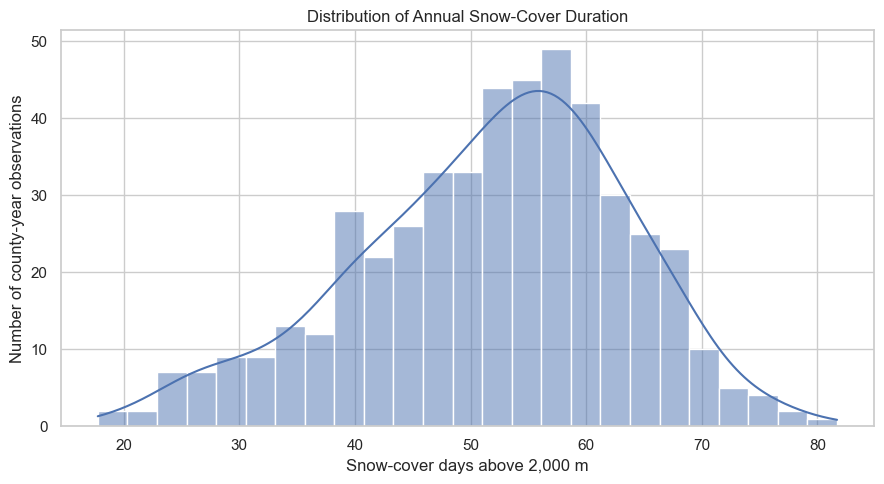

In [16]:
print(model_df[TARGET].describe().round(2))

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=model_df,
    x=TARGET,
    bins=25,
    kde=True,
    ax=ax
)

ax.set_title("Distribution of Annual Snow-Cover Duration")
ax.set_xlabel("Snow-cover days above 2,000 m")
ax.set_ylabel("Number of county-year observations")

plt.tight_layout()
plt.show()

,state,county,mean,std,min,max
8,Colorado,Summit,65.44,5.49,55.53,76.05
3,Colorado,Gunnison,64.44,5.72,48.86,75.76
9,Idaho,Blaine,64.43,6.94,51.27,81.69
5,Colorado,Pitkin,62.70,5.76,54.28,77.29
17,Utah,Summit,58.64,6.81,48.48,75.09
0,Colorado,Clear Creek,58.12,6.40,46.45,71.97
18,Utah,Wasatch,57.81,7.50,39.39,73.71
1,Colorado,Eagle,56.67,5.70,44.41,69.81
2,Colorado,Grand,55.00,5.99,43.23,67.10
6,Colorado,Routt,52.96,5.77,40.00,63.36


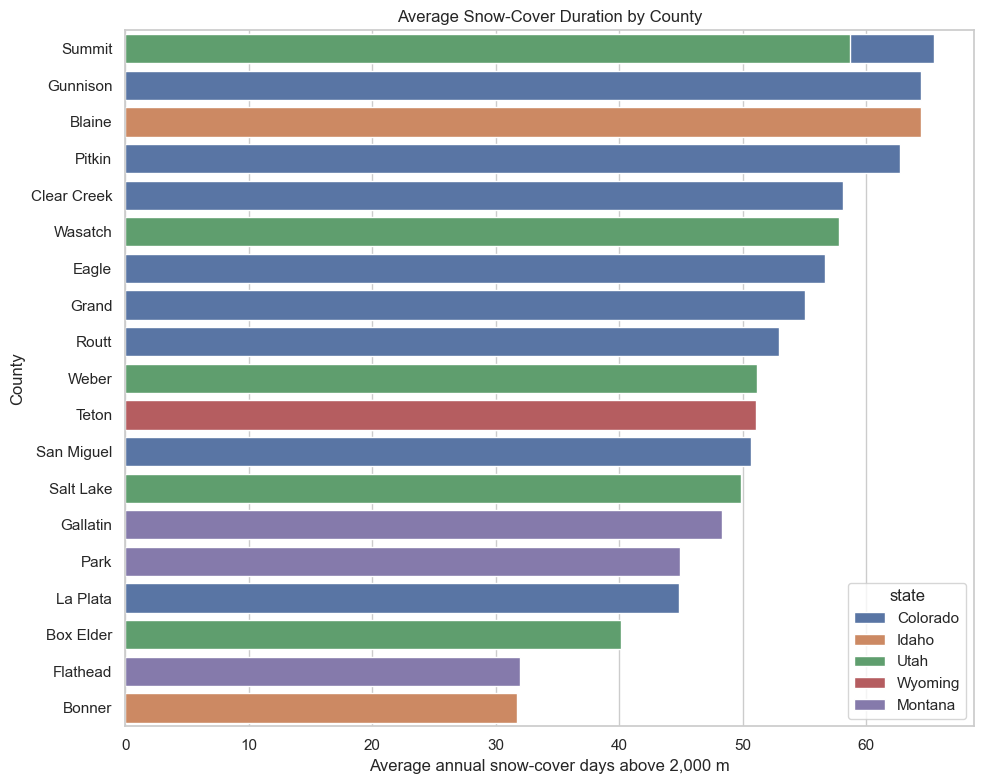

In [17]:
county_summary = (
    model_df.groupby(["state", "county"])[TARGET]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
    .sort_values("mean", ascending=False)
)

display(county_summary.round(2))

plt.figure(figsize=(10, 8))

sns.barplot(
    data=county_summary,
    x="mean",
    y="county",
    hue="state",
    dodge=False
)

plt.xlabel("Average annual snow-cover days above 2,000 m")
plt.ylabel("County")
plt.title("Average Snow-Cover Duration by County")
plt.tight_layout()
plt.show()

### 3.3 Climate and Snow-Cover Relationships

Examine the relationships between historical climate conditions
and snow-cover duration, distinguishing variation across counties
from year-to-year variation within counties.

,Correlation with snow days
tmin_djf,-0.480
tmin_apr,-0.340
precip_on,-0.276
precip_djf,-0.236
mean_northness,0.020
mean_eastness,0.102
mean_slope_deg,0.248
frac_above_3000m,0.513
frac_above_2000m,0.575
frac_above_2500m,0.587


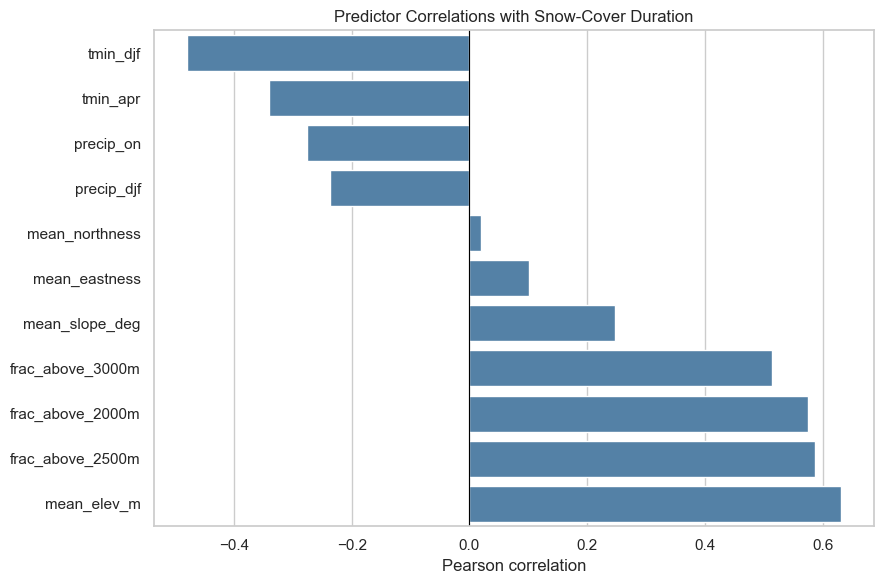

In [18]:
# Correlations across all county-year observations
corr_vars = CLIMATE_FEATURES + TERRAIN_FEATURES + [TARGET]

correlations = (
    model_df[corr_vars]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values()
)

display(correlations.to_frame("Correlation with snow days").round(3))

plt.figure(figsize=(9, 6))

sns.barplot(
    x=correlations.values,
    y=correlations.index,
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson correlation")
plt.ylabel("")
plt.title("Predictor Correlations with Snow-Cover Duration")
plt.tight_layout()
plt.show()

In [19]:
# Create county-demeaned variables
within_df = model_df.copy()

for col in CLIMATE_FEATURES + [TARGET]:
    within_df[col + "_dm"] = (
        within_df[col]
        - within_df.groupby("fips")[col].transform("mean")
    )

# Correlation between climate anomalies and snow anomalies
within_corr = (
    within_df[
        [c + "_dm" for c in CLIMATE_FEATURES]
        + [TARGET + "_dm"]
    ]
    .corr()[TARGET + "_dm"]
    .drop(TARGET + "_dm")
    .sort_values()
)

display(
    within_corr.to_frame(
        "Within-county correlation"
    ).round(3)
)

,Within-county correlation
tmin_djf_dm,-0.145
precip_djf_dm,-0.053
tmin_apr_dm,0.068
precip_on_dm,0.075


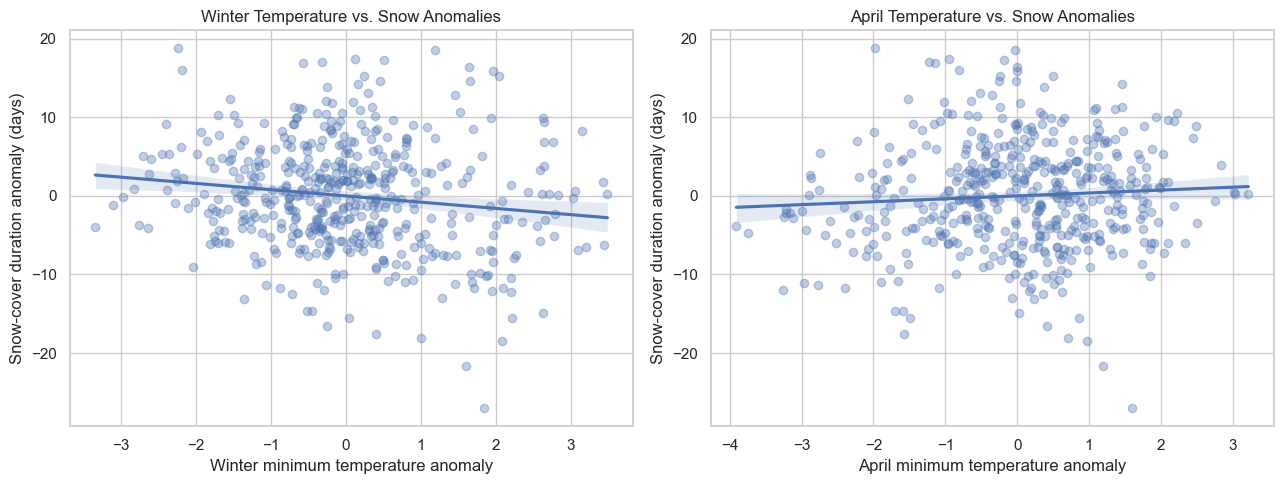

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    data=within_df,
    x="tmin_djf_dm",
    y=TARGET + "_dm",
    scatter_kws={"alpha": 0.35},
    ax=axes[0]
)

axes[0].set_title("Winter Temperature vs. Snow Anomalies")
axes[0].set_xlabel("Winter minimum temperature anomaly")
axes[0].set_ylabel("Snow-cover duration anomaly (days)")

sns.regplot(
    data=within_df,
    x="tmin_apr_dm",
    y=TARGET + "_dm",
    scatter_kws={"alpha": 0.35},
    ax=axes[1]
)

axes[1].set_title("April Temperature vs. Snow Anomalies")
axes[1].set_xlabel("April minimum temperature anomaly")
axes[1].set_ylabel("Snow-cover duration anomaly (days)")

plt.tight_layout()
plt.show()

## 4. Examining Cloud Cover



In [24]:
from pathlib import Path
import pandas as pd

data_dir = Path.home() / "Files/thesis/snow_ml/ml_model"

snow = pd.read_csv(data_dir / "county_snow_validation_v3.csv")
climate = pd.read_csv(data_dir / "county_climate_panel_v3.csv")

print("Snow:", snow.shape)
print("Climate:", climate.shape)

Snow: (506, 23)
Climate: (506, 32)


In [25]:
# Standardize FIPS and year
for data in [snow, climate]:
    data["fips"] = (
        data["fips"].astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )
    data["year"] = data["year"].astype(int)

# Merge snow and climate data
df = snow.merge(
    climate,
    on=["fips", "year"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_climate")
)

print("Observations:", len(df))
print("Counties:", df["fips"].nunique())
print("Years:", df["year"].nunique())

print("\nColumns:")
print(df.columns.tolist())

Observations: 506
Counties: 22
Years: 23

Columns:
['fips', 'state', 'county', 'year', 'season_days', 'snow_detected_all', 'valid_days_all', 'cloud_days_all', 'other_days_all', 'valid_fraction_all', 'cloud_fraction_all', 'other_fraction_all', 'observed_snow_fraction_all', 'snow_adjusted_all', 'snow_detected_2000m', 'valid_days_2000m', 'cloud_days_2000m', 'other_days_2000m', 'valid_fraction_2000m', 'cloud_fraction_2000m', 'other_fraction_2000m', 'observed_snow_fraction_2000m', 'snow_adjusted_2000m', 'state_climate', 'county_climate', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_ap

In [26]:
targets = [
    "snow_detected_2000m",
    "snow_adjusted_2000m",
    "observed_snow_fraction_2000m"
]

print(df[targets].describe().round(2))

print("\nCorrelations between snow measurements:")
print(df[targets].corr().round(3))

       snow_detected_2000m  snow_adjusted_2000m  observed_snow_fraction_2000m
count               460.00               460.00                        460.00
mean                 52.79               149.45                          0.82
std                  10.89                25.39                          0.14
min                  17.64                34.01                          0.19
25%                  45.89               137.64                          0.76
50%                  53.90               154.41                          0.85
75%                  60.33               168.82                          0.93
max                  81.76               181.80                          1.00

Correlations between snow measurements:
                              snow_detected_2000m  snow_adjusted_2000m  \
snow_detected_2000m                         1.000                0.193   
snow_adjusted_2000m                         0.193                1.000   
observed_snow_fraction_2000m       

In [27]:
climate_vars = [
    "tmin_djf",
    "tmax_djf",
    "tmin_mar",
    "tmax_mar",
    "tmin_apr",
    "tmax_apr",
    "precip_djf",
    "precip_mar_apr",
    "positive_degree_days",
    "thaw_days"
]

# Keep variables available in your dataset
climate_vars = [v for v in climate_vars if v in df.columns]

# Pooled correlations
print("POOLED CORRELATIONS")
print(
    df[targets + climate_vars]
    .corr()
    .loc[targets, climate_vars]
    .round(3)
    .to_string()
)

# Within-county correlations
within = df.copy()

for col in targets + climate_vars:
    within[col] = (
        within[col]
        - within.groupby("fips")[col].transform("mean")
    )

print("\nWITHIN-COUNTY CORRELATIONS")
print(
    within[targets + climate_vars]
    .corr()
    .loc[targets, climate_vars]
    .round(3)
    .to_string()
)

POOLED CORRELATIONS
Empty DataFrame
Columns: []
Index: [snow_detected_2000m, snow_adjusted_2000m, observed_snow_fraction_2000m]

WITHIN-COUNTY CORRELATIONS
Empty DataFrame
Columns: []
Index: [snow_detected_2000m, snow_adjusted_2000m, observed_snow_fraction_2000m]


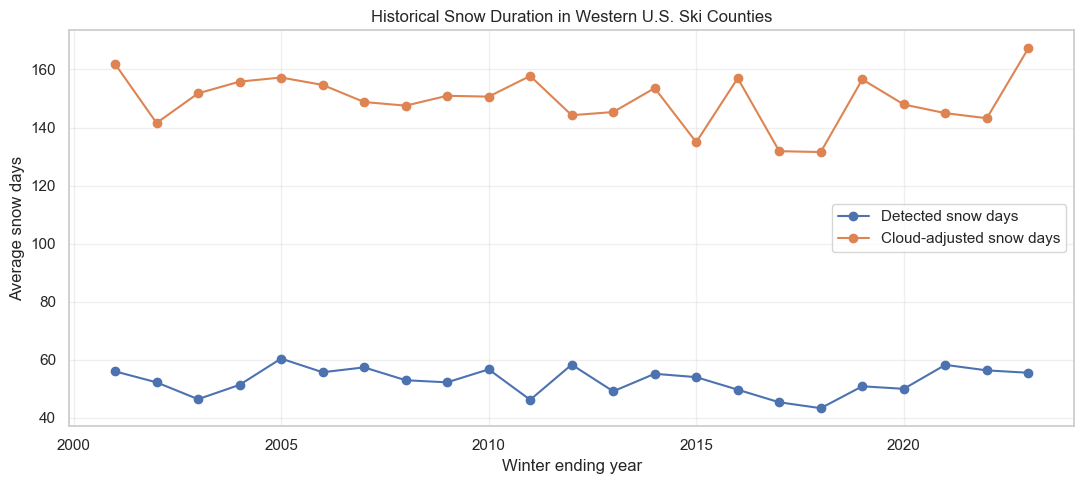

In [28]:
import matplotlib.pyplot as plt

annual = df.groupby("year")[
    ["snow_detected_2000m", "snow_adjusted_2000m"]
].mean()

plt.figure(figsize=(11, 5))

plt.plot(
    annual.index,
    annual["snow_detected_2000m"],
    marker="o",
    label="Detected snow days"
)

plt.plot(
    annual.index,
    annual["snow_adjusted_2000m"],
    marker="o",
    label="Cloud-adjusted snow days"
)

plt.xlabel("Winter ending year")
plt.ylabel("Average snow days")
plt.title("Historical Snow Duration in Western U.S. Ski Counties")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# STEP 3: Compare snow duration with climate variables

climate_vars = [
    "tmin_djf_2000m",
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmin_apr_2000m",
    "tmax_apr_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m",
    "precip_freezing_fraction_2000m"
]

targets = [
    "snow_detected_2000m",
    "snow_adjusted_2000m",
    "observed_snow_fraction_2000m"
]

# Keep observations with complete snow and climate data
analysis = df.dropna(subset=targets + climate_vars).copy()

print("Complete observations:", len(analysis))
print("Counties:", analysis["fips"].nunique())

# 1. Pooled correlations
pooled_corr = (
    analysis[targets + climate_vars]
    .corr()
    .loc[targets, climate_vars]
)

print("\nPOOLED CORRELATIONS")
print(pooled_corr.round(3).to_string())

# 2. Within-county correlations
within = analysis.copy()

for col in targets + climate_vars:
    within[col] = (
        within[col]
        - within.groupby("fips")[col].transform("mean")
    )

within_corr = (
    within[targets + climate_vars]
    .corr()
    .loc[targets, climate_vars]
)

print("\nWITHIN-COUNTY CORRELATIONS")
print(within_corr.round(3).to_string())

Complete observations: 460
Counties: 20

POOLED CORRELATIONS
                              tmin_djf_2000m  tmax_djf_2000m  tmin_mar_2000m  tmax_mar_2000m  tmin_apr_2000m  tmax_apr_2000m  precip_djf_2000m  precip_mar_apr_2000m  positive_degree_days_2000m  freezing_degree_days_2000m  thaw_days_2000m  precip_freezing_fraction_2000m
snow_detected_2000m                   -0.376           0.059          -0.289           0.064          -0.172           0.119            -0.317                -0.319                      -0.152                       0.151            0.089                           0.311
snow_adjusted_2000m                   -0.419          -0.742          -0.446          -0.621          -0.475          -0.618             0.355                 0.464                      -0.815                       0.698           -0.756                           0.642
observed_snow_fraction_2000m          -0.419          -0.742          -0.448          -0.623          -0.476          -0.620     

In [30]:
coverage_vars = [
    "valid_fraction_2000m",
    "cloud_fraction_2000m",
    "valid_days_2000m",
    "cloud_days_2000m"
]

print("CLOUD COVERAGE CORRELATIONS")

print(
    analysis[targets + coverage_vars]
    .corr()
    .loc[targets, coverage_vars]
    .round(3)
    .to_string()
)

# Within-county coverage correlations
coverage_within = analysis.copy()

for col in targets + coverage_vars:
    coverage_within[col] = (
        coverage_within[col]
        - coverage_within.groupby("fips")[col].transform("mean")
    )

print("\nWITHIN-COUNTY CLOUD COVERAGE CORRELATIONS")

print(
    coverage_within[targets + coverage_vars]
    .corr()
    .loc[targets, coverage_vars]
    .round(3)
    .to_string()
)

CLOUD COVERAGE CORRELATIONS
                              valid_fraction_2000m  cloud_fraction_2000m  valid_days_2000m  cloud_days_2000m
snow_detected_2000m                          0.590                -0.567             0.590            -0.568
snow_adjusted_2000m                         -0.653                 0.634            -0.653             0.634
observed_snow_fraction_2000m                -0.653                 0.635            -0.653             0.635

WITHIN-COUNTY CLOUD COVERAGE CORRELATIONS
                              valid_fraction_2000m  cloud_fraction_2000m  valid_days_2000m  cloud_days_2000m
snow_detected_2000m                          0.656                -0.573             0.657            -0.576
snow_adjusted_2000m                         -0.339                 0.282            -0.339             0.283
observed_snow_fraction_2000m                -0.337                 0.284            -0.337             0.285


In [31]:
import statsmodels.formula.api as smf

regression = analysis.copy()

model = smf.ols(
    formula=(
        "snow_adjusted_2000m ~ "
        "positive_degree_days_2000m + "
        "precip_djf_2000m + "
        "precip_mar_apr_2000m + "
        "valid_fraction_2000m + "
        "C(fips) + C(year)"
    ),
    data=regression
).fit(
    cov_type="cluster",
    cov_kwds={"groups": regression["fips"]}
)

print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     snow_adjusted_2000m   R-squared:                       0.910
Model:                             OLS   Adj. R-squared:                  0.900
Method:                  Least Squares   F-statistic:                     633.0
Date:                 Thu, 12 Nov 2026   Prob (F-statistic):           1.12e-22
Time:                         20:23:57   Log-Likelihood:                -1585.5
No. Observations:                  460   AIC:                             3263.
Df Residuals:                      414   BIC:                             3453.
Df Model:                           45                                         
Covariance Type:               cluster                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept 

/Users/evabenson/Files/thesis/snow_ml/venv/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 45, but rank is 19
  res = self.wald_test(


## 5. Random Forest Model

In [32]:
# Standardize county identifiers
terrain["fips"] = (
    terrain["fips"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Merge terrain with the snow-climate panel
model_df = df.merge(
    terrain,
    on="fips",
    how="left",
    validate="many_to_one",
    suffixes=("", "_terrain")
)

print("Observations:", len(model_df))
print("Columns:", model_df.columns.tolist())

Observations: 506
Columns: ['fips', 'state', 'county', 'year', 'season_days', 'snow_detected_all', 'valid_days_all', 'cloud_days_all', 'other_days_all', 'valid_fraction_all', 'cloud_fraction_all', 'other_fraction_all', 'observed_snow_fraction_all', 'snow_adjusted_all', 'snow_detected_2000m', 'valid_days_2000m', 'cloud_days_2000m', 'other_days_2000m', 'valid_fraction_2000m', 'cloud_fraction_2000m', 'other_fraction_2000m', 'observed_snow_fraction_2000m', 'snow_adjusted_2000m', 'state_climate', 'county_climate', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degr

In [33]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

target = "snow_adjusted_2000m"

climate_features = [
    "tmin_djf_2000m",
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmin_apr_2000m",
    "tmax_apr_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m"
]

terrain_features = [
    "mean_elev_m",
    "mean_slope_deg",
    "mean_northness",
    "mean_eastness",
    "frac_above_2000m",
    "frac_above_2500m",
    "frac_above_3000m"
]

features = climate_features + terrain_features

# Verify columns before fitting
missing = [c for c in features if c not in model_df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Keep complete observations
data = model_df.dropna(subset=[target] + features).copy()

X = data[features]
y = data[target]
groups = data["year"]

print("Training observations:", len(data))
print("Counties:", data["fips"].nunique())
print("Years:", data["year"].nunique())

logo = LeaveOneGroupOut()
predictions = np.full(len(data), np.nan)

for train_idx, test_idx in logo.split(X, y, groups):
    rf = RandomForestRegressor(
        n_estimators=500,
        min_samples_leaf=3,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X.iloc[train_idx], y.iloc[train_idx])
    predictions[test_idx] = rf.predict(X.iloc[test_idx])

print("\nLEAVE-ONE-YEAR-OUT RESULTS")
print("R²:", round(r2_score(y, predictions), 3))
print("MAE:", round(mean_absolute_error(y, predictions), 2), "days")
print("RMSE:", round(np.sqrt(mean_squared_error(y, predictions)), 2), "days")

data["predicted_snow_days"] = predictions

Training observations: 460
Counties: 20
Years: 23

LEAVE-ONE-YEAR-OUT RESULTS
R²: 0.782
MAE: 8.96 days
RMSE: 11.84 days


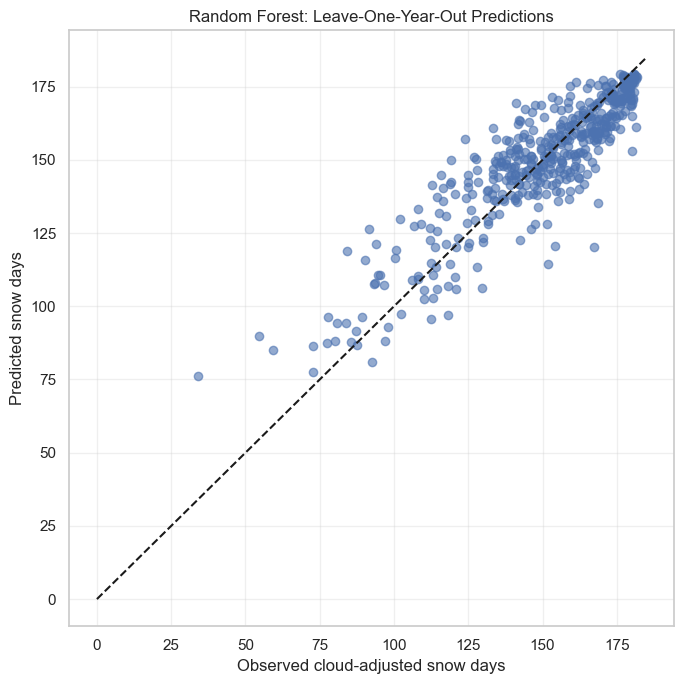

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.scatter(
    data[target],
    data["predicted_snow_days"],
    alpha=0.6
)

plt.plot([0, 185], [0, 185], "k--")

plt.xlabel("Observed cloud-adjusted snow days")
plt.ylabel("Predicted snow days")
plt.title("Random Forest: Leave-One-Year-Out Predictions")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
baseline = np.full(len(data), np.nan)

for train_idx, test_idx in logo.split(X, y, groups):
    train = data.iloc[train_idx]
    test = data.iloc[test_idx]

    county_means = train.groupby("fips")[target].mean()
    baseline[test_idx] = (
        test["fips"].map(county_means).to_numpy()
    )

print("COUNTY-MEAN BASELINE")
print("R²:", round(r2_score(y, baseline), 3))
print("MAE:", round(mean_absolute_error(y, baseline), 2), "days")

COUNTY-MEAN BASELINE
R²: 0.724
MAE: 9.8 days


positive_degree_days_2000m    0.334
thaw_days_2000m               0.266
tmax_djf_2000m                0.092
freezing_degree_days_2000m    0.068
precip_djf_2000m              0.036
mean_eastness                 0.029
tmax_apr_2000m                0.027
precip_mar_apr_2000m          0.024
frac_above_3000m              0.018
frac_above_2500m              0.017
tmin_apr_2000m                0.014
mean_elev_m                   0.013
tmax_mar_2000m                0.011
mean_northness                0.011
frac_above_2000m              0.011
tmin_djf_2000m                0.011
mean_slope_deg                0.009
tmin_mar_2000m                0.008


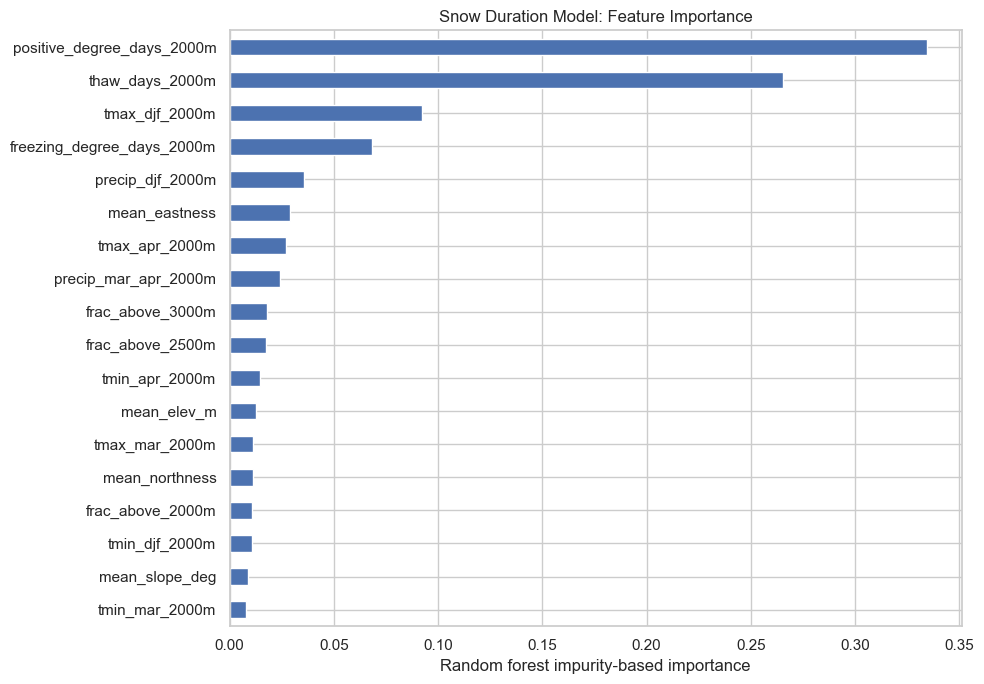

In [36]:
# Train final descriptive model on all historical observations
final_rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=3,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X, y)

importance = pd.Series(
    final_rf.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance.round(3).to_string())

plt.figure(figsize=(10, 7))
importance.sort_values().plot(kind="barh")
plt.xlabel("Random forest impurity-based importance")
plt.title("Snow Duration Model: Feature Importance")
plt.tight_layout()
plt.show()

Within-county anomaly R²: 0.215
Within-county anomaly correlation: 0.528


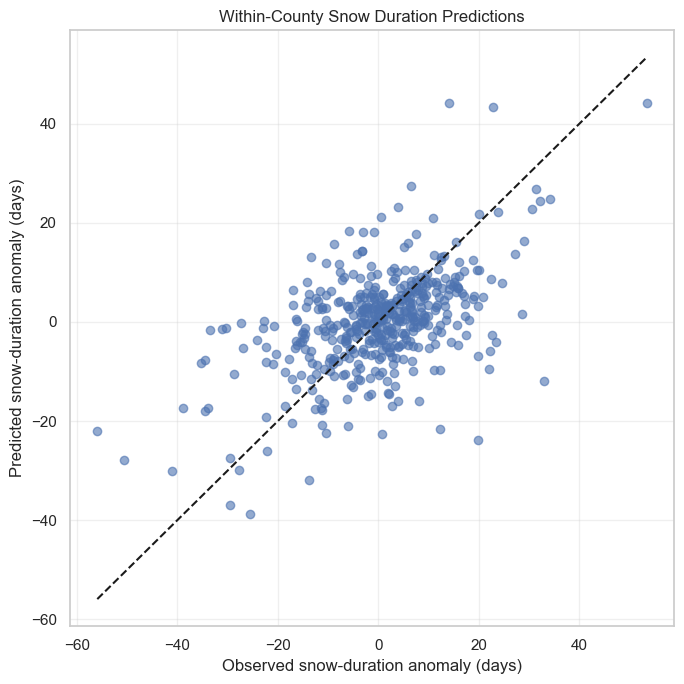

In [37]:
# Remove each county's average from observed and predicted snow days
data["observed_anomaly"] = (
    data[target]
    - data.groupby("fips")[target].transform("mean")
)

data["predicted_anomaly"] = (
    data["predicted_snow_days"]
    - data.groupby("fips")["predicted_snow_days"].transform("mean")
)

print("Within-county anomaly R²:",
      round(r2_score(
          data["observed_anomaly"],
          data["predicted_anomaly"]
      ), 3))

print("Within-county anomaly correlation:",
      round(data[
          ["observed_anomaly", "predicted_anomaly"]
      ].corr().iloc[0, 1], 3))

plt.figure(figsize=(7, 7))

plt.scatter(
    data["observed_anomaly"],
    data["predicted_anomaly"],
    alpha=0.6
)

limits = [
    min(data["observed_anomaly"].min(),
        data["predicted_anomaly"].min()),
    max(data["observed_anomaly"].max(),
        data["predicted_anomaly"].max())
]

plt.plot(limits, limits, "k--")

plt.xlabel("Observed snow-duration anomaly (days)")
plt.ylabel("Predicted snow-duration anomaly (days)")
plt.title("Within-County Snow Duration Predictions")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## SNODAS Data

In [41]:
from pathlib import Path
import pandas as pd

file_path = (
    Path.home()
    / "Files"
    / "thesis"
    / "snow_ml"
    / "ml_model"
    / "county_snodas_climate_terrain_merged.csv"
)

df = pd.read_csv(file_path, dtype={"fips": str})

print("Full dataset:", df.shape)
print("Counties:", df["fips"].nunique())
print("Years:", df["year"].min(), "-", df["year"].max())

Full dataset: (440, 54)
Counties: 22
Years: 2004 - 2023


In [43]:

logo = LeaveOneGroupOut()

predictions = np.full(len(model_df), np.nan)
baseline_predictions = np.full(len(model_df), np.nan)

for train_idx, test_idx in logo.split(X, y, groups):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]

    rf = RandomForestRegressor(
        n_estimators=500,
        min_samples_leaf=3,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    predictions[test_idx] = rf.predict(X_test)

    # County historical-mean baseline.
    # IMPORTANT: only use training years.
    train_counties = model_df.iloc[train_idx]["fips"]

    county_means = y_train.groupby(
        train_counties
    ).mean()

    test_counties = model_df.iloc[test_idx]["fips"]

    baseline_predictions[test_idx] = (
        test_counties.map(county_means)
        .fillna(y_train.mean())
        .to_numpy()
    )

model_df["rf_predicted"] = predictions
model_df["baseline_predicted"] = baseline_predictions

print("Cross-validation complete.")
print("Missing predictions:", np.isnan(predictions).sum())


Cross-validation complete.
Missing predictions: 0


In [44]:

def evaluate_model(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }

rf_results = evaluate_model(
    model_df[TARGET],
    model_df["rf_predicted"]
)

baseline_results = evaluate_model(
    model_df[TARGET],
    model_df["baseline_predicted"]
)

performance = pd.DataFrame({
    "Random Forest": rf_results,
    "County Mean Baseline": baseline_results
}).T

print(performance.round(3))

mae_improvement = (
    1 - rf_results["MAE"] / baseline_results["MAE"]
) * 100

print(
    f"\nRF MAE improvement over baseline: "
    f"{mae_improvement:.1f}%"
)


                         R2     MAE    RMSE
Random Forest         0.761  10.040  14.519
County Mean Baseline  0.677  11.957  16.875

RF MAE improvement over baseline: 16.0%


In [45]:

# Training-only county means were calculated
# during cross-validation.
# They are stored in baseline_predicted.

model_df["observed_anomaly"] = (
    model_df[TARGET] -
    model_df["baseline_predicted"]
)

model_df["predicted_anomaly"] = (
    model_df["rf_predicted"] -
    model_df["baseline_predicted"]
)

anomaly_r2 = r2_score(
    model_df["observed_anomaly"],
    model_df["predicted_anomaly"]
)

anomaly_mae = mean_absolute_error(
    model_df["observed_anomaly"],
    model_df["predicted_anomaly"]
)

anomaly_corr = model_df[
    ["observed_anomaly", "predicted_anomaly"]
].corr().iloc[0, 1]

print(f"Anomaly R2: {anomaly_r2:.3f}")
print(f"Anomaly MAE: {anomaly_mae:.2f} days")
print(f"Anomaly correlation: {anomaly_corr:.3f}")


Anomaly R2: 0.260
Anomaly MAE: 10.04 days
Anomaly correlation: 0.573


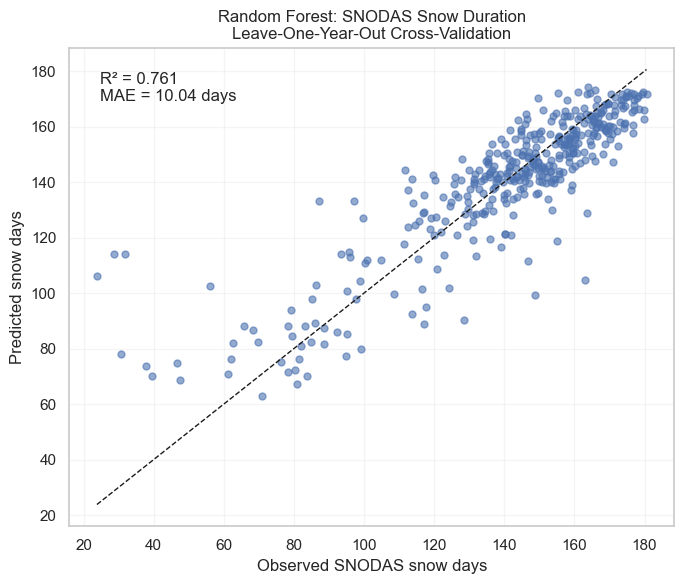

In [46]:

plt.figure(figsize=(7, 6))

plt.scatter(
    model_df[TARGET],
    model_df["rf_predicted"],
    alpha=0.6,
    s=25
)

limits = [
    min(model_df[TARGET].min(),
        model_df["rf_predicted"].min()),
    max(model_df[TARGET].max(),
        model_df["rf_predicted"].max())
]

plt.plot(limits, limits, "k--", linewidth=1)

plt.xlabel("Observed SNODAS snow days")
plt.ylabel("Predicted snow days")
plt.title(
    "Random Forest: SNODAS Snow Duration\n"
    "Leave-One-Year-Out Cross-Validation"
)

plt.text(
    0.05, 0.95,
    f"R² = {rf_results['R2']:.3f}\n"
    f"MAE = {rf_results['MAE']:.2f} days",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [47]:

# Examine prediction errors by observed snow duration

model_df["prediction_error"] = (
    model_df["rf_predicted"] - model_df[TARGET]
)

model_df["snow_category"] = pd.cut(
    model_df[TARGET],
    bins=[0, 90, 120, 150, 200],
    labels=[
        "Under 90 days",
        "90–120 days",
        "120–150 days",
        "Over 150 days"
    ],
    include_lowest=True
)

error_summary = (
    model_df.groupby(
        "snow_category",
        observed=True
    )
    .agg(
        observations=(TARGET, "count"),
        mean_error=("prediction_error", "mean"),
        MAE=("prediction_error", lambda x: x.abs().mean())
    )
)

print(error_summary.round(2))


               observations  mean_error    MAE
snow_category                                 
Under 90 days            34       17.65  21.66
90–120 days              36        6.36  14.78
120–150 days            150        1.27   8.37
Over 150 days           180       -6.17   8.29


## County FE Model

In [48]:

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Start with a parsimonious climate specification
fe_features = [
    "positive_degree_days_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

X_fe = model_df[fe_features + ["fips"]]
y_fe = model_df["snow_days_10cm_2000m"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "county",
            OneHotEncoder(handle_unknown="ignore"),
            ["fips"]
        ),
        (
            "climate",
            "passthrough",
            fe_features
        )
    ]
)

fe_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

fe_predictions = np.full(len(model_df), np.nan)

logo = LeaveOneGroupOut()

for train_idx, test_idx in logo.split(
    X_fe, y_fe, groups=model_df["year"]
):
    fe_model.fit(
        X_fe.iloc[train_idx],
        y_fe.iloc[train_idx]
    )

    fe_predictions[test_idx] = fe_model.predict(
        X_fe.iloc[test_idx]
    )

model_df["fe_predicted"] = fe_predictions

print("Fixed-effects cross-validation complete.")


Fixed-effects cross-validation complete.


In [49]:

comparison = pd.DataFrame({
    "Random Forest": evaluate_model(
        model_df[TARGET],
        model_df["rf_predicted"]
    ),
    "County FE Linear Model": evaluate_model(
        model_df[TARGET],
        model_df["fe_predicted"]
    ),
    "County Mean Baseline": evaluate_model(
        model_df[TARGET],
        model_df["baseline_predicted"]
    )
}).T

print(comparison.round(3))


                           R2     MAE    RMSE
Random Forest           0.761  10.040  14.519
County FE Linear Model  0.791   9.480  13.563
County Mean Baseline    0.677  11.957  16.875


In [50]:

model_df["fe_error"] = (
    model_df["fe_predicted"] - model_df[TARGET]
)

bias_comparison = model_df.groupby(
    "snow_category",
    observed=True
).agg(
    observations=(TARGET, "count"),
    rf_mean_error=("prediction_error", "mean"),
    fe_mean_error=("fe_error", "mean"),
    rf_mae=("prediction_error", lambda x: x.abs().mean()),
    fe_mae=("fe_error", lambda x: x.abs().mean())
)

print(bias_comparison.round(2))


               observations  rf_mean_error  fe_mean_error  rf_mae  fe_mae
snow_category                                                            
Under 90 days            34          17.65          13.97   21.66   18.69
90–120 days              36           6.36           1.72   14.78   13.12
120–150 days            150           1.27           0.74    8.37    9.39
Over 150 days           180          -6.17          -3.98    8.29    7.08


In [51]:

from sklearn.metrics import r2_score, mean_absolute_error

# Use the training-only county baseline from
# the leave-one-year-out cross-validation.

model_df["fe_predicted_anomaly"] = (
    model_df["fe_predicted"] -
    model_df["baseline_predicted"]
)

fe_anomaly_r2 = r2_score(
    model_df["observed_anomaly"],
    model_df["fe_predicted_anomaly"]
)

fe_anomaly_mae = mean_absolute_error(
    model_df["observed_anomaly"],
    model_df["fe_predicted_anomaly"]
)

fe_anomaly_corr = model_df[
    ["observed_anomaly", "fe_predicted_anomaly"]
].corr().iloc[0, 1]

anomaly_comparison = pd.DataFrame({
    "Random Forest": {
        "Anomaly R2": anomaly_r2,
        "Anomaly MAE": anomaly_mae,
        "Anomaly Correlation": anomaly_corr
    },
    "County FE Linear": {
        "Anomaly R2": fe_anomaly_r2,
        "Anomaly MAE": fe_anomaly_mae,
        "Anomaly Correlation": fe_anomaly_corr
    }
}).T

print(anomaly_comparison.round(3))


                  Anomaly R2  Anomaly MAE  Anomaly Correlation
Random Forest          0.260        10.04                0.573
County FE Linear       0.354         9.48                0.598


## Testing Non-Linear Temperature

In [52]:
model_df["pdd_squared"] = (
    model_df["positive_degree_days_2000m"] ** 2
)

In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneGroupOut

quad_features = [
    "positive_degree_days_2000m",
    "pdd_squared",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

X_quad = model_df[quad_features + ["fips"]]
y_quad = model_df[TARGET]

quad_preprocessor = ColumnTransformer(
    transformers=[
        (
            "county",
            OneHotEncoder(handle_unknown="ignore"),
            ["fips"]
        ),
        (
            "climate",
            "passthrough",
            quad_features
        )
    ]
)

quad_model = Pipeline([
    ("preprocessor", quad_preprocessor),
    ("regression", LinearRegression())
])

quad_predictions = np.full(len(model_df), np.nan)

logo = LeaveOneGroupOut()

for train_idx, test_idx in logo.split(
    X_quad,
    y_quad,
    groups=model_df["year"]
):
    quad_model.fit(
        X_quad.iloc[train_idx],
        y_quad.iloc[train_idx]
    )

    quad_predictions[test_idx] = quad_model.predict(
        X_quad.iloc[test_idx]
    )

model_df["quad_predicted"] = quad_predictions

In [54]:
comparison = pd.DataFrame({
    "Random Forest": evaluate_model(
        model_df[TARGET],
        model_df["rf_predicted"]
    ),
    "County FE Linear": evaluate_model(
        model_df[TARGET],
        model_df["fe_predicted"]
    ),
    "County FE Quadratic": evaluate_model(
        model_df[TARGET],
        model_df["quad_predicted"]
    )
}).T

print(comparison.round(3))

                        R2     MAE    RMSE
Random Forest        0.761  10.040  14.519
County FE Linear     0.791   9.480  13.563
County FE Quadratic  0.776  10.053  14.036


In [55]:
model_df["quad_predicted_anomaly"] = (
    model_df["quad_predicted"] -
    model_df["baseline_predicted"]
)

quad_anomaly_r2 = r2_score(
    model_df["observed_anomaly"],
    model_df["quad_predicted_anomaly"]
)

quad_anomaly_corr = model_df[
    ["observed_anomaly", "quad_predicted_anomaly"]
].corr().iloc[0, 1]

print(f"Quadratic anomaly R²: {quad_anomaly_r2:.3f}")
print(f"Quadratic anomaly correlation: {quad_anomaly_corr:.3f}")

Quadratic anomaly R²: 0.308
Quadratic anomaly correlation: 0.598


## Can we identify unusually warm winters?

In [56]:
# Calculate county-specific 75th percentile
pdd_threshold = model_df.groupby("fips")[
    "positive_degree_days_2000m"
].transform(lambda x: x.quantile(0.75))

model_df["warm_winter"] = (
    model_df["positive_degree_days_2000m"] >= pdd_threshold
)

print(model_df["warm_winter"].value_counts())

warm_winter
False    300
True     100
Name: count, dtype: int64


In [57]:
warm_results = model_df.groupby(
    "warm_winter"
).agg(
    observations=(TARGET, "count"),
    observed_snow_days=(TARGET, "mean"),
    rf_mean_error=("prediction_error", "mean"),
    fe_mean_error=("fe_error", "mean"),
    rf_mae=("prediction_error", lambda x: x.abs().mean()),
    fe_mae=("fe_error", lambda x: x.abs().mean())
)

print(warm_results.round(2))

             observations  observed_snow_days  rf_mean_error  fe_mean_error  \
warm_winter                                                                   
False                 300              144.93          -0.06           0.45   
True                  100              129.82          -0.75          -2.03   

             rf_mae  fe_mae  
warm_winter                  
False          9.61    9.06  
True          11.32   10.73  


## 6. Adding XGBoost

In [58]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [59]:
from xgboost import XGBRegressor
from sklearn.model_selection import LeaveOneGroupOut
import numpy as np

X = model_df[FEATURES]
y = model_df[TARGET]
groups = model_df["year"]

logo = LeaveOneGroupOut()

xgb_predictions = np.full(len(model_df), np.nan)

for train_idx, test_idx in logo.split(X, y, groups):

    xgb = XGBRegressor(
        n_estimators=300,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=10,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    xgb.fit(
        X.iloc[train_idx],
        y.iloc[train_idx]
    )

    xgb_predictions[test_idx] = xgb.predict(
        X.iloc[test_idx]
    )

model_df["xgb_predicted"] = xgb_predictions

print("XGBoost cross-validation complete.")

XGBoost cross-validation complete.


In [60]:
comparison = pd.DataFrame({
    "Random Forest": evaluate_model(
        model_df[TARGET],
        model_df["rf_predicted"]
    ),
    "County FE Linear": evaluate_model(
        model_df[TARGET],
        model_df["fe_predicted"]
    ),
    "County FE Quadratic": evaluate_model(
        model_df[TARGET],
        model_df["quad_predicted"]
    ),
    "XGBoost": evaluate_model(
        model_df[TARGET],
        model_df["xgb_predicted"]
    )
}).T

print(comparison.round(3))

                        R2     MAE    RMSE
Random Forest        0.761  10.040  14.519
County FE Linear     0.791   9.480  13.563
County FE Quadratic  0.776  10.053  14.036
XGBoost              0.771   9.826  14.199


In [61]:
from sklearn.metrics import r2_score, mean_absolute_error

model_df["xgb_predicted_anomaly"] = (
    model_df["xgb_predicted"] -
    model_df["baseline_predicted"]
)

xgb_anomaly_r2 = r2_score(
    model_df["observed_anomaly"],
    model_df["xgb_predicted_anomaly"]
)

xgb_anomaly_corr = model_df[
    ["observed_anomaly", "xgb_predicted_anomaly"]
].corr().iloc[0, 1]

print(f"XGBoost anomaly R²: {xgb_anomaly_r2:.3f}")
print(f"XGBoost anomaly MAE: {mean_absolute_error(model_df['observed_anomaly'], model_df['xgb_predicted_anomaly']):.3f}")
print(f"XGBoost anomaly correlation: {xgb_anomaly_corr:.3f}")

XGBoost anomaly R²: 0.292
XGBoost anomaly MAE: 9.826
XGBoost anomaly correlation: 0.587


## 7. Adding Forward Chain

In [62]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

folds = [
    (2013, 2014, 2016),
    (2016, 2017, 2019),
    (2019, 2020, 2023)
]

fe_features = [
    "positive_degree_days_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

forward_df = model_df.copy()

for col in ["forward_rf", "forward_fe", "forward_xgb",
            "forward_baseline"]:
    forward_df[col] = np.nan

for train_end, test_start, test_end in folds:

    train = forward_df["year"] <= train_end
    test = forward_df["year"].between(test_start, test_end)

    X_train = forward_df.loc[train, FEATURES]
    X_test = forward_df.loc[test, FEATURES]

    y_train = forward_df.loc[train, TARGET]

    # Random Forest
    rf = RandomForestRegressor(
        n_estimators=500,
        min_samples_leaf=3,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    forward_df.loc[test, "forward_rf"] = rf.predict(X_test)

    # XGBoost
    xgb = XGBRegressor(
        n_estimators=300,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=10,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    xgb.fit(X_train, y_train)
    forward_df.loc[test, "forward_xgb"] = xgb.predict(X_test)

    # County FE linear model
    preprocessor = ColumnTransformer([
        ("county",
         OneHotEncoder(handle_unknown="ignore"),
         ["fips"]),
        ("climate", "passthrough", fe_features)
    ])

    fe = Pipeline([
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ])

    fe.fit(
        forward_df.loc[train, fe_features + ["fips"]],
        y_train
    )

    forward_df.loc[test, "forward_fe"] = fe.predict(
        forward_df.loc[test, fe_features + ["fips"]]
    )

    # Historical county mean baseline
    county_means = y_train.groupby(
        forward_df.loc[train, "fips"]
    ).mean()

    forward_df.loc[test, "forward_baseline"] = (
        forward_df.loc[test, "fips"]
        .map(county_means)
        .fillna(y_train.mean())
        .to_numpy()
    )

    print(f"Completed {test_start}-{test_end}")


Completed 2014-2016
Completed 2017-2019
Completed 2020-2023


In [63]:

test_df = forward_df.dropna(
    subset=["forward_rf", "forward_fe",
            "forward_xgb", "forward_baseline"]
).copy()

results = []

for name, col in [
    ("Random Forest", "forward_rf"),
    ("County FE Linear", "forward_fe"),
    ("XGBoost", "forward_xgb"),
    ("County Mean Baseline", "forward_baseline")
]:
    results.append({
        "Model": name,
        "R2": r2_score(test_df[TARGET], test_df[col]),
        "MAE": mean_absolute_error(test_df[TARGET], test_df[col]),
        "RMSE": np.sqrt(mean_squared_error(
            test_df[TARGET], test_df[col]
        ))
    })

forward_results = pd.DataFrame(results).set_index("Model")
print(forward_results.round(3))


                         R2     MAE    RMSE
Model                                      
Random Forest         0.805  10.343  12.977
County FE Linear      0.795   9.453  13.322
XGBoost               0.797  10.115  13.254
County Mean Baseline  0.629  13.475  17.908


In [64]:

observed_anomaly = (
    test_df[TARGET] - test_df["forward_baseline"]
)

for name, col in [
    ("Random Forest", "forward_rf"),
    ("County FE Linear", "forward_fe"),
    ("XGBoost", "forward_xgb")
]:
    predicted_anomaly = (
        test_df[col] - test_df["forward_baseline"]
    )

    print(
        name,
        "Anomaly R2:",
        round(r2_score(
            observed_anomaly, predicted_anomaly
        ), 3),
        "Correlation:",
        round(observed_anomaly.corr(
            predicted_anomaly
        ), 3)
    )


Random Forest Anomaly R2: 0.436 Correlation: 0.725
County FE Linear Anomaly R2: 0.406 Correlation: 0.705
XGBoost Anomaly R2: 0.412 Correlation: 0.714


## Compare LOYO and Forward Chain on same years

In [65]:

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np
import pandas as pd

# Both prediction sets refer to the same model_df rows
comparison_df = forward_df[
    forward_df["year"].between(2014, 2023)
].copy()

models = {
    "Random Forest": ("rf_predicted", "forward_rf"),
    "County FE Linear": ("fe_predicted", "forward_fe"),
    "XGBoost": ("xgb_predicted", "forward_xgb")
}

results = []

for model_name, (loyo_col, forward_col) in models.items():
    for method, pred_col in [
        ("LOYO", loyo_col),
        ("Forward", forward_col)
    ]:
        valid = comparison_df[
            [TARGET, pred_col]
        ].dropna()

        results.append({
            "Model": model_name,
            "Validation": method,
            "R2": r2_score(valid[TARGET], valid[pred_col]),
            "MAE": mean_absolute_error(
                valid[TARGET], valid[pred_col]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                valid[TARGET], valid[pred_col]
            ))
        })

matched_results = pd.DataFrame(results)

print(
    matched_results.round(3).to_string(index=False)
)


           Model Validation    R2    MAE   RMSE
   Random Forest       LOYO 0.825  9.374 12.309
   Random Forest    Forward 0.805 10.343 12.977
County FE Linear       LOYO 0.826  8.861 12.280
County FE Linear    Forward 0.795  9.453 13.322
         XGBoost       LOYO 0.824  9.245 12.319
         XGBoost    Forward 0.797 10.115 13.254


In [66]:

results = []

for model_name, (loyo_col, forward_col) in models.items():
    for method, pred_col, baseline_col in [
        ("LOYO", loyo_col, "baseline_predicted"),
        ("Forward", forward_col, "forward_baseline")
    ]:
        valid = comparison_df[
            [TARGET, pred_col, baseline_col]
        ].dropna()

        observed_anomaly = (
            valid[TARGET] - valid[baseline_col]
        )
        predicted_anomaly = (
            valid[pred_col] - valid[baseline_col]
        )

        results.append({
            "Model": model_name,
            "Validation": method,
            "Anomaly_R2": r2_score(
                observed_anomaly,
                predicted_anomaly
            ),
            "Anomaly_Correlation": observed_anomaly.corr(
                predicted_anomaly
            )
        })

matched_anomalies = pd.DataFrame(results)

print(
    matched_anomalies.round(3).to_string(index=False)
)


           Model Validation  Anomaly_R2  Anomaly_Correlation
   Random Forest       LOYO       0.481                0.739
   Random Forest    Forward       0.436                0.725
County FE Linear       LOYO       0.484                0.731
County FE Linear    Forward       0.406                0.705
         XGBoost       LOYO       0.480                0.732
         XGBoost    Forward       0.412                0.714


## 8. Robustness Checks
Matched Feature Comparison

In [67]:

import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from xgboost import XGBRegressor

# Same predictors for all three models
matched_features = FEATURES + ["fips"]

# Encode county identifiers
X_matched = pd.get_dummies(
    model_df[matched_features],
    columns=["fips"],
    dtype=float
)

y_matched = model_df[TARGET]
groups = model_df["year"]

print("Observations:", len(X_matched))
print("Predictors:", X_matched.shape[1])
print("Years:", groups.nunique())


Observations: 400
Predictors: 38
Years: 20


In [68]:

logo = LeaveOneGroupOut()

matched_predictions = {
    "Linear": np.full(len(model_df), np.nan),
    "Random Forest": np.full(len(model_df), np.nan),
    "XGBoost": np.full(len(model_df), np.nan)
}

for train_idx, test_idx in logo.split(
    X_matched, y_matched, groups
):

    models = {
        "Linear": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ),

        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=10,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
    }

    for name, model in models.items():

        model.fit(
            X_matched.iloc[train_idx],
            y_matched.iloc[train_idx]
        )

        matched_predictions[name][test_idx] = model.predict(
            X_matched.iloc[test_idx]
        )

for name, preds in matched_predictions.items():
    model_df[f"matched_{name.lower().replace(' ', '_')}"] = preds

print("Matched-feature LOYO validation complete.")


Matched-feature LOYO validation complete.


In [69]:

matched_results = []

for name, preds in matched_predictions.items():

    observed_anomaly = (
        y_matched - model_df["baseline_predicted"]
    )

    predicted_anomaly = (
        preds - model_df["baseline_predicted"]
    )

    matched_results.append({
        "Model": name,
        "R2": r2_score(y_matched, preds),
        "MAE": mean_absolute_error(y_matched, preds),
        "RMSE": np.sqrt(
            mean_squared_error(y_matched, preds)
        ),
        "Anomaly_R2": r2_score(
            observed_anomaly,
            predicted_anomaly
        )
    })

matched_results = pd.DataFrame(
    matched_results
).set_index("Model")

print(matched_results.round(3))


                  R2     MAE    RMSE  Anomaly_R2
Model                                           
Linear         0.811   9.011  12.901       0.416
Random Forest  0.761  10.031  14.501       0.262
XGBoost        0.771   9.806  14.218       0.290


Forward-Chaining w/ matched predictors

In [70]:

folds = [
    (2013, 2014, 2016),
    (2016, 2017, 2019),
    (2019, 2020, 2023)
]

forward_matched = {
    "Linear": np.full(len(model_df), np.nan),
    "Random Forest": np.full(len(model_df), np.nan),
    "XGBoost": np.full(len(model_df), np.nan)
}

for train_end, test_start, test_end in folds:

    train_idx = np.where(
        model_df["year"] <= train_end
    )[0]

    test_idx = np.where(
        model_df["year"].between(
            test_start, test_end
        )
    )[0]

    models = {
        "Linear": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ),

        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=10,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
    }

    for name, model in models.items():

        model.fit(
            X_matched.iloc[train_idx],
            y_matched.iloc[train_idx]
        )

        forward_matched[name][test_idx] = model.predict(
            X_matched.iloc[test_idx]
        )

print("Matched-feature forward validation complete.")


Matched-feature forward validation complete.


In [71]:

forward_matched_results = []

test_mask = model_df["year"].between(2014, 2023)

for name, preds in forward_matched.items():

    actual = y_matched.loc[test_mask]
    predicted = preds[test_mask.to_numpy()]

    baseline = forward_df.loc[
        test_mask, "forward_baseline"
    ]

    forward_matched_results.append({
        "Model": name,
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Anomaly_R2": r2_score(
            actual.to_numpy() - baseline.to_numpy(),
            predicted - baseline.to_numpy()
        )
    })

forward_matched_results = pd.DataFrame(
    forward_matched_results
).set_index("Model")

print(forward_matched_results.round(3))


                  R2     MAE    RMSE  Anomaly_R2
Model                                           
Linear         0.763  10.340  14.308       0.314
Random Forest  0.803  10.472  13.042       0.430
XGBoost        0.798  10.158  13.232       0.414


# Spatial Robustness

In [72]:

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np
import pandas as pd

X_spatial = model_df[FEATURES]
y_spatial = model_df[TARGET]
county_groups = model_df["fips"]

logo_county = LeaveOneGroupOut()

spatial_predictions = {
    "Linear": np.full(len(model_df), np.nan),
    "Random Forest": np.full(len(model_df), np.nan),
    "XGBoost": np.full(len(model_df), np.nan)
}

for train_idx, test_idx in logo_county.split(
    X_spatial, y_spatial, county_groups
):

    models = {
        "Linear": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ),

        "XGBoost": XGBRegressor(
            n_estimators=300,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=10,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
    }

    for name, model in models.items():

        model.fit(
            X_spatial.iloc[train_idx],
            y_spatial.iloc[train_idx]
        )

        spatial_predictions[name][test_idx] = model.predict(
            X_spatial.iloc[test_idx]
        )

print("Leave-one-county-out validation complete.")


Leave-one-county-out validation complete.


In [75]:

spatial_results = []

for name, preds in spatial_predictions.items():

    spatial_results.append({
        "Model": name,
        "R2": r2_score(y_spatial, preds),
        "MAE": mean_absolute_error(y_spatial, preds),
        "RMSE": np.sqrt(
            np.mean((y_spatial.to_numpy() - preds) ** 2)
        )
    })

spatial_results = pd.DataFrame(
    spatial_results
).set_index("Model")

print(spatial_results.round(3))


                  R2     MAE    RMSE
Model                               
Linear         0.286  18.582  25.091
Random Forest  0.535  13.092  20.235
XGBoost        0.476  14.171  21.498


In [74]:

county_errors = model_df[
    ["fips", "county", "state", TARGET]
].copy()

for name, preds in spatial_predictions.items():
    county_errors[f"{name}_abs_error"] = np.abs(
        county_errors[TARGET].to_numpy() - preds
    )

county_summary = county_errors.groupby(
    ["state", "county"]
).agg(
    observations=(TARGET, "count"),
    linear_mae=("Linear_abs_error", "mean"),
    rf_mae=("Random Forest_abs_error", "mean"),
    xgb_mae=("XGBoost_abs_error", "mean")
).reset_index()

print(
    county_summary.sort_values(
        "linear_mae", ascending=False
    ).round(2).to_string(index=False)
)


 state      county  observations  linear_mae  rf_mae  xgb_mae
    49   Box Elder            20       51.09   49.84    51.58
    30    Flathead            20       38.69    9.82    18.20
    16      Blaine            20       34.63    7.16     6.88
     8  San Miguel            20       33.95   26.27    35.73
    16       Teton            20       29.28    8.48     8.99
    49   Salt Lake            20       26.52   10.92    10.09
     8 Clear Creek            20       19.01   16.98    17.42
    49       Weber            20       18.80   24.11    21.21
    49      Summit            20       16.12    8.43     9.46
     8       Eagle            20       15.75   10.49     9.35
    30    Gallatin            20       11.98    4.28     3.99
     8      Pitkin            20       11.20   14.86    13.44
     8      Summit            20       10.07   12.20    15.66
     8    La Plata            20        9.76   12.92    13.70
    49     Wasatch            20        9.21   13.85    13.58
    56  

Box Elder Co

In [76]:
box_elder = model_df[
    (model_df["county"] == "Box Elder")
]

print(
    box_elder[
        [
            "year",
            "snow_days_10cm_2000m",
            "mean_elev_m",
            "frac_above_2000m",
            "positive_degree_days_2000m"
        ]
    ].to_string(index=False)
)

 year  snow_days_10cm_2000m  mean_elev_m  frac_above_2000m  positive_degree_days_2000m
 2004             28.577276   1479.73441          0.061094                  333.839629
 2005             23.825450   1479.73441          0.061094                  256.273078
 2006             31.862277   1479.73441          0.061094                  258.359081
 2007             30.578784   1479.73441          0.061094                  382.873588
 2008            126.001552   1479.73441          0.061094                  192.070329
 2009             95.160097   1479.73441          0.061094                  277.807323
 2010            129.758322   1479.73441          0.061094                  197.084653
 2011            127.739694   1479.73441          0.061094                  159.377785
 2012             79.394007   1479.73441          0.061094                  298.704475
 2013            126.479494   1479.73441          0.061094                  263.101422
 2014             56.125577   1479.73441   

In [77]:

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np
import pandas as pd

# Exclude Box Elder only from evaluation
mask = model_df["county"] != "Box Elder"

results = []

for name, preds in spatial_predictions.items():

    actual = model_df.loc[mask, TARGET]
    predicted = preds[mask.to_numpy()]

    results.append({
        "Model": name,
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    })

sensitivity_results = pd.DataFrame(
    results
).set_index("Model")

print("Spatial validation excluding Box Elder:")
print(sensitivity_results.round(3))


Spatial validation excluding Box Elder:
                  R2     MAE    RMSE
Model                               
Linear         0.349  16.871  21.432
Random Forest  0.682  11.158  14.993
XGBoost        0.616  12.202  16.458


In [78]:
cols = [
    "year",
    "snow_days_10cm_2000m",
    "valid_days_2000m",
    "valid_fraction_2000m",
    "mean_depth_cm_2000m",
    "peak_depth_cm_2000m"
]

box_elder = model_df[
    model_df["county"] == "Box Elder"
]

print(box_elder[cols].round(2).to_string(index=False))

 year  snow_days_10cm_2000m  valid_days_2000m  valid_fraction_2000m  mean_depth_cm_2000m  peak_depth_cm_2000m
 2004                 28.58             181.0                  0.99                 5.91                21.93
 2005                 23.83             181.0                  1.00                 5.79                24.98
 2006                 31.86             181.0                  1.00                 7.66                44.81
 2007                 30.58             179.0                  0.99                 5.22                32.11
 2008                126.00             181.0                  0.99                41.12                94.48
 2009                 95.16             181.0                  1.00                25.12                76.82
 2010                129.76             181.0                  1.00                45.65                98.40
 2011                127.74             181.0                  1.00                41.09                91.45
 2012     

## 9. Pulling Economic Data

In [81]:
%pip install requests

  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [requests]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [84]:

from pathlib import Path
from io import BytesIO
import zipfile
import re
import time

import numpy as np
import pandas as pd
import requests

# ============================================================
# 1. SETTINGS
# ============================================================

START_YEAR = 2004
END_YEAR = 2023

INDUSTRY = "721"  # Accommodation
OWNERSHIP = "5"   # Private ownership

BASE = Path.cwd()
OUTPUT = BASE / "economic_data"
CACHE = OUTPUT / "download_cache"

OUTPUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

# County FIPS codes for the 20-county snow sample.
# Verify these against model_df before downloading.
COUNTIES = {
    "08019", "08037", "08049", "08051", "08067",
    "08079", "08097", "08107", "08113",
    "16013", "16081",
    "30029", "30031", "30067",
    "49003", "49035", "49043", "49051", "49057",
    "56039"
}

# Prefer the county identifiers from the actual snow dataset.
if "model_df" in globals() and "fips" in model_df.columns:
    actual_counties = set(
        model_df["fips"]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )

    if actual_counties != COUNTIES:
        print("County FIPS list differs from model_df.")
        print("Using model_df FIPS codes instead.")
        print("Only in script:", sorted(COUNTIES - actual_counties))
        print("Only in model_df:", sorted(actual_counties - COUNTIES))
        COUNTIES = actual_counties

print("Counties:", len(COUNTIES))
print("Output folder:", OUTPUT)

# ============================================================
# 2. DOWNLOAD CONFIGURATION
# ============================================================

session = requests.Session()

session.headers.update({
    "User-Agent": "Academic research using public BLS QCEW data"
})

BASE_URL = "https://data.bls.gov/cew/data/files"

all_data = []
download_log = []

# ============================================================
# 3. DOWNLOAD AND PROCESS EACH YEAR
# ============================================================

for year in range(START_YEAR, END_YEAR + 1):

    url = (
        f"{BASE_URL}/{year}/csv/"
        f"{year}_qtrly_by_industry.zip"
    )

    zip_path = CACHE / f"{year}_qtrly_by_industry.zip"

    print(f"\nProcessing {year}...", flush=True)

    try:
        # ----------------------------------------
        # Download once; reuse cached ZIP files
        # ----------------------------------------

        if zip_path.exists():
            print("  Using cached ZIP file")

        else:
            print("  Downloading ZIP file...")

            response = session.get(
                url,
                timeout=(30, 180)
            )

            response.raise_for_status()

            # Verify the file is a valid ZIP before saving.
            with zipfile.ZipFile(BytesIO(response.content)) as test_zip:
                if test_zip.testzip() is not None:
                    raise ValueError("Corrupt ZIP archive")

            zip_path.write_bytes(response.content)

            print(
                f"  Downloaded "
                f"{len(response.content) / 1e6:.1f} MB"
            )

        # ----------------------------------------
        # Find NAICS 721 inside the ZIP
        # ----------------------------------------

        with zipfile.ZipFile(zip_path) as z:

            # Example:
            # 2004.q1-q4 721 Accommodation.csv
            #
            # Match industry code 721 exactly,
            # not 7211, 721110, etc.

            candidates = []

            for name in z.namelist():

                filename = Path(name).name

                if not filename.lower().endswith(".csv"):
                    continue

                if re.search(
                    rf"(?:^|\s){INDUSTRY}\s",
                    filename
                ):
                    candidates.append(name)

            if len(candidates) != 1:
                raise ValueError(
                    f"Expected one NAICS {INDUSTRY} file; "
                    f"found {len(candidates)}: {candidates[:10]}"
                )

            print("  Found:", Path(candidates[0]).name)

            with z.open(candidates[0]) as f:

                df = pd.read_csv(
                    f,
                    dtype={
                        "area_fips": str,
                        "own_code": str,
                        "industry_code": str,
                        "disclosure_code": str
                    },
                    low_memory=False
                )

        # ----------------------------------------
        # Standardize identifiers
        # ----------------------------------------

        for col in [
            "area_fips",
            "own_code",
            "industry_code"
        ]:
            df[col] = df[col].astype(str).str.strip()

        df["area_fips"] = df["area_fips"].str.zfill(5)

        # ----------------------------------------
        # Filter counties, ownership, industry
        # ----------------------------------------

        df = df.loc[
            df["area_fips"].isin(COUNTIES)
            & df["own_code"].eq(OWNERSHIP)
            & df["industry_code"].eq(INDUSTRY)
        ].copy()

        df["qtr"] = pd.to_numeric(
            df["qtr"], errors="coerce"
        )

        df = df.loc[
            df["qtr"].between(1, 4)
        ].copy()

        df["year"] = year

        # ----------------------------------------
        # Handle suppressed observations
        # ----------------------------------------

        df["disclosure_code"] = (
            df["disclosure_code"]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        df["suppressed"] = df["disclosure_code"].eq("N")

        protected_columns = [
            "month1_emplvl",
            "month2_emplvl",
            "month3_emplvl",
            "total_qtrly_wages",
            "avg_wkly_wage"
        ]

        for col in protected_columns:

            df[col] = pd.to_numeric(
                df[col], errors="coerce"
            )

            df.loc[
                df["suppressed"], col
            ] = np.nan

        df["qtrly_estabs"] = pd.to_numeric(
            df["qtrly_estabs"],
            errors="coerce"
        )

        df["quarter_avg_employment"] = df[
            [
                "month1_emplvl",
                "month2_emplvl",
                "month3_emplvl"
            ]
        ].mean(axis=1)

        all_data.append(df)

        download_log.append({
            "year": year,
            "status": "success",
            "records": len(df),
            "counties": df["area_fips"].nunique(),
            "unsuppressed_records": int(
                (~df["suppressed"]).sum()
            )
        })

        print(
            f"  Success: {len(df)} quarterly records "
            f"across {df['area_fips'].nunique()} counties"
        )

    except Exception as e:

        print(f"  FAILED: {e}")

        download_log.append({
            "year": year,
            "status": f"failed: {e}",
            "records": 0,
            "counties": 0,
            "unsuppressed_records": 0
        })

    time.sleep(0.3)

# ============================================================
# 4. SAVE DOWNLOAD LOG
# ============================================================

log = pd.DataFrame(download_log)

log.to_csv(
    OUTPUT / "qcew_download_log.csv",
    index=False
)

print("\nDOWNLOAD SUMMARY")
print(log.to_string(index=False))

if not all_data:
    raise RuntimeError(
        "No data downloaded successfully. "
        "Inspect the download log."
    )

# ============================================================
# 5. BUILD QUARTERLY ECONOMIC PANEL
# ============================================================

panel = pd.concat(
    all_data,
    ignore_index=True
)

panel = panel.sort_values(
    ["area_fips", "year", "qtr"]
).reset_index(drop=True)

# Check for duplicate county-year-quarter observations.
duplicates = panel.duplicated(
    ["area_fips", "year", "qtr"]
).sum()

if duplicates:
    raise ValueError(
        f"Found {duplicates} duplicate county-year-quarter records."
    )

panel_path = (
    OUTPUT / "qcew_721_county_quarterly_2004_2023.csv"
)

panel.to_csv(
    panel_path,
    index=False
)

# ============================================================
# 6. CREATE COVERAGE GRID
# ============================================================

expected_grid = pd.MultiIndex.from_product(
    [
        sorted(COUNTIES),
        range(START_YEAR, END_YEAR + 1),
        range(1, 5)
    ],
    names=["area_fips", "year", "qtr"]
)

coverage = (
    panel.set_index(
        ["area_fips", "year", "qtr"]
    )
    .reindex(expected_grid)
    .reset_index()
)

coverage["record_present"] = (
    coverage["own_code"].notna()
)

coverage["employment_available"] = (
    coverage["quarter_avg_employment"].notna()
)

coverage["wages_available"] = (
    coverage["total_qtrly_wages"].notna()
)

coverage.to_csv(
    OUTPUT / "qcew_721_coverage_grid.csv",
    index=False
)

# ============================================================
# 7. SUMMARIZE COVERAGE BY COUNTY
# ============================================================

county_summary = (
    coverage.groupby("area_fips")
    .agg(
        quarters_expected=("year", "size"),
        quarters_present=("record_present", "sum"),
        employment_quarters=(
            "employment_available", "sum"
        ),
        wage_quarters=(
            "wages_available", "sum"
        )
    )
    .reset_index()
)

county_summary["employment_coverage_pct"] = (
    100
    * county_summary["employment_quarters"]
    / county_summary["quarters_expected"]
)

county_summary.to_csv(
    OUTPUT / "qcew_721_county_coverage_summary.csv",
    index=False
)

# ============================================================
# 8. PRINT FINAL RESULTS
# ============================================================

print("\n" + "=" * 60)
print("FINAL QCEW DOWNLOAD RESULTS")
print("=" * 60)

print("\nTotal quarterly observations:", len(panel))
print("Unique counties:", panel["area_fips"].nunique())
print("Years:", panel["year"].min(), "-", panel["year"].max())

print("\nCounty coverage:")
print(
    county_summary.round(1).to_string(index=False)
)

print("\nFiles saved to:")
print(OUTPUT)

print("\nMain panel:")
print(panel_path)


County FIPS list differs from model_df.
Using model_df FIPS codes instead.
Only in script: ['08079']
Only in model_df: ['08117']
Counties: 20
Output folder: /Users/evabenson/Files/thesis/snow_ml/code/economic_data

Processing 2004...
  Downloaded 472.2 MB
  Found: 2004.q1-q4 721 Accommodation.csv
  FAILED: 'qtrly_estabs'

Processing 2005...
  Downloaded 476.9 MB
  Found: 2005.q1-q4 721 Accommodation.csv
  FAILED: 'qtrly_estabs'

Processing 2006...


KeyboardInterrupt: 

In [85]:
import zipfile
import pandas as pd
from pathlib import Path

zip_path = (
    Path.cwd()
    / "economic_data"
    / "download_cache"
    / "2004_qtrly_by_industry.zip"
)

with zipfile.ZipFile(zip_path) as z:
    name = next(
        n for n in z.namelist()
        if "721 Accommodation.csv" in n
    )

    with z.open(name) as f:
        sample = pd.read_csv(f, nrows=5)

print(sample.columns.tolist())

['area_fips', 'own_code', 'industry_code', 'agglvl_code', 'size_code', 'year', 'qtr', 'disclosure_code', 'area_title', 'own_title', 'industry_title', 'agglvl_title', 'size_title', 'qtrly_estabs_count', 'month1_emplvl', 'month2_emplvl', 'month3_emplvl', 'total_qtrly_wages', 'taxable_qtrly_wages', 'qtrly_contributions', 'avg_wkly_wage', 'lq_disclosure_code', 'lq_qtrly_estabs_count', 'lq_month1_emplvl', 'lq_month2_emplvl', 'lq_month3_emplvl', 'lq_total_qtrly_wages', 'lq_taxable_qtrly_wages', 'lq_qtrly_contributions', 'lq_avg_wkly_wage', 'oty_disclosure_code', 'oty_qtrly_estabs_count_chg', 'oty_qtrly_estabs_count_pct_chg', 'oty_month1_emplvl_chg', 'oty_month1_emplvl_pct', 'oty_month2_emplvl_chg', 'oty_month2_emplvl_pct', 'oty_month3_emplvl_chg', 'oty_month3_emplvl_pct', 'oty_total_qtrly_wages_chg', 'oty_total_qtrly_wages_pct', 'oty_taxable_qtrly_wages_chg', 'oty_taxable_qtrly_wages_chg.1', 'oty_qtrly_contributions_chg', 'oty_qtrly_contributions_pct', 'oty_avg_wkly_wage_chg', 'oty_avg_wkly_

In [87]:

from pathlib import Path
from io import BytesIO
import zipfile
import re
import time

import numpy as np
import pandas as pd
import requests

# ============================================================
# 1. SETTINGS
# ============================================================

# Set TEST_MODE = True to process only 2004–2005.
# Once successful, change to False for 2004–2023.
TEST_MODE = False

START_YEAR = 2004
END_YEAR = 2005 if TEST_MODE else 2023

INDUSTRY = "721"  # Accommodation
OWNERSHIP = "5"   # Private sector

BASE = Path.cwd()
OUTPUT = BASE / "economic_data"
CACHE = OUTPUT / "download_cache"

OUTPUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

# Use actual county FIPS from your snow model.
if "model_df" not in globals():
    raise NameError(
        "model_df is not defined. Run your snow-model "
        "data preparation cells first."
    )

COUNTIES = set(
    model_df["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

print("Counties:", len(COUNTIES))
print("Years:", START_YEAR, "-", END_YEAR)
print("Saving to:", OUTPUT)

if len(COUNTIES) != 20:
    print(
        "WARNING: Expected 20 counties, "
        f"but found {len(COUNTIES)}."
    )

# ============================================================
# 2. DOWNLOAD CONFIGURATION
# ============================================================

session = requests.Session()
session.headers.update({
    "User-Agent": "Academic research using public BLS QCEW data"
})

BASE_URL = "https://data.bls.gov/cew/data/files"

all_data = []
download_log = []

# ============================================================
# 3. DOWNLOAD AND PROCESS YEARS
# ============================================================

for year in range(START_YEAR, END_YEAR + 1):

    url = (
        f"{BASE_URL}/{year}/csv/"
        f"{year}_qtrly_by_industry.zip"
    )

    zip_path = CACHE / f"{year}_qtrly_by_industry.zip"

    print(f"\nProcessing {year}...", flush=True)

    try:

        # ----------------------------------------
        # Download or reuse cached archive
        # ----------------------------------------

        if zip_path.exists():
            print("  Using cached ZIP file")

        else:
            print("  Downloading ZIP file...")

            response = session.get(
                url,
                timeout=(30, 180)
            )
            response.raise_for_status()

            with zipfile.ZipFile(BytesIO(response.content)) as z:
                bad_file = z.testzip()
                if bad_file is not None:
                    raise ValueError(
                        f"Corrupt ZIP member: {bad_file}"
                    )

            zip_path.write_bytes(response.content)

            print(
                f"  Downloaded "
                f"{len(response.content) / 1e6:.1f} MB"
            )

        # ----------------------------------------
        # Locate NAICS 721 CSV
        # ----------------------------------------

        with zipfile.ZipFile(zip_path) as z:

            candidates = [
                name
                for name in z.namelist()
                if name.lower().endswith(".csv")
                and re.search(
                    rf"(?:^|\s){INDUSTRY}\s",
                    Path(name).name
                )
            ]

            if len(candidates) != 1:
                raise ValueError(
                    f"Expected one NAICS {INDUSTRY} CSV, "
                    f"found {len(candidates)}: "
                    f"{candidates[:10]}"
                )

            print("  Found:", Path(candidates[0]).name)

            with z.open(candidates[0]) as f:

                df = pd.read_csv(
                    f,
                    dtype={
                        "area_fips": str,
                        "own_code": str,
                        "industry_code": str,
                        "disclosure_code": str
                    },
                    low_memory=False
                )

        # ----------------------------------------
        # Standardize identifiers
        # ----------------------------------------

        for col in [
            "area_fips",
            "own_code",
            "industry_code"
        ]:
            df[col] = df[col].astype(str).str.strip()

        df["area_fips"] = (
            df["area_fips"].str.zfill(5)
        )

        df["qtr"] = pd.to_numeric(
            df["qtr"],
            errors="coerce"
        )

        # ----------------------------------------
        # Filter to our 20 counties
        # ----------------------------------------

        df = df.loc[
            df["area_fips"].isin(COUNTIES)
            & df["own_code"].eq(OWNERSHIP)
            & df["industry_code"].eq(INDUSTRY)
            & df["qtr"].between(1, 4)
        ].copy()

        df["year"] = year

        # ----------------------------------------
        # Suppression handling
        # ----------------------------------------

        df["disclosure_code"] = (
            df["disclosure_code"]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        df["suppressed"] = (
            df["disclosure_code"].eq("N")
        )

        protected_columns = [
            "month1_emplvl",
            "month2_emplvl",
            "month3_emplvl",
            "total_qtrly_wages",
            "avg_wkly_wage"
        ]

        for col in protected_columns:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            df.loc[
                df["suppressed"], col
            ] = np.nan

        # Correct BLS establishment column name
        df["qtrly_estabs"] = pd.to_numeric(
            df["qtrly_estabs_count"],
            errors="coerce"
        )

        # Calculate average quarterly employment
        df["quarter_avg_employment"] = df[
            [
                "month1_emplvl",
                "month2_emplvl",
                "month3_emplvl"
            ]
        ].mean(axis=1)

        all_data.append(df)

        download_log.append({
            "year": year,
            "status": "success",
            "records": len(df),
            "counties": df["area_fips"].nunique(),
            "unsuppressed_records": int(
                (~df["suppressed"]).sum()
            )
        })

        print(
            f"  SUCCESS: {len(df)} quarterly records "
            f"across {df['area_fips'].nunique()} counties"
        )

    except Exception as e:

        print(f"  FAILED: {e}")

        download_log.append({
            "year": year,
            "status": f"failed: {e}",
            "records": 0,
            "counties": 0,
            "unsuppressed_records": 0
        })

    time.sleep(0.2)

# ============================================================
# 4. SAVE DOWNLOAD LOG
# ============================================================

log = pd.DataFrame(download_log)

log.to_csv(
    OUTPUT / "qcew_download_log.csv",
    index=False
)

print("\nDOWNLOAD SUMMARY")
print(log.to_string(index=False))

if not all_data:
    raise RuntimeError(
        "No data downloaded successfully. "
        "Check the download log."
    )

# ============================================================
# 5. BUILD QUARTERLY PANEL
# ============================================================

panel = pd.concat(
    all_data,
    ignore_index=True
)

panel = panel.sort_values(
    ["area_fips", "year", "qtr"]
).reset_index(drop=True)

# Ensure unique county-year-quarter observations
duplicates = panel.duplicated(
    ["area_fips", "year", "qtr"]
).sum()

if duplicates:
    raise ValueError(
        f"Found {duplicates} duplicate observations."
    )

panel_path = OUTPUT / (
    f"qcew_721_county_quarterly_"
    f"{START_YEAR}_{END_YEAR}.csv"
)

panel.to_csv(
    panel_path,
    index=False
)

# ============================================================
# 6. CREATE COVERAGE GRID
# ============================================================

expected_grid = pd.MultiIndex.from_product(
    [
        sorted(COUNTIES),
        range(START_YEAR, END_YEAR + 1),
        range(1, 5)
    ],
    names=["area_fips", "year", "qtr"]
)

coverage = (
    panel.set_index(
        ["area_fips", "year", "qtr"]
    )
    .reindex(expected_grid)
    .reset_index()
)

coverage["record_present"] = (
    coverage["own_code"].notna()
)

coverage["employment_available"] = (
    coverage["quarter_avg_employment"].notna()
)

coverage["wages_available"] = (
    coverage["total_qtrly_wages"].notna()
)

coverage.to_csv(
    OUTPUT / "qcew_721_coverage_grid.csv",
    index=False
)

# ============================================================
# 7. COUNTY COVERAGE SUMMARY
# ============================================================

county_summary = (
    coverage.groupby("area_fips")
    .agg(
        quarters_expected=("year", "size"),
        quarters_present=("record_present", "sum"),
        employment_quarters=(
            "employment_available", "sum"
        ),
        wage_quarters=(
            "wages_available", "sum"
        )
    )
    .reset_index()
)

county_summary["employment_coverage_pct"] = (
    100
    * county_summary["employment_quarters"]
    / county_summary["quarters_expected"]
)

county_summary.to_csv(
    OUTPUT / "qcew_721_county_coverage_summary.csv",
    index=False
)

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL QCEW DOWNLOAD RESULTS")
print("=" * 60)

print("\nTotal quarterly records:", len(panel))
print("Unique counties:", panel["area_fips"].nunique())
print("Years:", panel["year"].min(), "-", panel["year"].max())

print("\nCounty coverage:")
print(
    county_summary.round(1).to_string(index=False)
)

print("\nFiles saved to:")
print(OUTPUT)

print("\nMain panel:")
print(panel_path)


Counties: 20
Years: 2004 - 2023
Saving to: /Users/evabenson/Files/thesis/snow_ml/code/economic_data

Processing 2004...
  Using cached ZIP file
  Found: 2004.q1-q4 721 Accommodation.csv
  SUCCESS: 80 quarterly records across 20 counties

Processing 2005...
  Using cached ZIP file
  Found: 2005.q1-q4 721 Accommodation.csv
  SUCCESS: 80 quarterly records across 20 counties

Processing 2006...
  Downloaded 479.6 MB
  Found: 2006.q1-q4 721 Accommodation.csv
  SUCCESS: 80 quarterly records across 20 counties

Processing 2007...
  FAILED: HTTPSConnectionPool(host='data.bls.gov', port=443): Read timed out.

Processing 2008...
  Downloaded 481.2 MB
  Found: 2008.q1-q4 721 Accommodation.csv
  SUCCESS: 80 quarterly records across 20 counties

Processing 2009...
  Downloaded 479.9 MB
  Found: 2009.q1-q4 721 Accommodation.csv
  SUCCESS: 80 quarterly records across 20 counties

Processing 2010...
  FAILED: HTTPSConnectionPool(host='data.bls.gov', port=443): Read timed out.

Processing 2011...
  Dow

In [88]:
failed_years = log.loc[
    log["status"] != "success", "year"
].tolist()

print("Years that need to be downloaded again:", failed_years)

Years that need to be downloaded again: [2007, 2010, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


In [90]:
from pathlib import Path
import zipfile

CACHE = Path.cwd() / "economic_data" / "download_cache"

available = []
missing = []

for year in range(2004, 2024):
    path = CACHE / f"{year}_qtrly_by_industry.zip"

    if path.exists() and zipfile.is_zipfile(path):
        available.append(year)
    else:
        missing.append(year)

print("Available years:", available)
print("Missing years:", missing)
print(f"\nDownloaded {len(available)} of 20 years")

Available years: [2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017]
Missing years: [2018, 2019, 2020, 2021, 2022, 2023]

Downloaded 14 of 20 years


In [91]:

import requests
import pandas as pd
from io import BytesIO

results = []

for year in range(2018, 2024):
    url = f"https://data.bls.gov/cew/data/api/{year}/1/industry/721.csv"

    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        sample = pd.read_csv(BytesIO(response.content), nrows=3)

        valid = {"area_fips", "industry_code", "qtr"}.issubset(sample.columns)

        results.append({
            "year": year,
            "available": valid,
            "size_mb": round(len(response.content) / 1e6, 2)
        })

    except Exception as e:
        results.append({
            "year": year,
            "available": False,
            "error": str(e)[:100]
        })

print(pd.DataFrame(results).to_string(index=False))


 year  available  size_mb
 2018       True     0.65
 2019       True     0.65
 2020       True     0.65
 2021       True     0.68
 2022       True     0.66
 2023       True     0.66


In [94]:

from pathlib import Path
from io import BytesIO
import zipfile
import re
import time

import numpy as np
import pandas as pd
import requests

# ============================================================
# 1. SETTINGS
# ============================================================

START_YEAR = 2004
END_YEAR = 2023

INDUSTRY = "721"   # NAICS 721: Accommodation
OWNERSHIP = "5"    # Private sector

BASE = Path.cwd()
OUTPUT = BASE / "economic_data"
CACHE = OUTPUT / "download_cache"
API_CACHE = CACHE / "api_721"

OUTPUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
API_CACHE.mkdir(parents=True, exist_ok=True)

# Use the county FIPS codes from the SNODAS model dataset.
if "model_df" not in globals():
    raise NameError(
        "model_df is not defined. Run the snow-model "
        "data preparation cells first."
    )

COUNTIES = set(
    model_df["fips"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

if len(COUNTIES) != 20:
    raise ValueError(
        f"Expected 20 counties, found {len(COUNTIES)}. "
        "Check model_df['fips']."
    )

print("=" * 60)
print("BLS QCEW ACCOMMODATION DATA")
print("=" * 60)
print("Counties:", len(COUNTIES))
print("Years:", START_YEAR, "-", END_YEAR)
print("Industry:", INDUSTRY)
print("Ownership:", OWNERSHIP)
print("Output:", OUTPUT)

session = requests.Session()
session.headers.update({
    "User-Agent": "Academic research - public BLS QCEW data"
})

all_data = []
download_log = []

# ============================================================
# 2. CLEAN AND STANDARDIZE QCEW DATA
# ============================================================

def clean_qcew(df):

    df = df.copy()

    # ----------------------------------------
    # Standardize ZIP vs API column names
    # ----------------------------------------

    # ZIP files: qtrly_estabs_count
    # API files: qtrly_estabs
    if "qtrly_estabs_count" in df.columns:
        df = df.rename(columns={
            "qtrly_estabs_count": "qtrly_estabs"
        })

    # ----------------------------------------
    # Standardize identifiers
    # ----------------------------------------

    required_columns = [
        "area_fips",
        "own_code",
        "industry_code",
        "year",
        "qtr",
        "disclosure_code",
        "qtrly_estabs",
        "month1_emplvl",
        "month2_emplvl",
        "month3_emplvl",
        "total_qtrly_wages",
        "avg_wkly_wage"
    ]

    missing_columns = [
        c for c in required_columns
        if c not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    for col in ["area_fips", "own_code", "industry_code"]:
        df[col] = (
            df[col]
            .astype(str)
            .str.strip()
            .str.replace(r"\.0$", "", regex=True)
        )

    df["area_fips"] = df["area_fips"].str.zfill(5)

    df["year"] = pd.to_numeric(
        df["year"], errors="coerce"
    )

    df["qtr"] = pd.to_numeric(
        df["qtr"], errors="coerce"
    )

    # ----------------------------------------
    # Filter to study counties
    # ----------------------------------------

    df = df.loc[
        df["area_fips"].isin(COUNTIES)
        & df["own_code"].eq(OWNERSHIP)
        & df["industry_code"].eq(INDUSTRY)
        & df["qtr"].between(1, 4)
    ].copy()

    # ----------------------------------------
    # Disclosure suppression
    # ----------------------------------------

    df["disclosure_code"] = (
        df["disclosure_code"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df["suppressed"] = (
        df["disclosure_code"].eq("N")
    )

    numeric_columns = [
        "qtrly_estabs",
        "month1_emplvl",
        "month2_emplvl",
        "month3_emplvl",
        "total_qtrly_wages",
        "avg_wkly_wage"
    ]

    for col in numeric_columns:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

    protected_columns = [
        "month1_emplvl",
        "month2_emplvl",
        "month3_emplvl",
        "total_qtrly_wages",
        "avg_wkly_wage"
    ]

    df.loc[
        df["suppressed"],
        protected_columns
    ] = np.nan

    # ----------------------------------------
    # Quarterly average employment
    # ----------------------------------------

    # Require all three monthly employment values.
    df["quarter_avg_employment"] = (
        df[
            [
                "month1_emplvl",
                "month2_emplvl",
                "month3_emplvl"
            ]
        ].mean(axis=1, skipna=False)
    )

    return df

# ============================================================
# 3. READ CACHED ANNUAL ZIP FILES: 2004–2017
# ============================================================

print("\n" + "=" * 60)
print("READING CACHED DATA: 2004–2017")
print("=" * 60)

for year in range(2004, 2018):

    zip_path = CACHE / f"{year}_qtrly_by_industry.zip"

    try:

        if not zip_path.exists():
            raise FileNotFoundError(
                f"Missing cached ZIP: {zip_path}"
            )

        with zipfile.ZipFile(zip_path) as z:

            candidates = [
                name
                for name in z.namelist()
                if name.lower().endswith(".csv")
                and re.search(
                    rf"(?:^|\s){INDUSTRY}\s",
                    Path(name).name
                )
            ]

            if len(candidates) != 1:
                raise ValueError(
                    f"Expected one NAICS {INDUSTRY} CSV; "
                    f"found {len(candidates)}"
                )

            with z.open(candidates[0]) as f:

                df = pd.read_csv(
                    f,
                    dtype={
                        "area_fips": str,
                        "own_code": str,
                        "industry_code": str,
                        "disclosure_code": str
                    },
                    low_memory=False
                )

        df = clean_qcew(df)

        # Confirm that the file contains only this year.
        if not df["year"].eq(year).all():
            raise ValueError(
                f"Unexpected year values in {year} ZIP"
            )

        all_data.append(df)

        download_log.append({
            "year": year,
            "source": "cached ZIP",
            "quarters_loaded": df["qtr"].nunique(),
            "records": len(df),
            "status": "success"
        })

        print(
            f"{year}: {len(df)} records, "
            f"{df['area_fips'].nunique()} counties"
        )

    except Exception as e:

        print(f"{year}: FAILED - {e}")

        download_log.append({
            "year": year,
            "source": "cached ZIP",
            "quarters_loaded": 0,
            "records": 0,
            "status": f"failed: {e}"
        })

# ============================================================
# 4. DOWNLOAD API DATA: 2018–2023
# ============================================================

print("\n" + "=" * 60)
print("DOWNLOADING BLS API DATA: 2018–2023")
print("=" * 60)

for year in range(2018, 2024):

    for quarter in range(1, 5):

        url = (
            f"https://data.bls.gov/cew/data/api/"
            f"{year}/{quarter}/industry/{INDUSTRY}.csv"
        )

        cache_path = (
            API_CACHE / f"{year}_q{quarter}_721.csv"
        )

        success = False
        last_error = None

        for attempt in range(1, 4):

            try:

                # Use local API cache if available.
                if cache_path.exists():
                    df = pd.read_csv(
                        cache_path,
                        dtype={
                            "area_fips": str,
                            "own_code": str,
                            "industry_code": str,
                            "disclosure_code": str
                        },
                        low_memory=False
                    )

                else:

                    response = session.get(
                        url,
                        timeout=(30, 120)
                    )

                    response.raise_for_status()

                    df = pd.read_csv(
                        BytesIO(response.content),
                        dtype={
                            "area_fips": str,
                            "own_code": str,
                            "industry_code": str,
                            "disclosure_code": str
                        },
                        low_memory=False
                    )

                df = clean_qcew(df)

                # Validate year and quarter.
                if not (
                    df["year"].eq(year).all()
                    and df["qtr"].eq(quarter).all()
                ):
                    raise ValueError(
                        "Unexpected year or quarter"
                    )

                if df["area_fips"].nunique() != 20:
                    raise ValueError(
                        f"Expected 20 counties, found "
                        f"{df['area_fips'].nunique()}"
                    )

                # Cache only after successful validation.
                # Cache the original API response, not the
                # cleaned 20-county subset.
                if not cache_path.exists():
                    cache_path.write_bytes(response.content)

                all_data.append(df)

                download_log.append({
                    "year": year,
                    "quarter": quarter,
                    "source": "BLS API",
                    "quarters_loaded": 1,
                    "records": len(df),
                    "status": "success"
                })

                print(
                    f"{year} Q{quarter}: "
                    f"{len(df)} records"
                )

                success = True
                break

            except Exception as e:

                last_error = str(e)

                print(
                    f"{year} Q{quarter}, "
                    f"attempt {attempt}: {e}"
                )

                if attempt < 3:
                    time.sleep(3 * attempt)

        if not success:

            download_log.append({
                "year": year,
                "quarter": quarter,
                "source": "BLS API",
                "quarters_loaded": 0,
                "records": 0,
                "status": f"failed: {last_error}"
            })

# ============================================================
# 5. COMBINE ECONOMIC PANEL
# ============================================================

print("\n" + "=" * 60)
print("BUILDING ECONOMIC PANEL")
print("=" * 60)

if not all_data:
    raise RuntimeError("No QCEW data loaded.")

panel = pd.concat(
    all_data,
    ignore_index=True
)

panel = panel.sort_values(
    ["area_fips", "year", "qtr"]
).reset_index(drop=True)

# Check uniqueness.
duplicate_count = panel.duplicated(
    ["area_fips", "year", "qtr"]
).sum()

if duplicate_count:
    raise ValueError(
        f"Found {duplicate_count} duplicate "
        "county-year-quarter observations."
    )

# ============================================================
# 6. BUILD COMPLETE COVERAGE GRID
# ============================================================

expected_grid = pd.MultiIndex.from_product(
    [
        sorted(COUNTIES),
        range(START_YEAR, END_YEAR + 1),
        range(1, 5)
    ],
    names=["area_fips", "year", "qtr"]
)

coverage = (
    panel.set_index(
        ["area_fips", "year", "qtr"]
    )
    .reindex(expected_grid)
    .reset_index()
)

coverage["record_present"] = (
    coverage["own_code"].notna()
)

coverage["employment_available"] = (
    coverage["quarter_avg_employment"].notna()
)

coverage["wages_available"] = (
    coverage["total_qtrly_wages"].notna()
)

coverage["suppressed"] = (
    coverage["suppressed"].fillna(False)
)

# ============================================================
# 7. COUNTY COVERAGE SUMMARY
# ============================================================

county_summary = (
    coverage.groupby("area_fips")
    .agg(
        quarters_expected=("year", "size"),
        quarters_present=("record_present", "sum"),
        employment_quarters=(
            "employment_available", "sum"
        ),
        wage_quarters=(
            "wages_available", "sum"
        ),
        suppressed_quarters=(
            "suppressed", "sum"
        )
    )
    .reset_index()
)

county_summary["employment_coverage_pct"] = (
    100
    * county_summary["employment_quarters"]
    / county_summary["quarters_expected"]
)

# ============================================================
# 8. VERIFY PANEL COMPLETENESS
# ============================================================

expected_records = (
    len(COUNTIES)
    * (END_YEAR - START_YEAR + 1)
    * 4
)

missing_records = (
    expected_records - len(panel)
)

print("\nExpected records:", expected_records)
print("Actual records:", len(panel))
print("Missing records:", missing_records)

print(
    "Suppressed observations:",
    int(panel["suppressed"].sum())
)

print(
    "Missing employment:",
    int(panel["quarter_avg_employment"].isna().sum())
)

print(
    "Missing wages:",
    int(panel["total_qtrly_wages"].isna().sum())
)

# ============================================================
# 9. SAVE RESULTS
# ============================================================

log = pd.DataFrame(download_log)

log.to_csv(
    OUTPUT / "qcew_download_log.csv",
    index=False
)

coverage.to_csv(
    OUTPUT / "qcew_721_coverage_grid.csv",
    index=False
)

county_summary.to_csv(
    OUTPUT / "qcew_721_county_coverage_summary.csv",
    index=False
)

if missing_records == 0:

    panel_path = (
        OUTPUT /
        "qcew_721_county_quarterly_2004_2023.csv"
    )

    panel.to_csv(
        panel_path,
        index=False
    )

    print("\nCOMPLETE PANEL SAVED:")
    print(panel_path)

else:

    partial_path = (
        OUTPUT /
        "qcew_721_county_quarterly_PARTIAL.csv"
    )

    panel.to_csv(
        partial_path,
        index=False
    )

    print("\nWARNING: Panel is incomplete.")
    print("Partial panel saved to:", partial_path)
    print("The complete-panel filename was not overwritten.")

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL ECONOMIC PANEL RESULTS")
print("=" * 60)

print("\nTotal records:", len(panel))
print("Counties:", panel["area_fips"].nunique())
print(
    "Years:",
    int(panel["year"].min()),
    "-",
    int(panel["year"].max())
)

print("\nDownload failures:")
failures = log.loc[
    log["status"] != "success"
]

if failures.empty:
    print("None")
else:
    print(failures.to_string(index=False))

print("\nCounty coverage:")
print(
    county_summary.round(1).to_string(index=False)
)

print("\nFiles saved to:")
print(OUTPUT)


BLS QCEW ACCOMMODATION DATA
Counties: 20
Years: 2004 - 2023
Industry: 721
Ownership: 5
Output: /Users/evabenson/Files/thesis/snow_ml/code/economic_data

READING CACHED DATA: 2004–2017
2004: 80 records, 20 counties
2005: 80 records, 20 counties
2006: 80 records, 20 counties
2007: 80 records, 20 counties
2008: 80 records, 20 counties
2009: 80 records, 20 counties
2010: 80 records, 20 counties
2011: 80 records, 20 counties
2012: 80 records, 20 counties
2013: 80 records, 20 counties
2014: 80 records, 20 counties
2015: 80 records, 20 counties
2016: 80 records, 20 counties
2017: 80 records, 20 counties

DOWNLOADING BLS API DATA: 2018–2023
2018 Q1: 20 records
2018 Q2: 20 records
2018 Q3: 20 records
2018 Q4: 20 records
2019 Q1: 20 records
2019 Q2: 20 records
2019 Q3: 20 records
2019 Q4: 20 records
2020 Q1: 20 records
2020 Q2: 20 records
2020 Q3: 20 records
2020 Q4: 20 records
2021 Q1: 20 records
2021 Q2: 20 records
2021 Q3: 20 records
2021 Q4: 20 records
2022 Q1: 20 records
2022 Q2: 20 records

# Winter Economic Panel

In [95]:

import numpy as np
import pandas as pd
from pathlib import Path

# Start with the completed quarterly BLS panel
qcew = panel.copy()

# Assign each quarter to the winter ending year
qcew["winter_year"] = np.where(
    qcew["qtr"] == 4,
    qcew["year"] + 1,
    qcew["year"]
)

# Keep Q4 (previous year) and Q1 (current year)
winter_qcew = qcew[
    qcew["qtr"].isin([1, 4])
].copy()

# Retain only winters with both quarters available
# and within our historical data coverage
winter_qcew = winter_qcew[
    winter_qcew["winter_year"].between(2005, 2023)
]

# Summarize by county and winter year
winter_econ = (
    winter_qcew
    .groupby(["area_fips", "winter_year"])
    .agg(
        quarters_present=("qtr", "size"),
        quarters_with_employment=(
            "quarter_avg_employment",
            "count"
        ),
        quarters_with_wages=(
            "total_qtrly_wages",
            "count"
        ),
        winter_employment=(
            "quarter_avg_employment",
            "mean"
        ),
        winter_wages=(
            "total_qtrly_wages",
            lambda x: x.sum(min_count=2)
        )
    )
    .reset_index()
)

# Do not calculate winter employment if either
# quarter has suppressed employment.
winter_econ.loc[
    winter_econ["quarters_with_employment"] < 2,
    "winter_employment"
] = np.nan

winter_econ.loc[
    winter_econ["quarters_with_wages"] < 2,
    "winter_wages"
] = np.nan

# Log outcomes for economic regression
winter_econ["log_winter_employment"] = np.where(
    winter_econ["winter_employment"] > 0,
    np.log(
        winter_econ["winter_employment"].clip(lower=1)
    ),
    np.nan
)

winter_econ["log_winter_wages"] = np.where(
    winter_econ["winter_wages"] > 0,
    np.log(
        winter_econ["winter_wages"].clip(lower=1)
    ),
    np.nan
)

# Save
output_path = (
    Path.cwd()
    / "economic_data"
    / "qcew_721_winter_county_panel_2005_2023.csv"
)

winter_econ.to_csv(output_path, index=False)

print("Winter economic observations:", len(winter_econ))
print("Counties:", winter_econ["area_fips"].nunique())
print("Years:", winter_econ["winter_year"].min(),
      "-", winter_econ["winter_year"].max())

print("\nMissing winter employment:",
      winter_econ["winter_employment"].isna().sum())

print("Missing winter wages:",
      winter_econ["winter_wages"].isna().sum())

print("\nPreview:")
print(winter_econ.head(10).to_string(index=False))


Winter economic observations: 380
Counties: 20
Years: 2005 - 2023

Missing winter employment: 38
Missing winter wages: 38

Preview:
area_fips  winter_year  quarters_present  quarters_with_employment  quarters_with_wages  winter_employment  winter_wages  log_winter_employment  log_winter_wages
    08019         2005                 2                         0                    0                NaN           NaN                    NaN               NaN
    08019         2006                 2                         0                    0                NaN           NaN                    NaN               NaN
    08019         2007                 2                         0                    0                NaN           NaN                    NaN               NaN
    08019         2008                 2                         0                    0                NaN           NaN                    NaN               NaN
    08019         2009                 2                  

In [96]:
# Inspect snow panel structure
print("Snow panel columns:")
print(model_df.columns.tolist())

print("\nSnow observations:")
print(model_df[
    ["fips", "year", "snow_days_10cm_2000m"]
].head(10).to_string(index=False))

# Check economic coverage by county
print("\nWinter economic coverage by county:")
print(
    winter_econ.groupby("area_fips")
    .agg(
        winters=("winter_year", "size"),
        usable=("winter_employment", "count")
    )
    .assign(
        coverage_pct=lambda x: (
            100 * x["usable"] / x["winters"]
        ).round(1)
    )
    .to_string()
)

Snow panel columns:
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'precip_freezing_fraction_2000m', 'mean_elev_m', 'mean_slope_deg', 'mean_

Merge SNODAS w/ BLS Data

In [97]:

import pandas as pd
import numpy as np

# Prepare snow dataset
snow_econ = model_df.copy()

snow_econ["fips"] = (
    snow_econ["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

snow_econ["year"] = pd.to_numeric(
    snow_econ["year"], errors="coerce"
)

# Prepare economic dataset
econ = winter_econ.copy()

econ["area_fips"] = (
    econ["area_fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Merge county and winter year
merged = snow_econ.merge(
    econ,
    left_on=["fips", "year"],
    right_on=["area_fips", "winter_year"],
    how="inner",
    validate="one_to_one"
)

# Main economic sample: exclude Clear Creek
econ_model = merged.loc[
    (merged["fips"] != "08019")
    & merged["winter_employment"].notna()
    & merged["snow_days_10cm_2000m"].notna()
].copy()

print("Merged county-winters:", len(merged))
print("Main regression observations:", len(econ_model))
print("Counties:", econ_model["fips"].nunique())
print("Years:", econ_model["year"].min(),
      "-", econ_model["year"].max())

print("\nEconomic outcomes:")
print(
    econ_model[
        [
            "winter_employment",
            "winter_wages",
            "snow_days_10cm_2000m"
        ]
    ].describe().round(2)
)


Merged county-winters: 380
Main regression observations: 341
Counties: 19
Years: 2005 - 2023

Economic outcomes:
       winter_employment  winter_wages  snow_days_10cm_2000m
count             341.00  3.410000e+02                341.00
mean             1781.52  2.695460e+07                144.55
std              1913.57  3.019043e+07                 28.30
min                54.67  2.773890e+05                 23.83
25%               438.17  5.264142e+06                135.92
50%              1094.17  1.158643e+07                150.51
75%              2879.33  4.681177e+07                163.55
max              8846.00  1.616584e+08                180.56


In [98]:

import statsmodels.formula.api as smf

# County and winter-year fixed effects
fe_employment = smf.ols(
    formula=(
        "log_winter_employment ~ "
        "snow_days_10cm_2000m + "
        "C(fips) + C(year)"
    ),
    data=econ_model
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": econ_model["fips"]
    }
)

print(fe_employment.summary())

# Interpret a 10-day increase in snow cover
beta = fe_employment.params["snow_days_10cm_2000m"]

pct_change = 100 * (
    np.exp(beta * 10) - 1
)

print(
    f"\nEstimated employment difference "
    f"associated with 10 additional snow days: "
    f"{pct_change:.2f}%"
)


                              OLS Regression Results                             
Dep. Variable:     log_winter_employment   R-squared:                       0.985
Model:                               OLS   Adj. R-squared:                  0.983
Method:                    Least Squares   F-statistic:                 2.877e+04
Date:                   Sun, 15 Nov 2026   Prob (F-statistic):           1.80e-36
Time:                           14:47:08   Log-Likelihood:                 151.83
No. Observations:                    341   AIC:                            -227.7
Df Residuals:                        303   BIC:                            -82.05
Df Model:                             37                                         
Covariance Type:                 cluster                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
In

/Users/evabenson/Files/thesis/snow_ml/venv/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 37, but rank is 18
  res = self.wald_test(


In [99]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

specifications = {
    "1. Employment, 10cm": {
        "outcome": "log_winter_employment",
        "snow": "snow_days_10cm_2000m",
        "exclude_covid": False
    },
    "2. Wages, 10cm": {
        "outcome": "log_winter_wages",
        "snow": "snow_days_10cm_2000m",
        "exclude_covid": False
    },
    "3. Employment, 5cm": {
        "outcome": "log_winter_employment",
        "snow": "snow_days_5cm_2000m",
        "exclude_covid": False
    },
    "4. Employment, depth": {
        "outcome": "log_winter_employment",
        "snow": "mean_depth_cm_2000m",
        "exclude_covid": False
    },
    "5. Employment, no COVID": {
        "outcome": "log_winter_employment",
        "snow": "snow_days_10cm_2000m",
        "exclude_covid": True
    }
}

results = []
fitted_models = {}

for name, spec in specifications.items():

    df = econ_model.copy()

    if spec["exclude_covid"]:
        df = df[
            ~df["year"].isin([2020, 2021])
        ].copy()

    outcome = spec["outcome"]
    snow = spec["snow"]

    df = df.dropna(
        subset=[outcome, snow, "fips", "year"]
    ).copy()

    formula = (
        f"{outcome} ~ {snow} "
        "+ C(fips) + C(year)"
    )

    model = smf.ols(
        formula=formula,
        data=df
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": df["fips"]
        }
    )

    fitted_models[name] = model

    beta = model.params[snow]
    se = model.bse[snow]
    pval = model.pvalues[snow]

    # Interpret a 10-unit increase:
    # 10 days for duration, 10 cm for depth.
    pct_change = 100 * (
        np.exp(beta * 10) - 1
    )

    results.append({
        "model": name,
        "coefficient": beta,
        "clustered_se": se,
        "p_value": pval,
        "effect_10_units_pct": pct_change,
        "observations": int(model.nobs),
        "counties": df["fips"].nunique(),
        "r_squared": model.rsquared
    })

comparison = pd.DataFrame(results)

print(
    comparison.round(4).to_string(index=False)
)


                  model  coefficient  clustered_se  p_value  effect_10_units_pct  observations  counties  r_squared
    1. Employment, 10cm       0.0017        0.0013   0.1896               1.7336           341        19     0.9847
         2. Wages, 10cm       0.0017        0.0017   0.3049               1.7415           341        19     0.9848
     3. Employment, 5cm       0.0018        0.0017   0.3027               1.7869           341        19     0.9846
   4. Employment, depth       0.0007        0.0010   0.4874               0.6768           341        19     0.9844
5. Employment, no COVID       0.0013        0.0013   0.3147               1.3115           305        19     0.9850


In [100]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = econ_model.copy()

snow_col = "snow_days_10cm_2000m"

# County-specific average snow duration
df["county_mean_snow"] = (
    df.groupby("fips")[snow_col]
    .transform("mean")
)

# Snow anomaly relative to county mean
df["snow_anomaly"] = (
    df[snow_col] - df["county_mean_snow"]
)

# Separate negative and positive anomalies
df["negative_snow_anomaly"] = (
    df["snow_anomaly"].clip(upper=0)
)

df["positive_snow_anomaly"] = (
    df["snow_anomaly"].clip(lower=0)
)

# Estimate asymmetric fixed-effects regression
asymmetric_model = smf.ols(
    formula=(
        "log_winter_employment ~ "
        "negative_snow_anomaly + "
        "positive_snow_anomaly + "
        "C(fips) + C(year)"
    ),
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df["fips"]
    }
)

print("\nASYMMETRIC SNOW EFFECTS")
print("=" * 55)

for variable in [
    "negative_snow_anomaly",
    "positive_snow_anomaly"
]:
    beta = asymmetric_model.params[variable]
    se = asymmetric_model.bse[variable]
    p = asymmetric_model.pvalues[variable]

    print(f"\n{variable}")
    print(f"Coefficient: {beta:.5f}")
    print(f"Clustered SE: {se:.5f}")
    print(f"P-value: {p:.4f}")

# Wald test: are the two slopes equal?
test = asymmetric_model.t_test(
    "negative_snow_anomaly = positive_snow_anomaly"
)

print("\nTEST OF EQUAL SLOPES")
print(test)

print("\nObservations:", int(asymmetric_model.nobs))
print("R-squared:", round(asymmetric_model.rsquared, 4))



ASYMMETRIC SNOW EFFECTS

negative_snow_anomaly
Coefficient: 0.00248
Clustered SE: 0.00126
P-value: 0.0503

positive_snow_anomaly
Coefficient: 0.00051
Clustered SE: 0.00184
P-value: 0.7796

TEST OF EQUAL SLOPES
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0020      0.002      1.224      0.221      -0.001       0.005

Observations: 341
R-squared: 0.9847


In [101]:
start = f"{year-1}-10-01"
end = f"{year}-04-30"

In [102]:

import numpy as np
import pandas as pd
from pathlib import Path

# =====================================================
# 1. LOAD QUARTERLY ECONOMIC DATA
# =====================================================

output_dir = Path.cwd() / "economic_data"

qcew = pd.read_csv(
    output_dir / "qcew_721_county_quarterly_2004_2023.csv",
    dtype={"area_fips": str}
)

qcew["area_fips"] = qcew["area_fips"].str.zfill(5)
qcew["year"] = pd.to_numeric(qcew["year"])
qcew["qtr"] = pd.to_numeric(qcew["qtr"])

# =====================================================
# 2. SUMMER EMPLOYMENT
# Q3 of year t-1 corresponds to winter year t
# =====================================================

summer = qcew.loc[qcew["qtr"] == 3, [
    "area_fips",
    "year",
    "quarter_avg_employment"
]].copy()

summer["winter_year"] = summer["year"] + 1

summer = summer.rename(columns={
    "quarter_avg_employment": "summer_employment"
})

summer = summer.drop(columns="year")

# =====================================================
# 3. WINTER EMPLOYMENT
# Q4 of t-1 plus Q1 of t
# =====================================================

winter = qcew[qcew["qtr"].isin([1, 4])].copy()

winter["winter_year"] = np.where(
    winter["qtr"] == 4,
    winter["year"] + 1,
    winter["year"]
)

winter = winter[
    winter["winter_year"].between(2005, 2023)
].copy()

winter_summary = (
    winter.groupby(["area_fips", "winter_year"])
    .agg(
        winter_quarters=(
            "quarter_avg_employment", "count"
        ),
        winter_employment=(
            "quarter_avg_employment", "mean"
        )
    )
    .reset_index()
)

# Require both winter quarters
winter_summary.loc[
    winter_summary["winter_quarters"] != 2,
    "winter_employment"
] = np.nan

# =====================================================
# 4. MERGE WINTER AND SUMMER
# =====================================================

seasonal = winter_summary.merge(
    summer[[
        "area_fips",
        "winter_year",
        "summer_employment"
    ]],
    on=["area_fips", "winter_year"],
    how="left",
    validate="one_to_one"
)

# =====================================================
# 5. CONSTRUCT SEASONAL ECONOMIC OUTCOMES
# =====================================================

seasonal["winter_summer_ratio"] = (
    seasonal["winter_employment"]
    / seasonal["summer_employment"]
)

seasonal["log_winter_summer_ratio"] = np.where(
    (seasonal["winter_employment"] > 0)
    & (seasonal["summer_employment"] > 0),
    np.log(seasonal["winter_summer_ratio"]),
    np.nan
)

seasonal["winter_premium_pct"] = (
    100 * (seasonal["winter_summer_ratio"] - 1)
)

# =====================================================
# 6. SAVE
# =====================================================

seasonal = seasonal.sort_values(
    ["area_fips", "winter_year"]
).reset_index(drop=True)

save_path = (
    output_dir
    / "qcew_721_winter_summer_panel_2005_2023.csv"
)

seasonal.to_csv(save_path, index=False)

# =====================================================
# 7. DIAGNOSTICS
# =====================================================

print("=" * 60)
print("WINTER-TO-SUMMER ECONOMIC PANEL")
print("=" * 60)

print("Total county-winters:", len(seasonal))
print(
    "Usable winter employment:",
    seasonal["winter_employment"].notna().sum()
)
print(
    "Usable summer employment:",
    seasonal["summer_employment"].notna().sum()
)
print(
    "Usable seasonal ratios:",
    seasonal["log_winter_summer_ratio"].notna().sum()
)

print("\nSeasonal ratio summary:")
print(
    seasonal[[
        "winter_summer_ratio",
        "winter_premium_pct"
    ]].describe().round(3)
)

print("\nCoverage by county:")
print(
    seasonal.groupby("area_fips")
    ["log_winter_summer_ratio"]
    .count()
    .to_string()
)

print("\nSaved to:")
print(save_path)


WINTER-TO-SUMMER ECONOMIC PANEL
Total county-winters: 380
Usable winter employment: 342
Usable summer employment: 379
Usable seasonal ratios: 342

Seasonal ratio summary:
       winter_summer_ratio  winter_premium_pct
count              342.000             342.000
mean                 0.915              -8.532
std                  0.271              27.120
min                  0.429             -57.069
25%                  0.700             -30.036
50%                  0.864             -13.650
75%                  1.096               9.568
max                  1.804              80.410

Coverage by county:
area_fips
08019     1
08037    19
08049    13
08051    19
08067    19
08097    19
08107    17
08113     7
08117    19
16013    19
16081    19
30029    19
30031    19
30067    19
49003    19
49035    19
49043    19
49051    19
49057    19
56039    19

Saved to:
/Users/evabenson/Files/thesis/snow_ml/code/economic_data/qcew_721_winter_summer_panel_2005_2023.csv


In [111]:

import statsmodels.formula.api as smf

# Set to True only after checking the SNODAS code
SNOW_YEAR_CONFIRMED = True

if not SNOW_YEAR_CONFIRMED:
    raise RuntimeError(
        "Confirm SNODAS winter-year alignment first, "
        "then change SNOW_YEAR_CONFIRMED to True."
    )

snow = model_df.copy()

snow["fips"] = (
    snow["fips"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

snow["year"] = pd.to_numeric(snow["year"])

seasonal_merged = snow.merge(
    seasonal,
    left_on=["fips", "year"],
    right_on=["area_fips", "winter_year"],
    how="inner",
    validate="one_to_one"
)

seasonal_model_df = seasonal_merged.dropna(
    subset=[
        "log_winter_summer_ratio",
        "snow_days_10cm_2000m"
    ]
).copy()

# Exclude Clear Creek, consistent with prior models
seasonal_model_df = seasonal_model_df[
    seasonal_model_df["fips"] != "08019"
].copy()

seasonal_fe = smf.ols(
    "log_winter_summer_ratio ~ "
    "snow_days_10cm_2000m + C(fips) + C(year)",
    data=seasonal_model_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": seasonal_model_df["fips"]
    }
)

beta = seasonal_fe.params["snow_days_10cm_2000m"]

print("=" * 60)
print("WINTER-TO-SUMMER EMPLOYMENT REGRESSION")
print("=" * 60)

print("Observations:", int(seasonal_fe.nobs))
print("Counties:", seasonal_model_df["fips"].nunique())

print("Snow coefficient:", round(beta, 6))
print(
    "Clustered SE:",
    round(seasonal_fe.bse["snow_days_10cm_2000m"], 6)
)
print(
    "P-value:",
    round(seasonal_fe.pvalues["snow_days_10cm_2000m"], 4)
)

print(
    "Estimated effect of 10 additional snow days:",
    round(100 * (np.exp(10 * beta) - 1), 2),
    "%"
)


WINTER-TO-SUMMER EMPLOYMENT REGRESSION
Observations: 341
Counties: 19
Snow coefficient: -6e-05
Clustered SE: 0.000343
P-value: 0.8601
Estimated effect of 10 additional snow days: -0.06 %


Snow Anomalies

In [112]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = seasonal_model_df.copy()
snow_col = "snow_days_10cm_2000m"

# County-specific mean snow duration
df["mean_snow"] = df.groupby("fips")[snow_col].transform("mean")
df["snow_anomaly"] = df[snow_col] - df["mean_snow"]

# Separate below-average and above-average snow
df["snow_deficit"] = df["snow_anomaly"].clip(upper=0)
df["snow_surplus"] = df["snow_anomaly"].clip(lower=0)

outcomes = [
    "log_winter_summer_ratio",
    "log_winter_employment"
]

for outcome in outcomes:
    if outcome not in df.columns:
        print(f"Skipping {outcome}: column not found")
        continue

    for label, terms in [
        ("Linear anomaly", "snow_anomaly"),
        ("Asymmetric anomaly", "snow_deficit + snow_surplus")
    ]:
        sample = df.dropna(
            subset=[outcome, "snow_anomaly", "fips", "year"]
        ).copy()

        model = smf.ols(
            f"{outcome} ~ {terms} + C(fips) + C(year)",
            data=sample
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": sample["fips"]}
        )

        print(f"\n{outcome} | {label}")
        print("Observations:", int(model.nobs))
        print("Counties:", sample["fips"].nunique())

        for var in ["snow_anomaly", "snow_deficit", "snow_surplus"]:
            if var in model.params:
                print(
                    f"{var}: beta={model.params[var]:.6f}, "
                    f"SE={model.bse[var]:.6f}, "
                    f"p={model.pvalues[var]:.4f}"
                )


log_winter_summer_ratio | Linear anomaly
Observations: 341
Counties: 19
snow_anomaly: beta=-0.000060, SE=0.000343, p=0.8601

log_winter_summer_ratio | Asymmetric anomaly
Observations: 341
Counties: 19
snow_deficit: beta=0.000376, SE=0.000581, p=0.5167
snow_surplus: beta=-0.000756, SE=0.000881, p=0.3909
Skipping log_winter_employment: column not found


Do snow effects differ aross counties?

In [113]:
df = seasonal_model_df.copy()

# County's high-elevation terrain share
df["high_elev_share"] = df.groupby("fips")[
    "frac_above_2500m"
].transform("mean")

df["high_elev_centered"] = (
    df["high_elev_share"] - df["high_elev_share"].mean()
)

for outcome in [
    "log_winter_summer_ratio",
    "log_winter_employment"
]:
    if outcome not in df.columns:
        continue

    sample = df.dropna(subset=[
        outcome, "snow_days_10cm_2000m",
        "high_elev_centered", "fips", "year"
    ]).copy()

    model = smf.ols(
        f"{outcome} ~ snow_days_10cm_2000m * "
        "high_elev_centered + C(fips) + C(year)",
        data=sample
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": sample["fips"]}
    )

    print(f"\n{'='*60}")
    print(outcome)
    print(f"{'='*60}")

    for term in model.params.index:
        if (
            "snow_days_10cm_2000m" in term
            or "high_elev_centered" in term
        ):
            print(
                f"{term}: "
                f"beta={model.params[term]:.6f}, "
                f"p={model.pvalues[term]:.4f}"
            )


log_winter_summer_ratio
snow_days_10cm_2000m: beta=0.000057, p=0.9160
high_elev_centered: beta=0.337545, p=0.0077
snow_days_10cm_2000m:high_elev_centered: beta=0.000545, p=0.6472


/var/folders/m8/v5h3rz_n7_g1xddnytjvclc40000gn/T/ipykernel_17961/1084364161.py:28: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(


In [114]:
from pathlib import Path
import pandas as pd

root = Path.home() / "Files/thesis/snow_ml"

print("GDP / VALUE-ADDED FILES")
print("=" * 65)

gdp_files = []

for file in root.rglob("*"):
    if not file.is_file():
        continue

    if file.suffix.lower() not in [".csv", ".xlsx"]:
        continue

    if any(term in file.name.lower() for term in [
        "gdp", "orsa", "value_added", "valueadded",
        "cagdp", "sagdp"
    ]):
        gdp_files.append(file)

for i, file in enumerate(sorted(gdp_files), 1):
    print(f"{i}. {file.relative_to(root)}")

print(f"\nTotal files: {len(gdp_files)}")

# Inspect a small sample of the files
for file in sorted(gdp_files)[:5]:
    print("\n" + "=" * 65)
    print(file.name)

    try:
        if file.suffix.lower() == ".csv":
            sample = pd.read_csv(file, nrows=8)
        else:
            sample = pd.read_excel(file, nrows=8)

        print("Columns:", sample.columns.tolist())
        print(sample.head(5).to_string(index=False)[:1800])

    except Exception as e:
        print("Could not preview:", e)

GDP / VALUE-ADDED FILES
1. gdp_data/arts_gdp_colorado.csv
2. gdp_data/arts_gdp_idaho.csv
3. gdp_data/arts_gdp_montana.csv
4. gdp_data/arts_gdp_new_mexico.csv
5. gdp_data/arts_gdp_utah.csv
6. gdp_data/arts_gdp_wyoming.csv
7. gdp_data/bea_total_gdp.csv
8. gdp_data/orsa.csv
9. gdp_data/total_gdp_colorado.csv
10. gdp_data/total_gdp_idaho.csv
11. gdp_data/total_gdp_montana.csv
12. gdp_data/total_gdp_new_mexico.csv
13. gdp_data/total_gdp_utah.csv
14. gdp_data/total_gdp_wyoming.csv
15. ml_model/gdp/CAGDP2_CO_2001_2024.csv
16. ml_model/gdp/CAGDP2_ID_2001_2024.csv
17. ml_model/gdp/CAGDP2_MT_2001_2024.csv
18. ml_model/gdp/CAGDP2_UT_2001_2024.csv
19. ml_model/gdp/CAGDP2_WY_2001_2024.csv
20. venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/tests/results/results_realgdpar_stata.csv

Total files: 20

arts_gdp_colorado.csv
Columns: ['observation_date', 'COARTETRTACCFDQGSP']
observation_date  COARTETRTACCFDQGSP
      1997-01-01              57.018
      1998-01-01              58.856
     

In [115]:
import statsmodels.formula.api as smf

df = seasonal_model_df.copy()

df["high_elev_share"] = (
    df.groupby("fips")["frac_above_2500m"]
    .transform("mean")
)

# Center at the county-level mean
county_mean = (
    df.groupby("fips")["high_elev_share"]
    .first()
    .mean()
)

df["high_elev_centered"] = (
    df["high_elev_share"] - county_mean
)

heterogeneity_model = smf.ols(
    "log_winter_summer_ratio ~ "
    "snow_days_10cm_2000m + "
    "snow_days_10cm_2000m:high_elev_centered + "
    "C(fips) + C(year)",
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["fips"]}
)

print(heterogeneity_model.summary().tables[1])

                                              coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
Intercept                                   0.0618      0.116      0.535      0.593      -0.165       0.289
C(fips)[T.08049]                           -0.4798      0.036    -13.192      0.000      -0.551      -0.409
C(fips)[T.08051]                           -0.4149      0.038    -10.970      0.000      -0.489      -0.341
C(fips)[T.08067]                           -0.3608      0.070     -5.156      0.000      -0.498      -0.224
C(fips)[T.08097]                           -0.1083      0.050     -2.147      0.032      -0.207      -0.009
C(fips)[T.08107]                           -0.0997      0.021     -4.786      0.000      -0.141      -0.059
C(fips)[T.08113]                           -0.1741      0.067     -2.586      0.010      -0.306      -0.042
C(fips)[T.08117]            

/Users/evabenson/Files/thesis/snow_ml/venv/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 38, but rank is 18
  res = self.wald_test(


In [116]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

files = [
    root / "ml_model/gdp/CAGDP2_CO_2001_2024.csv",
    root / "gdp_data/orsa.csv",
    root / "gdp_data/bea_total_gdp.csv"
]

for path in files:
    print("\n" + "=" * 75)
    print("FILE:", path.name)
    print("=" * 75)

    if not path.exists():
        print("File not found")
        continue

    # Raw preview to inspect BEA metadata/header layout
    print("\nFIRST 12 RAW LINES:")
    with open(path, encoding="utf-8-sig", errors="replace") as f:
        for i in range(12):
            line = f.readline()
            if not line:
                break
            print(f"{i+1:2}: {line[:220].rstrip()}")

    print("\nPANDAS PREVIEW:")
    try:
        sample = pd.read_csv(path, nrows=5)
        print("Columns:", sample.columns.tolist()[:25])
        print(sample.head(3).to_string(index=False)[:1800])
    except Exception as e:
        print("Needs custom parsing:", str(e)[:300])


FILE: CAGDP2_CO_2001_2024.csv

FIRST 12 RAW LINES:
 1: GeoFIPS,GeoName,Region,TableName,LineCode,IndustryClassification,Description,Unit,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
 2:  "08000","Colorado",7,CAGDP2,1,"...","All industry total ","Thousands of dollars",185848949,189604648,195137640,203743341,220803754,232853629,248571565,257606096,249817109,256771808,266114105,274738794,291265349,30922389
 3:  "08000","Colorado",7,CAGDP2,2,"..."," Private industries ","Thousands of dollars",162366524,164383987,168913824,176661078,192396891,203806613,218797831,225670497,216945776,222855156,231929026,240010916,255585744,2719234
 4:  "08000","Colorado",7,CAGDP2,3,"11","  Agriculture, forestry, fishing and hunting ","Thousands of dollars",1858638,1531693,1584828,2066923,2112499,1973704,2488000,2165830,2027278,2274301,2780881,2558335,2715612,2726541,2
 5:  "08000","Colorado",7,CAGDP2,6,"21","  Mining, quarrying, and o

In [117]:
from pathlib import Path
import pandas as pd

root = Path.home() / "Files/thesis/snow_ml"
gdp_dir = root / "ml_model/gdp"

files = sorted(gdp_dir.glob("CAGDP2_*.csv"))

frames = []

for file in files:
    temp = pd.read_csv(file, dtype={"GeoFIPS": str})

    # Remove quotation marks and whitespace from identifiers
    temp["GeoFIPS"] = (
        temp["GeoFIPS"].astype(str)
        .str.replace('"', "", regex=False)
        .str.strip()
        .str.zfill(5)
    )

    temp["Description"] = (
        temp["Description"].astype(str).str.strip()
    )

    frames.append(temp)

gdp_raw = pd.concat(frames, ignore_index=True)

# Remove any non-geographic footer rows
gdp_raw = gdp_raw[
    gdp_raw["GeoFIPS"].str.fullmatch(r"\d{5}")
].copy()

print("Total rows:", len(gdp_raw))
print("Unique geographic areas:", gdp_raw["GeoFIPS"].nunique())

print("\nAVAILABLE INDUSTRIES")
print("=" * 75)

industries = (
    gdp_raw[[
        "LineCode",
        "IndustryClassification",
        "Description"
    ]]
    .drop_duplicates()
    .sort_values("LineCode")
)

print(industries.to_string(index=False))

print("\nYOUR SNOW COUNTIES")
print("=" * 75)

snow_counties = (
    model_df[["fips", "county", "state"]]
    .drop_duplicates()
    .copy()
)

snow_counties["fips"] = (
    snow_counties["fips"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

snow_counties["GDP_file_available"] = (
    snow_counties["fips"].isin(gdp_raw["GeoFIPS"])
)

print(snow_counties.to_string(index=False))
print(
    "\nCounties matched:",
    snow_counties["GDP_file_available"].sum(),
    "of",
    len(snow_counties)
)

Total rows: 7514
Unique geographic areas: 221

AVAILABLE INDUSTRIES
 LineCode IndustryClassification                                                              Description
      1.0                    ...                                                       All industry total
      2.0                    ...                                                       Private industries
      3.0                     11                               Agriculture, forestry, fishing and hunting
      6.0                     21                            Mining, quarrying, and oil and gas extraction
     10.0                     22                                                                Utilities
     11.0                     23                                                             Construction
     12.0                  31-33                                                            Manufacturing
     13.0            321,327-339                                              Durabl

In [118]:
import pandas as pd
from pathlib import Path

orsa_path = (
    Path.home()
    / "Files/thesis/snow_ml/gdp_data/orsa.csv"
)

orsa = pd.read_csv(orsa_path, skiprows=3)

orsa["Description"] = (
    orsa["Description"].astype(str).str.strip()
)

print("Rows:", len(orsa))
print("Columns:", orsa.columns.tolist())

print("\nOUTDOOR RECREATION CATEGORIES")
print("=" * 80)

categories = (
    orsa[["LineCode", "Description"]]
    .drop_duplicates()
    .sort_values("LineCode")
)

print(categories.to_string(index=False))

print("\nSTATES")
print(orsa["GeoName"].dropna().unique())

Rows: 287
Columns: ['GeoFIPS', 'GeoName', 'LineCode', 'Description', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']

OUTDOOR RECREATION CATEGORIES
 LineCode                                                                   Description
      1.0                                           Total Outdoor recreation activities
      2.0                                      Total core Outdoor recreation activities
      3.0                                    Conventional Outdoor recreation activities
      4.0                                                                     Bicycling
      5.0                                                             Boating / fishing
      6.0                                                           Canoeing / kayaking
      7.0                                                    Fishing (excludes boating)
      8.0                                                                       Sailing
    

County GDP

In [119]:
import pandas as pd
import numpy as np
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"
gdp_dir = root / "ml_model/gdp"

# --------------------------------------------------
# 1. Load county GDP files
# --------------------------------------------------

frames = []

for file in sorted(gdp_dir.glob("CAGDP2_*.csv")):
    temp = pd.read_csv(file, dtype={"GeoFIPS": str})

    temp["GeoFIPS"] = (
        temp["GeoFIPS"]
        .astype(str)
        .str.replace('"', "", regex=False)
        .str.strip()
        .str.zfill(5)
    )

    temp = temp[
        temp["GeoFIPS"].str.fullmatch(r"\d{5}")
    ].copy()

    frames.append(temp)

gdp_raw = pd.concat(frames, ignore_index=True)

# --------------------------------------------------
# 2. Select economic outcomes
# --------------------------------------------------

industry_codes = {
    1: "total_gdp",
    75: "tourism_broad_gdp",
    76: "arts_recreation_gdp",
    79: "accommodation_food_gdp"
}

gdp_selected = gdp_raw[
    gdp_raw["LineCode"].isin(industry_codes)
].copy()

gdp_selected["industry"] = (
    gdp_selected["LineCode"].map(industry_codes)
)

# --------------------------------------------------
# 3. Convert wide years into long format
# --------------------------------------------------

year_cols = [
    str(y) for y in range(2004, 2024)
]

gdp_long = gdp_selected.melt(
    id_vars=["GeoFIPS", "industry"],
    value_vars=year_cols,
    var_name="year",
    value_name="gdp_thousands"
)

gdp_long["year"] = gdp_long["year"].astype(int)

# BEA suppression codes become missing values
gdp_long["gdp_thousands"] = pd.to_numeric(
    gdp_long["gdp_thousands"],
    errors="coerce"
)

gdp_wide = (
    gdp_long.pivot_table(
        index=["GeoFIPS", "year"],
        columns="industry",
        values="gdp_thousands",
        aggfunc="first"
    )
    .reset_index()
)

gdp_wide.columns.name = None

# --------------------------------------------------
# 4. Prepare SNODAS county panel
# --------------------------------------------------

snow = model_df.copy()

snow["fips"] = (
    snow["fips"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

snow["year"] = snow["year"].astype(int)

# --------------------------------------------------
# 5. Merge
# --------------------------------------------------

county_gdp_panel = snow.merge(
    gdp_wide,
    left_on=["fips", "year"],
    right_on=["GeoFIPS", "year"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 6. Check coverage
# --------------------------------------------------

print("COUNTY GDP PANEL")
print("=" * 60)

print("Observations:", len(county_gdp_panel))
print("Counties:", county_gdp_panel["fips"].nunique())
print(
    "Years:",
    county_gdp_panel["year"].min(),
    "-",
    county_gdp_panel["year"].max()
)

print("\nNON-MISSING GDP OBSERVATIONS")

for col in industry_codes.values():
    if col in county_gdp_panel.columns:
        print(
            f"{col}:",
            county_gdp_panel[col].notna().sum()
        )

print("\nGDP SUMMARY")
print(
    county_gdp_panel[
        [c for c in industry_codes.values()
         if c in county_gdp_panel.columns]
    ].describe().round(2)
)

# Save
output = root / "ml_model/county_snodas_gdp_panel.csv"
county_gdp_panel.to_csv(output, index=False)

print("\nSaved:", output)

COUNTY GDP PANEL
Observations: 400
Counties: 20
Years: 2004 - 2023

NON-MISSING GDP OBSERVATIONS
total_gdp: 400
tourism_broad_gdp: 400
arts_recreation_gdp: 391
accommodation_food_gdp: 391

GDP SUMMARY
          total_gdp  tourism_broad_gdp  arts_recreation_gdp  \
count  4.000000e+02             400.00               391.00   
mean   6.394629e+06          365509.32            109812.00   
std    1.851614e+07          533962.53            147587.98   
min    1.405020e+05            7912.00              1076.00   
25%    8.203880e+05           79975.25             25504.50   
50%    1.895903e+06          193784.50             59912.00   
75%    3.414312e+06          408008.25            110384.50   
max    1.464568e+08         4393975.00            976795.00   

       accommodation_food_gdp  
count                  391.00  
mean                261272.04  
std                 406944.52  
min                   6835.00  
25%                  55198.50  
50%                 136241.00  
75%    

In [121]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = county_gdp_panel.copy()

outcomes = {
    "total_gdp": "Total GDP",
    "tourism_broad_gdp": "Arts, Recreation, Accommodation & Food",
    "arts_recreation_gdp": "Arts, Entertainment & Recreation",
    "accommodation_food_gdp": "Accommodation & Food Services"
}

results = []

for variable, label in outcomes.items():

    for specification, exclude_covid in [
        ("Full sample", False),
        ("Exclude 2020-2021", True)
    ]:

        sample = df.copy()

        if exclude_covid:
            sample = sample[
                ~sample["year"].isin([2020, 2021])
            ]

        sample = sample[
            (sample[variable] > 0)
            & sample["snow_days_10cm_2000m"].notna()
        ].copy()

        sample["log_gdp"] = np.log(sample[variable])

        model = smf.ols(
            "log_gdp ~ snow_days_10cm_2000m "
            "+ C(fips) + C(year)",
            data=sample
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": sample["fips"]}
        )

        beta = model.params["snow_days_10cm_2000m"]
        se = model.bse["snow_days_10cm_2000m"]
        p = model.pvalues["snow_days_10cm_2000m"]

        results.append({
            "Outcome": label,
            "Specification": specification,
            "Observations": int(model.nobs),
            "Counties": sample["fips"].nunique(),
            "Coefficient": beta,
            "Clustered SE": se,
            "P-value": p,
            "10-day effect (%)": 100 * (np.exp(10 * beta) - 1)
        })

county_results = pd.DataFrame(results)

print("\nCOUNTY GDP REGRESSION RESULTS")
print("=" * 100)

print(
    county_results.round({
        "Coefficient": 6,
        "Clustered SE": 6,
        "P-value": 4,
        "10-day effect (%)": 2
    }).to_string(index=False)
)


COUNTY GDP REGRESSION RESULTS
                               Outcome     Specification  Observations  Counties  Coefficient  Clustered SE  P-value  10-day effect (%)
                             Total GDP       Full sample           400        20    -0.000796      0.000460   0.0832              -0.79
                             Total GDP Exclude 2020-2021           360        20    -0.000658      0.000375   0.0793              -0.66
Arts, Recreation, Accommodation & Food       Full sample           400        20    -0.000401      0.000281   0.1527              -0.40
Arts, Recreation, Accommodation & Food Exclude 2020-2021           360        20    -0.000580      0.000285   0.0420              -0.58
      Arts, Entertainment & Recreation       Full sample           391        20     0.000937      0.001118   0.4020               0.94
      Arts, Entertainment & Recreation Exclude 2020-2021           352        20     0.000894      0.001001   0.3718               0.90
         Accommod

Skiing VA

In [120]:
# --------------------------------------------------
# 1. Load ORSA
# --------------------------------------------------

orsa = pd.read_csv(
    root / "gdp_data/orsa.csv",
    skiprows=3,
    dtype={"GeoFIPS": str}
)

orsa["GeoFIPS"] = (
    orsa["GeoFIPS"]
    .astype(str)
    .str.strip()
    .str.zfill(5)
)

# --------------------------------------------------
# 2. Select outdoor recreation categories
# --------------------------------------------------

orsa_codes = {
    1: "total_outdoor_va",
    18: "snow_activities_va",
    19: "ski_snowboard_va",
    41: "outdoor_lodging_va"
}

orsa_selected = orsa[
    orsa["LineCode"].isin(orsa_codes)
].copy()

orsa_selected["industry"] = (
    orsa_selected["LineCode"].map(orsa_codes)
)

year_cols = [
    str(y) for y in range(2012, 2024)
]

orsa_long = orsa_selected.melt(
    id_vars=["GeoFIPS", "GeoName", "industry"],
    value_vars=year_cols,
    var_name="year",
    value_name="value_added_thousands"
)

orsa_long["year"] = orsa_long["year"].astype(int)

orsa_long["value_added_thousands"] = pd.to_numeric(
    orsa_long["value_added_thousands"],
    errors="coerce"
)

orsa_wide = (
    orsa_long.pivot_table(
        index=["GeoFIPS", "GeoName", "year"],
        columns="industry",
        values="value_added_thousands",
        aggfunc="first"
    )
    .reset_index()
)

orsa_wide.columns.name = None

# --------------------------------------------------
# 3. Construct state-level snow index
# --------------------------------------------------

snow = model_df.copy()

snow["state_fips"] = (
    snow["fips"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
    .str[:2]
)

snow["year"] = snow["year"].astype(int)

state_snow = (
    snow.groupby(["state_fips", "year"])
    .agg(
        snow_days_10cm=(
            "snow_days_10cm_2000m", "mean"
        ),
        snow_days_5cm=(
            "snow_days_5cm_2000m", "mean"
        ),
        mean_depth_cm=(
            "mean_depth_cm_2000m", "mean"
        ),
        n_counties=("fips", "nunique")
    )
    .reset_index()
)

# --------------------------------------------------
# 4. Merge
# --------------------------------------------------

orsa_wide["state_fips"] = (
    orsa_wide["GeoFIPS"].str[:2]
)

state_orsa_panel = orsa_wide.merge(
    state_snow,
    on=["state_fips", "year"],
    how="inner",
    validate="one_to_one"
)

print("STATE ORSA PANEL")
print("=" * 60)

print("Observations:", len(state_orsa_panel))
print("States:", state_orsa_panel["GeoName"].nunique())
print(
    "Years:",
    state_orsa_panel["year"].min(),
    "-",
    state_orsa_panel["year"].max()
)

print("\nNON-MISSING OUTCOMES")

for col in orsa_codes.values():
    print(
        col,
        state_orsa_panel[col].notna().sum()
    )

print("\nSTATE SNOW COVERAGE")

print(
    state_orsa_panel.groupby("GeoName")[
        "n_counties"
    ].agg(["min", "max"])
)

output = root / "ml_model/state_snodas_orsa_panel.csv"
state_orsa_panel.to_csv(output, index=False)

print("\nSaved:", output)

STATE ORSA PANEL
Observations: 60
States: 5
Years: 2012 - 2023

NON-MISSING OUTCOMES
total_outdoor_va 60
snow_activities_va 60
ski_snowboard_va 60
outdoor_lodging_va 60

STATE SNOW COVERAGE
          min  max
GeoName           
Colorado    9    9
Idaho       2    2
Montana     3    3
Utah        5    5
Wyoming     1    1

Saved: /Users/evabenson/Files/thesis/snow_ml/ml_model/state_snodas_orsa_panel.csv


In [122]:
df = state_orsa_panel.copy()

outcomes = {
    "ski_snowboard_va": "Skiing & Snowboarding",
    "snow_activities_va": "All Snow Activities",
    "total_outdoor_va": "Total Outdoor Recreation"
}

snow_measures = {
    "snow_days_10cm": "Snow days above 10 cm",
    "snow_days_5cm": "Snow days above 5 cm",
    "mean_depth_cm": "Mean snow depth"
}

results = []

for outcome, outcome_label in outcomes.items():

    for snow_var, snow_label in snow_measures.items():

        sample = df[
            (df[outcome] > 0)
            & df[snow_var].notna()
        ].copy()

        sample["log_va"] = np.log(sample[outcome])

        model = smf.ols(
            f"log_va ~ {snow_var} "
            "+ C(state_fips) + C(year)",
            data=sample
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": sample["state_fips"]}
        )

        results.append({
            "Outcome": outcome_label,
            "Snow measure": snow_label,
            "Observations": int(model.nobs),
            "States": sample["state_fips"].nunique(),
            "Coefficient": model.params[snow_var],
            "Clustered SE": model.bse[snow_var],
            "P-value": model.pvalues[snow_var]
        })

state_results = pd.DataFrame(results)

print("\nSTATE OUTDOOR RECREATION REGRESSIONS")
print("=" * 110)

print(
    state_results.round({
        "Coefficient": 6,
        "Clustered SE": 6,
        "P-value": 4
    }).to_string(index=False)
)


STATE OUTDOOR RECREATION REGRESSIONS
                 Outcome          Snow measure  Observations  States  Coefficient  Clustered SE  P-value
   Skiing & Snowboarding Snow days above 10 cm            60       5    -0.002129      0.002892   0.4616
   Skiing & Snowboarding  Snow days above 5 cm            60       5    -0.003271      0.003022   0.2791
   Skiing & Snowboarding       Mean snow depth            60       5    -0.002075      0.001828   0.2563
     All Snow Activities Snow days above 10 cm            60       5    -0.001558      0.002061   0.4495
     All Snow Activities  Snow days above 5 cm            60       5    -0.002497      0.002121   0.2389
     All Snow Activities       Mean snow depth            60       5    -0.001691      0.001296   0.1918
Total Outdoor Recreation Snow days above 10 cm            60       5     0.002533      0.000968   0.0088
Total Outdoor Recreation  Snow days above 5 cm            60       5     0.002896      0.001175   0.0137
Total Outdoor Rec

In [124]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = county_gdp_panel.copy().sort_values(["fips", "year"])

snow_var = "snow_days_10cm_2000m"

# Explicitly match snow season years to GDP years
snow_lookup = df[["fips", "year", snow_var]].drop_duplicates().copy()

results = []

outcomes = [
    "total_gdp",
    "tourism_broad_gdp",
    "arts_recreation_gdp",
    "accommodation_food_gdp"
]

for shift, label in [
    (-1, "Following snow season (t+1)"),
    (0, "Current snow season (t)"),
    (1, "Previous snow season (t-1)")
]:
    shifted = snow_lookup.copy()

    # A snow observation from year s is assigned to GDP year s - shift
    shifted["year"] = shifted["year"] - shift
    shifted = shifted.rename(columns={snow_var: "snow_test"})

    sample_base = df.drop(columns=[snow_var]).merge(
        shifted,
        on=["fips", "year"],
        how="left",
        validate="one_to_one"
    )

    for outcome in outcomes:
        sample = sample_base[
            (sample_base[outcome] > 0)
            & sample_base["snow_test"].notna()
        ].copy()

        sample["log_gdp"] = np.log(sample[outcome])

        model = smf.ols(
            "log_gdp ~ snow_test + C(fips) + C(year)",
            data=sample
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": sample["fips"]}
        )

        results.append({
            "Outcome": outcome,
            "Timing": label,
            "N": int(model.nobs),
            "Beta": model.params["snow_test"],
            "SE": model.bse["snow_test"],
            "P-value": model.pvalues["snow_test"],
            "10-day effect (%)": 100 * (
                np.exp(10 * model.params["snow_test"]) - 1
            )
        })

timing_results = pd.DataFrame(results)

print(
    timing_results.round({
        "Beta": 6,
        "SE": 6,
        "P-value": 4,
        "10-day effect (%)": 2
    }).to_string(index=False)
)

               Outcome                      Timing   N      Beta       SE  P-value  10-day effect (%)
             total_gdp Following snow season (t+1) 380 -0.000840 0.000639   0.1881              -0.84
     tourism_broad_gdp Following snow season (t+1) 380  0.000078 0.000252   0.7569               0.08
   arts_recreation_gdp Following snow season (t+1) 371  0.001270 0.001657   0.4433               1.28
accommodation_food_gdp Following snow season (t+1) 371 -0.000024 0.000308   0.9378              -0.02
             total_gdp     Current snow season (t) 400 -0.000796 0.000460   0.0832              -0.79
     tourism_broad_gdp     Current snow season (t) 400 -0.000401 0.000281   0.1527              -0.40
   arts_recreation_gdp     Current snow season (t) 391  0.000937 0.001118   0.4020               0.94
accommodation_food_gdp     Current snow season (t) 391 -0.000511 0.000374   0.1714              -0.51
             total_gdp  Previous snow season (t-1) 380 -0.000647 0.000426   0.1285

In [125]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = county_gdp_panel.copy()

# --------------------------------------------------
# 1. Construct baseline tourism dependence
# --------------------------------------------------

baseline = df[
    df["year"].between(2004, 2008)
].copy()

baseline["tourism_share"] = (
    baseline["tourism_broad_gdp"]
    / baseline["total_gdp"]
)

county_dependence = (
    baseline.groupby("fips")
    .agg(
        tourism_share_baseline=("tourism_share", "mean"),
        county=("county", "first"),
        state=("state", "first")
    )
    .reset_index()
)

# --------------------------------------------------
# 2. Display county tourism dependence
# --------------------------------------------------

print("BASELINE TOURISM DEPENDENCE (2004–2008)")
print("=" * 75)

display_table = county_dependence.copy()
display_table["tourism_share_pct"] = (
    100 * display_table["tourism_share_baseline"]
)

print(
    display_table[
        ["county", "state", "tourism_share_pct"]
    ]
    .sort_values("tourism_share_pct", ascending=False)
    .round(2)
    .to_string(index=False)
)

# --------------------------------------------------
# 3. Merge dependence into GDP panel
# --------------------------------------------------

df = df.merge(
    county_dependence[
        ["fips", "tourism_share_baseline"]
    ],
    on="fips",
    how="left",
    validate="many_to_one"
)

# Center tourism dependence
df["tourism_share_centered"] = (
    df["tourism_share_baseline"]
    - county_dependence["tourism_share_baseline"].mean()
)

# Restrict regressions to post-baseline years
df = df[df["year"] >= 2009].copy()

# --------------------------------------------------
# 4. Run interaction regressions
# --------------------------------------------------

outcomes = {
    "total_gdp": "Total GDP",
    "tourism_broad_gdp": "Broad Tourism GDP",
    "arts_recreation_gdp": "Arts & Recreation GDP",
    "accommodation_food_gdp": "Accommodation & Food GDP"
}

results = []

for outcome, label in outcomes.items():

    sample = df[
        (df[outcome] > 0)
        & df["snow_days_10cm_2000m"].notna()
        & df["tourism_share_centered"].notna()
    ].copy()

    sample["log_gdp"] = np.log(sample[outcome])

    model = smf.ols(
        "log_gdp ~ snow_days_10cm_2000m "
        "+ snow_days_10cm_2000m:tourism_share_centered "
        "+ C(fips) + C(year)",
        data=sample
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": sample["fips"]}
    )

    snow_var = "snow_days_10cm_2000m"
    interaction_var = (
        "snow_days_10cm_2000m:tourism_share_centered"
    )

    results.append({
        "Outcome": label,
        "N": int(model.nobs),
        "Counties": sample["fips"].nunique(),
        "Snow beta": model.params[snow_var],
        "Snow p": model.pvalues[snow_var],
        "Interaction beta": model.params[interaction_var],
        "Interaction p": model.pvalues[interaction_var]
    })

interaction_results = pd.DataFrame(results)

print("\nTOURISM DEPENDENCE INTERACTION RESULTS")
print("=" * 100)

print(
    interaction_results.round({
        "Snow beta": 6,
        "Snow p": 4,
        "Interaction beta": 6,
        "Interaction p": 4
    }).to_string(index=False)
)

BASELINE TOURISM DEPENDENCE (2004–2008)
     county  state  tourism_share_pct
      Teton     56              22.55
     Summit      8              20.22
     Pitkin      8              19.32
      Eagle      8              19.28
     Summit     49              16.91
      Grand      8              16.77
 San Miguel      8              13.98
       Park     30              11.29
     Blaine     16              10.16
    Wasatch     49              10.05
      Routt      8               8.12
   Gunnison      8               7.22
Clear Creek      8               6.45
   Flathead     30               6.34
   Gallatin     30               6.23
      Teton     16               6.03
   La Plata      8               3.52
  Salt Lake     49               2.75
      Weber     49               2.64
  Box Elder     49               1.44

TOURISM DEPENDENCE INTERACTION RESULTS
                 Outcome   N  Counties  Snow beta  Snow p  Interaction beta  Interaction p
               Total GDP 300   

In [126]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = county_gdp_panel.copy()

# Rebuild baseline tourism dependence
baseline = df[df["year"].between(2004, 2008)].copy()

baseline["tourism_share"] = (
    baseline["tourism_broad_gdp"] / baseline["total_gdp"]
)

dependence = (
    baseline.groupby("fips")["tourism_share"]
    .mean()
    .rename("tourism_share_baseline")
    .reset_index()
)

df = df.merge(
    dependence,
    on="fips",
    how="left",
    validate="many_to_one"
)

df = df[df["year"] >= 2009].copy()

# Fixed centering reference across all exclusions
reference_share = dependence["tourism_share_baseline"].mean()

df["tourism_share_centered"] = (
    df["tourism_share_baseline"] - reference_share
)

df = df[
    (df["accommodation_food_gdp"] > 0)
    & df["snow_days_10cm_2000m"].notna()
    & df["tourism_share_centered"].notna()
].copy()

df["log_gdp"] = np.log(df["accommodation_food_gdp"])

interaction = "snow_days_10cm_2000m:tourism_share_centered"

formula = (
    "log_gdp ~ snow_days_10cm_2000m "
    "+ snow_days_10cm_2000m:tourism_share_centered "
    "+ C(fips) + C(year)"
)

def estimate(sample):
    model = smf.ols(formula, data=sample).fit(
        cov_type="cluster",
        cov_kwds={"groups": sample["fips"]}
    )

    return {
        "Interaction beta": model.params[interaction],
        "SE": model.bse[interaction],
        "P-value": model.pvalues[interaction],
        "N": int(model.nobs),
        "Counties": sample["fips"].nunique()
    }

results = []

# Full model
results.append({
    "Excluded county": "None (full model)",
    **estimate(df)
})

# Exclude one county at a time
for fips in sorted(df["fips"].unique()):
    county_rows = df[df["fips"] == fips]

    county_name = county_rows["county"].iloc[0]
    state = county_rows["state"].iloc[0]

    sample = df[df["fips"] != fips].copy()

    results.append({
        "Excluded county": f"{county_name} ({state})",
        **estimate(sample)
    })

loo_results = pd.DataFrame(results)

print("\nLEAVE-ONE-COUNTY-OUT RESULTS")
print("=" * 100)

print(
    loo_results.round({
        "Interaction beta": 6,
        "SE": 6,
        "P-value": 4
    }).to_string(index=False)
)

print("\nSUMMARY")
print("Negative coefficients:",
      (loo_results.iloc[1:]["Interaction beta"] < 0).sum(),
      "of 20")

print("P < 0.05:",
      (loo_results.iloc[1:]["P-value"] < 0.05).sum(),
      "of 20")


LEAVE-ONE-COUNTY-OUT RESULTS
  Excluded county  Interaction beta       SE  P-value   N  Counties
None (full model)         -0.011868 0.004093   0.0037 293        20
  Clear Creek (8)         -0.012346 0.004206   0.0033 279        19
        Eagle (8)         -0.012556 0.005987   0.0360 278        19
        Grand (8)         -0.012562 0.004534   0.0056 279        19
     Gunnison (8)         -0.012337 0.003895   0.0015 278        19
     La Plata (8)         -0.011938 0.004274   0.0052 278        19
       Pitkin (8)         -0.012297 0.004423   0.0054 278        19
        Routt (8)         -0.011916 0.003978   0.0027 278        19
   San Miguel (8)         -0.010630 0.004119   0.0099 283        19
       Summit (8)         -0.014133 0.003976   0.0004 278        19
      Blaine (16)         -0.012079 0.003955   0.0023 278        19
       Teton (16)         -0.010780 0.004452   0.0155 278        19
    Flathead (30)         -0.011462 0.004269   0.0073 278        19
    Gallatin (30) 

In [127]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df = county_gdp_panel.copy()

# Baseline tourism dependence
baseline = df[df["year"].between(2004, 2008)].copy()

baseline["tourism_share"] = (
    baseline["tourism_broad_gdp"] / baseline["total_gdp"]
)

dependence = (
    baseline.groupby("fips")["tourism_share"]
    .mean()
    .rename("tourism_share_baseline")
    .reset_index()
)

df = df.merge(
    dependence,
    on="fips",
    how="left",
    validate="many_to_one"
)

df = df[df["year"] >= 2009].copy()

df["tourism_share_centered"] = (
    df["tourism_share_baseline"]
    - dependence["tourism_share_baseline"].mean()
)

df["time_trend"] = df["year"] - 2009

df = df[
    (df["accommodation_food_gdp"] > 0)
    & df["snow_days_10cm_2000m"].notna()
    & df["tourism_share_centered"].notna()
].copy()

df["log_gdp"] = np.log(df["accommodation_food_gdp"])

snow = "snow_days_10cm_2000m"
interaction = f"{snow}:tourism_share_centered"

specifications = {
    "Original FE": (
        f"log_gdp ~ {snow} + {interaction} "
        "+ C(fips) + C(year)"
    ),
    "County-specific trends": (
        f"log_gdp ~ {snow} + {interaction} "
        "+ C(fips) + C(year) "
        "+ C(fips):time_trend"
    ),
    "Exclude COVID years": (
        f"log_gdp ~ {snow} + {interaction} "
        "+ C(fips) + C(year)"
    )
}

results = []

for name, formula in specifications.items():

    sample = df.copy()

    if name == "Exclude COVID years":
        sample = sample[
            ~sample["year"].isin([2020, 2021])
        ].copy()

    model = smf.ols(
        formula,
        data=sample
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": sample["fips"]}
    )

    results.append({
        "Specification": name,
        "N": int(model.nobs),
        "Counties": sample["fips"].nunique(),
        "Snow beta": model.params[snow],
        "Snow p": model.pvalues[snow],
        "Interaction beta": model.params[interaction],
        "Interaction SE": model.bse[interaction],
        "Interaction p": model.pvalues[interaction]
    })

trend_results = pd.DataFrame(results)

print("\nCOUNTY TREND ROBUSTNESS")
print("=" * 105)

print(
    trend_results.round({
        "Snow beta": 6,
        "Snow p": 4,
        "Interaction beta": 6,
        "Interaction SE": 6,
        "Interaction p": 4
    }).to_string(index=False)
)


COUNTY TREND ROBUSTNESS
         Specification   N  Counties  Snow beta  Snow p  Interaction beta  Interaction SE  Interaction p
           Original FE 293        20  -0.000842  0.1916         -0.011868        0.004093         0.0037
County-specific trends 293        20  -0.000555  0.3742         -0.007769        0.003762         0.0389
   Exclude COVID years 254        20  -0.000957  0.1318         -0.008975        0.003806         0.0184


/var/folders/m8/v5h3rz_n7_g1xddnytjvclc40000gn/T/ipykernel_17961/2622106093.py:78: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(


In [128]:
# Create county trends relative to a reference county
reference_fips = sorted(df["fips"].unique())[0]

trend_columns = []

for fips in sorted(df["fips"].unique()):
    if fips == reference_fips:
        continue

    col = f"trend_{int(fips)}"

    df[col] = (
        (df["fips"] == fips).astype(int)
        * df["time_trend"]
    )

    trend_columns.append(col)

formula = (
    "log_gdp ~ snow_days_10cm_2000m "
    "+ snow_days_10cm_2000m:tourism_share_centered "
    "+ C(fips) + C(year) "
    "+ " + " + ".join(trend_columns)
)

model = smf.ols(
    formula,
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["fips"]}
)

print(model.params[
    "snow_days_10cm_2000m:tourism_share_centered"
])

print(model.pvalues[
    "snow_days_10cm_2000m:tourism_share_centered"
])

-0.00776882149820507
0.03849688336774937


In [129]:
snow_measures = [
    "snow_days_5cm_2000m",
    "snow_days_10cm_2000m",
    "mean_depth_cm_2000m"
]

results = []

for snow in snow_measures:

    sample = df[
        df[snow].notna()
        & (df["accommodation_food_gdp"] > 0)
    ].copy()

    interaction = f"{snow}:tourism_share_centered"

    formula = (
        f"log_gdp ~ {snow} "
        f"+ {interaction} "
        "+ C(fips) + C(year) "
        "+ " + " + ".join(trend_columns)
    )

    model = smf.ols(
        formula,
        data=sample
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": sample["fips"]}
    )

    results.append({
        "Snow measure": snow,
        "N": int(model.nobs),
        "Snow beta": model.params[snow],
        "Snow p": model.pvalues[snow],
        "Interaction beta": model.params[interaction],
        "Interaction SE": model.bse[interaction],
        "Interaction p": model.pvalues[interaction]
    })

snow_comparison = pd.DataFrame(results)

print("\nALTERNATIVE SNOW MEASURE RESULTS")
print("=" * 110)

print(
    snow_comparison.round({
        "Snow beta": 6,
        "Snow p": 4,
        "Interaction beta": 6,
        "Interaction SE": 6,
        "Interaction p": 4
    }).to_string(index=False)
)


ALTERNATIVE SNOW MEASURE RESULTS
        Snow measure   N  Snow beta  Snow p  Interaction beta  Interaction SE  Interaction p
 snow_days_5cm_2000m 293  -0.000786  0.3587         -0.010779        0.005063         0.0333
snow_days_10cm_2000m 293  -0.000555  0.3732         -0.007769        0.003754         0.0385
 mean_depth_cm_2000m 293  -0.000075  0.7749         -0.000690        0.001286         0.5913


In [130]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

df_fd = county_gdp_panel.copy()
df_fd = df_fd.sort_values(["fips", "year"])

# Baseline tourism dependence
baseline = df_fd[df_fd["year"].between(2004, 2008)].copy()

baseline["tourism_share"] = (
    baseline["tourism_broad_gdp"] / baseline["total_gdp"]
)

dependence = (
    baseline.groupby("fips")["tourism_share"]
    .mean()
    .rename("tourism_share_baseline")
    .reset_index()
)

df_fd = df_fd.merge(
    dependence,
    on="fips",
    how="left",
    validate="many_to_one"
)

df_fd["tourism_share_centered"] = (
    df_fd["tourism_share_baseline"]
    - dependence["tourism_share_baseline"].mean()
)

# Log accommodation and food GDP
df_fd["log_gdp"] = np.where(
    df_fd["accommodation_food_gdp"] > 0,
    np.log(df_fd["accommodation_food_gdp"].clip(lower=1)),
    np.nan
)

snow_measures = [
    "snow_days_5cm_2000m",
    "snow_days_10cm_2000m",
    "mean_depth_cm_2000m"
]

# Compute annual differences within each county
df_fd["d_log_gdp"] = (
    df_fd.groupby("fips")["log_gdp"].diff()
)

for snow in snow_measures:
    df_fd[f"d_{snow}"] = (
        df_fd.groupby("fips")[snow].diff()
    )

# Keep changes from 2009 onward
df_fd = df_fd[df_fd["year"] >= 2009].copy()

results = []

for snow in snow_measures:

    d_snow = f"d_{snow}"
    interaction = f"{d_snow}:tourism_share_centered"

    sample = df_fd.dropna(
        subset=[
            "d_log_gdp",
            d_snow,
            "tourism_share_centered"
        ]
    ).copy()

    model = smf.ols(
        f"d_log_gdp ~ {d_snow} "
        f"+ {interaction} "
        "+ C(year)",
        data=sample
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": sample["fips"]}
    )

    results.append({
        "Snow measure": snow,
        "N": int(model.nobs),
        "Counties": sample["fips"].nunique(),
        "Snow beta": model.params[d_snow],
        "Snow p": model.pvalues[d_snow],
        "Interaction beta": model.params[interaction],
        "Interaction SE": model.bse[interaction],
        "Interaction p": model.pvalues[interaction]
    })

fd_results = pd.DataFrame(results)

print("\nFIRST-DIFFERENCE GDP RESULTS")
print("=" * 110)

print(
    fd_results.round({
        "Snow beta": 6,
        "Snow p": 4,
        "Interaction beta": 6,
        "Interaction SE": 6,
        "Interaction p": 4
    }).to_string(index=False)
)


FIRST-DIFFERENCE GDP RESULTS
        Snow measure   N  Counties  Snow beta  Snow p  Interaction beta  Interaction SE  Interaction p
 snow_days_5cm_2000m 288        20  -0.000434  0.2842         -0.005436        0.003335         0.1031
snow_days_10cm_2000m 288        20  -0.000252  0.4388         -0.003184        0.002752         0.2473
 mean_depth_cm_2000m 288        20   0.000043  0.7952          0.000920        0.001264         0.4670


In [131]:
from pathlib import Path
import re

root = Path.home() / "Files/thesis/snow_ml"

terms = [
    "snow_days_10cm_2000m",
    "snow_days_5cm_2000m",
    "mean_depth_cm_2000m",
    "season_days",
    "SNODAS"
]

extensions = {".py", ".js", ".ipynb"}

matches = []

for path in root.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue

    if any(part in {".venv", "node_modules", ".git"}
           for part in path.parts):
        continue

    try:
        content = path.read_text(
            encoding="utf-8", errors="ignore"
        )
    except Exception:
        continue

    found = [
        term for term in terms
        if re.search(re.escape(term), content, re.IGNORECASE)
    ]

    if found:
        matches.append((path, found))

print("FILES CONTAINING SNODAS REFERENCES")
print("=" * 75)

for path, found in matches:
    print(path.relative_to(root))
    print("  Matches:", ", ".join(found))

FILES CONTAINING SNODAS REFERENCES
code/Claude_FDOS.ipynb
  Matches: SNODAS
code/gdp_snow.ipynb
  Matches: SNODAS
code/FDOS_annotated.ipynb
  Matches: SNODAS
code/snow_model.ipynb
  Matches: snow_days_10cm_2000m, snow_days_5cm_2000m, mean_depth_cm_2000m, season_days, SNODAS


In [132]:
from pathlib import Path
import json

root = Path.home() / "Files/thesis/snow_ml"
notebook_path = root / "code/snow_model.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

search_terms = [
    "snow_days_10cm_2000m",
    "snow_days_5cm_2000m",
    "mean_depth_cm_2000m",
    "season_days",
    "read_csv",
    "SNODAS"
]

print("SNOW MODEL NOTEBOOK — RELEVANT CELLS")
print("=" * 80)

for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    matches = [
        term for term in search_terms
        if term.lower() in source.lower()
    ]

    if matches:
        print(f"\n{'=' * 80}")
        print(f"CELL {i}")
        print("MATCHES:", ", ".join(matches))
        print("-" * 80)

        # Show the beginning of each relevant cell
        lines = source.splitlines()

        for line in lines[:35]:
            print(line)

        if len(lines) > 35:
            print(f"... [{len(lines) - 35} additional lines]")

SNOW MODEL NOTEBOOK — RELEVANT CELLS

CELL 2
MATCHES: read_csv
--------------------------------------------------------------------------------
import pandas as pd

panel = pd.read_csv(
    "/Users/evabenson/Files/thesis/snow_ml/code/snow_county_panel.csv",
    dtype={"fips": str}
)

print(panel.shape)
display(panel.head())

CELL 5
MATCHES: read_csv
--------------------------------------------------------------------------------
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/Users/evabenson/Files/thesis/snow_ml/ml_model")

snow = pd.read_csv(
    DATA_DIR / "county_snow_panel.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    DATA_DIR / "county_climate_panel_v2.csv",
    dtype={"fips": str}
)

terrain = pd.read_csv(
    DATA_DIR / "county_terrain.csv",
    dtype={"fips": str}
)

print("Snow:", snow.shape)
print("Climate:", climate.shape)
print("Terrain:", terrain.shape)

CELL 22
MATCHES: read_csv
----------------------------------------------------------------

In [133]:
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

keywords = [
    "snodas",
    "snow",
    "gee",
    "earth_engine",
    "earthengine"
]

extensions = {
    ".js", ".py", ".ipynb",
    ".csv", ".tif", ".tiff",
    ".json", ".geojson"
}

print("POTENTIAL SNODAS SOURCE FILES")
print("=" * 85)

for path in sorted(root.rglob("*")):

    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    if any(
        word in path.name.lower()
        for word in keywords
    ):
        print(path.relative_to(root))

POTENTIAL SNODAS SOURCE FILES
code/gdp_snow.ipynb
code/ski_snow_states/snodas_depth_panel.csv
code/ski_snow_states/snodas_local_depth_panel.csv
code/snow_county_panel.csv
code/snow_model.ipynb
gdp_data/snow_activities.csv
gee/Steamboat_FirstSnow.tif
gee/Steamboat_FirstSnow_3.tif
gee/Steamboat_FirstSnow_DOY.tif
gee/Steamboat_FirstSnow_June.tif
gee/Steamboat_FirstSnow_WinterOnly.tif
gee/Steamboat_FirstSnow_clean.tif
gee/firstsnow_2017.tif
gee/firstsnow_2018.tif
gee/firstsnow_2019.tif
gee/firstsnow_2020.tif
gee/firstsnow_2021.tif
gee/firstsnow_2022.tif
gee/predicted_first_snow_2022.tif
gee/predicted_first_snow_2022_climate.tif
gee/predicted_first_snow_2022_daymet.tif
gee/predicted_first_snow_2022_linear.tif
gee/snodas_depth_20220115.tif
gee/snowcover_duration_2017.tif
gee/snowcover_duration_2018.tif
gee/snowcover_duration_2019.tif
gee/snowcover_duration_2020.tif
gee/snowcover_duration_2021.tif
gee/snowcover_duration_2022.tif
gee_full/steamboat_snow_full/snow_precip_days_2000.tif
gee_full/

In [134]:
from pathlib import Path
import pandas as pd

root = Path.home() / "Files/thesis/snow_ml"

files = [
    "code/ski_snow_states/snodas_depth_panel.csv",
    "code/ski_snow_states/snodas_local_depth_panel.csv",
    "ml_model/county_snodas_panel_v1.csv",
    "ml_model/county_snow_panel.csv",
    "ml_model/county_snow_validation_v3.csv"
]

for filename in files:

    path = root / filename

    print("\n" + "=" * 85)
    print("FILE:", filename)
    print("=" * 85)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df_check = pd.read_csv(path)

    print("\nSHAPE:", df_check.shape)

    print("\nCOLUMNS:")
    print(df_check.columns.tolist())

    print("\nFIRST 3 ROWS:")
    print(df_check.head(3).to_string(index=False))

    print("\nDATE / YEAR COVERAGE:")

    for col in df_check.columns:
        if any(term in col.lower() for term in
               ["year", "date", "season"]):

            print(
                col,
                "min:", df_check[col].min(),
                "max:", df_check[col].max()
            )

    print("\nGEOGRAPHIC COVERAGE:")

    for col in ["state", "county", "fips", "GeoName",
                "resort", "location"]:

        if col in df_check.columns:
            print(
                col,
                "unique values:",
                df_check[col].nunique()
            )
            print(
                df_check[col].dropna().unique()[:15]
            )


FILE: code/ski_snow_states/snodas_depth_panel.csv

SHAPE: (55, 3)

COLUMNS:
['state', 'year', 'mean_depth_cm']

FIRST 3 ROWS:
   state  year  mean_depth_cm
Colorado  2012            NaN
Colorado  2013            NaN
Colorado  2014            NaN

DATE / YEAR COVERAGE:
year min: 2012 max: 2023

GEOGRAPHIC COVERAGE:
state unique values: 5
<StringArray>
['Colorado', 'Utah', 'Wyoming', 'Montana', 'Idaho']
Length: 5, dtype: str

FILE: code/ski_snow_states/snodas_local_depth_panel.csv

SHAPE: (55, 3)

COLUMNS:
['state', 'year', 'mean_depth_cm']

FIRST 3 ROWS:
   state  year  mean_depth_cm
Colorado  2012            NaN
Colorado  2013       6.555839
Colorado  2014       7.688397

DATE / YEAR COVERAGE:
year min: 2012 max: 2023

GEOGRAPHIC COVERAGE:
state unique values: 5
<StringArray>
['Colorado', 'Utah', 'Wyoming', 'Montana', 'Idaho']
Length: 5, dtype: str

FILE: ml_model/county_snodas_panel_v1.csv

SHAPE: (440, 19)

COLUMNS:
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all'

In [135]:
from pathlib import Path
import pandas as pd

root = Path.home() / "Files/thesis/snow_ml"

snow = pd.read_csv(
    root / "ml_model/county_snodas_panel_v1.csv",
    dtype={"fips": str}
)

snow["fips"] = snow["fips"].str.zfill(5)

print("SNODAS COUNTY COVERAGE")
print("=" * 80)

coverage = (
    snow.groupby(["fips", "state", "county"])
    .agg(
        observations=("year", "size"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        mean_snow_days=("snow_days_10cm_2000m", "mean"),
        mean_depth=("mean_depth_cm_2000m", "mean"),
        valid_fraction=("valid_fraction_2000m", "mean")
    )
    .reset_index()
    .sort_values(["state", "county"])
)

print(coverage.round(2).to_string(index=False))

print("\nDATA QUALITY")
print("=" * 80)

print("Rows:", len(snow))
print("Unique FIPS:", snow["fips"].nunique())
print("Duplicate county-year rows:",
      snow.duplicated(["fips", "year"]).sum())

print("\nMISSING VALUES")
print(
    snow[
        [
            "snow_days_10cm_2000m",
            "mean_depth_cm_2000m",
            "peak_depth_cm_2000m",
            "valid_fraction_2000m"
        ]
    ].isna().sum()
)

print("\nSNOW VARIABLE SUMMARY")
print("=" * 80)

print(
    snow[
        [
            "snow_days_5cm_2000m",
            "snow_days_10cm_2000m",
            "mean_depth_cm_2000m",
            "peak_depth_cm_2000m",
            "valid_fraction_2000m"
        ]
    ].describe().round(2).to_string()
)

print("\nSEASON LENGTH BY YEAR")
print(
    snow.groupby("year")["season_days"]
    .agg(["min", "max"])
    .to_string()
)

SNODAS COUNTY COVERAGE
 fips  state      county  observations  first_year  last_year  mean_snow_days  mean_depth  valid_fraction
08019      8 Clear Creek            20      2004.0     2023.0          129.49       42.39            1.00
08037      8       Eagle            20      2004.0     2023.0          128.94       45.02            1.00
08049      8       Grand            20      2004.0     2023.0          144.35       51.84            0.99
08051      8    Gunnison            20      2004.0     2023.0          139.15       51.09            1.00
08067      8    La Plata            20      2004.0     2023.0           82.96       28.79            1.00
08097      8      Pitkin            20      2004.0     2023.0          154.13       67.53            1.00
08107      8       Routt            20      2004.0     2023.0          142.75       58.92            1.00
08113      8  San Miguel            20      2004.0     2023.0           86.12       27.80            1.00
08117      8      Summi

In [136]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import linregress

root = Path.home() / "Files/thesis/snow_ml"

snow = pd.read_csv(
    root / "ml_model/county_snodas_panel_v1.csv",
    dtype={"fips": str}
)

snow["fips"] = snow["fips"].str.zfill(5)
snow["year"] = pd.to_numeric(snow["year"])

# Exclude counties without valid snow observations
snow = snow.dropna(
    subset=[
        "snow_days_10cm_2000m",
        "mean_depth_cm_2000m"
    ]
).copy()

variables = {
    "snow_days_10cm_2000m": "Snow duration (days)",
    "mean_depth_cm_2000m": "Mean snow depth (cm)"
}

results = []

for (fips, county, state), group in snow.groupby(
    ["fips", "county", "state"]
):

    for variable, label in variables.items():

        sample = group.dropna(
            subset=["year", variable]
        )

        if len(sample) < 10:
            continue

        fit = linregress(
            sample["year"],
            sample[variable]
        )

        results.append({
            "State": state,
            "County": county,
            "Measure": label,
            "Annual trend": fit.slope,
            "P-value": fit.pvalue,
            "2004 value": sample.loc[
                sample["year"] == 2004, variable
            ].mean(),
            "2023 value": sample.loc[
                sample["year"] == 2023, variable
            ].mean()
        })

trends = pd.DataFrame(results)

print("COUNTY SNOW TRENDS, 2004–2023")
print("=" * 100)

print(
    trends.round(3).to_string(index=False)
)

print("\nSUMMARY BY SNOW MEASURE")
print("=" * 80)

summary = trends.groupby("Measure").agg(
    Counties=("County", "count"),
    Mean_annual_trend=("Annual trend", "mean"),
    Negative_trends=("Annual trend", lambda x: (x < 0).sum()),
    Positive_trends=("Annual trend", lambda x: (x > 0).sum()),
    Significant_negative=(
        "P-value",
        lambda x: (
            (x < 0.05) &
            (trends.loc[x.index, "Annual trend"] < 0)
        ).sum()
    )
)

print(summary.round(3).to_string())

COUNTY SNOW TRENDS, 2004–2023
 State      County              Measure  Annual trend  P-value  2004 value  2023 value
     8 Clear Creek Snow duration (days)         0.913    0.130      87.287     135.402
     8 Clear Creek Mean snow depth (cm)         0.063    0.861      19.878      37.396
     8       Eagle Snow duration (days)         1.011    0.129      99.836     155.740
     8       Eagle Mean snow depth (cm)         0.470    0.333      24.244      57.478
     8       Grand Snow duration (days)         0.756    0.123     119.691     160.615
     8       Grand Mean snow depth (cm)         0.284    0.546      31.926      58.388
     8    Gunnison Snow duration (days)         0.678    0.219     117.017     160.981
     8    Gunnison Mean snow depth (cm)         0.215    0.711      32.596      66.827
     8    La Plata Snow duration (days)         0.486    0.580      69.897     117.212
     8    La Plata Mean snow depth (cm)        -0.091    0.854      23.938      46.414
     8      P

In [137]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import linregress

root = Path.home() / "Files/thesis/snow_ml"

df = pd.read_csv(
    root / "ml_model/county_snodas_panel_v1.csv",
    dtype={"fips": str}
)

df["fips"] = df["fips"].str.zfill(5)
df["year"] = pd.to_numeric(df["year"])

df = df.dropna(
    subset=[
        "snow_days_10cm_2000m",
        "mean_depth_cm_2000m",
        "valid_fraction_2000m"
    ]
).copy()

# Annual means across counties
annual = (
    df.groupby("year")
    .agg(
        snow_days=("snow_days_10cm_2000m", "mean"),
        mean_depth=("mean_depth_cm_2000m", "mean"),
        valid_fraction=("valid_fraction_2000m", "mean"),
        counties=("fips", "nunique")
    )
    .reset_index()
)

# Exclude Box Elder
annual_no_box = (
    df[df["fips"] != "49003"]
    .groupby("year")
    .agg(
        snow_days=("snow_days_10cm_2000m", "mean"),
        mean_depth=("mean_depth_cm_2000m", "mean")
    )
    .reset_index()
)

print("ANNUAL SNODAS SUMMARY")
print("=" * 80)
print(annual.round(3).to_string(index=False))

print("\nTREND COMPARISON")
print("=" * 80)

for label, data in [
    ("All 20 counties", annual),
    ("Excluding Box Elder", annual_no_box)
]:
    for variable in ["snow_days", "mean_depth"]:
        fit = linregress(data["year"], data[variable])

        print(
            f"{label:25s} | "
            f"{variable:12s} | "
            f"slope={fit.slope:+.3f}/year | "
            f"p={fit.pvalue:.4f}"
        )

print("\nVALID DATA FRACTION TREND")
print("=" * 80)

fit = linregress(
    annual["year"],
    annual["valid_fraction"]
)

print(
    f"Annual change in valid fraction: "
    f"{fit.slope:+.6f} | p={fit.pvalue:.4f}"
)

print("\nBOX ELDER YEAR-BY-YEAR")
print("=" * 80)

box = df[df["fips"] == "49003"][
    [
        "year",
        "snow_days_10cm_2000m",
        "mean_depth_cm_2000m",
        "valid_fraction_2000m"
    ]
]

print(box.round(3).to_string(index=False))

ANNUAL SNODAS SUMMARY
  year  snow_days  mean_depth  valid_fraction  counties
2004.0    125.254      48.350           0.988        20
2005.0    132.378      53.080           0.994        20
2006.0    137.158      70.709           0.994        20
2007.0    129.646      50.688           0.983        20
2008.0    144.424      88.191           0.988        20
2009.0    136.387      68.596           0.994        20
2010.0    150.132      62.192           0.994        20
2011.0    152.008      97.986           0.995        20
2012.0    136.079      58.125           0.995        20
2013.0    142.850      65.439           0.989        20
2014.0    147.038      79.094           0.996        20
2015.0    126.498      50.568           0.998        20
2016.0    149.958      66.818           0.998        20
2017.0    136.156      78.309           0.998        20
2018.0    125.993      55.789           0.998        20
2019.0    152.657      71.914           0.998        20
2020.0    154.172      67.

In [138]:
import pandas as pd
import numpy as np

print("AVAILABLE PREDICTION COLUMNS")
print("=" * 70)

prediction_cols = [
    col for col in model_df.columns
    if any(term in col.lower()
           for term in ["pred", "snow", "year"])
]

print(prediction_cols)

print("\nMODEL PREDICTIONS")
print("=" * 70)

cols = [
    "fips",
    "county",
    "year",
    "snow_days_10cm_2000m",
    "rf_predicted"
]

available = [
    col for col in cols
    if col in model_df.columns
]

print(
    model_df[available]
    .head(15)
    .round(2)
    .to_string(index=False)
)

print("\nPREDICTION PERFORMANCE")
print("=" * 70)

if {"snow_days_10cm_2000m", "rf_predicted"}.issubset(model_df.columns):

    from sklearn.metrics import (
        r2_score,
        mean_absolute_error
    )

    valid = model_df[
        ["snow_days_10cm_2000m", "rf_predicted"]
    ].dropna()

    print(
        "R²:",
        round(
            r2_score(
                valid["snow_days_10cm_2000m"],
                valid["rf_predicted"]
            ), 3
        )
    )

    print(
        "MAE:",
        round(
            mean_absolute_error(
                valid["snow_days_10cm_2000m"],
                valid["rf_predicted"]
            ), 2
        ),
        "days"
    )

AVAILABLE PREDICTION COLUMNS
['year', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'rf_predicted', 'baseline_predicted', 'predicted_anomaly', 'prediction_error', 'snow_category', 'fe_predicted', 'fe_predicted_anomaly', 'quad_predicted', 'quad_predicted_anomaly', 'xgb_predicted', 'xgb_predicted_anomaly']

MODEL PREDICTIONS
 fips      county  year  snow_days_10cm_2000m  rf_predicted
08019 Clear Creek  2004                 87.29        133.20
08037       Eagle  2004                 99.84        126.93
08049       Grand  2004                119.69        142.41
08051    Gunnison  2004                117.02        135.32
08067    La Plata  2004                 69.90         82.50
08097      Pitkin  2004                137.55        139.90
08107       Routt  2004                124.68        132.86
08113  San Miguel  2004                 92.28         85.93
08117      Summit  2004                135.32  

In [139]:
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

target = "snow_days_10cm_2000m"

models = {
    "Random Forest": "rf_predicted",
    "XGBoost": "xgb_predicted",
    "Linear Regression (FE)": "fe_predicted",
    "Baseline": "baseline_predicted"
}

results = []

for name, prediction in models.items():

    sample = model_df[[target, prediction]].dropna()

    results.append({
        "Model": name,
        "N": len(sample),
        "R²": r2_score(sample[target], sample[prediction]),
        "MAE (days)": mean_absolute_error(
            sample[target], sample[prediction]
        ),
        "RMSE (days)": np.sqrt(
            mean_squared_error(sample[target], sample[prediction])
        )
    })

comparison = pd.DataFrame(results).sort_values("MAE (days)")

print("MODEL COMPARISON")
print("=" * 75)
print(comparison.round(3).to_string(index=False))

MODEL COMPARISON
                 Model   N    R²  MAE (days)  RMSE (days)
Linear Regression (FE) 400 0.791       9.480       13.563
               XGBoost 400 0.771       9.826       14.199
         Random Forest 400 0.761      10.040       14.519
              Baseline 400 0.677      11.957       16.875


In [140]:
print("MODEL COLUMNS")
print(model_df.columns.tolist())

print("\nPOTENTIAL REGRESSION OBJECTS")

for name in [
    "fe_model",
    "fe_results",
    "fe_fit",
    "ols_model",
    "ols_results",
    "feature_cols"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj).__name__}")

        if hasattr(obj, "params"):
            print(obj.params)

        elif isinstance(obj, (list, tuple)):
            print(obj)

MODEL COLUMNS
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'precip_freezing_fraction_2000m', 'mean_elev_m', 'mean_slope_deg', 'mean_northn

In [141]:
print("FIXED-EFFECTS MODEL PIPELINE")
print("=" * 70)

for name, step in fe_model.named_steps.items():
    print(f"\nStep: {name}")
    print(step)

print("\nMODEL INPUT FEATURES")
print("=" * 70)

if hasattr(fe_model, "feature_names_in_"):
    print(fe_model.feature_names_in_.tolist())
else:
    print("Feature names not stored in pipeline.")

print("\nREGRESSION COEFFICIENTS")
print("=" * 70)

try:
    coefficients = fe_model.named_steps[
        list(fe_model.named_steps.keys())[-1]
    ].coef_

    features = fe_model[:-1].get_feature_names_out()

    import pandas as pd

    coef_df = pd.DataFrame({
        "Feature": features,
        "Coefficient": coefficients.ravel()
    })

    print(
        coef_df.sort_values(
            "Coefficient"
        ).round(4).to_string(index=False)
    )

except Exception as e:
    print("Could not extract coefficients:", e)

FIXED-EFFECTS MODEL PIPELINE

Step: preprocessor
ColumnTransformer(transformers=[('county',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['fips']),
                                ('climate', 'passthrough',
                                 ['positive_degree_days_2000m',
                                  'precip_djf_2000m',
                                  'precip_mar_apr_2000m'])])

Step: regression
LinearRegression()

MODEL INPUT FEATURES
['positive_degree_days_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'fips']

REGRESSION COEFFICIENTS
                            Feature  Coefficient
                 county__fips_49003     -38.9867
                 county__fips_08113     -30.3426
                 county__fips_08067     -23.2816
                 county__fips_08019     -12.4532
                 county__fips_08037      -7.0949
                 county__fips_08051      -6.2465
                 county__fips_08049      -5

In [142]:
import pandas as pd
import numpy as np

# Use your existing county-year model dataset
df = model_df.copy()

features = [
    "positive_degree_days_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m",
    "fips"
]

# Ensure consistent county identifiers
df["fips"] = df["fips"].astype(str).str.zfill(5)

# Keep observations with complete predictors
df = df.dropna(subset=features).copy()

# Predict baseline snow conditions
df["baseline_snow_pred"] = fe_model.predict(df[features])

scenarios = {
    "PDD +25": 25,
    "PDD +50": 50,
    "PDD +100": 100
}

results = []

for scenario, increase in scenarios.items():

    scenario_data = df[features].copy()

    scenario_data["positive_degree_days_2000m"] += increase

    scenario_predictions = fe_model.predict(scenario_data)

    results.append({
        "Scenario": scenario,
        "Mean baseline snow days": df["baseline_snow_pred"].mean(),
        "Mean scenario snow days": scenario_predictions.mean(),
        "Change in snow days": (
            scenario_predictions - df["baseline_snow_pred"]
        ).mean(),
        "Percent change": (
            scenario_predictions.mean()
            / df["baseline_snow_pred"].mean() - 1
        ) * 100
    })

scenario_results = pd.DataFrame(results)

print("FIXED-EFFECTS SNOW SCENARIOS")
print("=" * 80)

print(
    scenario_results.round(2).to_string(index=False)
)

FIXED-EFFECTS SNOW SCENARIOS
Scenario  Mean baseline snow days  Mean scenario snow days  Change in snow days  Percent change
 PDD +25                   140.85                   136.95                -3.90           -2.77
 PDD +50                   140.85                   133.05                -7.79           -5.53
PDD +100                   140.85                   125.26               -15.59          -11.07


In [143]:
import pandas as pd
import numpy as np

models_to_check = {
    "Fixed Effects": "fe_model",
    "Random Forest": "rf_model",
    "XGBoost": "xgb_model"
}

for label, name in models_to_check.items():

    print(f"\n{'=' * 65}")
    print(label.upper())
    print("=" * 65)

    if name not in globals():
        print(f"{name} not found")
        continue

    model = globals()[name]

    print("Object type:", type(model).__name__)

    if hasattr(model, "feature_names_in_"):
        print(
            "Input features:",
            model.feature_names_in_.tolist()
        )

    if hasattr(model, "named_steps"):
        print("\nPipeline steps:")
        for step_name, step in model.named_steps.items():
            print(f"{step_name}: {step}")

    if hasattr(model, "get_booster"):
        print(
            "\nXGBoost features:",
            model.get_booster().feature_names
        )


FIXED EFFECTS
Object type: Pipeline
Input features: ['positive_degree_days_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'fips']

Pipeline steps:
preprocessor: ColumnTransformer(transformers=[('county',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['fips']),
                                ('climate', 'passthrough',
                                 ['positive_degree_days_2000m',
                                  'precip_djf_2000m',
                                  'precip_mar_apr_2000m'])])
regression: LinearRegression()

RANDOM FOREST
rf_model not found

XGBOOST
xgb_model not found


In [144]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

print("SEARCHING FOR TRAINED MODELS")
print("=" * 70)

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    try:
        if isinstance(obj, (RandomForestRegressor, XGBRegressor)):
            print(f"\n{name}: {type(obj).__name__}")

            if hasattr(obj, "feature_names_in_"):
                print("Features:", obj.feature_names_in_.tolist())

        elif isinstance(obj, Pipeline):

            model_types = [
                type(step).__name__
                for step in obj.named_steps.values()
            ]

            if any(
                "RandomForest" in t or "XGB" in t
                for t in model_types
            ):
                print(f"\n{name}: Pipeline")
                print("Steps:", model_types)

                if hasattr(obj, "feature_names_in_"):
                    print("Features:", obj.feature_names_in_.tolist())

    except Exception:
        continue

SEARCHING FOR TRAINED MODELS

rf: RandomForestRegressor
Features: ['tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'mean_elev_m', 'mean_slope_deg', 'mean_northness', 'mean_eastness', 'frac_above_2000m', 'frac_above_2500m', 'frac_above_3000m']

final_rf: RandomForestRegressor
Features: ['tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'mean_elev_m', 'mean_slope_deg', 'mean_northness', 'mean_eastness', 'frac_above_2000m', 'frac_above_2500m', 'frac_above_3000m']

xgb: XGBRegressor
Features: ['tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'precip_djf_2000m', 'precip_mar_a

In [145]:
import pandas as pd
import numpy as np

# Existing trained models
models = {
    "Fixed Effects": fe_model,
    "Random Forest": final_rf,
    "XGBoost": xgb
}

# Use the same county-year observations for all models
df = model_df.copy()
df["fips"] = df["fips"].astype(str).str.zfill(5)

# Identify the features used by each model
features = {
    name: list(model.feature_names_in_)
    for name, model in models.items()
}

# Restrict to observations with complete inputs for every model
all_features = sorted(set().union(*features.values()))

df = df.dropna(subset=all_features).copy()

print("Common observations:", len(df))

scenarios = {
    "Baseline": 0,
    "PDD +25": 25,
    "PDD +50": 50,
    "PDD +100": 100
}

results = []
county_results = []

for model_name, model in models.items():

    model_features = features[model_name]
    baseline_inputs = df[model_features].copy()
    baseline_predictions = model.predict(baseline_inputs)

    for scenario_name, pdd_increase in scenarios.items():

        scenario_inputs = baseline_inputs.copy()

        scenario_inputs["positive_degree_days_2000m"] += pdd_increase

        scenario_predictions = model.predict(scenario_inputs)

        # Snow duration is physically bounded by the season length
        baseline_bounded = np.clip(
            baseline_predictions, 0, df["season_days"].to_numpy()
        )

        scenario_bounded = np.clip(
            scenario_predictions, 0, df["season_days"].to_numpy()
        )

        change = scenario_bounded - baseline_bounded

        results.append({
            "Model": model_name,
            "Scenario": scenario_name,
            "Baseline snow days": baseline_bounded.mean(),
            "Scenario snow days": scenario_bounded.mean(),
            "Change in snow days": change.mean(),
            "Percent change": (
                100 * change.mean() / baseline_bounded.mean()
            )
        })

        for i, (_, row) in enumerate(df.iterrows()):
            county_results.append({
                "fips": row["fips"],
                "county": row["county"],
                "state": row["state"],
                "year": row["year"],
                "Model": model_name,
                "Scenario": scenario_name,
                "Baseline snow days": baseline_bounded[i],
                "Scenario snow days": scenario_bounded[i],
                "Change in snow days": change[i]
            })

scenario_comparison = pd.DataFrame(results)
county_scenarios = pd.DataFrame(county_results)

print("\nTHREE-MODEL SNOW SCENARIO COMPARISON")
print("=" * 95)

print(
    scenario_comparison
    .round(2)
    .to_string(index=False)
)

Common observations: 400

THREE-MODEL SNOW SCENARIO COMPARISON
        Model Scenario  Baseline snow days  Scenario snow days  Change in snow days  Percent change
Fixed Effects Baseline              140.83              140.83                 0.00            0.00
Fixed Effects  PDD +25              140.83              136.95                -3.88           -2.76
Fixed Effects  PDD +50              140.83              133.05                -7.77           -5.52
Fixed Effects PDD +100              140.83              125.26               -15.57          -11.06
Random Forest Baseline              149.23              149.23                -0.00           -0.00
Random Forest  PDD +25              149.23              146.73                -2.51           -1.68
Random Forest  PDD +50              149.23              143.84                -5.39           -3.61
Random Forest PDD +100              149.23              138.49               -10.74           -7.20
      XGBoost Baseline              1

In [146]:
import pandas as pd
import numpy as np

econ = county_scenarios.copy()

# Hypothetical demand elasticities:
# NOT empirical estimates from the literature.
elasticities = {
    "Low response": 0.25,
    "Medium response": 0.50,
    "High response": 1.00
}

# Prevent undefined percentage changes
econ = econ[econ["Baseline snow days"] > 0].copy()

econ["snow_ratio"] = (
    econ["Scenario snow days"]
    / econ["Baseline snow days"]
)

results = []

for label, elasticity in elasticities.items():

    temp = econ.copy()

    temp["Demand assumption"] = label
    temp["Elasticity"] = elasticity

    # Constant-elasticity demand response
    temp["Demand ratio"] = (
        temp["snow_ratio"].clip(lower=0)
        ** elasticity
    )

    temp["Demand change (%)"] = (
        temp["Demand ratio"] - 1
    ) * 100

    temp["Baseline demand index"] = 100

    temp["Scenario demand index"] = (
        100 * temp["Demand ratio"]
    )

    results.append(temp)

economic_scenarios = pd.concat(
    results, ignore_index=True
)

# Each county-year receives equal weight.
# This is NOT an industry-revenue-weighted result.
economic_summary = (
    economic_scenarios
    .groupby(
        ["Model", "Scenario", "Demand assumption"],
        as_index=False
    )
    .agg(
        Mean_demand_change_pct=(
            "Demand change (%)", "mean"
        ),
        Mean_demand_index=(
            "Scenario demand index", "mean"
        )
    )
)

print("THREE-MODEL ECONOMIC SENSITIVITY ANALYSIS")
print("=" * 100)

print(
    economic_summary
    .round(2)
    .to_string(index=False)
)

# Save results
from pathlib import Path

output_dir = (
    Path.home() / "Files/thesis/snow_ml/ml_model"
)

economic_scenarios.to_csv(
    output_dir / "economic_scenarios_county.csv",
    index=False
)

economic_summary.to_csv(
    output_dir / "economic_sensitivity_summary.csv",
    index=False
)

print("\nSaved economic scenario files.")

THREE-MODEL ECONOMIC SENSITIVITY ANALYSIS
        Model Scenario Demand assumption  Mean_demand_change_pct  Mean_demand_index
Fixed Effects Baseline     High response                    0.00             100.00
Fixed Effects Baseline      Low response                    0.00             100.00
Fixed Effects Baseline   Medium response                    0.00             100.00
Fixed Effects PDD +100     High response                  -11.65              88.35
Fixed Effects PDD +100      Low response                   -3.06              96.94
Fixed Effects PDD +100   Medium response                   -6.02              93.98
Fixed Effects  PDD +25     High response                   -2.91              97.09
Fixed Effects  PDD +25      Low response                   -0.74              99.26
Fixed Effects  PDD +25   Medium response                   -1.46              98.54
Fixed Effects  PDD +50     High response                   -5.82              94.18
Fixed Effects  PDD +50      Low re

In [148]:
import pandas as pd

# Rename the state column for consistency
orsa = orsa.rename(columns={"GeoName": "state"})

print("STATE COVERAGE")
print("=" * 60)

print(
    orsa.groupby("state")["year"]
    .agg(["min", "max", "count"])
    .to_string()
)

print("\n2023 SKI INDUSTRY VALUE ADDED")
print("=" * 70)

print(
    orsa.loc[
        orsa["year"] == 2023,
        [
            "state",
            "ski_snowboard_va",
            "snow_activities_va",
            "total_outdoor_va"
        ]
    ].to_string(index=False)
)

print("\nECONOMIC DATA SUMMARY")
print("=" * 70)

print(
    orsa[
        [
            "ski_snowboard_va",
            "snow_activities_va",
            "total_outdoor_va"
        ]
    ].describe().round(2)
)

STATE COVERAGE
           min   max  count
state                      
Colorado  2012  2023     12
Idaho     2012  2023     12
Montana   2012  2023     12
Utah      2012  2023     12
Wyoming   2012  2023     12

2023 SKI INDUSTRY VALUE ADDED
   state  ski_snowboard_va  snow_activities_va  total_outdoor_va
Colorado         1085550.0           1562853.0        17489812.0
   Idaho           90582.0            140072.0         4369172.0
 Montana           48993.0             82346.0         3700298.0
    Utah          419487.0            601271.0         9400674.0
 Wyoming           27216.0             48825.0         2281007.0

ECONOMIC DATA SUMMARY
       ski_snowboard_va  snow_activities_va  total_outdoor_va
count             60.00               60.00             60.00
mean          256778.98           331725.02        4817811.18
std           343087.87           434943.38        3937084.24
min             8260.00            14731.00        1192074.00
25%            24065.25            

In [150]:
# Map state FIPS codes to state names
state_fips_map = {
    8: "Colorado",
    16: "Idaho",
    30: "Montana",
    49: "Utah",
    56: "Wyoming"
}

# Convert economic scenario state codes to names
economic_scenarios["state"] = (
    pd.to_numeric(economic_scenarios["state"], errors="coerce")
    .map(state_fips_map)
)

# Check the conversion
print("Economic scenario states:")
print(economic_scenarios["state"].value_counts(dropna=False))

print("\nORSA states:")
print(orsa["state"].unique())

Economic scenario states:
state
Colorado    6480
Utah        3600
Montana     2160
Idaho       1440
Wyoming      720
Name: count, dtype: int64

ORSA states:
<StringArray>
['Colorado', 'Idaho', 'Montana', 'Utah', 'Wyoming']
Length: 5, dtype: str


In [151]:
import pandas as pd
import numpy as np

# 2023 economic baseline
orsa_2023 = (
    orsa.loc[
        orsa["year"] == 2023,
        ["state", "ski_snowboard_va"]
    ]
    .copy()
)

# Assume BEA data are in thousands of dollars
orsa_2023["baseline_va_millions"] = (
    orsa_2023["ski_snowboard_va"] / 1000
)

# Average modeled demand changes across
# historical county-years within each state
state_demand = (
    economic_scenarios
    .groupby(
        ["state", "Model", "Scenario",
         "Demand assumption"],
        as_index=False
    )
    .agg(
        demand_change_pct=(
            "Demand change (%)", "mean"
        )
    )
)

# Join state economic baseline
state_impacts = state_demand.merge(
    orsa_2023[
        ["state", "baseline_va_millions"]
    ],
    on="state",
    how="left",
    validate="many_to_one"
)

assert state_impacts["baseline_va_millions"].notna().all(), (
    "Some states did not match the ORSA data."
)

# Convert demand changes into value-added changes
state_impacts["va_change_millions"] = (
    state_impacts["baseline_va_millions"]
    * state_impacts["demand_change_pct"]
    / 100
)

state_impacts["scenario_va_millions"] = (
    state_impacts["baseline_va_millions"]
    + state_impacts["va_change_millions"]
)

# Aggregate across the five states
total_impacts = (
    state_impacts
    .groupby(
        ["Model", "Scenario", "Demand assumption"],
        as_index=False
    )
    .agg(
        total_va_change_millions=(
            "va_change_millions", "sum"
        ),
        total_baseline_va_millions=(
            "baseline_va_millions", "sum"
        )
    )
)

total_impacts["total_change_pct"] = (
    100
    * total_impacts["total_va_change_millions"]
    / total_impacts["total_baseline_va_millions"]
)

# Show the medium-elasticity results
medium_results = total_impacts.loc[
    (total_impacts["Demand assumption"] == "Medium response")
    & (total_impacts["Scenario"] != "Baseline")
].copy()

print("PRELIMINARY ECONOMIC IMPACTS")
print("Medium assumed elasticity = 0.50")
print("=" * 90)

print(
    medium_results[
        [
            "Model",
            "Scenario",
            "total_va_change_millions",
            "total_change_pct"
        ]
    ]
    .round(2)
    .to_string(index=False)
)

PRELIMINARY ECONOMIC IMPACTS
Medium assumed elasticity = 0.50
        Model Scenario  total_va_change_millions  total_change_pct
Fixed Effects PDD +100                   -106.61             -6.38
Fixed Effects  PDD +25                    -25.94             -1.55
Fixed Effects  PDD +50                    -52.34             -3.13
Random Forest PDD +100                    -53.25             -3.19
Random Forest  PDD +25                    -13.90             -0.83
Random Forest  PDD +50                    -28.68             -1.72
      XGBoost PDD +100                    -55.68             -3.33
      XGBoost  PDD +25                    -13.43             -0.80
      XGBoost  PDD +50                    -28.86             -1.73


In [152]:
# State-level results for medium elasticity
# and the PDD +100 scenario

state_breakdown = state_impacts.loc[
    (state_impacts["Demand assumption"] == "Medium response")
    & (state_impacts["Scenario"] == "PDD +100")
].copy()

state_breakdown = state_breakdown[
    [
        "state",
        "Model",
        "baseline_va_millions",
        "demand_change_pct",
        "va_change_millions"
    ]
].sort_values(["Model", "va_change_millions"])

print("STATE-LEVEL ECONOMIC IMPACTS")
print("=" * 90)

print(
    state_breakdown
    .round(2)
    .to_string(index=False)
)

print("\nCOUNTY COVERAGE BY STATE")
print("=" * 50)

print(
    model_df.groupby("state")["fips"]
    .nunique()
    .to_string()
)

STATE-LEVEL ECONOMIC IMPACTS
   state         Model  baseline_va_millions  demand_change_pct  va_change_millions
Colorado Fixed Effects               1085.55              -6.65              -72.16
    Utah Fixed Effects                419.49              -6.22              -26.11
   Idaho Fixed Effects                 90.58              -5.19               -4.70
 Montana Fixed Effects                 48.99              -4.75               -2.33
 Wyoming Fixed Effects                 27.22              -4.86               -1.32
Colorado Random Forest               1085.55              -3.25              -35.26
    Utah Random Forest                419.49              -2.54              -10.64
   Idaho Random Forest                 90.58              -4.09               -3.70
 Montana Random Forest                 48.99              -4.87               -2.39
 Wyoming Random Forest                 27.22              -4.63               -1.26
Colorado       XGBoost               1085.55   

In [153]:
# Identify the counties included in the snow model

county_coverage = (
    model_df[
        ["state", "county", "fips", "mean_elev_m",
         "frac_above_2000m"]
    ]
    .drop_duplicates(subset=["fips"])
    .copy()
)

state_names = {
    8: "Colorado",
    16: "Idaho",
    30: "Montana",
    49: "Utah",
    56: "Wyoming"
}

county_coverage["state_name"] = (
    pd.to_numeric(
        county_coverage["state"],
        errors="coerce"
    ).map(state_names)
)

county_coverage = county_coverage.sort_values(
    ["state_name", "county"]
)

print("COUNTIES INCLUDED IN SNOW MODEL")
print("=" * 90)

print(
    county_coverage[
        [
            "state_name",
            "county",
            "fips",
            "mean_elev_m",
            "frac_above_2000m"
        ]
    ]
    .round(3)
    .to_string(index=False)
)

COUNTIES INCLUDED IN SNOW MODEL
state_name      county  fips  mean_elev_m  frac_above_2000m
  Colorado Clear Creek 08019     3179.411             1.000
  Colorado       Eagle 08037     2769.718             0.982
  Colorado       Grand 08049     2832.750             1.000
  Colorado    Gunnison 08051     2917.040             0.998
  Colorado    La Plata 08067     2447.080             0.879
  Colorado      Pitkin 08097     3050.032             0.997
  Colorado       Routt 08107     2502.444             0.970
  Colorado  San Miguel 08113     2428.898             0.780
  Colorado      Summit 08117     3198.095             1.000
     Idaho      Blaine 16013     1871.546             0.349
     Idaho       Teton 16081     1991.350             0.351
   Montana    Flathead 30029     1503.907             0.116
   Montana    Gallatin 30031     1920.213             0.438
   Montana        Park 30067     2127.682             0.542
      Utah   Box Elder 49003     1479.734             0.061
      Ut

In [154]:
# County-level economic responses
# PDD +100, medium assumed elasticity

county_comparison = (
    economic_scenarios.loc[
        (economic_scenarios["Scenario"] == "PDD +100")
        & (
            economic_scenarios["Demand assumption"]
            == "Medium response"
        )
    ]
    .groupby(
        ["state", "county", "fips", "Model"],
        as_index=False
    )
    .agg(
        demand_change_pct=(
            "Demand change (%)", "mean"
        )
    )
)

# Show counties side by side across models
county_pivot = county_comparison.pivot_table(
    index=["state", "county", "fips"],
    columns="Model",
    values="demand_change_pct"
).reset_index()

print("COUNTY-LEVEL DEMAND RESPONSE (%)")
print("=" * 100)

print(
    county_pivot
    .round(2)
    .to_string(index=False)
)

# Check within-state variation
state_variation = (
    county_comparison
    .groupby(["state", "Model"])
    ["demand_change_pct"]
    .agg(["min", "max", "mean", "std"])
    .round(2)
)

print("\nWITHIN-STATE VARIATION")
print("=" * 80)
print(state_variation.to_string())

COUNTY-LEVEL DEMAND RESPONSE (%)
   state      county  fips  Fixed Effects  Random Forest  XGBoost
Colorado Clear Creek 08019          -6.21          -2.39    -4.29
Colorado       Eagle 08037          -6.30          -3.07    -4.66
Colorado       Grand 08049          -5.58          -3.37    -3.62
Colorado    Gunnison 08051          -5.80          -3.22    -4.11
Colorado    La Plata 08067         -10.25          -0.76    -0.79
Colorado      Pitkin 08097          -5.21          -4.75    -3.92
Colorado       Routt 08107          -5.66          -3.49    -4.53
Colorado  San Miguel 08113          -9.69          -1.88    -2.01
Colorado      Summit 08117          -5.12          -6.29    -3.50
   Idaho      Blaine 16013          -5.21          -4.18    -4.25
   Idaho       Teton 16081          -5.17          -4.00    -4.04
 Montana    Flathead 30029          -4.58          -4.91    -2.19
 Montana    Gallatin 30031          -4.84          -4.93    -3.62
 Montana        Park 30067          -4.83  

In [155]:
# Geographic sensitivity test:
# Compare all counties against a restricted sample

excluded_fips = ["08067", "49003"]

def calculate_state_impacts(data, label):

    state_demand = (
        data.groupby(
            ["state", "Model", "Scenario",
             "Demand assumption"],
            as_index=False
        )
        .agg(
            demand_change_pct=(
                "Demand change (%)", "mean"
            )
        )
    )

    state_demand = state_demand.merge(
        orsa_2023[
            ["state", "baseline_va_millions"]
        ],
        on="state",
        how="left",
        validate="many_to_one"
    )

    state_demand["va_change_millions"] = (
        state_demand["baseline_va_millions"]
        * state_demand["demand_change_pct"] / 100
    )

    totals = (
        state_demand.groupby(
            ["Model", "Scenario", "Demand assumption"],
            as_index=False
        )["va_change_millions"]
        .sum()
    )

    totals["Sample"] = label

    return totals


full_sample = calculate_state_impacts(
    economic_scenarios,
    "All counties"
)

restricted_sample = calculate_state_impacts(
    economic_scenarios.loc[
        ~economic_scenarios["fips"]
        .astype(str).str.zfill(5)
        .isin(excluded_fips)
    ],
    "Excluding La Plata and Box Elder"
)

geographic_sensitivity = pd.concat(
    [full_sample, restricted_sample],
    ignore_index=True
)

comparison = geographic_sensitivity.loc[
    (geographic_sensitivity["Scenario"] == "PDD +100")
    & (
        geographic_sensitivity["Demand assumption"]
        == "Medium response"
    )
].pivot_table(
    index="Model",
    columns="Sample",
    values="va_change_millions"
)

comparison["Difference ($M)"] = (
    comparison["Excluding La Plata and Box Elder"]
    - comparison["All counties"]
)

print("GEOGRAPHIC SENSITIVITY ANALYSIS")
print("=" * 90)

print(comparison.round(2).to_string())

GEOGRAPHIC SENSITIVITY ANALYSIS
Sample         All counties  Excluding La Plata and Box Elder  Difference ($M)
Model                                                                         
Fixed Effects       -106.61                            -98.74             7.87
Random Forest        -53.25                            -57.54            -4.29
XGBoost              -55.68                            -58.87            -3.19


SNOW DURATION AND SKI VALUE ADDED
state
Colorado   -0.046
Idaho       0.292
Montana     0.123
Utah        0.170
Wyoming     0.111
dtype: float64


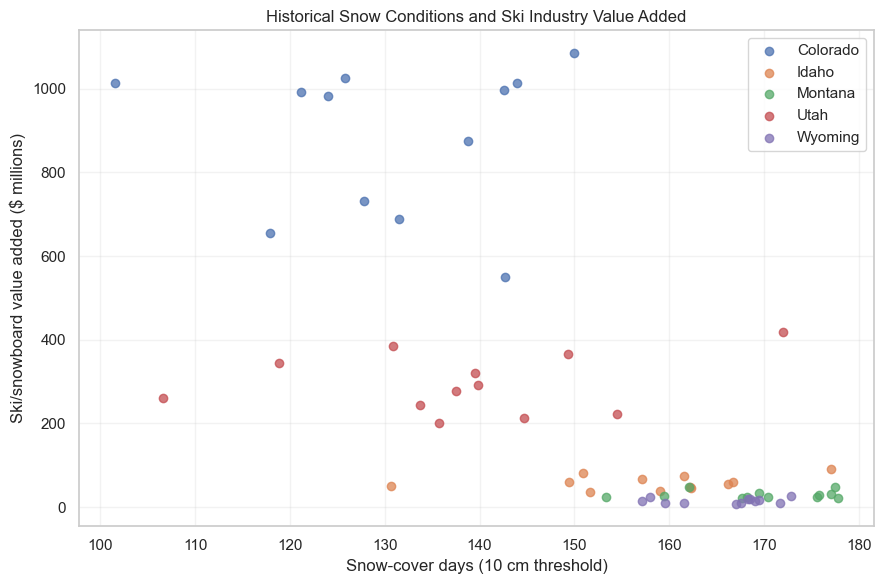

In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the existing state-level ORSA panel
historical = orsa.copy()

# Keep valid observations
historical = historical.dropna(
    subset=[
        "ski_snowboard_va",
        "snow_days_10cm"
    ]
)

historical = historical.loc[
    (historical["ski_snowboard_va"] > 0)
    & (historical["snow_days_10cm"] > 0)
].copy()

# Log variables
historical["log_ski_va"] = np.log(
    historical["ski_snowboard_va"]
)

historical["log_snow_days"] = np.log(
    historical["snow_days_10cm"]
)

# Examine within-state correlations
print("SNOW DURATION AND SKI VALUE ADDED")
print("=" * 65)

print(
    historical.groupby("state")
    .apply(
        lambda x: x["log_snow_days"].corr(
            x["log_ski_va"]
        ),
        include_groups=False
    )
    .round(3)
)

# Plot historical relationship by state
fig, ax = plt.subplots(figsize=(9, 6))

for state, group in historical.groupby("state"):
    ax.scatter(
        group["snow_days_10cm"],
        group["ski_snowboard_va"] / 1000,
        label=state,
        alpha=0.75
    )

ax.set_xlabel("Snow-cover days (10 cm threshold)")
ax.set_ylabel("Ski/snowboard value added ($ millions)")
ax.set_title("Historical Snow Conditions and Ski Industry Value Added")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [157]:
import statsmodels.formula.api as smf
import numpy as np

historical = orsa.copy()

historical = historical.dropna(
    subset=["state", "year",
            "ski_snowboard_va", "snow_days_10cm"]
)

historical = historical.loc[
    (historical["ski_snowboard_va"] > 0)
    & (historical["snow_days_10cm"] > 0)
].copy()

historical["log_ski_va"] = np.log(
    historical["ski_snowboard_va"]
)

historical["log_snow_days"] = np.log(
    historical["snow_days_10cm"]
)

# Model 1: State fixed effects
model_state = smf.ols(
    "log_ski_va ~ log_snow_days + C(state)",
    data=historical
).fit(cov_type="HC3")

# Model 2: State and year fixed effects
model_twfe = smf.ols(
    "log_ski_va ~ log_snow_days + C(state) + C(year)",
    data=historical
).fit(cov_type="HC3")

print("HISTORICAL SNOW–ECONOMY REGRESSION")
print("=" * 80)

for name, model in [
    ("State FE", model_state),
    ("State + Year FE", model_twfe)
]:
    print(f"\n{name}")
    print(
        "Snow elasticity:",
        round(model.params["log_snow_days"], 4)
    )
    print(
        "P-value:",
        round(model.pvalues["log_snow_days"], 4)
    )
    print(
        "95% confidence interval:",
        model.conf_int()
        .loc["log_snow_days"]
        .round(4)
        .tolist()
    )
    print(
        "R-squared:",
        round(model.rsquared, 4)
    )

HISTORICAL SNOW–ECONOMY REGRESSION

State FE
Snow elasticity: 0.3733
P-value: 0.4014
95% confidence interval: [-0.4985, 1.2451]
R-squared: 0.9669

State + Year FE
Snow elasticity: -0.3005
P-value: 0.4409
95% confidence interval: [-1.0649, 0.4638]
R-squared: 0.9935


## NSAA Data

In [158]:
import pandas as pd
import numpy as np

nsaa = pd.DataFrame({
    "year": list(range(2004, 2026)),
    "skier_visits_millions": [
        18.868, 19.606, 20.717, 20.849,
        21.324, 19.974, 20.378, 20.900,
        19.130, 19.800, 21.100, 20.768,
        22.287, 21.736, 20.792, 24.408,
        20.107, 22.638, 25.250, 28.174,
        26.757, 26.503
    ]
})

# year = ending year of the ski season
# Example: 2023 means 2022/23

print(nsaa.tail())

    year  skier_visits_millions
17  2021                 22.638
18  2022                 25.250
19  2023                 28.174
20  2024                 26.757
21  2025                 26.503


In [159]:
# Create regional snow-cover proxy
regional_snow = (
    orsa.groupby("year", as_index=False)
    .agg(
        snow_days_10cm=("snow_days_10cm", "mean"),
        snow_days_5cm=("snow_days_5cm", "mean"),
        mean_depth_cm=("mean_depth_cm", "mean")
    )
)

# Merge with NSAA skier visits
regional_panel = nsaa.merge(
    regional_snow,
    on="year",
    how="inner",
    validate="one_to_one"
)

print("MATCHED SNOW AND SKIER VISIT DATA")
print("=" * 75)
print(regional_panel.to_string(index=False))
print("\nObservations:", len(regional_panel))

MATCHED SNOW AND SKIER VISIT DATA
 year  skier_visits_millions  snow_days_10cm  snow_days_5cm  mean_depth_cm
 2012                 19.130      148.554754     156.101382      77.675099
 2013                 19.800      152.189120     157.763014      83.373727
 2014                 21.100      156.416340     161.515032      99.365190
 2015                 20.768      134.833206     142.857554      62.300709
 2016                 22.287      157.147961     162.538065      78.459492
 2017                 21.736      145.364187     150.843183      96.782561
 2018                 20.792      144.580066     151.771019      79.492216
 2019                 24.408      159.830298     164.783639      81.566082
 2020                 20.107      161.254702     166.195721      79.245114
 2021                 22.638      154.711345     161.382373      64.002878
 2022                 25.250      145.548176     153.131472      59.379368
 2023                 28.174      169.896624     172.802927      9

In [160]:
import statsmodels.formula.api as smf

reg = regional_panel.copy()

reg = reg.loc[
    (reg["snow_days_10cm"] > 0)
    & (reg["skier_visits_millions"] > 0)
].copy()

reg["log_visits"] = np.log(
    reg["skier_visits_millions"]
)

reg["log_snow"] = np.log(
    reg["snow_days_10cm"]
)

reg["time_trend"] = reg["year"] - reg["year"].min()

# Without time trend
m1 = smf.ols(
    "log_visits ~ log_snow",
    data=reg
).fit(cov_type="HC3")

# With time trend
m2 = smf.ols(
    "log_visits ~ log_snow + time_trend",
    data=reg
).fit(cov_type="HC3")

print("NSAA SKIER VISITS VS SNOW DURATION")
print("=" * 75)

for name, model in [
    ("Snow only", m1),
    ("Snow + trend", m2)
]:
    print(f"\n{name}")
    print("Elasticity:", round(model.params["log_snow"], 4))
    print("P-value:", round(model.pvalues["log_snow"], 4))
    print(
        "95% CI:",
        model.conf_int()
        .loc["log_snow"]
        .round(4)
        .tolist()
    )
    print("R²:", round(model.rsquared, 4))

NSAA SKIER VISITS VS SNOW DURATION

Snow only
Elasticity: 0.8237
P-value: 0.2759
95% CI: [-0.6578, 2.3051]
R²: 0.2044

Snow + trend
Elasticity: 0.3045
P-value: 0.5319
95% CI: [-0.6503, 1.2594]
R²: 0.6408


In [161]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# Create regional snow series using all available county-years
regional_snow_full = (
    model_df
    .groupby("year", as_index=False)
    .agg(
        snow_days_10cm=(
            "snow_days_10cm_2000m", "mean"
        ),
        snow_days_5cm=(
            "snow_days_5cm_2000m", "mean"
        ),
        mean_depth_cm=(
            "mean_depth_cm_2000m", "mean"
        )
    )
)

# Match NSAA visits to the full snow series
regional_full = nsaa.merge(
    regional_snow_full,
    on="year",
    how="inner",
    validate="one_to_one"
)

regional_full = regional_full.dropna(
    subset=["snow_days_10cm", "skier_visits_millions"]
)

regional_full = regional_full.loc[
    (regional_full["snow_days_10cm"] > 0)
    & (regional_full["skier_visits_millions"] > 0)
].copy()

regional_full["log_visits"] = np.log(
    regional_full["skier_visits_millions"]
)

regional_full["log_snow"] = np.log(
    regional_full["snow_days_10cm"]
)

regional_full["time_trend"] = (
    regional_full["year"]
    - regional_full["year"].min()
)

# COVID-disrupted seasons (ending years)
regional_full["covid"] = (
    regional_full["year"].isin([2020, 2021])
).astype(int)

models = {
    "Snow only": "log_visits ~ log_snow",
    "Snow + trend": "log_visits ~ log_snow + time_trend",
    "Snow + trend + COVID": (
        "log_visits ~ log_snow + time_trend + covid"
    )
}

print("EXTENDED NSAA–SNODAS REGRESSIONS")
print("=" * 85)

for name, formula in models.items():

    fitted = smf.ols(
        formula,
        data=regional_full
    ).fit(cov_type="HC3")

    print(f"\n{name}")
    print("N:", int(fitted.nobs))
    print(
        "Snow elasticity:",
        round(fitted.params["log_snow"], 4)
    )
    print(
        "P-value:",
        round(fitted.pvalues["log_snow"], 4)
    )
    print(
        "95% CI:",
        fitted.conf_int()
        .loc["log_snow"]
        .round(4)
        .tolist()
    )
    print("R²:", round(fitted.rsquared, 4))

# Additional robustness check:
# Exclude COVID-disrupted seasons entirely
noncovid = regional_full.loc[
    ~regional_full["year"].isin([2020, 2021])
].copy()

fitted_noncovid = smf.ols(
    "log_visits ~ log_snow + time_trend",
    data=noncovid
).fit(cov_type="HC3")

print("\nSnow + trend, excluding COVID seasons")
print("N:", int(fitted_noncovid.nobs))
print(
    "Snow elasticity:",
    round(fitted_noncovid.params["log_snow"], 4)
)
print(
    "P-value:",
    round(fitted_noncovid.pvalues["log_snow"], 4)
)
print(
    "95% CI:",
    fitted_noncovid.conf_int()
    .loc["log_snow"]
    .round(4)
    .tolist()
)

EXTENDED NSAA–SNODAS REGRESSIONS

Snow only
N: 20
Snow elasticity: 0.6824
P-value: 0.0792
95% CI: [-0.0795, 1.4442]
R²: 0.2736

Snow + trend
N: 20
Snow elasticity: 0.3337
P-value: 0.2475
95% CI: [-0.2318, 0.8993]
R²: 0.5604

Snow + trend + COVID
N: 20
Snow elasticity: 0.3816
P-value: 0.1452
95% CI: [-0.1318, 0.895]
R²: 0.6757

Snow + trend, excluding COVID seasons
N: 18
Snow elasticity: 0.4402
P-value: 0.0734
95% CI: [-0.0417, 0.9222]


In [162]:
import numpy as np
import pandas as pd

# Provisional NSAA elasticity:
# Snow + trend + COVID specification
nsaa_elasticity = 0.3816

# Start from existing county-level snow scenarios
nsaa_econ = county_scenarios.copy()

# Ensure state identifiers are consistent
state_map = {
    8: "Colorado",
    16: "Idaho",
    30: "Montana",
    49: "Utah",
    56: "Wyoming"
}

nsaa_econ["state"] = (
    pd.to_numeric(
        nsaa_econ["state"],
        errors="coerce"
    ).map(state_map)
)

# Keep valid baseline observations
nsaa_econ = nsaa_econ.loc[
    nsaa_econ["Baseline snow days"] > 0
].copy()

# Calculate snow-duration ratios
nsaa_econ["snow_ratio"] = (
    nsaa_econ["Scenario snow days"]
    / nsaa_econ["Baseline snow days"]
)

# Apply empirically estimated elasticity
nsaa_econ["demand_change_pct"] = (
    nsaa_econ["snow_ratio"].clip(lower=0)
    ** nsaa_elasticity - 1
) * 100

# Average demand changes by state/model/scenario
state_nsaa = (
    nsaa_econ.groupby(
        ["state", "Model", "Scenario"],
        as_index=False
    )
    .agg(
        demand_change_pct=(
            "demand_change_pct", "mean"
        )
    )
)

# Add state-level BEA economic baseline
state_nsaa = state_nsaa.merge(
    orsa_2023[
        ["state", "baseline_va_millions"]
    ],
    on="state",
    how="left",
    validate="many_to_one"
)

assert state_nsaa["baseline_va_millions"].notna().all()

# Estimate economic changes
state_nsaa["va_change_millions"] = (
    state_nsaa["baseline_va_millions"]
    * state_nsaa["demand_change_pct"] / 100
)

# Aggregate five-state economic impacts
nsaa_total = (
    state_nsaa.groupby(
        ["Model", "Scenario"],
        as_index=False
    )
    .agg(
        va_change_millions=(
            "va_change_millions", "sum"
        )
    )
)

print("NSAA-CALIBRATED ECONOMIC SCENARIOS")
print("=" * 80)

print(
    nsaa_total.loc[
        nsaa_total["Scenario"] != "Baseline"
    ]
    .round(2)
    .to_string(index=False)
)

NSAA-CALIBRATED ECONOMIC SCENARIOS
        Model Scenario  va_change_millions
Fixed Effects PDD +100              -82.06
Fixed Effects  PDD +25              -19.83
Fixed Effects  PDD +50              -40.11
Random Forest PDD +100              -40.85
Random Forest  PDD +25              -10.63
Random Forest  PDD +50              -21.96
      XGBoost PDD +100              -42.75
      XGBoost  PDD +25              -10.29
      XGBoost  PDD +50              -22.12


In [163]:
import pandas as pd
import numpy as np

elasticity_cases = {
    "Zero response": 0.0,
    "NSAA central": 0.3816,
    "NSAA upper 95%": 0.8950
}

results = []

for label, elasticity in elasticity_cases.items():

    temp = county_scenarios.copy()

    state_map = {
        8: "Colorado",
        16: "Idaho",
        30: "Montana",
        49: "Utah",
        56: "Wyoming"
    }

    temp["state"] = (
        pd.to_numeric(temp["state"], errors="coerce")
        .map(state_map)
    )

    temp = temp.loc[
        temp["Baseline snow days"] > 0
    ].copy()

    snow_ratio = (
        temp["Scenario snow days"]
        / temp["Baseline snow days"]
    ).clip(lower=0)

    temp["demand_change_pct"] = (
        snow_ratio ** elasticity - 1
    ) * 100

    state_results = (
        temp.groupby(
            ["state", "Model", "Scenario"],
            as_index=False
        )["demand_change_pct"]
        .mean()
    )

    state_results = state_results.merge(
        orsa_2023[
            ["state", "baseline_va_millions"]
        ],
        on="state",
        how="left",
        validate="many_to_one"
    )

    state_results["va_change_millions"] = (
        state_results["baseline_va_millions"]
        * state_results["demand_change_pct"] / 100
    )

    totals = (
        state_results.groupby(
            ["Model", "Scenario"],
            as_index=False
        )["va_change_millions"]
        .sum()
    )

    totals["Elasticity case"] = label
    results.append(totals)

elasticity_uncertainty = pd.concat(
    results, ignore_index=True
)

print("NSAA ELASTICITY SENSITIVITY")
print("=" * 85)

print(
    elasticity_uncertainty.loc[
        elasticity_uncertainty["Scenario"] == "PDD +100"
    ]
    .round(2)
    .to_string(index=False)
)

NSAA ELASTICITY SENSITIVITY
        Model Scenario  va_change_millions Elasticity case
Fixed Effects PDD +100                0.00   Zero response
Random Forest PDD +100                0.00   Zero response
      XGBoost PDD +100                0.00   Zero response
Fixed Effects PDD +100              -82.06    NSAA central
Random Forest PDD +100              -40.85    NSAA central
      XGBoost PDD +100              -42.75    NSAA central
Fixed Effects PDD +100             -185.58  NSAA upper 95%
Random Forest PDD +100              -93.69  NSAA upper 95%
      XGBoost PDD +100              -97.76  NSAA upper 95%


In [166]:
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

print("Folder exists:", root.exists())

keywords = [
    "season_days",
    "snow_days_10cm",
    "season_start",
    "season_end",
    "water_year",
    "datetime",
    "date_range"
]

matches = []

for path in root.rglob("*"):
    if path.suffix not in [".py", ".ipynb"]:
        continue

    try:
        content = path.read_text(errors="ignore")
    except Exception:
        continue

    found = [k for k in keywords if k in content]

    if found:
        matches.append((path, found))

print("\nMatching files:", len(matches))

for path, found in matches[:30]:
    print(f"\n{path.relative_to(root)}")
    print("Keywords:", ", ".join(found))

Folder exists: True

Matching files: 1050

code/Claude_FDOS.ipynb
Keywords: water_year, datetime

code/gdp_snow.ipynb
Keywords: water_year, datetime

code/FDOS_annotated.ipynb
Keywords: water_year, datetime

code/snow_model.ipynb
Keywords: season_days, snow_days_10cm, season_start, season_end, water_year, datetime, date_range

venv/lib/python3.12/site-packages/pyproj/sync.py
Keywords: datetime

venv/lib/python3.12/site-packages/packaging/pylock.py
Keywords: datetime

venv/lib/python3.12/site-packages/jupyter_core/migrate.py
Keywords: datetime

venv/lib/python3.12/site-packages/pure_eval/utils.py
Keywords: datetime

venv/lib/python3.12/site-packages/pyparsing/core.py
Keywords: datetime

venv/lib/python3.12/site-packages/pyparsing/common.py
Keywords: datetime

venv/lib/python3.12/site-packages/geopandas/geodataframe.py
Keywords: datetime

venv/lib/python3.12/site-packages/geopandas/explore.py
Keywords: datetime

venv/lib/python3.12/site-packages/jupyter_client/jsonutil.py
Keywords: datet

In [167]:
import json
from pathlib import Path

notebook_path = (
    Path.home()
    / "Files/thesis/snow_ml/code/snow_model.ipynb"
)

with open(notebook_path, "r") as f:
    nb = json.load(f)

keywords = [
    "season_start",
    "season_end",
    "water_year",
    "date_range"
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(k in source for k in keywords):
        print(f"\n{'=' * 70}")
        print(f"CELL {i}")
        print("=" * 70)
        print(source[:3000])


CELL 158
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

print("Folder exists:", root.exists())

keywords = [
    "season_days",
    "snow_days_10cm",
    "season_start",
    "season_end",
    "water_year",
    "datetime",
    "date_range"
]

matches = []

for path in root.rglob("*"):
    if path.suffix not in [".py", ".ipynb"]:
        continue

    try:
        content = path.read_text(errors="ignore")
    except Exception:
        continue

    found = [k for k in keywords if k in content]

    if found:
        matches.append((path, found))

print("\nMatching files:", len(matches))

for path, found in matches[:30]:
    print(f"\n{path.relative_to(root)}")
    print("Keywords:", ", ".join(found))

CELL 159
import json
from pathlib import Path

notebook_path = (
    Path.home()
    / "Files/thesis/snow_ml/code/snow_model.ipynb"
)

with open(notebook_path, "r") as f:
    nb = json.load(f)

keywords = [
    "season_start",
    "season_end",
    "water_year",
   

In [168]:
import json
from pathlib import Path

notebook_path = (
    Path.home()
    / "Files/thesis/snow_ml/code/snow_model.ipynb"
)

with open(notebook_path, "r") as f:
    nb = json.load(f)

keywords = [
    "read_csv",
    "read_parquet",
    "read_excel",
    "model_df =",
    "county_snodas",
    "snodas_panel",
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(k in source.lower() for k in keywords):
        print(f"\n{'=' * 70}")
        print(f"CELL {i}")
        print("=" * 70)
        print(source[:2000])


CELL 2
import pandas as pd

panel = pd.read_csv(
    "/Users/evabenson/Files/thesis/snow_ml/code/snow_county_panel.csv",
    dtype={"fips": str}
)

print(panel.shape)
display(panel.head())

CELL 5
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/Users/evabenson/Files/thesis/snow_ml/ml_model")

snow = pd.read_csv(
    DATA_DIR / "county_snow_panel.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    DATA_DIR / "county_climate_panel_v2.csv",
    dtype={"fips": str}
)

terrain = pd.read_csv(
    DATA_DIR / "county_terrain.csv",
    dtype={"fips": str}
)

print("Snow:", snow.shape)
print("Climate:", climate.shape)
print("Terrain:", terrain.shape)

CELL 13
# Keep observations with valid snow-cover measurements
model_df = panel.dropna(
    subset=["snow_days_2000m"]
).copy()

# Define target variable
TARGET = "snow_days_2000m"

# Define climate predictors
CLIMATE_FEATURES = [
    "tmin_djf",
    "tmin_apr",
    "precip_on",
    "precip_djf"
]

# Define terrain predicto

In [169]:
from pathlib import Path
import pandas as pd

path = (
    Path.home()
    / "Files/thesis/snow_ml/ml_model/county_snodas_panel_v1.csv"
)

snow_check = pd.read_csv(path)

print("COLUMNS:")
print(snow_check.columns.tolist())

print("\n2023 OBSERVATIONS:")
print(
    snow_check.loc[
        snow_check["year"] == 2023
    ].head(5).to_string(index=False)
)

print("\nSEASON LENGTH:")
print(
    snow_check.groupby("year")["season_days"]
    .first()
    .to_string()
)

COLUMNS:
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m']

2023 OBSERVATIONS:
 fips  state     county   year  season_days  valid_days_all  snow_days_0cm_all  snow_days_5cm_all  snow_days_10cm_all  mean_depth_cm_all  peak_depth_cm_all  valid_fraction_all  valid_days_2000m  snow_days_0cm_2000m  snow_days_5cm_2000m  snow_days_10cm_2000m  mean_depth_cm_2000m  peak_depth_cm_2000m  valid_fraction_2000m
 8107      8      Routt 2023.0        181.0      181.000000         178.522096         174.410298          168.124744          87.918559         154.296937            1.000000        181.000000           178.689725           174.719263            168.737304            88.918701           155

In [170]:
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

terms = [
    "county_snodas_panel_v1.csv",
    "season_start",
    "season_end",
    "november",
    "april"
]

for path in root.rglob("*"):
    if not path.is_file():
        continue

    if any(part in ["venv", ".venv", ".git"] for part in path.parts):
        continue

    if path.suffix not in [".py", ".ipynb"]:
        continue

    try:
        content = path.read_text(errors="ignore")
    except Exception:
        continue

    found = [term for term in terms if term.lower() in content.lower()]

    if found:
        print(path.relative_to(root))
        print("Matches:", ", ".join(found))
        print()

code/gdp_snow.ipynb
Matches: april

code/FDOS_annotated.ipynb
Matches: april

code/snow_model.ipynb
Matches: county_snodas_panel_v1.csv, season_start, season_end, november, april



In [171]:
import json
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

notebooks = [
    root / "code/snow_model.ipynb",
    root / "code/gdp_snow.ipynb",
    root / "code/FDOS_annotated.ipynb"
]

terms = [
    "season_start",
    "season_end",
    "water_year",
    "11, 1",
    "4, 30",
    "11-01",
    "04-30",
    "november",
    "april"
]

for path in notebooks:
    with open(path, encoding="utf-8") as f:
        nb = json.load(f)

    print(f"\n{'=' * 70}")
    print(path.name)
    print("=" * 70)

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        # Skip our recent diagnostic cells
        if "keywords = [" in source or "terms = [" in source:
            continue

        matching_lines = [
            (j, line)
            for j, line in enumerate(source.splitlines())
            if any(t in line.lower() for t in terms)
        ]

        if matching_lines:
            print(f"\nCELL {i}")
            for line_number, line in matching_lines[:12]:
                print(f"  Line {line_number + 1}: {line[:180]}")


snow_model.ipynb

CELL 20
  Line 23: axes[1].set_title("April Temperature vs. Snow Anomalies")
  Line 24: axes[1].set_xlabel("April minimum temperature anomaly")

CELL 101
  Line 2: end = f"{year}-04-30"

gdp_snow.ipynb

CELL 2
  Line 179: def get_water_year(d):

CELL 19
  Line 3: def get_water_year(d):
  Line 30:     wy      = get_water_year(d)
  Line 39:             'water_year': wy,

CELL 20
  Line 7: snow_by_wy['water_year'] = snow_by_wy['year'] - 1
  Line 10:     snow_by_wy[['state','water_year','mean_snow_days']],
  Line 11:     on=['state','water_year'],
  Line 34: wy = depth_model_df.loc[feature_df.index, 'water_year']

CELL 21
  Line 2: annual_depth = depth_panel.groupby(['state','water_year'])['depth_cm'].mean().reset_index()

CELL 22
  Line 8:     d_start = date(start_year, 11, 1)

CELL 23
  Line 12:     wy      = get_water_year(d)
  Line 20:             'water_year': wy,
  Line 32:     ['state','water_year'])['depth_cm'].mean().reset_index()

CELL 81
  Line 17:   tmin_apr 

In [172]:
import json
from pathlib import Path

path = Path.home() / "Files/thesis/snow_ml/code/snow_model.ipynb"

with open(path, encoding="utf-8") as f:
    nb = json.load(f)

print("CELL 101 — SNODAS DATE DEFINITION")
print("=" * 70)
print("".join(nb["cells"][101]["source"]))

CELL 101 — SNODAS DATE DEFINITION
start = f"{year-1}-10-01"
end = f"{year}-04-30"


In [173]:
import json
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

# Search project notebooks and scripts, excluding virtual environments
terms = [
    "season_days =",
    '"season_days":',
    "'season_days':",
    "season_days.append",
    "county_snodas_panel_v1.csv"
]

for path in root.rglob("*"):
    if not path.is_file():
        continue

    if any(p in {"venv", ".venv", ".git"} for p in path.parts):
        continue

    if path.suffix not in {".py", ".ipynb"}:
        continue

    try:
        if path.suffix == ".ipynb":
            with open(path, encoding="utf-8") as f:
                notebook = json.load(f)

            sources = [
                (i, "".join(cell.get("source", [])))
                for i, cell in enumerate(notebook["cells"])
                if cell["cell_type"] == "code"
            ]
        else:
            sources = [(None, path.read_text(errors="ignore"))]

        for cell_num, source in sources:
            lines = source.splitlines()

            for i, line in enumerate(lines):
                if any(term in line for term in terms):
                    # Skip diagnostic/search code
                    if "terms =" in source or "keywords =" in source:
                        continue

                    print("\n" + "=" * 65)
                    print("FILE:", path.relative_to(root))
                    if cell_num is not None:
                        print("CELL:", cell_num)

                    print("\n".join(
                        lines[max(0, i-5):min(len(lines), i+6)]
                    ))

    except Exception as e:
        print("Error:", path, e)


FILE: code/snow_model.ipynb
CELL: 129
root = Path.home() / "Files/thesis/snow_ml"

files = [
    "code/ski_snow_states/snodas_depth_panel.csv",
    "code/ski_snow_states/snodas_local_depth_panel.csv",
    "ml_model/county_snodas_panel_v1.csv",
    "ml_model/county_snow_panel.csv",
    "ml_model/county_snow_validation_v3.csv"
]

for filename in files:

FILE: code/snow_model.ipynb
CELL: 130
import pandas as pd

root = Path.home() / "Files/thesis/snow_ml"

snow = pd.read_csv(
    root / "ml_model/county_snodas_panel_v1.csv",
    dtype={"fips": str}
)

snow["fips"] = snow["fips"].str.zfill(5)


FILE: code/snow_model.ipynb
CELL: 131
from scipy.stats import linregress

root = Path.home() / "Files/thesis/snow_ml"

snow = pd.read_csv(
    root / "ml_model/county_snodas_panel_v1.csv",
    dtype={"fips": str}
)

snow["fips"] = snow["fips"].str.zfill(5)
snow["year"] = pd.to_numeric(snow["year"])

FILE: code/snow_model.ipynb
CELL: 132
from scipy.stats import linregress

root = Path.home() / "File

In [174]:
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

for folder in [root / "ml_model", root / "code"]:
    print(f"\n{'=' * 65}")
    print("FOLDER:", folder)
    print("=" * 65)

    if not folder.exists():
        continue

    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue

        if any(p in {"venv", ".venv", ".git", "__pycache__"}
               for p in path.parts):
            continue

        if path.suffix.lower() not in {
            ".py", ".r", ".ipynb", ".sh"
        }:
            continue

        name = path.name.lower()

        if any(term in name for term in [
            "snodas", "snow", "county", "panel", "extract"
        ]):
            print(path.relative_to(root))


FOLDER: /Users/evabenson/Files/thesis/snow_ml/ml_model

FOLDER: /Users/evabenson/Files/thesis/snow_ml/code
code/gdp_snow.ipynb
code/snow_model.ipynb


In [175]:
print("FIXED EFFECTS MODEL")
print("=" * 60)
print(fe_model)

print("\nRANDOM FOREST FEATURES")
print("=" * 60)
print(final_rf.feature_names_in_
      if hasattr(final_rf, "feature_names_in_")
      else "Feature names not stored in model")

print("\nXGBOOST FEATURES")
print("=" * 60)
print(xgb.feature_names_in_
      if hasattr(xgb, "feature_names_in_")
      else "Feature names not stored in model")

print("\nAVAILABLE TEMPERATURE VARIABLES")
print("=" * 60)

temp_cols = [
    c for c in model_df.columns
    if any(term in c.lower() for term in [
        "temp", "tmin", "tmax", "degree", "freeze", "thaw"
    ])
]

print(temp_cols)

FIXED EFFECTS MODEL
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('county',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['fips']),
                                                 ('climate', 'passthrough',
                                                  ['positive_degree_days_2000m',
                                                   'precip_djf_2000m',
                                                   'precip_mar_apr_2000m'])])),
                ('regression', LinearRegression())])

RANDOM FOREST FEATURES
['tmin_djf_2000m' 'tmax_djf_2000m' 'tmin_mar_2000m' 'tmax_mar_2000m'
 'tmin_apr_2000m' 'tmax_apr_2000m' 'precip_djf_2000m'
 'precip_mar_apr_2000m' 'positive_degree_days_2000m'
 'freezing_degree_days_2000m' 'thaw_days_2000m' 'mean_elev_m'
 'mean_slope_deg' 'mean_northness' 'mean_eastness' 'frac_above_2000m'
 'frac_above_2500m' 'frac_above_3000m']

XG

In [176]:
import json
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

terms = [
    "positive_degree_days",
    "freezing_degree_days",
    "thaw_days"
]

for path in root.rglob("*"):

    if not path.is_file():
        continue

    if any(p in {"venv", ".venv", ".git"}
           for p in path.parts):
        continue

    if path.suffix not in {".py", ".ipynb"}:
        continue

    if path.suffix == ".ipynb":
        with open(path, encoding="utf-8") as f:
            nb = json.load(f)

        sources = [
            (i, "".join(cell.get("source", [])))
            for i, cell in enumerate(nb["cells"])
            if cell["cell_type"] == "code"
        ]
    else:
        sources = [(None, path.read_text(errors="ignore"))]

    for cell_num, source in sources:

        lines = source.splitlines()

        for i, line in enumerate(lines):

            # Find assignments/calculations, not just column references
            if not any(term in line for term in terms):
                continue

            if not any(op in line for op in [
                "=", "np.maximum", "np.minimum", "clip"
            ]):
                continue

            # Ignore recent diagnostic cells
            if "terms = [" in source:
                continue

            print("\n" + "=" * 65)
            print("FILE:", path.relative_to(root))
            print("CELL:", cell_num)
            print("\n".join(
                lines[max(0, i-3):min(len(lines), i+5)]
            ))


FILE: code/snow_model.ipynb
CELL: 55
].transform(lambda x: x.quantile(0.75))

model_df["warm_winter"] = (
    model_df["positive_degree_days_2000m"] >= pdd_threshold
)

print(model_df["warm_winter"].value_counts())

FILE: code/snow_model.ipynb
CELL: 137

    scenario_data = df[features].copy()

    scenario_data["positive_degree_days_2000m"] += increase

    scenario_predictions = fe_model.predict(scenario_data)

    results.append({

FILE: code/snow_model.ipynb
CELL: 140

        scenario_inputs = baseline_inputs.copy()

        scenario_inputs["positive_degree_days_2000m"] += pdd_increase

        scenario_predictions = model.predict(scenario_inputs)

        # Snow duration is physically bounded by the season length


In [177]:
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

extensions = {".csv", ".parquet", ".nc", ".nc4", ".zarr"}

climate_files = []

for path in root.rglob("*"):
    if any(p in {"venv", ".venv", ".git"} for p in path.parts):
        continue

    if path.is_file() and path.suffix.lower() in extensions:
        if any(term in path.name.lower() for term in [
            "climate", "temp", "daily", "daymet", "gridmet",
            "era5", "prism", "degree", "weather"
        ]):
            climate_files.append(path)

print("POTENTIAL CLIMATE DATA FILES")
print("=" * 70)

for path in sorted(climate_files):
    print(path.relative_to(root))

print("\nTotal:", len(climate_files))

POTENTIAL CLIMATE DATA FILES
climate_panel.csv
ml_model/county_climate_maca_projections.csv
ml_model/county_climate_panel.csv
ml_model/county_climate_panel_v2.csv
ml_model/county_climate_panel_v3.csv
ml_model/county_snodas_climate_terrain_merged.csv

Total: 6


In [178]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml/ml_model"

files = [
    "county_climate_maca_projections.csv",
    "county_climate_panel_v3.csv"
]

for filename in files:
    path = root / filename

    print("\n" + "=" * 75)
    print("FILE:", filename)
    print("=" * 75)

    df_check = pd.read_csv(path, nrows=5)

    print("\nCOLUMNS:")
    print(df_check.columns.tolist())

    print("\nFIRST 3 ROWS:")
    print(df_check.head(3).to_string(index=False))

    print("\nFILE SIZE:")
    print(round(path.stat().st_size / 1e6, 2), "MB")


FILE: county_climate_maca_projections.csv

COLUMNS:
['fips', 'state', 'county', 'scenario', 'period', 'year_start', 'year_end', 'tmin_djf', 'tmin_apr', 'precip_on', 'precip_djf']

FIRST 3 ROWS:
 fips    state county scenario     period  year_start  year_end   tmin_djf  tmin_apr  precip_on  precip_djf
 8037 Colorado  Eagle    rcp45 historical        1981      2005 -12.945585 -4.722761  97.500728  145.096773
 8117 Colorado Summit    rcp45 historical        1981      2005 -14.800509 -7.393393 106.818871  170.594387
 8097 Colorado Pitkin    rcp45 historical        1981      2005 -13.493505 -6.090952 139.166151  219.996987

FILE SIZE:
0.02 MB

FILE: county_climate_panel_v3.csv

COLUMNS:
['fips', 'state', 'county', 'year', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_

In [179]:
import pandas as pd
from pathlib import Path

path = (
    Path.home()
    / "Files/thesis/snow_ml/ml_model/"
    "county_climate_maca_projections.csv"
)

maca = pd.read_csv(path, dtype={"fips": str})
maca["fips"] = maca["fips"].str.zfill(5)

print("MACA DATASET")
print("=" * 70)
print("Rows:", len(maca))
print("Counties:", maca["fips"].nunique())

print("\nSCENARIOS AND PERIODS")
print(
    maca[
        ["scenario", "period", "year_start", "year_end"]
    ]
    .drop_duplicates()
    .sort_values(["scenario", "year_start"])
    .to_string(index=False)
)

print("\nCOUNTIES PER SCENARIO AND PERIOD")
print(
    maca.groupby(["scenario", "period"])["fips"]
    .nunique()
    .to_string()
)

print("\nMISSING VALUES")
print(maca.isna().sum().to_string())

print("\nHISTORICAL BASELINE EXAMPLE")
print(
    maca[maca["period"] == "historical"]
    .head(3)
    .to_string(index=False)
)

MACA DATASET
Rows: 132
Counties: 22

SCENARIOS AND PERIODS
scenario      period  year_start  year_end
   rcp45  historical        1981      2005
   rcp45 mid_century        2040      2059
   rcp45 end_century        2080      2099
   rcp85  historical        1981      2005
   rcp85 mid_century        2040      2059
   rcp85 end_century        2080      2099

COUNTIES PER SCENARIO AND PERIOD
scenario  period     
rcp45     end_century    22
          historical     22
          mid_century    22
rcp85     end_century    22
          historical     22
          mid_century    22

MISSING VALUES
fips          0
state         0
county        0
scenario      0
period        0
year_start    0
year_end      0
tmin_djf      0
tmin_apr      0
precip_on     0
precip_djf    0

HISTORICAL BASELINE EXAMPLE
 fips    state county scenario     period  year_start  year_end   tmin_djf  tmin_apr  precip_on  precip_djf
08037 Colorado  Eagle    rcp45 historical        1981      2005 -12.945585 -4.722761  9

In [180]:
import pandas as pd

# Keep only counties included in the trained snow models
model_counties = set(
    model_df["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

maca_model = maca[
    maca["fips"].isin(model_counties)
].copy()

climate_vars = [
    "tmin_djf",
    "tmin_apr",
    "precip_on",
    "precip_djf"
]

# Historical baseline for each county and RCP
historical = maca_model[
    maca_model["period"] == "historical"
][["fips", "scenario"] + climate_vars].copy()

historical = historical.rename(
    columns={v: f"{v}_historical" for v in climate_vars}
)

# Future climate periods
future = maca_model[
    maca_model["period"] != "historical"
].copy()

future = future.merge(
    historical,
    on=["fips", "scenario"],
    how="left",
    validate="many_to_one"
)

# Temperature changes in degrees Celsius
for var in ["tmin_djf", "tmin_apr"]:
    future[f"delta_{var}"] = (
        future[var] - future[f"{var}_historical"]
    )

# Precipitation changes in percent
for var in ["precip_on", "precip_djf"]:
    future[f"pct_change_{var}"] = (
        100 * (
            future[var] / future[f"{var}_historical"] - 1
        )
    )

summary = (
    future.groupby(["scenario", "period"])
    .agg(
        counties=("fips", "nunique"),
        winter_warming_C=("delta_tmin_djf", "mean"),
        april_warming_C=("delta_tmin_apr", "mean"),
        oct_nov_precip_pct=("pct_change_precip_on", "mean"),
        winter_precip_pct=("pct_change_precip_djf", "mean")
    )
    .reset_index()
)

print("MACA CLIMATE CHANGES — 20 SNOW-MODEL COUNTIES")
print("=" * 85)
print(summary.round(2).to_string(index=False))

MACA CLIMATE CHANGES — 20 SNOW-MODEL COUNTIES
scenario      period  counties  winter_warming_C  april_warming_C  oct_nov_precip_pct  winter_precip_pct
   rcp45 end_century        20              3.43             3.00                2.79              10.41
   rcp45 mid_century        20              2.50             2.27                3.28               5.24
   rcp85 end_century        20              6.09             4.92                4.03              21.85
   rcp85 mid_century        20              3.13             2.83                5.52               9.91


In [181]:
import pandas as pd
import numpy as np

variables = [
    "tmin_djf_2000m",
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmin_apr_2000m",
    "tmax_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m"
]

climate_hist = model_df[
    ["fips", "year"] + variables
].dropna().copy()

print("HISTORICAL CLIMATE DATA")
print("=" * 70)
print("Observations:", len(climate_hist))
print("Counties:", climate_hist["fips"].nunique())
print("Years:", climate_hist["year"].min(),
      "-", climate_hist["year"].max())

print("\nTEMPERATURE AND DEGREE-DAY CORRELATIONS")
print("=" * 70)

corr = climate_hist[variables].corr()

print(
    corr.loc[
        [
            "positive_degree_days_2000m",
            "freezing_degree_days_2000m",
            "thaw_days_2000m"
        ],
        [
            "tmin_djf_2000m",
            "tmax_djf_2000m",
            "tmin_mar_2000m",
            "tmax_mar_2000m",
            "tmin_apr_2000m",
            "tmax_apr_2000m"
        ]
    ].round(3).to_string()
)

print("\nHISTORICAL PREDICTOR RANGES")
print("=" * 70)

print(
    climate_hist[variables]
    .agg(["min", "mean", "max"])
    .round(2)
    .to_string()
)

HISTORICAL CLIMATE DATA
Observations: 400
Counties: 20
Years: 2004 - 2023

TEMPERATURE AND DEGREE-DAY CORRELATIONS
                            tmin_djf_2000m  tmax_djf_2000m  tmin_mar_2000m  tmax_mar_2000m  tmin_apr_2000m  tmax_apr_2000m
positive_degree_days_2000m           0.659           0.829           0.762           0.821           0.738           0.750
freezing_degree_days_2000m          -0.839          -0.895          -0.772          -0.694          -0.763          -0.667
thaw_days_2000m                      0.574           0.949           0.598           0.754           0.629           0.753

HISTORICAL PREDICTOR RANGES
      tmin_djf_2000m  tmax_djf_2000m  tmin_mar_2000m  tmax_mar_2000m  tmin_apr_2000m  tmax_apr_2000m  positive_degree_days_2000m  freezing_degree_days_2000m  thaw_days_2000m
min           -16.02           -4.88          -14.33           -0.74           -9.93            2.73                       43.61                      196.56            64.57
mean          -1

In [182]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

# Historical observations
hist = model_df.copy()

hist["fips"] = (
    hist["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Predictors available in MACA
predictors = [
    "fips",
    "tmin_djf_2000m",
    "tmin_apr_2000m"
]

# Variables needed by RF and XGBoost but missing from MACA
targets = [
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmax_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m"
]

hist = hist.dropna(
    subset=predictors + targets
).copy()

train = hist[hist["year"] <= 2018]
test = hist[hist["year"] >= 2019]

results = []

for target in targets:

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "county",
                OneHotEncoder(handle_unknown="ignore"),
                ["fips"]
            ),
            (
                "temperature",
                "passthrough",
                [
                    "tmin_djf_2000m",
                    "tmin_apr_2000m"
                ]
            )
        ]
    )

    auxiliary_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regression", Ridge(alpha=1.0))
    ])

    auxiliary_model.fit(
        train[predictors],
        train[target]
    )

    predictions = auxiliary_model.predict(
        test[predictors]
    )

    results.append({
        "Variable": target,
        "R2": r2_score(test[target], predictions),
        "MAE": mean_absolute_error(
            test[target], predictions
        ),
        "Observed SD": test[target].std()
    })

auxiliary_results = pd.DataFrame(results)

auxiliary_results["MAE / SD"] = (
    auxiliary_results["MAE"]
    / auxiliary_results["Observed SD"]
)

print("AUXILIARY CLIMATE MODEL VALIDATION")
print("=" * 85)
print("Training years: 2004–2018")
print("Testing years: 2019–2023")
print("Training observations:", len(train))
print("Testing observations:", len(test))

print(
    auxiliary_results
    .round(3)
    .to_string(index=False)
)

AUXILIARY CLIMATE MODEL VALIDATION
Training years: 2004–2018
Testing years: 2019–2023
Training observations: 300
Testing observations: 100
                  Variable    R2    MAE  Observed SD  MAE / SD
            tmax_djf_2000m 0.889  0.519        1.857     0.280
            tmin_mar_2000m 0.455  1.598        2.610     0.612
            tmax_mar_2000m 0.074  1.763        2.223     0.793
            tmax_apr_2000m 0.859  0.665        2.262     0.294
positive_degree_days_2000m 0.594 43.759       89.791     0.487
freezing_degree_days_2000m 0.840 71.141      242.654     0.293
           thaw_days_2000m 0.737  8.775       22.995     0.382


In [183]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Use historical climate data
hist = model_df.copy()

hist["fips"] = (
    hist["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

predictors = [
    "fips",
    "tmin_djf_2000m",
    "tmin_apr_2000m"
]

targets = [
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmax_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m"
]

hist = hist.dropna(
    subset=predictors + targets
).copy()

train = hist[hist["year"] <= 2018].copy()
test = hist[hist["year"] >= 2019].copy()

results = []

for target in targets:

    preprocessor = ColumnTransformer([
        (
            "county",
            OneHotEncoder(handle_unknown="ignore"),
            ["fips"]
        ),
        (
            "temperature",
            "passthrough",
            [
                "tmin_djf_2000m",
                "tmin_apr_2000m"
            ]
        )
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regression", Ridge(alpha=1.0))
    ])

    model.fit(train[predictors], train[target])

    # Predict both historical periods
    train[f"pred_{target}"] = model.predict(
        train[predictors]
    )

    test[f"pred_{target}"] = model.predict(
        test[predictors]
    )

    # Average within county and period
    early = train.groupby("fips")[
        [target, f"pred_{target}"]
    ].mean()

    late = test.groupby("fips")[
        [target, f"pred_{target}"]
    ].mean()

    comparison = late - early

    actual_change = comparison[target]
    predicted_change = comparison[f"pred_{target}"]

    results.append({
        "Variable": target,
        "Actual mean change": actual_change.mean(),
        "Predicted mean change": predicted_change.mean(),
        "Change correlation": actual_change.corr(
            predicted_change
        ),
        "Change MAE": np.mean(
            np.abs(actual_change - predicted_change)
        )
    })

change_validation = pd.DataFrame(results)

print("HISTORICAL CLIMATE-CHANGE VALIDATION")
print("=" * 95)
print("Early period: 2004–2018")
print("Late period: 2019–2023")
print(
    change_validation
    .round(3)
    .to_string(index=False)
)

HISTORICAL CLIMATE-CHANGE VALIDATION
Early period: 2004–2018
Late period: 2019–2023
                  Variable  Actual mean change  Predicted mean change  Change correlation  Change MAE
            tmax_djf_2000m              -0.561                 -0.336               0.240       0.262
            tmin_mar_2000m              -1.343                 -0.404               0.966       0.939
            tmax_mar_2000m              -1.654                 -0.393              -0.810       1.296
            tmax_apr_2000m              -0.443                 -0.441               0.869       0.222
positive_degree_days_2000m             -41.578                -15.515              -0.252      27.527
freezing_degree_days_2000m              73.171                 36.733               0.875      36.437
           thaw_days_2000m              -8.939                 -2.660               0.685       6.279


In [184]:
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

for name in [
    "README.md",
    "README.txt",
    "requirements.txt",
    "environment.yml"
]:
    for path in root.rglob(name):
        print("\nFILE:", path.relative_to(root))
        print("-" * 60)
        print(path.read_text(errors="ignore")[:3000])


FILE: venv/lib/python3.12/site-packages/debugpy/_vendored/pydevd/pydevd_plugins/extensions/README.md
------------------------------------------------------------
Extensions allow extending the debugger without modifying the debugger code. This is implemented with explicit namespace
packages.

To implement your own extension:

1. Ensure that the root folder of your extension is in sys.path (add it to PYTHONPATH) 
2. Ensure that your module follows the directory structure below
3. The ``__init__.py`` files inside the pydevd_plugin and extension folder must contain the preamble below,
and nothing else.
Preamble: 
```python
try:
    __import__('pkg_resources').declare_namespace(__name__)
except ImportError:
    import pkgutil
    __path__ = pkgutil.extend_path(__path__, __name__)
```
4. Your plugin name inside the extensions folder must start with `"pydevd_plugin"`
5. Implement one or more of the abstract base classes defined in `_pydevd_bundle.pydevd_extension_api`. This can be done
by e

In [185]:
from pathlib import Path

root = Path.home() / "Files/thesis"

extensions = {
    ".nc", ".nc4", ".grib", ".grb",
    ".tif", ".tiff", ".parquet",
    ".zarr", ".csv"
}

keywords = [
    "daymet", "gridmet", "prism",
    "maca", "daily", "temperature",
    "climate", "tmin", "tmax"
]

matches = []

for path in root.rglob("*"):

    if any(part in {
        "venv", ".venv", "site-packages",
        ".git", "__pycache__"
    } for part in path.parts):
        continue

    if not path.is_file():
        continue

    if path.suffix.lower() not in extensions:
        continue

    if any(word in path.name.lower() for word in keywords):
        matches.append(path)

print("POTENTIAL CLIMATE SOURCE FILES")
print("=" * 70)

for path in sorted(matches):
    print(path.relative_to(root))

print("\nTotal files:", len(matches))

POTENTIAL CLIMATE SOURCE FILES
snow_ml/climate_panel.csv
snow_ml/gee/predicted_first_snow_2022_climate.tif
snow_ml/gee/predicted_first_snow_2022_daymet.tif
snow_ml/gee/sept_tmax_2017.tif
snow_ml/gee/sept_tmax_2018.tif
snow_ml/gee/sept_tmax_2019.tif
snow_ml/gee/sept_tmax_2020.tif
snow_ml/gee/sept_tmax_2021.tif
snow_ml/gee/sept_tmax_2022.tif
snow_ml/gee/winter_tmin_2017.tif
snow_ml/gee/winter_tmin_2018.tif
snow_ml/gee/winter_tmin_2019.tif
snow_ml/gee/winter_tmin_2020.tif
snow_ml/gee/winter_tmin_2021.tif
snow_ml/gee/winter_tmin_2022.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2000.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2001.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2002.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2003.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2004.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2005.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2006.tif
snow_ml/gee_full/steamboat_snow_full/sept_tmax_2007.tif
snow_ml/gee_

In [186]:
from pathlib import Path
import json

root = Path.home() / "Files/thesis/snow_ml"

keywords = [
    "NASA/ORNL/DAYMET",
    "IDAHO_EPSCOR",
    "GRIDMET",
    "ECMWF",
    "PRISM",
    "ee.ImageCollection",
    "positive_degree_days"
]

for path in (root / "code").glob("*.ipynb"):
    with open(path, encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell.get("source", []))

        if any(k.lower() in source.lower() for k in keywords):
            print(f"\n{path.name} — Cell {i}")
            for line in source.splitlines():
                if any(k.lower() in line.lower() for k in keywords):
                    print(line[:200])


snow_model.ipynb — Cell 25
    "positive_degree_days",

snow_model.ipynb — Cell 27
    "positive_degree_days_2000m",

snow_model.ipynb — Cell 29
        "positive_degree_days_2000m + "

snow_model.ipynb — Cell 32
    "positive_degree_days_2000m",

snow_model.ipynb — Cell 45
    "positive_degree_days_2000m",

snow_model.ipynb — Cell 50
    model_df["positive_degree_days_2000m"] ** 2

snow_model.ipynb — Cell 51
    "positive_degree_days_2000m",

snow_model.ipynb — Cell 55
    "positive_degree_days_2000m"
    model_df["positive_degree_days_2000m"] >= pdd_threshold

snow_model.ipynb — Cell 63
    "positive_degree_days_2000m",

snow_model.ipynb — Cell 81
            "positive_degree_days_2000m"

snow_model.ipynb — Cell 137
    "positive_degree_days_2000m",
    scenario_data["positive_degree_days_2000m"] += increase

snow_model.ipynb — Cell 140
        scenario_inputs["positive_degree_days_2000m"] += pdd_increase

snow_model.ipynb — Cell 168
    "positive_degree_days",

snow_model.ipynb — C

In [188]:
%pip install earthengine-api

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 39.1 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 29.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20/20 [earthengine-api] [earthengine-api]rage]ent]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [189]:
import ee

try:
    ee.Initialize()
    print("Google Earth Engine initialized successfully.")
except Exception as e:
    print("Earth Engine initialization failed:")
    print(str(e))

Earth Engine initialization failed:
Please authorize access to your Earth Engine account by running

earthengine authenticate

in your command line, or ee.Authenticate() in Python, and then retry.


In [190]:
import ee

ee.Authenticate(auth_mode="localhost")


Successfully saved authorization token.


In [193]:
import ee

ee.Initialize(project="fdos-491217")

print("Google Earth Engine initialized successfully!")

Google Earth Engine initialized successfully!


In [194]:
daymet = ee.ImageCollection("NASA/ORNL/DAYMET_V4")

print("Daymet images:", daymet.size().getInfo())
print("Available bands:", daymet.first().bandNames().getInfo())

Daymet images: 16790
Available bands: ['dayl', 'prcp', 'srad', 'swe', 'tmax', 'tmin', 'vp']


In [195]:
import ee
import pandas as pd

ee.Initialize(project="fdos-491217")

# Routt County, Colorado
counties = ee.FeatureCollection("TIGER/2018/Counties")

routt = counties.filter(
    ee.Filter.eq("GEOID", "08107")
).first()

geometry = routt.geometry()

# Elevation data
dem = ee.Image("USGS/SRTMGL1_003")

# Above 2,000 meters
high_elevation = dem.gte(2000)

# Calculate area above 2,000 meters
area_image = ee.Image.pixelArea()

total_area = area_image.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=geometry,
    scale=1000,
    maxPixels=1e9
).getInfo()

high_area = area_image.updateMask(
    high_elevation
).reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=geometry,
    scale=1000,
    maxPixels=1e9
).getInfo()

total_km2 = total_area["area"] / 1e6
high_km2 = high_area["area"] / 1e6

print("ROUTT COUNTY ELEVATION CHECK")
print("=" * 50)
print(f"Total area: {total_km2:,.1f} km²")
print(f"Area above 2,000m: {high_km2:,.1f} km²")
print(f"Fraction above 2,000m: {high_km2 / total_km2:.3f}")

ROUTT COUNTY ELEVATION CHECK
Total area: 6,132.8 km²
Area above 2,000m: 5,967.0 km²
Fraction above 2,000m: 0.973


In [196]:
print(
    model_df.loc[
        model_df["fips"].astype(str).str.zfill(5) == "08107",
        ["county", "frac_above_2000m"]
    ].drop_duplicates().to_string(index=False)
)

county  frac_above_2000m
 Routt          0.970197


In [197]:
import ee
import pandas as pd

ee.Initialize(project="fdos-491217")

# Routt County
routt = (
    ee.FeatureCollection("TIGER/2018/Counties")
    .filter(ee.Filter.eq("GEOID", "08107"))
    .first()
)

geom = routt.geometry()

# Elevation mask
dem = ee.Image("USGS/SRTMGL1_003")
mask_2000m = dem.gte(2000)

# Daily Daymet data
daymet = (
    ee.ImageCollection("NASA/ORNL/DAYMET_V4")
    .filterDate("2021-11-01", "2022-05-01")
    .select(["tmin", "tmax"])
)

def daily_climate(image):
    # Daily mean temperature
    tmean = (
        image.select("tmin")
        .add(image.select("tmax"))
        .divide(2)
        .rename("tmean")
    )

    # Candidate degree-day definitions
    pdd = tmean.max(0).rename("pdd")
    fdd = tmean.min(0).abs().rename("fdd")
    thaw = tmean.gt(0).rename("thaw")

    output = (
        image
        .addBands([tmean, pdd, fdd, thaw])
        .updateMask(mask_2000m)
    )

    values = output.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geom,
        scale=1000,
        maxPixels=1e9
    )

    return ee.Feature(None, values).set(
        "date",
        image.date().format("YYYY-MM-dd")
    )

daily_fc = daymet.map(daily_climate)

# Retrieve daily county averages
daily_data = pd.DataFrame([
    f["properties"]
    for f in daily_fc.getInfo()["features"]
])

daily_data["date"] = pd.to_datetime(daily_data["date"])

print("DAILY DATA")
print("=" * 60)
print("Days:", len(daily_data))
print("Start:", daily_data["date"].min())
print("End:", daily_data["date"].max())

print("\nRECONSTRUCTED CLIMATE VARIABLES")
print("=" * 60)

print("Positive degree days:", round(daily_data["pdd"].sum(), 2))
print("Freezing degree days:", round(daily_data["fdd"].sum(), 2))
print("Thaw days:", round(daily_data["thaw"].sum(), 2))

# Existing historical values
existing = model_df[
    (model_df["fips"].astype(str).str.zfill(5) == "08107")
    & (model_df["year"] == 2022)
]

print("\nEXISTING MODEL VALUES")
print("=" * 60)

print(
    existing[
        [
            "positive_degree_days_2000m",
            "freezing_degree_days_2000m",
            "thaw_days_2000m"
        ]
    ].to_string(index=False)
)

print("\nSEASONAL TEMPERATURES")
print("=" * 60)

for label, months in [
    ("DJF", [12, 1, 2]),
    ("March", [3]),
    ("April", [4])
]:
    subset = daily_data[
        daily_data["date"].dt.month.isin(months)
    ]

    print(
        label,
        "Tmin:", round(subset["tmin"].mean(), 2),
        "Tmax:", round(subset["tmax"].mean(), 2)
    )

DAILY DATA
Days: 181
Start: 2021-11-01 00:00:00
End: 2022-04-30 00:00:00

RECONSTRUCTED CLIMATE VARIABLES
Positive degree days: 242.83
Freezing degree days: 726.47
Thaw days: 63.23

EXISTING MODEL VALUES
 positive_degree_days_2000m  freezing_degree_days_2000m  thaw_days_2000m
                 242.707135                  726.535388       127.208796

SEASONAL TEMPERATURES
DJF Tmin: -12.31 Tmax: 0.18
March Tmin: -8.75 Tmax: 4.58
April Tmin: -4.59 Tmax: 9.18


In [198]:
# Compare possible thaw-day definitions

thaw_mean = daily_data["thaw"].sum()

# Daily maximum temperature above freezing
# Note: this applies the threshold to the county-mean Tmax,
# so it is a diagnostic, not an exact pixel-level reconstruction.
thaw_tmax = (daily_data["tmax"] > 0).sum()

# Daily minimum temperature above freezing
thaw_tmin = (daily_data["tmin"] > 0).sum()

original_thaw = existing["thaw_days_2000m"].iloc[0]

print("THAW-DAY DEFINITION CHECK")
print("=" * 55)

print(f"Original dataset:           {original_thaw:.2f}")
print(f"Daily mean > 0°C:           {thaw_mean:.2f}")
print(f"County-mean Tmax > 0°C:     {thaw_tmax:.2f}")
print(f"County-mean Tmin > 0°C:     {thaw_tmin:.2f}")

THAW-DAY DEFINITION CHECK
Original dataset:           127.21
Daily mean > 0°C:           63.23
County-mean Tmax > 0°C:     131.00
County-mean Tmin > 0°C:     10.00


In [199]:
# Thaw day = daily maximum temperature > 0°C
# Calculate at each pixel, then average across pixels above 2,000m

def calculate_thaw(image):

    thaw = (
        image.select("tmax")
        .gt(0)
        .rename("thaw_tmax")
        .updateMask(mask_2000m)
    )

    value = thaw.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geom,
        scale=1000,
        maxPixels=1e9
    ).get("thaw_tmax")

    return ee.Feature(None, {
        "date": image.date().format("YYYY-MM-dd"),
        "thaw_fraction": value
    })

thaw_fc = daymet.map(calculate_thaw)

thaw_daily = pd.DataFrame([
    f["properties"]
    for f in thaw_fc.getInfo()["features"]
])

reconstructed_thaw = thaw_daily["thaw_fraction"].sum()
original_thaw = existing["thaw_days_2000m"].iloc[0]

print("THAW-DAY VALIDATION — ROUTT COUNTY, 2022")
print("=" * 55)
print(f"Original thaw days:      {original_thaw:.3f}")
print(f"Reconstructed thaw days: {reconstructed_thaw:.3f}")
print(f"Difference:              {reconstructed_thaw - original_thaw:+.3f}")
print(f"Percent difference:      {100 * (reconstructed_thaw / original_thaw - 1):+.3f}%")

THAW-DAY VALIDATION — ROUTT COUNTY, 2022
Original thaw days:      127.209
Reconstructed thaw days: 127.239
Difference:              +0.030
Percent difference:      +0.023%


In [200]:
# Second validation: Teton County, WY — 2015

test_fips = "56039"
test_year = 2015

test_county = (
    ee.FeatureCollection("TIGER/2018/Counties")
    .filter(ee.Filter.eq("GEOID", test_fips))
    .first()
)

test_geom = test_county.geometry()

test_daymet = (
    ee.ImageCollection("NASA/ORNL/DAYMET_V4")
    .filterDate(f"{test_year-1}-11-01", f"{test_year}-05-01")
    .select(["tmin", "tmax"])
)

def climate_bands(img):
    tmean = img.select("tmin").add(img.select("tmax")).divide(2)

    return ee.Image.cat([
        tmean.max(0).rename("pdd"),
        tmean.min(0).abs().rename("fdd"),
        img.select("tmax").gt(0).rename("thaw")
    ])

# Sum daily values at each pixel, then average over high-elevation county area
season_totals = (
    test_daymet
    .map(climate_bands)
    .sum()
    .updateMask(mask_2000m)
)

reconstructed = season_totals.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=test_geom,
    scale=1000,
    maxPixels=1e9
).getInfo()

original = model_df.loc[
    (model_df["fips"].astype(str).str.zfill(5) == test_fips)
    & (model_df["year"] == test_year)
].iloc[0]

print("VALIDATION — TETON COUNTY, WY, 2015")
print("=" * 65)

for reconstructed_var, original_var in [
    ("pdd", "positive_degree_days_2000m"),
    ("fdd", "freezing_degree_days_2000m"),
    ("thaw", "thaw_days_2000m")
]:
    actual = original[original_var]
    predicted = reconstructed[reconstructed_var]

    print(
        f"{original_var:32s} "
        f"Original: {actual:8.2f}  "
        f"Reconstructed: {predicted:8.2f}  "
        f"Difference: {predicted-actual:+7.2f}"
    )

VALIDATION — TETON COUNTY, WY, 2015
positive_degree_days_2000m       Original:   159.50  Reconstructed:   159.50  Difference:   +0.00
freezing_degree_days_2000m       Original:   826.54  Reconstructed:   826.54  Difference:   +0.00
thaw_days_2000m                  Original:   115.82  Reconstructed:   115.82  Difference:   +0.00


In [201]:
# Teton County, WY — 2015
# Uniform warming scenarios: +0, +1, +2, +3°C

def warming_bands(img, warming):
    tmin = img.select("tmin").add(warming)
    tmax = img.select("tmax").add(warming)
    tmean = tmin.add(tmax).divide(2)

    return ee.Image.cat([
        tmean.max(0).rename("pdd"),
        tmean.min(0).abs().rename("fdd"),
        tmax.gt(0).rename("thaw")
    ])

results = []

for warming in [0, 1, 2, 3]:
    totals = (
        test_daymet
        .map(lambda img: warming_bands(img, warming))
        .sum()
        .updateMask(mask_2000m)
    )

    values = totals.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=test_geom,
        scale=1000,
        maxPixels=1e9
    ).getInfo()

    results.append({
        "warming_C": warming,
        "pdd": values["pdd"],
        "fdd": values["fdd"],
        "thaw_days": values["thaw"]
    })

warming_test = pd.DataFrame(results)

print("TETON COUNTY, WY — 2015 WARMING SCENARIOS")
print("=" * 65)
print(warming_test.round(2).to_string(index=False))

TETON COUNTY, WY — 2015 WARMING SCENARIOS
 warming_C    pdd    fdd  thaw_days
         0 159.50 826.54     115.82
         1 220.50 706.55     126.61
         2 295.06 600.11     137.54
         3 383.29 507.34     147.50


In [202]:
print("RANDOM FOREST FEATURES")
print("=" * 55)

print(final_rf.feature_names_in_ if hasattr(final_rf, "feature_names_in_")
      else "Feature names not stored directly")

print("\nXGBOOST FEATURES")
print("=" * 55)

print(xgb.feature_names_in_ if hasattr(xgb, "feature_names_in_")
      else "Feature names not stored directly")

print("\nMODEL DATA COLUMNS")
print("=" * 55)

print(model_df.columns.tolist())

RANDOM FOREST FEATURES
['tmin_djf_2000m' 'tmax_djf_2000m' 'tmin_mar_2000m' 'tmax_mar_2000m'
 'tmin_apr_2000m' 'tmax_apr_2000m' 'precip_djf_2000m'
 'precip_mar_apr_2000m' 'positive_degree_days_2000m'
 'freezing_degree_days_2000m' 'thaw_days_2000m' 'mean_elev_m'
 'mean_slope_deg' 'mean_northness' 'mean_eastness' 'frac_above_2000m'
 'frac_above_2500m' 'frac_above_3000m']

XGBOOST FEATURES
['tmin_djf_2000m' 'tmax_djf_2000m' 'tmin_mar_2000m' 'tmax_mar_2000m'
 'tmin_apr_2000m' 'tmax_apr_2000m' 'precip_djf_2000m'
 'precip_mar_apr_2000m' 'positive_degree_days_2000m'
 'freezing_degree_days_2000m' 'thaw_days_2000m' 'mean_elev_m'
 'mean_slope_deg' 'mean_northness' 'mean_eastness' 'frac_above_2000m'
 'frac_above_2500m' 'frac_above_3000m']

MODEL DATA COLUMNS
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'sn

In [206]:
import ee
import pandas as pd

ee.Initialize(project="fdos-491217")

# Cancel the original large export
old_status = task.status()["state"]

if old_status in ["READY", "RUNNING"]:
    task.cancel()
    print("Original export cancellation requested.")
else:
    print("Original export status:", old_status)

# Colorado county-years only
co_rows = (
    model_df.loc[
        model_df["state"].astype(str).isin(["8", "08", "Colorado"]),
        ["fips", "year"]
    ]
    .drop_duplicates()
    .copy()
)

co_rows["fips"] = co_rows["fips"].astype(str).str.zfill(5)

# Fallback using FIPS prefix
if co_rows.empty:
    co_rows = model_df[["fips", "year"]].drop_duplicates().copy()
    co_rows["fips"] = co_rows["fips"].astype(str).str.zfill(5)
    co_rows = co_rows[co_rows["fips"].str.startswith("08")]

co_rows["year"] = co_rows["year"].astype(int)

tiger = ee.FeatureCollection("TIGER/2018/Counties")
daymet = ee.ImageCollection("NASA/ORNL/DAYMET_V4").select(
    ["tmin", "tmax"]
)
mask = ee.Image("USGS/SRTMGL1_003").gte(2000)

warmings = [0, 1, 2, 3]

def build_county_year(fips, year):
    geom = tiger.filter(
        ee.Filter.eq("GEOID", fips)
    ).first().geometry()

    daily = daymet.filterDate(
        f"{year - 1}-11-01",
        f"{year}-05-01"
    )

    # Calculate all warming scenarios in one daily image
    def daily_bands(img):
        tmean = img.select("tmin").add(
            img.select("tmax")
        ).divide(2)

        tmax = img.select("tmax")

        bands = []

        for w in warmings:
            shifted_mean = tmean.add(w)
            shifted_max = tmax.add(w)

            bands.extend([
                shifted_mean.max(0).rename(f"pdd_{w}"),
                shifted_mean.min(0).abs().rename(f"fdd_{w}"),
                shifted_max.gt(0).rename(f"thaw_{w}")
            ])

        return ee.Image.cat(bands)

    # One seasonal sum for all warming levels
    totals = daily.map(daily_bands).sum().updateMask(mask)

    # One spatial reduction per county-year
    values = totals.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geom,
        scale=1000,
        maxPixels=1e9,
        tileScale=4
    )

    return ee.Feature(None, values).set({
        "fips": fips,
        "year": year
    })

features = [
    build_county_year(row.fips, row.year)
    for row in co_rows.itertuples(index=False)
]

co_fc = ee.FeatureCollection(features)

co_task = ee.batch.Export.table.toDrive(
    collection=co_fc,
    description="warming_scenarios_colorado",
    fileFormat="CSV"
)

co_task.start()

print("Colorado county-years:", len(co_rows))
print("Warming scenarios:", warmings)
print("Export status:", co_task.status()["state"])
print("Task ID:", co_task.id)

Original export status: CANCEL_REQUESTED
Colorado county-years: 180
Warming scenarios: [0, 1, 2, 3]
Export status: READY
Task ID: P4VSL5TAYTFUWQOLV7O62LQP


In [207]:
status = co_task.status()

print("State:", status["state"])
print("Attempt:", status.get("attempt", 0))
print("Compute seconds:", status.get("batch_eecu_usage_seconds", 0))

if status.get("error_message"):
    print("Error:", status["error_message"])

State: RUNNING
Attempt: 1
Compute seconds: 0.830221235


In [208]:
import pandas as pd
from pathlib import Path

path = Path.home() / "Files/thesis/snow_ml/ml_model/warming_scenarios_colorado.csv"

co_warming = pd.read_csv(path, dtype={"fips": str})
co_warming["fips"] = co_warming["fips"].str.zfill(5)

# Baseline warming = 0°C
baseline = co_warming[
    ["fips", "year", "pdd_0", "fdd_0", "thaw_0"]
]

original = model_df.copy()
original["fips"] = original["fips"].astype(str).str.zfill(5)

comparison = baseline.merge(
    original[
        ["fips", "year",
         "positive_degree_days_2000m",
         "freezing_degree_days_2000m",
         "thaw_days_2000m"]
    ],
    on=["fips", "year"],
    validate="one_to_one"
)

print("Matched county-years:", len(comparison))

for new, old in [
    ("pdd_0", "positive_degree_days_2000m"),
    ("fdd_0", "freezing_degree_days_2000m"),
    ("thaw_0", "thaw_days_2000m")
]:
    errors = comparison[new] - comparison[old]
    print(
        f"{old}: "
        f"Mean absolute difference = {errors.abs().mean():.3f}, "
        f"Maximum difference = {errors.abs().max():.3f}"
    )

Matched county-years: 180
positive_degree_days_2000m: Mean absolute difference = 0.000, Maximum difference = 0.000
freezing_degree_days_2000m: Mean absolute difference = 0.000, Maximum difference = 0.000
thaw_days_2000m: Mean absolute difference = 0.000, Maximum difference = 0.000


In [209]:
# Submit optimized warming exports for remaining four states

remaining_states = {
    "utah": "49",
    "wyoming": "56",
    "montana": "30",
    "idaho": "16"
}

state_tasks = {}

for state_name, prefix in remaining_states.items():

    rows = model_df[["fips", "year"]].drop_duplicates().copy()
    rows["fips"] = rows["fips"].astype(str).str.zfill(5)

    rows = rows[rows["fips"].str.startswith(prefix)]
    rows["year"] = rows["year"].astype(int)

    features = [
        build_county_year(row.fips, row.year)
        for row in rows.itertuples(index=False)
    ]

    fc = ee.FeatureCollection(features)

    export_task = ee.batch.Export.table.toDrive(
        collection=fc,
        description=f"warming_scenarios_{state_name}",
        fileFormat="CSV"
    )

    export_task.start()
    state_tasks[state_name] = export_task

    print(
        f"{state_name.title():10s} "
        f"County-years: {len(rows):3d}  "
        f"Status: {export_task.status()['state']}"
    )

Utah       County-years: 100  Status: READY
Wyoming    County-years:  20  Status: READY
Montana    County-years:  60  Status: READY
Idaho      County-years:  40  Status: READY


In [210]:
from pathlib import Path
import pandas as pd

folder = Path.home() / "Files/thesis/snow_ml/ml_model"

states = ["colorado", "utah", "wyoming", "montana", "idaho"]

frames = []

for state in states:
    path = folder / f"warming_scenarios_{state}.csv"
    df = pd.read_csv(path, dtype={"fips": str})
    df["fips"] = df["fips"].str.zfill(5)
    df["year"] = df["year"].astype(int)
    frames.append(df)
    print(f"{state.title():10s}: {len(df)} rows")

warming_all = pd.concat(frames, ignore_index=True)

# Check uniqueness
assert not warming_all.duplicated(["fips", "year"]).any(), \
    "Duplicate county-year records found"

# Compare historical baseline to original data
original = model_df.copy()
original["fips"] = original["fips"].astype(str).str.zfill(5)
original["year"] = original["year"].astype(int)

comparison = warming_all.merge(
    original[
        ["fips", "year",
         "positive_degree_days_2000m",
         "freezing_degree_days_2000m",
         "thaw_days_2000m"]
    ],
    on=["fips", "year"],
    validate="one_to_one"
)

print("\nFULL DATASET VALIDATION")
print("=" * 60)
print("County-years:", len(warming_all))
print("Unique counties:", warming_all["fips"].nunique())
print("Matched observations:", len(comparison))

for new, old in [
    ("pdd_0", "positive_degree_days_2000m"),
    ("fdd_0", "freezing_degree_days_2000m"),
    ("thaw_0", "thaw_days_2000m")
]:
    error = comparison[new] - comparison[old]

    print(
        f"{old:32s} "
        f"MAE: {error.abs().mean():.4f}  "
        f"Max: {error.abs().max():.4f}"
    )

# Ensure no observations are missing
assert len(warming_all) == len(original) == len(comparison) == 400
assert warming_all[
    [f"{v}_{w}" for v in ["pdd", "fdd", "thaw"] for w in [0, 1, 2, 3]]
].notna().all().all(), "Missing scenario values found"

# Save combined scenarios
output = folder / "county_warming_scenarios_all.csv"
warming_all.to_csv(output, index=False)

print("\nCombined dataset saved:", output)

Colorado  : 180 rows
Utah      : 100 rows
Wyoming   : 20 rows
Montana   : 60 rows
Idaho     : 40 rows

FULL DATASET VALIDATION
County-years: 400
Unique counties: 20
Matched observations: 400
positive_degree_days_2000m       MAE: 0.0000  Max: 0.0000
freezing_degree_days_2000m       MAE: 0.0000  Max: 0.0000
thaw_days_2000m                  MAE: 0.0000  Max: 0.0000

Combined dataset saved: /Users/evabenson/Files/thesis/snow_ml/ml_model/county_warming_scenarios_all.csv


In [211]:
import numpy as np
import pandas as pd

# Prepare historical model data
base = model_df.copy()
base["fips"] = base["fips"].astype(str).str.zfill(5)
base["year"] = base["year"].astype(int)

# All six seasonal temperature predictors
temp_cols = [
    "tmin_djf_2000m",
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmin_apr_2000m",
    "tmax_apr_2000m"
]

scenario_frames = []

for warming in [0, 1, 2, 3]:

    scenario = base.merge(
        warming_all[
            ["fips", "year",
             f"pdd_{warming}",
             f"fdd_{warming}",
             f"thaw_{warming}"]
        ],
        on=["fips", "year"],
        validate="one_to_one"
    )

    # Increase minimum and maximum temperatures
    for col in temp_cols:
        scenario[col] = scenario[col] + warming

    # Replace threshold-derived variables
    scenario["positive_degree_days_2000m"] = scenario[f"pdd_{warming}"]
    scenario["freezing_degree_days_2000m"] = scenario[f"fdd_{warming}"]
    scenario["thaw_days_2000m"] = scenario[f"thaw_{warming}"]

    scenario["warming_C"] = warming

    scenario = scenario.drop(
        columns=[f"pdd_{warming}", f"fdd_{warming}", f"thaw_{warming}"]
    )

    scenario_frames.append(scenario)

warming_model_df = pd.concat(
    scenario_frames,
    ignore_index=True
)

# Verify dimensions and temperature changes
assert len(warming_model_df) == 1600
assert not warming_model_df.duplicated(
    ["fips", "year", "warming_C"]
).any()

print("WARMING SCENARIO DATASET")
print("=" * 60)
print("Total observations:", len(warming_model_df))
print("Counties:", warming_model_df["fips"].nunique())
print("Years:", warming_model_df["year"].nunique())
print("Warming levels:", sorted(warming_model_df["warming_C"].unique()))

print("\nAVERAGE CLIMATE VARIABLES BY WARMING LEVEL")
print("=" * 60)

summary_cols = [
    "tmin_djf_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m"
]

print(
    warming_model_df.groupby("warming_C")[summary_cols]
    .mean()
    .round(2)
    .to_string()
)

WARMING SCENARIO DATASET
Total observations: 1600
Counties: 20
Years: 20
Warming levels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

AVERAGE CLIMATE VARIABLES BY WARMING LEVEL
           tmin_djf_2000m  positive_degree_days_2000m  freezing_degree_days_2000m  thaw_days_2000m
warming_C                                                                                         
0                  -11.29                      205.69                      742.50           119.50
1                  -10.29                      268.03                      623.84           130.22
2                   -9.29                      342.20                      517.01           139.95
3                   -8.29                      428.82                      422.64           148.56


In [212]:
import numpy as np
import pandas as pd

# Use the trained models' original feature sets
rf_features = list(final_rf.feature_names_in_)
xgb_features = list(xgb.feature_names_in_)

# Create prediction dataset
snow_predictions = warming_model_df[
    ["fips", "state", "county", "year", "warming_C"]
].copy()

# Random Forest
snow_predictions["Random Forest"] = final_rf.predict(
    warming_model_df[rf_features]
)

# XGBoost
snow_predictions["XGBoost"] = xgb.predict(
    warming_model_df[xgb_features]
)

# Fixed Effects: use the original trained pipeline
fe_features = [
    "fips",
    "positive_degree_days_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

snow_predictions["Fixed Effects"] = fe_model.predict(
    warming_model_df[fe_features]
)

# Keep predictions within the possible snow-season duration
for model in ["Fixed Effects", "Random Forest", "XGBoost"]:
    snow_predictions[model] = snow_predictions[model].clip(
        lower=0,
        upper=warming_model_df["season_days"].to_numpy()
    )

# Compare each scenario against its own model's baseline
baseline = snow_predictions.loc[
    snow_predictions["warming_C"] == 0,
    ["fips", "year", "Fixed Effects", "Random Forest", "XGBoost"]
].copy()

baseline = baseline.rename(columns={
    model: f"{model}_baseline"
    for model in ["Fixed Effects", "Random Forest", "XGBoost"]
})

snow_predictions = snow_predictions.merge(
    baseline,
    on=["fips", "year"],
    validate="many_to_one"
)

for model in ["Fixed Effects", "Random Forest", "XGBoost"]:
    snow_predictions[f"{model}_change"] = (
        snow_predictions[model]
        - snow_predictions[f"{model}_baseline"]
    )

# Summarize average changes
summary = snow_predictions.groupby("warming_C")[
    [
        "Fixed Effects_change",
        "Random Forest_change",
        "XGBoost_change"
    ]
].mean()

print("AVERAGE CHANGE IN PREDICTED SNOW-COVER DAYS")
print("=" * 65)
print(summary.round(2).to_string())

# Save detailed predictions
output = (
    Path.home()
    / "Files/thesis/snow_ml/ml_model/snow_warming_predictions.csv"
)

snow_predictions.to_csv(output, index=False)

print("\nSaved:", output)

AVERAGE CHANGE IN PREDICTED SNOW-COVER DAYS
           Fixed Effects_change  Random Forest_change  XGBoost_change
warming_C                                                            
0                          0.00                  0.00        0.000000
1                         -9.70                 -9.29       -9.840000
2                        -21.26                -21.21      -20.910000
3                        -34.72                -33.05      -31.790001

Saved: /Users/evabenson/Files/thesis/snow_ml/ml_model/snow_warming_predictions.csv


In [213]:
# State-level average changes in predicted snow-cover days

state_names = {
    "08": "Colorado",
    "16": "Idaho",
    "30": "Montana",
    "49": "Utah",
    "56": "Wyoming"
}

state_results = snow_predictions.copy()

state_results["state_name"] = (
    state_results["fips"]
    .astype(str)
    .str.zfill(5)
    .str[:2]
    .map(state_names)
)

state_summary = (
    state_results[state_results["warming_C"] > 0]
    .groupby(["state_name", "warming_C"])[
        [
            "Fixed Effects_change",
            "Random Forest_change",
            "XGBoost_change"
        ]
    ]
    .mean()
    .round(2)
    .reset_index()
)

print("STATE-LEVEL SNOW-COVER CHANGES")
print("=" * 75)
print(state_summary.to_string(index=False))

STATE-LEVEL SNOW-COVER CHANGES
state_name  warming_C  Fixed Effects_change  Random Forest_change  XGBoost_change
  Colorado          1                -10.02                 -8.98       -9.670000
  Colorado          2                -21.79                -20.22      -20.080000
  Colorado          3                -35.31                -31.34      -30.620001
     Idaho          1                 -8.72                -10.00      -11.490000
     Idaho          2                -19.37                -23.44      -27.690001
     Idaho          3                -32.09                -37.72      -39.680000
   Montana          1                 -7.22                 -8.06       -5.180000
   Montana          2                -16.33                -18.84      -13.900000
   Montana          3                -27.40                -31.28      -25.870001
      Utah          1                -11.74                -11.20      -13.440000
      Utah          2                -25.58                -24.87  

In [214]:
models = ["Fixed Effects", "Random Forest", "XGBoost"]

pct_results = snow_predictions.copy()

state_names = {
    "08": "Colorado",
    "16": "Idaho",
    "30": "Montana",
    "49": "Utah",
    "56": "Wyoming"
}

pct_results["state_name"] = (
    pct_results["fips"].astype(str).str.zfill(5).str[:2].map(state_names)
)

for model in models:
    pct_results[f"{model}_pct_change"] = (
        100
        * pct_results[f"{model}_change"]
        / pct_results[f"{model}_baseline"].replace(0, float("nan"))
    )

# State averages: aggregate baseline and scenario days first,
# then calculate percentage change
rows = []

for (state, warming), group in pct_results.groupby(
    ["state_name", "warming_C"]
):
    if warming == 0:
        continue

    result = {"state": state, "warming_C": warming}

    for model in models:
        baseline_mean = group[f"{model}_baseline"].mean()
        change_mean = group[f"{model}_change"].mean()

        result[model] = (
            100 * change_mean / baseline_mean
            if baseline_mean > 0 else float("nan")
        )

    rows.append(result)

state_pct_summary = pd.DataFrame(rows).sort_values(
    ["state", "warming_C"]
)

print("STATE-LEVEL PERCENTAGE CHANGE IN SNOW-COVER DAYS")
print("=" * 75)
print(state_pct_summary.round(2).to_string(index=False))

STATE-LEVEL PERCENTAGE CHANGE IN SNOW-COVER DAYS
   state  warming_C  Fixed Effects  Random Forest    XGBoost
Colorado          1          -7.75          -6.39  -7.480000
Colorado          2         -16.86         -14.39 -15.530000
Colorado          3         -27.33         -22.30 -23.690001
   Idaho          1          -5.63          -6.21  -7.410000
   Idaho          2         -12.52         -14.56 -17.850000
   Idaho          3         -20.73         -23.43 -25.580000
 Montana          1          -4.32          -4.65  -3.140000
 Montana          2          -9.76         -10.87  -8.420000
 Montana          3         -16.38         -18.05 -15.680000
    Utah          1          -8.66          -7.94 -10.090000
    Utah          2         -18.87         -17.63 -19.280001
    Utah          3         -30.65         -26.00 -26.809999
 Wyoming          1          -3.69          -2.74  -2.440000
 Wyoming          2          -8.21          -8.40  -7.350000
 Wyoming          3         -13.71  

In [215]:
import pandas as pd

# BEA 2023 state-level ski and snowboard value added
economic_base = orsa_2023[
    ["state", "baseline_va_millions"]
].copy()

# Check state names
print("BEA states:", economic_base["state"].tolist())

# Reshape snow-cover percentage changes
snow_pct_long = state_pct_summary.melt(
    id_vars=["state", "warming_C"],
    value_vars=["Fixed Effects", "Random Forest", "XGBoost"],
    var_name="Model",
    value_name="snow_change_pct"
)

# Merge with BEA economic baseline
economic_warming = snow_pct_long.merge(
    economic_base,
    on="state",
    how="left",
    validate="many_to_one"
)

assert economic_warming["baseline_va_millions"].notna().all(), \
    "Some states did not match BEA data"

# Illustrative demand elasticity scenarios
elasticities = [0.25, 0.50, 1.00]

economic_results = []

for elasticity in elasticities:

    scenario = economic_warming.copy()
    scenario["elasticity"] = elasticity

    # Assumed percentage change in economic activity
    scenario["economic_change_pct"] = (
        scenario["snow_change_pct"] * elasticity
    )

    # Change in annual value added, millions of 2023 dollars
    scenario["va_change_millions"] = (
        scenario["baseline_va_millions"]
        * scenario["economic_change_pct"] / 100
    )

    economic_results.append(scenario)

economic_results = pd.concat(
    economic_results,
    ignore_index=True
)

# Aggregate across five states
economic_totals = (
    economic_results
    .groupby(["warming_C", "Model", "elasticity"])[
        "va_change_millions"
    ]
    .sum()
    .reset_index()
)

print("\nILLUSTRATIVE ANNUAL CHANGE IN SKI VALUE ADDED")
print("Millions of 2023 dollars")
print("=" * 75)

print(
    economic_totals.pivot_table(
        index=["warming_C", "Model"],
        columns="elasticity",
        values="va_change_millions"
    ).round(2).to_string()
)

BEA states: ['Colorado', 'Idaho', 'Montana', 'Utah', 'Wyoming']

ILLUSTRATIVE ANNUAL CHANGE IN SKI VALUE ADDED
Millions of 2023 dollars
elasticity                 0.25    0.50    1.00
warming_C Model                                
1         Fixed Effects  -32.18  -64.35 -128.71
          Random Forest  -27.84  -55.67 -111.35
          XGBoost        -33.11  -66.21 -132.42
2         Fixed Effects  -70.14 -140.27 -280.55
          Random Forest  -62.75 -125.49 -250.99
          XGBoost        -67.94 -135.88 -271.77
3         Fixed Effects -113.94 -227.88 -455.77
          Random Forest  -96.35 -192.70 -385.40
          XGBoost       -101.14 -202.27 -404.55


In [216]:
# State-level economic results for the middle elasticity scenario
# Use +1°C, +2°C, and +3°C warming

state_economic = economic_results[
    economic_results["elasticity"] == 0.50
].copy()

state_economic_summary = (
    state_economic
    .pivot_table(
        index=["state", "warming_C"],
        columns="Model",
        values="va_change_millions"
    )
    .round(2)
    .reset_index()
)

print("STATE-LEVEL ECONOMIC IMPACTS")
print("Elasticity = 0.50 | Millions of 2023 dollars")
print("=" * 80)

print(state_economic_summary.to_string(index=False))

# Save for thesis tables
from pathlib import Path

output = (
    Path.home()
    / "Files/thesis/snow_ml/ml_model/state_warming_economic_impacts.csv"
)

economic_results.to_csv(output, index=False)

print("\nSaved:", output)

STATE-LEVEL ECONOMIC IMPACTS
Elasticity = 0.50 | Millions of 2023 dollars
   state  warming_C  Fixed Effects  Random Forest  XGBoost
Colorado          1         -42.08         -34.69   -40.60
Colorado          2         -91.51         -78.11   -84.30
Colorado          3        -148.33        -121.06  -128.59
   Idaho          1          -2.55          -2.81    -3.35
   Idaho          2          -5.67          -6.59    -8.08
   Idaho          3          -9.39         -10.61   -11.59
 Montana          1          -1.06          -1.14    -0.77
 Montana          2          -2.39          -2.66    -2.06
 Montana          3          -4.01          -4.42    -3.84
    Utah          1         -18.16         -16.65   -21.16
    Utah          2         -39.58         -36.98   -40.44
    Utah          3         -64.28         -54.54   -56.22
 Wyoming          1          -0.50          -0.37    -0.33
 Wyoming          2          -1.12          -1.14    -1.00
 Wyoming          3          -1.87       

In [217]:
print("ORSA columns:")
print(orsa.columns.tolist())

print("\n2023 BEA data:")
print(
    orsa.loc[
        orsa["year"] == 2023,
        ["state", "ski_snowboard_va"]
    ].to_string(index=False)
)

print("\nTotal reported value:")
print(
    orsa.loc[
        orsa["year"] == 2023,
        "ski_snowboard_va"
    ].sum()
)

ORSA columns:
['GeoFIPS', 'state', 'year', 'outdoor_lodging_va', 'ski_snowboard_va', 'snow_activities_va', 'total_outdoor_va', 'state_fips', 'snow_days_10cm', 'snow_days_5cm', 'mean_depth_cm', 'n_counties']

2023 BEA data:
   state  ski_snowboard_va
Colorado         1085550.0
   Idaho           90582.0
 Montana           48993.0
    Utah          419487.0
 Wyoming           27216.0

Total reported value:
1671828.0


In [219]:
print("Current model_df columns:")
print(model_df.columns.tolist())

print("\nSnow-related columns in available DataFrames:")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        snow_cols = [
            col for col in obj.columns
            if "snow" in str(col).lower()
        ]

        if snow_cols:
            print(f"\n{name}: {len(obj)} rows")
            print(snow_cols)

Current model_df columns:
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'precip_freezing_fraction_2000m', 'mean_elev_m', 'mean_slope_deg', 

In [220]:
print("FINAL MODEL VERIFICATION")
print("=" * 60)

print("\nFinal target:")
print("snow_days_10cm_2000m")

print("\nHistorical sample:")
print("Rows:", len(model_df))
print("Counties:", model_df["fips"].nunique())
print("Years:", model_df["year"].nunique())

print("\nCurrent TARGET variable:")
print(globals().get("TARGET", "Not defined"))

print("\nCurrent y variable:")
if "y" in globals():
    print("Length:", len(y))
    print("Mean:", float(y.mean()))
else:
    print("Not defined")

print("\nFinal snow target:")
print("Mean:", model_df["snow_days_10cm_2000m"].mean())

print("\nModel objects:")
for name in ["rf", "xgb", "fe_model", "fe_pipeline"]:
    if name in globals():
        print(name, type(globals()[name]).__name__)
    else:
        print(name, "Not found")

print("\nWarming dataset:")
print("Rows:", len(warming_model_df))
print("Columns:", len(warming_model_df.columns))

print("\nScenario values:")
for col in ["warming_c", "delta_t", "warming"]:
    if col in warming_model_df.columns:
        print(col, sorted(warming_model_df[col].dropna().unique()))

FINAL MODEL VERIFICATION

Final target:
snow_days_10cm_2000m

Historical sample:
Rows: 400
Counties: 20
Years: 20

Current TARGET variable:
snow_days_10cm_2000m

Current y variable:
Length: 400
Mean: 141.14936968604448

Final snow target:
Mean: 141.14936968604448

Model objects:
rf RandomForestRegressor
xgb XGBRegressor
fe_model Pipeline
fe_pipeline Not found

Warming dataset:
Rows: 1600
Columns: 73

Scenario values:


In [221]:
import numpy as np
import pandas as pd

target = "snow_days_10cm_2000m"

print("1. TARGET VERIFICATION")
print("=" * 60)

print("y matches final target:",
      np.allclose(
          np.asarray(y).ravel(),
          model_df[target].to_numpy(),
          equal_nan=True
      ))

print("\n2. MODEL FITTED STATUS")
print("=" * 60)

for name in ["rf", "xgb", "fe_model"]:
    model = globals()[name]

    print(f"\n{name}:")
    print("Type:", type(model).__name__)
    print("Features fitted:",
          getattr(model, "n_features_in_", "Not available"))

    print("Feature names:",
          getattr(model, "feature_names_in_", "Not available"))

print("\n3. WARMING SCENARIO COLUMNS")
print("=" * 60)

print(warming_model_df.columns.tolist())

print("\n4. WARMING SCENARIO DISTRIBUTION")
print("=" * 60)

for col in warming_model_df.columns:
    if any(word in col.lower()
           for word in ["warming", "scenario", "delta"]):
        print(col, warming_model_df[col].value_counts().head(10))

1. TARGET VERIFICATION
y matches final target: True

2. MODEL FITTED STATUS

rf:
Type: RandomForestRegressor
Features fitted: 18
Feature names: ['tmin_djf_2000m' 'tmax_djf_2000m' 'tmin_mar_2000m' 'tmax_mar_2000m'
 'tmin_apr_2000m' 'tmax_apr_2000m' 'precip_djf_2000m'
 'precip_mar_apr_2000m' 'positive_degree_days_2000m'
 'freezing_degree_days_2000m' 'thaw_days_2000m' 'mean_elev_m'
 'mean_slope_deg' 'mean_northness' 'mean_eastness' 'frac_above_2000m'
 'frac_above_2500m' 'frac_above_3000m']

xgb:
Type: XGBRegressor
Features fitted: 18
Feature names: ['tmin_djf_2000m' 'tmax_djf_2000m' 'tmin_mar_2000m' 'tmax_mar_2000m'
 'tmin_apr_2000m' 'tmax_apr_2000m' 'precip_djf_2000m'
 'precip_mar_apr_2000m' 'positive_degree_days_2000m'
 'freezing_degree_days_2000m' 'thaw_days_2000m' 'mean_elev_m'
 'mean_slope_deg' 'mean_northness' 'mean_eastness' 'frac_above_2000m'
 'frac_above_2500m' 'frac_above_3000m']

fe_model:
Type: Pipeline
Features fitted: 4
Feature names: ['positive_degree_days_2000m' 'precip_dj

In [223]:
print("FINAL WARMING MODEL CHECK")
print("=" * 60)

for name in ["final_rf", "xgb", "fe_model"]:
    model = globals().get(name)

    if model is None:
        print(f"\n{name}: NOT FOUND")
        continue

    print(f"\n{name}")
    print("Model type:", type(model).__name__)
    print("Features:", getattr(model, "n_features_in_", "Unknown"))

    if name == "final_rf":
        print("Training rows:", len(model.estimators_[0].apply(
            model_df[model.feature_names_in_]
        )))
        print("Number of trees:", len(model.estimators_))

    elif name == "xgb":
        print("Boosted rounds:", model.get_booster().num_boosted_rounds())

    elif name == "fe_model":
        print("Pipeline steps:", list(model.named_steps))

FINAL WARMING MODEL CHECK

final_rf
Model type: RandomForestRegressor
Features: 18
Training rows: 400
Number of trees: 500

xgb
Model type: XGBRegressor
Features: 18
Boosted rounds: 300

fe_model
Model type: Pipeline
Features: 4
Pipeline steps: ['preprocessor', 'regression']


/Users/evabenson/Files/thesis/snow_ml/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(


In [224]:
import numpy as np
from sklearn.base import clone

TARGET_FINAL = "snow_days_10cm_2000m"

RF_FEATURES_FINAL = list(rf.feature_names_in_)
XGB_FEATURES_FINAL = list(xgb.feature_names_in_)
FE_FEATURES_FINAL = list(fe_model.feature_names_in_)

assert RF_FEATURES_FINAL == XGB_FEATURES_FINAL

required = list(set(
    RF_FEATURES_FINAL + FE_FEATURES_FINAL + [TARGET_FINAL]
))

final_data = model_df.dropna(subset=required).copy()

y_final = final_data[TARGET_FINAL]

# Clone the existing model configurations.
# Cloning preserves hyperparameters but discards fitted state.
rf_thesis = clone(rf)
xgb_thesis = clone(xgb)
fe_thesis = clone(fe_model)

rf_thesis.fit(final_data[RF_FEATURES_FINAL], y_final)
xgb_thesis.fit(final_data[XGB_FEATURES_FINAL], y_final)
fe_thesis.fit(final_data[FE_FEATURES_FINAL], y_final)

print("FINAL THESIS MODELS FITTED")
print("=" * 50)
print("Training observations:", len(final_data))
print("Target:", TARGET_FINAL)
print("Target mean:", round(y_final.mean(), 3))
print("RF predictors:", len(RF_FEATURES_FINAL))
print("XGBoost predictors:", len(XGB_FEATURES_FINAL))
print("FE predictors:", len(FE_FEATURES_FINAL))

FINAL THESIS MODELS FITTED
Training observations: 400
Target: snow_days_10cm_2000m
Target mean: 141.149
RF predictors: 18
XGBoost predictors: 18
FE predictors: 4


In [225]:
import numpy as np
import pandas as pd

# Preserve the original warming dataset
warming_final = warming_model_df.copy()

# Generate predictions using consistently fitted models
warming_final["rf_thesis_pred"] = rf_thesis.predict(
    warming_final[RF_FEATURES_FINAL]
)

warming_final["xgb_thesis_pred"] = xgb_thesis.predict(
    warming_final[XGB_FEATURES_FINAL]
)

warming_final["fe_thesis_pred"] = fe_thesis.predict(
    warming_final[FE_FEATURES_FINAL]
)

# Restrict predictions to feasible seasonal snow-cover duration
prediction_cols = [
    "rf_thesis_pred",
    "xgb_thesis_pred",
    "fe_thesis_pred"
]

for col in prediction_cols:
    warming_final[col] = warming_final[col].clip(
        lower=0,
        upper=warming_final["season_days"]
    )

# Calculate changes relative to each county-year's baseline
keys = ["fips", "year"]

baseline = (
    warming_final.loc[
        warming_final["warming_C"] == 0,
        keys + prediction_cols
    ]
    .set_index(keys)
)

for col in prediction_cols:
    warming_final[f"{col}_change"] = (
        warming_final[col]
        - warming_final.set_index(keys).index.map(baseline[col])
    )

# Summarize mean changes by warming scenario
summary = (
    warming_final.groupby("warming_C")[
        [f"{col}_change" for col in prediction_cols]
    ]
    .mean()
    .round(2)
)

print("UPDATED SNOW-COVER LOSSES (DAYS)")
print("=" * 60)
print(summary)

# Save for subsequent economic analysis
warming_final.to_csv(
    "warming_predictions_thesis_verified.csv",
    index=False
)

UPDATED SNOW-COVER LOSSES (DAYS)
           rf_thesis_pred_change  xgb_thesis_pred_change  \
warming_C                                                  
0                           0.00                    0.00   
1                         -10.72                  -10.72   
2                         -23.28                  -22.74   
3                         -36.06                  -33.88   

           fe_thesis_pred_change  
warming_C                         
0                           0.00  
1                         -10.36  
2                         -22.70  
3                         -37.04  


In [226]:
import pandas as pd

models = {
    "Fixed Effects": "fe_thesis_pred_change",
    "Random Forest": "rf_thesis_pred_change",
    "XGBoost": "xgb_thesis_pred_change"
}

# County-level changes under +3°C
county_results = (
    warming_final[warming_final["warming_C"] == 3]
    .groupby(["state", "county"])[list(models.values())]
    .mean()
    .rename(columns={v: k for k, v in models.items()})
    .round(2)
)

print("COUNTY-LEVEL SNOW-COVER CHANGES UNDER +3°C")
print("=" * 65)
print(county_results.to_string())

print("\nCOUNTIES WITH INCREASED SNOW COVER")
print("=" * 65)

for model in models:
    increases = county_results[county_results[model] > 0]

    print(f"\n{model}: {len(increases)} counties")
    if not increases.empty:
        print(increases[[model]].to_string())

print("\nSTATE-LEVEL MEAN CHANGES UNDER +3°C")
print("=" * 65)

state_results = (
    warming_final[warming_final["warming_C"] == 3]
    .groupby("state")[list(models.values())]
    .mean()
    .rename(columns={v: k for k, v in models.items()})
    .round(2)
)

print(state_results.to_string())

COUNTY-LEVEL SNOW-COVER CHANGES UNDER +3°C
                   Fixed Effects  Random Forest  XGBoost
state county                                            
8     Clear Creek         -35.25         -25.04   -30.26
      Eagle               -38.38         -41.65   -44.41
      Grand               -28.48         -28.69   -34.90
      Gunnison            -32.33         -41.73   -46.33
      La Plata            -55.60         -14.53    -9.37
      Pitkin              -34.12         -47.43   -41.44
      Routt               -37.16         -40.45   -40.44
      San Miguel          -50.59         -21.41   -16.39
      Summit              -26.91         -31.00   -28.36
16    Blaine              -33.96         -49.31   -46.29
      Teton               -34.56         -36.79   -33.61
30    Flathead            -31.47         -36.91   -20.90
      Gallatin            -28.92         -29.07   -30.74
      Park                -27.30         -26.76   -25.82
49    Box Elder           -44.95         -27.

In [227]:
import numpy as np
import pandas as pd

models = {
    "Fixed Effects": "fe_thesis_pred",
    "Random Forest": "rf_thesis_pred",
    "XGBoost": "xgb_thesis_pred"
}

keys = ["fips", "year"]

# Obtain each model's baseline prediction for each county-year
baseline = (
    warming_final[warming_final["warming_C"] == 0]
    .set_index(keys)
)

results = warming_final.copy()

for name, col in models.items():

    baseline_values = results.set_index(keys).index.map(
        baseline[col]
    ).to_numpy(dtype=float)

    # Percentage change relative to the model's own baseline
    results[f"{col}_pct"] = np.where(
        baseline_values > 0,
        100 * (results[col].to_numpy() - baseline_values)
        / baseline_values,
        np.nan
    )

# State-level average proportional changes
state_pct = (
    results[results["warming_C"] == 3]
    .groupby("state")[
        [f"{col}_pct" for col in models.values()]
    ]
    .mean()
    .rename(columns={
        f"{col}_pct": name for name, col in models.items()
    })
    .round(2)
)

state_names = {
    8: "Colorado",
    16: "Idaho",
    30: "Montana",
    49: "Utah",
    56: "Wyoming"
}

state_pct.index = state_pct.index.map(state_names)

print("STATE-LEVEL PERCENTAGE SNOW-COVER CHANGES (+3°C)")
print("=" * 65)
print(state_pct.to_string())

STATE-LEVEL PERCENTAGE SNOW-COVER CHANGES (+3°C)
          Fixed Effects  Random Forest  XGBoost
state                                          
Colorado         -33.15         -24.25   -23.99
Idaho            -22.41         -28.25   -25.97
Montana          -17.66         -18.60   -15.69
Utah             -34.51         -32.28   -30.17
Wyoming          -14.75         -15.69   -16.42


In [228]:
import pandas as pd

models = {
    "Fixed Effects": "fe_thesis_pred",
    "Random Forest": "rf_thesis_pred",
    "XGBoost": "xgb_thesis_pred"
}

state_names = {
    8: "Colorado",
    16: "Idaho",
    30: "Montana",
    49: "Utah",
    56: "Wyoming"
}

rows = []

for (state, warming), group in warming_final.groupby(
    ["state", "warming_C"]
):
    baseline = warming_final[
        (warming_final["state"] == state) &
        (warming_final["warming_C"] == 0)
    ]

    for model_name, pred_col in models.items():
        baseline_total = baseline[pred_col].sum()
        scenario_total = group[pred_col].sum()

        pct_change = (
            100 * (scenario_total / baseline_total - 1)
            if baseline_total > 0 else float("nan")
        )

        rows.append({
            "state": state_names.get(state, state),
            "warming_C": warming,
            "model": model_name,
            "baseline_days_total": baseline_total,
            "scenario_days_total": scenario_total,
            "pct_change": pct_change
        })

state_snow_impacts = pd.DataFrame(rows)

print("AGGREGATE-BASED STATE SNOW-COVER LOSSES (+3°C)")
print("=" * 65)

print(
    state_snow_impacts[
        state_snow_impacts["warming_C"] == 3
    ].pivot(
        index="state",
        columns="model",
        values="pct_change"
    ).round(2).to_string()
)

AGGREGATE-BASED STATE SNOW-COVER LOSSES (+3°C)
model     Fixed Effects  Random Forest  XGBoost
state                                          
Colorado         -29.10         -24.88   -24.90
Idaho            -22.07         -27.84   -25.66
Montana          -17.47         -18.54   -15.53
Utah             -32.57         -33.23   -29.79
Wyoming          -14.63         -15.59   -16.31


In [229]:
print("BEA DATA COLUMNS")
print(orsa_2023.columns.tolist())

print("\n2023 SKI AND SNOWBOARD VALUE ADDED")
print(orsa_2023.to_string(index=False))

print("\nDATA TYPES")
print(orsa_2023.dtypes)

print("\nECONOMIC SCENARIO COLUMNS")
print(economic_scenarios.columns.tolist())

BEA DATA COLUMNS
['state', 'ski_snowboard_va', 'baseline_va_millions']

2023 SKI AND SNOWBOARD VALUE ADDED
   state  ski_snowboard_va  baseline_va_millions
Colorado         1085550.0              1085.550
   Idaho           90582.0                90.582
 Montana           48993.0                48.993
    Utah          419487.0               419.487
 Wyoming           27216.0                27.216

DATA TYPES
state                       str
ski_snowboard_va        float64
baseline_va_millions    float64
dtype: object

ECONOMIC SCENARIO COLUMNS
['fips', 'county', 'state', 'year', 'Model', 'Scenario', 'Baseline snow days', 'Scenario snow days', 'Change in snow days', 'snow_ratio', 'Demand assumption', 'Elasticity', 'Demand ratio', 'Demand change (%)', 'Baseline demand index', 'Scenario demand index']


In [230]:
import pandas as pd

# Prepare 2023 BEA value-added data
bea = orsa_2023[
    ["state", "baseline_va_millions"]
].copy()

# Use the corrected aggregate-based state snow impacts
economic_verified = state_snow_impacts.merge(
    bea,
    on="state",
    how="left",
    validate="many_to_one"
)

assert economic_verified["baseline_va_millions"].notna().all()

elasticities = [0.25, 0.50, 1.00]

# Generate economic sensitivity scenarios
economic_verified = economic_verified.loc[
    economic_verified.index.repeat(len(elasticities))
].copy()

economic_verified["elasticity"] = (
    elasticities * (len(economic_verified) // len(elasticities))
)

# Illustrative proportional economic response
economic_verified["va_change_millions"] = (
    economic_verified["baseline_va_millions"]
    * economic_verified["elasticity"]
    * economic_verified["pct_change"] / 100
)

economic_verified["scenario_va_millions"] = (
    economic_verified["baseline_va_millions"]
    + economic_verified["va_change_millions"]
)

# Aggregate across states
economic_summary = (
    economic_verified.groupby(
        ["warming_C", "model", "elasticity"],
        as_index=False
    )
    .agg(
        total_va_change_millions=("va_change_millions", "sum")
    )
)

print("CORRECTED ECONOMIC SENSITIVITY RESULTS ($ MILLIONS)")
print("=" * 70)

print(
    economic_summary.pivot_table(
        index=["warming_C", "model"],
        columns="elasticity",
        values="total_va_change_millions"
    ).round(2).to_string()
)

# Save outputs
economic_verified.to_csv(
    "economic_scenarios_thesis_verified.csv",
    index=False
)

economic_summary.to_csv(
    "economic_summary_thesis_verified.csv",
    index=False
)

CORRECTED ECONOMIC SENSITIVITY RESULTS ($ MILLIONS)
elasticity                 0.25    0.50    1.00
warming_C model                                
0         Fixed Effects    0.00    0.00    0.00
          Random Forest    0.00    0.00    0.00
          XGBoost          0.00    0.00    0.00
1         Fixed Effects  -34.27  -68.55 -137.10
          Random Forest  -34.11  -68.22 -136.44
          XGBoost        -35.03  -70.07 -140.14
2         Fixed Effects  -74.71 -149.42 -298.84
          Random Forest  -73.12 -146.24 -292.47
          XGBoost        -72.86 -145.72 -291.45
3         Fixed Effects -121.25 -242.50 -485.00
          Random Forest -112.02 -224.03 -448.06
          XGBoost       -107.63 -215.26 -430.52


In [231]:
print("HISTORICAL PANEL CHECK")
print("=" * 55)

print("Years:", sorted(final_data["year"].unique()))
print("Number of years:", final_data["year"].nunique())
print("Number of counties:", final_data["fips"].nunique())

print("\nObservations per year:")
print(final_data.groupby("year").size().to_string())

print("\nDuplicate county-year observations:")
print(final_data.duplicated(["fips", "year"]).sum())

print("\nMissing target values:")
print(final_data[TARGET_FINAL].isna().sum())

HISTORICAL PANEL CHECK
Years: [np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Number of years: 20
Number of counties: 20

Observations per year:
year
2004    20
2005    20
2006    20
2007    20
2008    20
2009    20
2010    20
2011    20
2012    20
2013    20
2014    20
2015    20
2016    20
2017    20
2018    20
2019    20
2020    20
2021    20
2022    20
2023    20

Duplicate county-year observations:
0

Missing target values:
0


In [232]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

models_cv = {
    "Fixed Effects": (fe_thesis, FE_FEATURES_FINAL),
    "Random Forest": (rf_thesis, RF_FEATURES_FINAL),
    "XGBoost": (xgb_thesis, XGB_FEATURES_FINAL)
}

cv_predictions = []

years = sorted(final_data["year"].unique())

for year in years:

    train_mask = final_data["year"] != year
    test_mask = final_data["year"] == year

    train_data = final_data.loc[train_mask]
    test_data = final_data.loc[test_mask]

    y_train = train_data[TARGET_FINAL]
    y_test = test_data[TARGET_FINAL]

    for model_name, (model, features) in models_cv.items():

        # Fresh model for each held-out year
        estimator = clone(model)

        estimator.fit(
            train_data[features],
            y_train
        )

        predictions = estimator.predict(
            test_data[features]
        )

        # Restrict predicted snow days to feasible values
        predictions = np.clip(
            predictions,
            0,
            test_data["season_days"].to_numpy()
        )

        fold = pd.DataFrame({
            "fips": test_data["fips"].to_numpy(),
            "year": test_data["year"].to_numpy(),
            "model": model_name,
            "observed": y_test.to_numpy(),
            "predicted": predictions
        })

        cv_predictions.append(fold)

    print(f"Completed {year}")

cv_predictions = pd.concat(
    cv_predictions,
    ignore_index=True
)

# Calculate pooled out-of-sample performance
performance_rows = []

for model_name, group in cv_predictions.groupby("model"):

    observed = group["observed"]
    predicted = group["predicted"]

    performance_rows.append({
        "Model": model_name,
        "R2": r2_score(observed, predicted),
        "MAE": mean_absolute_error(observed, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(observed, predicted)
        ),
        "N": len(group)
    })

cv_performance = pd.DataFrame(
    performance_rows
).sort_values("RMSE")

print("\nLEAVE-ONE-YEAR-OUT CROSS-VALIDATION")
print("=" * 65)

print(
    cv_performance.round(3).to_string(index=False)
)

# Save reproducible evaluation results
cv_predictions.to_csv(
    "thesis_loyo_predictions.csv",
    index=False
)

cv_performance.to_csv(
    "thesis_loyo_performance.csv",
    index=False
)

Completed 2004
Completed 2005
Completed 2006
Completed 2007
Completed 2008
Completed 2009
Completed 2010
Completed 2011
Completed 2012
Completed 2013
Completed 2014
Completed 2015
Completed 2016
Completed 2017
Completed 2018
Completed 2019
Completed 2020
Completed 2021
Completed 2022
Completed 2023

LEAVE-ONE-YEAR-OUT CROSS-VALIDATION
        Model    R2    MAE   RMSE   N
Fixed Effects 0.794  9.435 13.486 400
      XGBoost 0.771  9.826 14.199 400
Random Forest 0.761 10.040 14.519 400


In [233]:
import numpy as np
import pandas as pd

d = model_df.copy()

cols = [
    "season_days",
    "valid_days_2000m",
    "valid_fraction_2000m",
    "snow_days_0cm_2000m",
    "snow_days_5cm_2000m",
    "snow_days_10cm_2000m"
]

print("1. SNODAS COVERAGE SUMMARY")
print("=" * 65)
print(d[cols].describe().round(3).to_string())

print("\n2. COVERAGE BY YEAR")
print("=" * 65)

year_coverage = (
    d.groupby("year")
    .agg(
        n=("fips", "size"),
        mean_valid_fraction=("valid_fraction_2000m", "mean"),
        min_valid_fraction=("valid_fraction_2000m", "min"),
        mean_valid_days=("valid_days_2000m", "mean")
    )
)

print(year_coverage.round(3).to_string())

print("\n3. LOW-COVERAGE OBSERVATIONS")
print("=" * 65)

for threshold in [0.80, 0.90, 0.95, 0.99]:
    n = (d["valid_fraction_2000m"] < threshold).sum()
    print(f"Coverage below {threshold:.0%}: {n} of {len(d)}")

print("\n4. SNOW-DAY CONSISTENCY CHECKS")
print("=" * 65)

checks = {
    "10cm days > season length":
        (d["snow_days_10cm_2000m"] > d["season_days"]).sum(),

    "10cm days > valid days":
        (d["snow_days_10cm_2000m"] > d["valid_days_2000m"]).sum(),

    "10cm days > 5cm days":
        (d["snow_days_10cm_2000m"] > d["snow_days_5cm_2000m"]).sum(),

    "5cm days > 0cm days":
        (d["snow_days_5cm_2000m"] > d["snow_days_0cm_2000m"]).sum(),

    "Negative snow days":
        (d["snow_days_10cm_2000m"] < 0).sum()
}

for label, count in checks.items():
    print(f"{label}: {count}")

print("\n5. LOWEST-COVERAGE COUNTY-YEARS")
print("=" * 65)

print(
    d.nsmallest(15, "valid_fraction_2000m")[
        ["county", "year", "season_days",
         "valid_days_2000m",
         "valid_fraction_2000m",
         "snow_days_10cm_2000m"]
    ].round(3).to_string(index=False)
)

1. SNODAS COVERAGE SUMMARY
       season_days  valid_days_2000m  valid_fraction_2000m  snow_days_0cm_2000m  snow_days_5cm_2000m  snow_days_10cm_2000m
count      400.000           400.000               400.000              400.000              400.000               400.000
mean       181.250           180.233                 0.994              158.399              148.768               141.149
std          0.434             1.994                 0.011               20.853               26.420                29.722
min        181.000           169.674                 0.937               67.788               49.800                23.825
25%        181.000           179.968                 0.993              153.179              142.146               131.380
50%        181.000           181.000                 1.000              164.440              155.273               147.709
75%        181.250           181.000                 1.000              172.058              166.772            

In [234]:
import numpy as np
import pandas as pd

d = model_df.copy()

d["snow_days_original"] = d["snow_days_10cm_2000m"]

# Hypothetical coverage-adjusted estimate:
# assumes missing days have the same snow-cover frequency
# as observed days.
d["snow_days_adjusted"] = (
    d["snow_days_original"]
    / d["valid_fraction_2000m"]
)

d["adjustment_days"] = (
    d["snow_days_adjusted"]
    - d["snow_days_original"]
)

print("MISSING-DATA SENSITIVITY")
print("=" * 65)

print(
    d[[
        "snow_days_original",
        "snow_days_adjusted",
        "adjustment_days"
    ]].describe().round(3).to_string()
)

print("\nLARGEST POTENTIAL ADJUSTMENTS")
print("=" * 65)

print(
    d.nlargest(10, "adjustment_days")[
        [
            "state",
            "county",
            "year",
            "valid_fraction_2000m",
            "snow_days_original",
            "snow_days_adjusted",
            "adjustment_days"
        ]
    ].round(3).to_string(index=False)
)

print("\nMEAN ADJUSTMENT BY STATE")
print("=" * 65)

print(
    d.groupby("state")["adjustment_days"]
    .agg(["mean", "max"])
    .round(3).to_string()
)

MISSING-DATA SENSITIVITY
       snow_days_original  snow_days_adjusted  adjustment_days
count             400.000             400.000          400.000
mean              141.149             142.009            0.860
std                29.722              30.116            1.816
min                23.825              23.825            0.000
25%               131.380             132.006            0.000
50%               147.709             148.326            0.040
75%               160.707             162.929            0.914
max               180.563             180.563           10.593

LARGEST POTENTIAL ADJUSTMENTS
 state county  year  valid_fraction_2000m  snow_days_original  snow_days_adjusted  adjustment_days
    56  Teton  2007                 0.937             158.702             169.295           10.593
    56  Teton  2004                 0.943             158.798             168.451            9.653
    56  Teton  2008                 0.943             157.998             167.60

In [235]:
import json
from pathlib import Path

notebook_path = Path("snow_model.ipynb")

if not notebook_path.exists():
    print("Notebook not found in current directory.")
else:
    with open(notebook_path, "r") as f:
        nb = json.load(f)

    search_terms = [
        "snow_days_10cm_2000m",
        "valid_days_2000m",
        "valid_fraction_2000m"
    ]

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if cell["cell_type"] != "code":
            continue

        if any(term in source for term in search_terms):
            print(f"\n{'=' * 65}")
            print(f"CELL {i}")
            print(f"{'=' * 65}")
            print(source[:4000])


CELL 28
coverage_vars = [
    "valid_fraction_2000m",
    "cloud_fraction_2000m",
    "valid_days_2000m",
    "cloud_days_2000m"
]

print("CLOUD COVERAGE CORRELATIONS")

print(
    analysis[targets + coverage_vars]
    .corr()
    .loc[targets, coverage_vars]
    .round(3)
    .to_string()
)

# Within-county coverage correlations
coverage_within = analysis.copy()

for col in targets + coverage_vars:
    coverage_within[col] = (
        coverage_within[col]
        - coverage_within.groupby("fips")[col].transform("mean")
    )

print("\nWITHIN-COUNTY CLOUD COVERAGE CORRELATIONS")

print(
    coverage_within[targets + coverage_vars]
    .corr()
    .loc[targets, coverage_vars]
    .round(3)
    .to_string()
)

CELL 29
import statsmodels.formula.api as smf

regression = analysis.copy()

model = smf.ols(
    formula=(
        "snow_adjusted_2000m ~ "
        "positive_degree_days_2000m + "
        "precip_djf_2000m + "
        "precip_mar_apr_2000m + "
        "valid_fraction_2000m + "
  

In [236]:
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

for path in root.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in {".py", ".js", ".ipynb"}:
        continue

    if any(p in {".git", "venv", ".venv", "node_modules"}
           for p in path.parts):
        continue

    try:
        content = path.read_text(
            encoding="utf-8",
            errors="ignore"
        )
    except Exception:
        continue

    if (
        "snow_days_10cm_2000m" in content
        or "county_snodas_panel_v1.csv" in content
    ):
        print(path.relative_to(root))

code/snow_model.ipynb
code/snow_model_cleaned_review.ipynb


In [237]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Exclude county-years with less than 95% valid coverage
robust_df = final_data.loc[
    final_data["valid_fraction_2000m"] >= 0.95
].copy()

print("Original observations:", len(final_data))
print("Restricted observations:", len(robust_df))
print("Excluded observations:", len(final_data) - len(robust_df))

models = {
    "Fixed Effects": (fe_thesis, FE_FEATURES_FINAL),
    "Random Forest": (rf_thesis, RF_FEATURES_FINAL),
    "XGBoost": (xgb_thesis, XGB_FEATURES_FINAL)
}

results = []

for model_name, (estimator, features) in models.items():

    observed = []
    predicted = []

    for year in sorted(robust_df["year"].unique()):

        train = robust_df[robust_df["year"] != year]
        test = robust_df[robust_df["year"] == year]

        fitted = clone(estimator)
        fitted.fit(train[features], train[TARGET_FINAL])

        preds = fitted.predict(test[features])
        preds = np.clip(
            preds, 0, test["season_days"].to_numpy()
        )

        observed.extend(test[TARGET_FINAL].to_numpy())
        predicted.extend(preds)

    results.append({
        "Model": model_name,
        "R2": r2_score(observed, predicted),
        "MAE": mean_absolute_error(observed, predicted),
        "RMSE": np.sqrt(mean_squared_error(observed, predicted)),
        "N": len(observed)
    })

coverage_robustness = pd.DataFrame(results)

print("\nCOVERAGE-RESTRICTED CROSS-VALIDATION")
print("=" * 65)
print(
    coverage_robustness
    .sort_values("RMSE")
    .round(3)
    .to_string(index=False)
)

Original observations: 400
Restricted observations: 392
Excluded observations: 8

COVERAGE-RESTRICTED CROSS-VALIDATION
        Model    R2    MAE   RMSE   N
Fixed Effects 0.792  9.545 13.597 392
      XGBoost 0.768 10.006 14.367 392
Random Forest 0.758 10.188 14.660 392


In [238]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/snow_ml"

orsa = pd.read_csv(
    root / "gdp_data/orsa.csv",
    skiprows=3,
    dtype={"GeoFIPS": str}
)

print("SOURCE COLUMNS")
print(orsa.columns.tolist())

print("\nACTIVITY DESCRIPTIONS")
print("=" * 80)

codes = [18, 19, 20, 21, 22]

description_cols = [
    c for c in [
        "LineCode", "Description", "Unit",
        "GeoFIPS", "GeoName"
    ]
    if c in orsa.columns
]

print(
    orsa.loc[
        pd.to_numeric(
            orsa["LineCode"], errors="coerce"
        ).isin(codes),
        description_cols
    ]
    .drop_duplicates(subset=["LineCode"])
    .to_string(index=False)
)

print("\n2023 STATE VALUES")
print("=" * 80)

state_fips = {
    "08": "Colorado",
    "16": "Idaho",
    "30": "Montana",
    "49": "Utah",
    "56": "Wyoming"
}

orsa["state_fips"] = (
    orsa["GeoFIPS"]
    .str.strip()
    .str.zfill(5)
    .str[:2]
)

orsa["LineCode"] = pd.to_numeric(
    orsa["LineCode"], errors="coerce"
)

orsa["2023"] = pd.to_numeric(
    orsa["2023"].astype(str).str.replace(",", ""),
    errors="coerce"
)

selected = orsa[
    orsa["state_fips"].isin(state_fips)
    & orsa["LineCode"].isin(codes)
].copy()

selected["state_name"] = (
    selected["state_fips"].map(state_fips)
)

table = selected.pivot_table(
    index="state_name",
    columns="LineCode",
    values="2023",
    aggfunc="first"
)

table = table.rename(columns={
    18: "RVing",
    19: "Snow activities",
    20: "Skiing",
    21: "Snowboarding",
    22: "Other snow"
})

table["Skiing + snowboarding"] = (
    table["Skiing"] + table["Snowboarding"]
)

print(table.to_string())

print("\nSKIING + SNOWBOARDING VALUE ADDED")
print("(millions of dollars)")
print("=" * 80)

ski_va_millions = (
    table["Skiing + snowboarding"] / 1000
)

print(ski_va_millions.round(3).to_string())
print("TOTAL:", round(ski_va_millions.sum(), 3))

print("\nPREVIOUSLY USED VALUES (millions)")
previous = pd.Series({
    "Colorado": 1085.550,
    "Idaho": 90.582,
    "Montana": 48.993,
    "Utah": 419.487,
    "Wyoming": 27.216
})

comparison = pd.DataFrame({
    "Previous": previous,
    "Verified skiing + snowboarding": ski_va_millions
})

comparison["Difference"] = (
    comparison["Verified skiing + snowboarding"]
    - comparison["Previous"]
)

print(comparison.round(3).to_string())

SOURCE COLUMNS
['GeoFIPS', 'GeoName', 'LineCode', 'Description', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']

ACTIVITY DESCRIPTIONS
 LineCode                                             Description GeoFIPS  GeoName
     18.0                                         Snow activities   08000 Colorado
     19.0                                   Skiing / Snowboarding   08000 Colorado
     20.0         Other snow activities (includes snowmobiling) 2   08000 Colorado
     21.0        Other conventional Outdoor recreation activities   08000 Colorado
     22.0            Other conventional air and land activities 3   08000 Colorado

2023 STATE VALUES
LineCode        RVing  Snow activities    Skiing  Snowboarding  Other snow  Skiing + snowboarding
state_name                                                                                       
Colorado    1562853.0        1085550.0  477303.0      283809.0    198101.0               761112

In [243]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

def validation_metrics(observed, predicted):
    valid = (
        np.isfinite(np.asarray(observed, dtype=float))
        & np.isfinite(np.asarray(predicted, dtype=float))
    )
    actual = np.asarray(observed, dtype=float)[valid]
    fitted = np.asarray(predicted, dtype=float)[valid]

    return {
        "R2": r2_score(actual, fitted),
        "MAE": mean_absolute_error(actual, fitted),
        "RMSE": np.sqrt(mean_squared_error(actual, fitted)),
        "N": len(actual)
    }

# 1. Forward-in-time results
print("\nFORWARD-IN-TIME VALIDATION")
print("=" * 65)

if "forward_matched" in globals():
    forward_results = pd.DataFrame([
        {"Model": name, **validation_metrics(
            model_df[TARGET], predictions
        )}
        for name, predictions in forward_matched.items()
    ])
    print(forward_results.round(3).to_string(index=False))
else:
    print("forward_matched not found. Run the matched-predictor forward-validation cells.")

# 2. Leave-one-county-out results
print("\nLEAVE-ONE-COUNTY-OUT VALIDATION")
print("=" * 65)

if "spatial_predictions" in globals():
    spatial_results = pd.DataFrame([
        {"Model": name, **validation_metrics(
            model_df[TARGET], predictions
        )}
        for name, predictions in spatial_predictions.items()
    ])
    print(spatial_results.round(3).to_string(index=False))
else:
    print("spatial_predictions not found. Run the spatial-validation cells.")

# 3. Box Elder sensitivity
print("\nSPATIAL VALIDATION EXCLUDING BOX ELDER")
print("=" * 65)

if "spatial_predictions" in globals():
    mask = model_df["county"].ne("Box Elder")
    box_results = pd.DataFrame([
        {"Model": name, **validation_metrics(
            model_df.loc[mask, TARGET],
            np.asarray(predictions)[mask.to_numpy()]
        )}
        for name, predictions in spatial_predictions.items()
    ])
    print(box_results.round(3).to_string(index=False))


FORWARD-IN-TIME VALIDATION
        Model    R2    MAE   RMSE   N
       Linear 0.763 10.340 14.308 200
Random Forest 0.803 10.472 13.042 200
      XGBoost 0.798 10.158 13.232 200

LEAVE-ONE-COUNTY-OUT VALIDATION
        Model    R2    MAE   RMSE   N
       Linear 0.286 18.582 25.091 400
Random Forest 0.535 13.092 20.235 400
      XGBoost 0.476 14.171 21.498 400

SPATIAL VALIDATION EXCLUDING BOX ELDER
        Model    R2    MAE   RMSE   N
       Linear 0.349 16.871 21.432 380
Random Forest 0.682 11.158 14.993 380
      XGBoost 0.616 12.202 16.458 380



TABLE 1: DESCRIPTIVE STATISTICS

table_1_descriptive_statistics


,Variable,N,Mean,SD,Min,Max
0,snow_days_10cm_2000m,400.0,141.149,29.722,23.825,180.563
1,valid_fraction_2000m,400.0,0.994,0.011,0.937,1.000
2,positive_degree_days_2000m,400.0,205.690,102.585,43.614,592.458
3,freezing_degree_days_2000m,400.0,742.504,227.020,196.557,1405.816
4,thaw_days_2000m,400.0,119.500,20.957,64.566,169.792
5,precip_djf_2000m,400.0,244.780,111.389,61.646,693.686
6,precip_mar_apr_2000m,400.0,153.261,73.106,21.629,493.392
7,mean_slope_deg,400.0,9.938,3.273,3.338,16.241



FIGURE 2: HISTORICAL SNOW-COVER DURATION


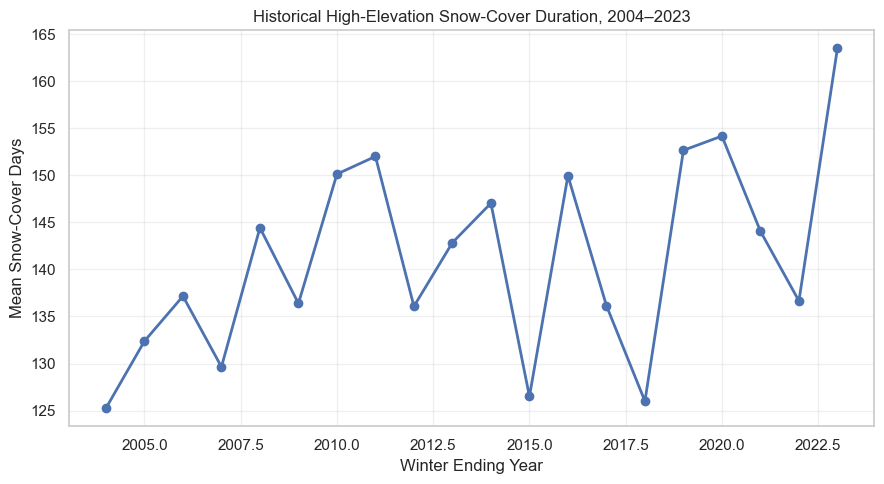


data_figure_2_historical_snow


,year,snow_days_10cm_2000m
0,2004,125.254
1,2005,132.378
2,2006,137.158
3,2007,129.646
4,2008,144.424
5,2009,136.387
6,2010,150.132
7,2011,152.008
8,2012,136.079
9,2013,142.850



FIGURE 3: OBSERVED VS PREDICTED


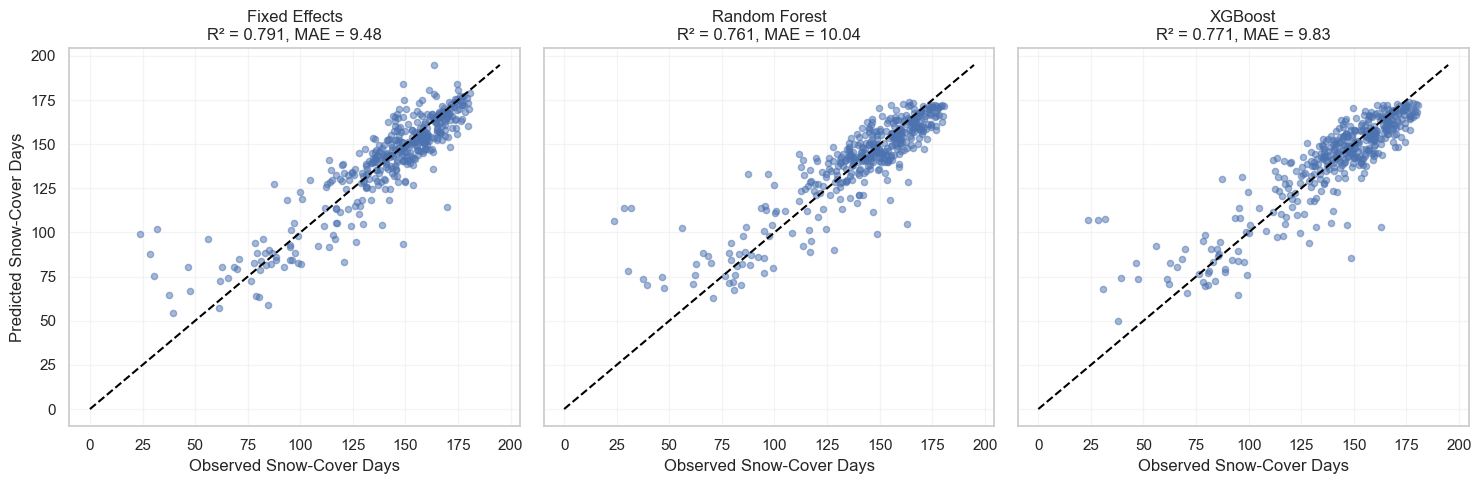


TABLE 2: MODEL VALIDATION

table_2_model_validation


,Validation,Model,N,R2,MAE,RMSE
0,Leave-One-Year-Out,Fixed Effects,400,0.791,9.480,13.563
1,Leave-One-Year-Out,Random Forest,400,0.761,10.040,14.519
2,Leave-One-Year-Out,XGBoost,400,0.771,9.826,14.199
3,Forward-in-Time,Linear,200,0.763,10.340,14.308
4,Forward-in-Time,Random Forest,200,0.803,10.472,13.042
5,Forward-in-Time,XGBoost,200,0.798,10.158,13.232
6,Leave-One-County-Out,Linear,400,0.286,18.582,25.091
7,Leave-One-County-Out,Random Forest,400,0.535,13.092,20.235
8,Leave-One-County-Out,XGBoost,400,0.476,14.171,21.498



APPENDIX: VALIDATION RMSE


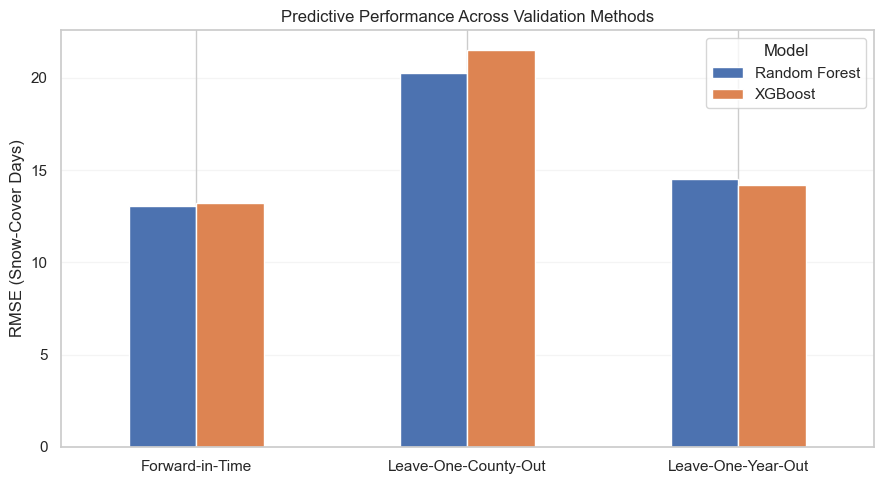


APPENDIX: COUNTY PREDICTION ERRORS

appendix_county_prediction_errors


,fips,County,Model,MAE,County_Label
0,08019,Clear Creek,Fixed Effects,12.841,Clear Creek (08019)
1,08019,Clear Creek,Random Forest,12.892,Clear Creek (08019)
2,08019,Clear Creek,XGBoost,12.765,Clear Creek (08019)
3,08037,Eagle,Fixed Effects,10.382,Eagle (08037)
4,08037,Eagle,Random Forest,8.607,Eagle (08037)
5,08037,Eagle,XGBoost,8.408,Eagle (08037)
6,08049,Grand,Fixed Effects,8.142,Grand (08049)
7,08049,Grand,Random Forest,8.580,Grand (08049)
8,08049,Grand,XGBoost,8.048,Grand (08049)
9,08051,Gunnison,Fixed Effects,9.407,Gunnison (08051)


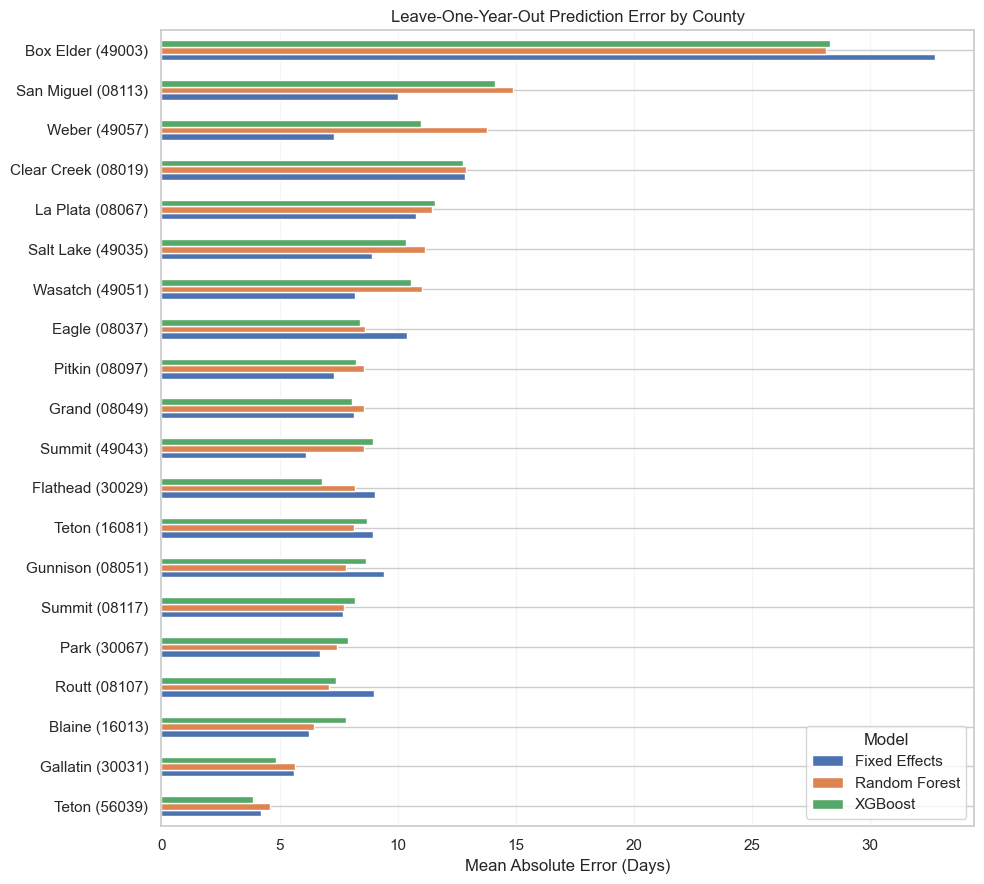


APPENDIX: RESIDUAL ANALYSIS


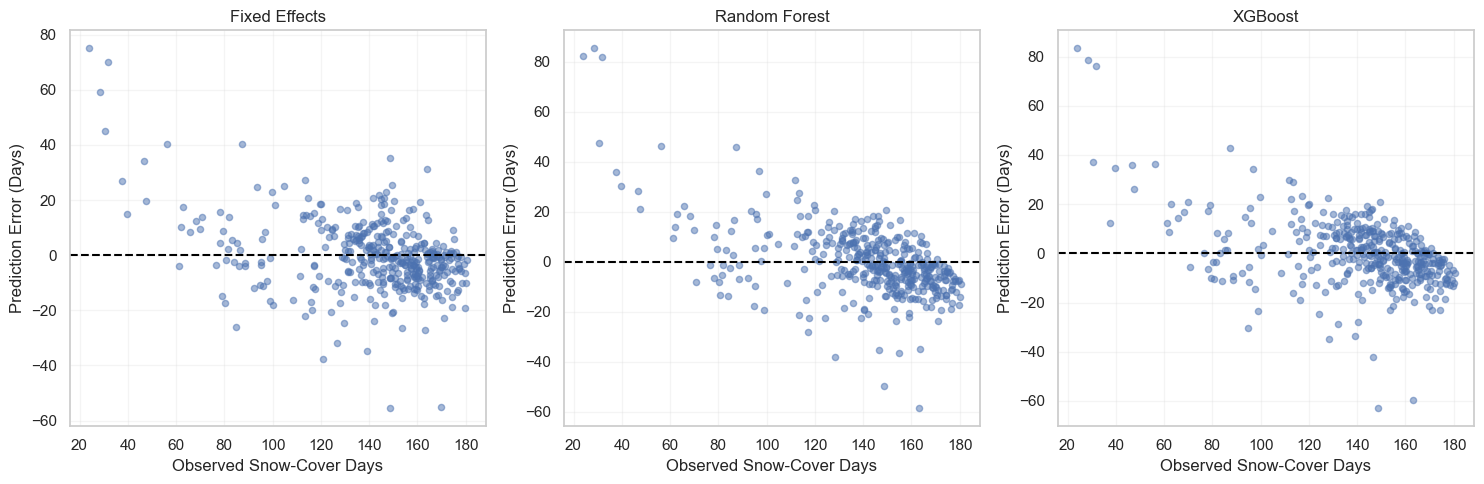


APPENDIX: BOX ELDER SENSITIVITY

appendix_box_elder_sensitivity


,Model,N,R2,MAE,RMSE
0,Linear,380,0.349,16.871,21.432
1,Random Forest,380,0.682,11.158,14.993
2,XGBoost,380,0.616,12.202,16.458



CHECKING WARMING SCENARIO DATA

table_3_warming_results


,warming_C,Fixed Effects,Random Forest,XGBoost
0,0,0.000,0.000,0.000
1,1,-9.701,-9.288,-9.838
2,2,-21.261,-21.214,-20.914
3,3,-34.724,-33.049,-31.788


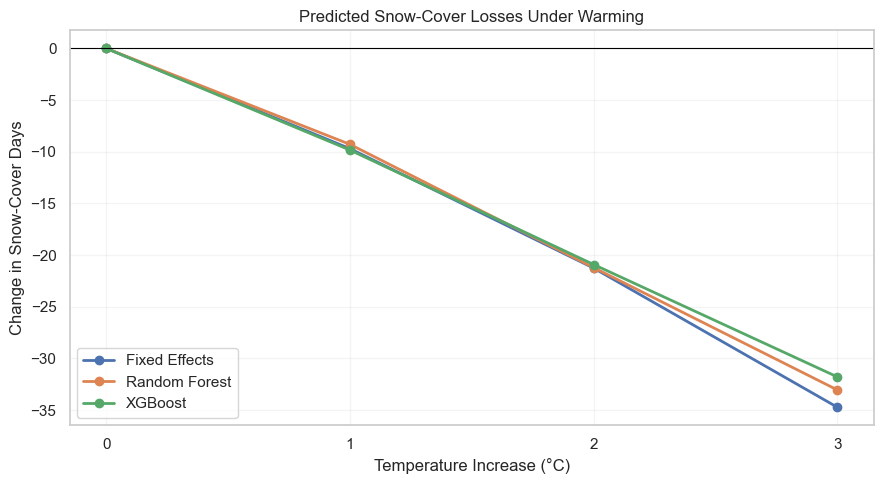


table_state_warming_3c


,state,Fixed Effects,Random Forest,XGBoost
0,Colorado,-27.329,-22.304,-23.691
1,Idaho,-20.733,-23.432,-25.580
2,Montana,-16.383,-18.051,-15.677
3,Utah,-30.648,-26.002,-26.805
4,Wyoming,-13.707,-15.181,-14.955


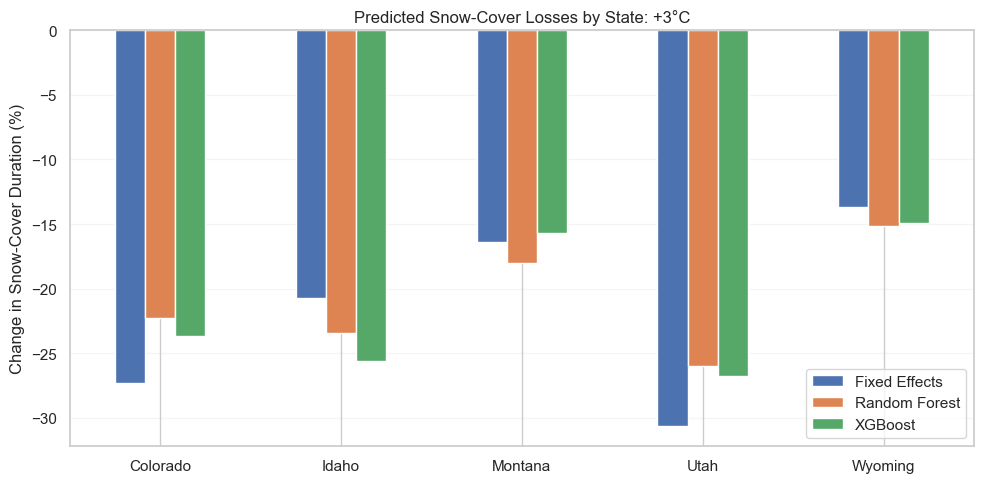


table_4_economic_sensitivity


,warming_C,Model,elasticity,va_change_millions
0,1,Fixed Effects,0.25,-32.177
1,1,Fixed Effects,0.50,-64.353
2,1,Fixed Effects,1.00,-128.707
3,1,Random Forest,0.25,-27.836
4,1,Random Forest,0.50,-55.673
5,1,Random Forest,1.00,-111.346
6,1,XGBoost,0.25,-33.105
7,1,XGBoost,0.50,-66.211
8,1,XGBoost,1.00,-132.421
9,2,Fixed Effects,0.25,-70.137



table_4_central_elasticity


,warming_C,Model,elasticity,va_change_millions
1,1,Fixed Effects,0.5,-64.353
4,1,Random Forest,0.5,-55.673
7,1,XGBoost,0.5,-66.211
10,2,Fixed Effects,0.5,-140.273
13,2,Random Forest,0.5,-125.495
16,2,XGBoost,0.5,-135.885
19,3,Fixed Effects,0.5,-227.884
22,3,Random Forest,0.5,-192.701
25,3,XGBoost,0.5,-202.274



THESIS FIGURES AND TABLES COMPLETE
Files saved to: /Users/evabenson/Files/thesis/snow_ml/code/thesis_outputs
Figures: PNG and PDF
Tables: CSV


In [244]:
# ============================================================
# THESIS FIGURES AND TABLES
# Run after completing the model and warming analysis
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# 0. SETTINGS
# ------------------------------------------------------------

output_dir = Path("thesis_outputs")
output_dir.mkdir(exist_ok=True)

TARGET = "snow_days_10cm_2000m"

prediction_cols = {
    "Fixed Effects": "fe_predicted",
    "Random Forest": "rf_predicted",
    "XGBoost": "xgb_predicted"
}

state_names = {
    "08": "Colorado",
    "16": "Idaho",
    "30": "Montana",
    "49": "Utah",
    "56": "Wyoming"
}

df = model_df.copy()

df["fips"] = (
    df["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

df["year"] = df["year"].astype(int)
df["state_name"] = df["fips"].str[:2].map(state_names)

def save_figure(name):
    plt.tight_layout()
    plt.savefig(output_dir / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.savefig(output_dir / f"{name}.pdf", bbox_inches="tight")
    plt.show()

def save_table(table, name):
    table.to_csv(output_dir / f"{name}.csv", index=False)
    print(f"\n{name}")
    display(table.round(3))

def evaluate(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)

    actual = actual[valid]
    predicted = predicted[valid]

    return {
        "N": len(actual),
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }


# ============================================================
# TABLE 1. DESCRIPTIVE STATISTICS
# ============================================================

print("\nTABLE 1: DESCRIPTIVE STATISTICS")

descriptive_variables = [
    TARGET,
    "valid_fraction_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m",
    "mean_elevation_m",
    "mean_slope_deg"
]

available_variables = [
    col for col in descriptive_variables
    if col in df.columns
]

descriptive = (
    df[available_variables]
    .describe()
    .T
    .reset_index()
    .rename(columns={
        "index": "Variable",
        "count": "N",
        "mean": "Mean",
        "std": "SD",
        "min": "Min",
        "max": "Max"
    })
)

save_table(
    descriptive[["Variable", "N", "Mean", "SD", "Min", "Max"]],
    "table_1_descriptive_statistics"
)


# ============================================================
# FIGURE 2. HISTORICAL SNOW-COVER DURATION
# ============================================================

print("\nFIGURE 2: HISTORICAL SNOW-COVER DURATION")

annual_snow = (
    df.groupby("year")[TARGET]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.plot(
    annual_snow["year"],
    annual_snow[TARGET],
    marker="o",
    linewidth=2
)

plt.xlabel("Winter Ending Year")
plt.ylabel("Mean Snow-Cover Days")
plt.title("Historical High-Elevation Snow-Cover Duration, 2004–2023")
plt.grid(alpha=0.3)

save_figure("figure_2_historical_snow")

save_table(
    annual_snow,
    "data_figure_2_historical_snow"
)


# ============================================================
# FIGURE 3. OBSERVED VS PREDICTED SNOW-COVER DAYS
# ============================================================

print("\nFIGURE 3: OBSERVED VS PREDICTED")

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)

limit = max(
    df[TARGET].max(),
    *[df[col].max() for col in prediction_cols.values()]
)

for ax, (name, col) in zip(axes, prediction_cols.items()):

    results = evaluate(df[TARGET], df[col])

    ax.scatter(
        df[TARGET],
        df[col],
        alpha=0.5,
        s=20
    )

    ax.plot(
        [0, limit],
        [0, limit],
        linestyle="--",
        color="black"
    )

    ax.set_title(
        f"{name}\n"
        f"R² = {results['R2']:.3f}, "
        f"MAE = {results['MAE']:.2f}"
    )

    ax.set_xlabel("Observed Snow-Cover Days")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Predicted Snow-Cover Days")

save_figure("figure_3_observed_vs_predicted")


# ============================================================
# TABLE 2. MODEL VALIDATION
# ============================================================

print("\nTABLE 2: MODEL VALIDATION")

validation_rows = []

# Leave-one-year-out
for name, col in prediction_cols.items():

    validation_rows.append({
        "Validation": "Leave-One-Year-Out",
        "Model": name,
        **evaluate(df[TARGET], df[col])
    })

# Forward-in-time
if "forward_matched" in globals():

    for name, predictions in forward_matched.items():

        validation_rows.append({
            "Validation": "Forward-in-Time",
            "Model": name,
            **evaluate(df[TARGET], predictions)
        })

# Leave-one-county-out
if "spatial_predictions" in globals():

    for name, predictions in spatial_predictions.items():

        validation_rows.append({
            "Validation": "Leave-One-County-Out",
            "Model": name,
            **evaluate(df[TARGET], predictions)
        })

validation_results = pd.DataFrame(validation_rows)

save_table(
    validation_results,
    "table_2_model_validation"
)


# ============================================================
# APPENDIX FIGURE. VALIDATION RMSE COMPARISON
# ============================================================

print("\nAPPENDIX: VALIDATION RMSE")

validation_plot = validation_results[
    validation_results["Model"].isin([
        "Random Forest",
        "XGBoost"
    ])
]

validation_pivot = validation_plot.pivot(
    index="Validation",
    columns="Model",
    values="RMSE"
)

validation_pivot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.ylabel("RMSE (Snow-Cover Days)")
plt.xlabel("")
plt.title("Predictive Performance Across Validation Methods")
plt.grid(axis="y", alpha=0.2)

save_figure("appendix_validation_rmse")


# ============================================================
# APPENDIX FIGURE. COUNTY-LEVEL PREDICTION ERRORS
# FIXED: UNIQUE COUNTY LABELS USING FIPS
# ============================================================

print("\nAPPENDIX: COUNTY PREDICTION ERRORS")

county_rows = []

for (fips, county), group in df.groupby(["fips", "county"]):

    for name, col in prediction_cols.items():

        county_rows.append({
            "fips": fips,
            "County": county,
            "Model": name,
            "MAE": mean_absolute_error(
                group[TARGET],
                group[col]
            )
        })

county_errors = pd.DataFrame(county_rows)

county_errors["County_Label"] = (
    county_errors["County"].astype(str)
    + " ("
    + county_errors["fips"].astype(str)
    + ")"
)

save_table(
    county_errors,
    "appendix_county_prediction_errors"
)

county_pivot = county_errors.pivot(
    index="County_Label",
    columns="Model",
    values="MAE"
)

county_pivot = county_pivot.sort_values("Random Forest")

county_pivot.plot(
    kind="barh",
    figsize=(10, 9)
)

plt.xlabel("Mean Absolute Error (Days)")
plt.ylabel("")
plt.title("Leave-One-Year-Out Prediction Error by County")
plt.grid(axis="x", alpha=0.2)

save_figure("appendix_county_prediction_errors")


# ============================================================
# APPENDIX FIGURE. RESIDUAL ANALYSIS
# ============================================================

print("\nAPPENDIX: RESIDUAL ANALYSIS")

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

for ax, (name, col) in zip(axes, prediction_cols.items()):

    residuals = df[col] - df[TARGET]

    ax.scatter(
        df[TARGET],
        residuals,
        alpha=0.5,
        s=20
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--"
    )

    ax.set_title(name)
    ax.set_xlabel("Observed Snow-Cover Days")
    ax.set_ylabel("Prediction Error (Days)")
    ax.grid(alpha=0.2)

save_figure("appendix_prediction_residuals")


# ============================================================
# APPENDIX TABLE. BOX ELDER SENSITIVITY
# ============================================================

if "spatial_predictions" in globals():

    print("\nAPPENDIX: BOX ELDER SENSITIVITY")

    mask = (
        df["county"]
        .astype(str)
        .str.lower()
        .ne("box elder")
        .to_numpy()
    )

    box_elder_rows = []

    for name, predictions in spatial_predictions.items():

        box_elder_rows.append({
            "Model": name,
            **evaluate(
                df.loc[mask, TARGET],
                np.asarray(predictions)[mask]
            )
        })

    box_elder_results = pd.DataFrame(box_elder_rows)

    save_table(
        box_elder_results,
        "appendix_box_elder_sensitivity"
    )


# ============================================================
# FIGURES 4–5 AND TABLES 3–4: WARMING + ECONOMICS
#
# The next sections detect existing notebook variables.
# They will skip if the expected dataframes are unavailable.
# ============================================================

print("\nCHECKING WARMING SCENARIO DATA")

if "snow_predictions" in globals():

    snow_scenarios = snow_predictions.copy()

    change_cols = [
        "Fixed Effects_change",
        "Random Forest_change",
        "XGBoost_change"
    ]

    if all(
        col in snow_scenarios.columns
        for col in ["warming_C"] + change_cols
    ):

        # TABLE 3
        warming_results = (
            snow_scenarios
            .groupby("warming_C")[change_cols]
            .mean()
            .reset_index()
            .rename(columns={
                "Fixed Effects_change": "Fixed Effects",
                "Random Forest_change": "Random Forest",
                "XGBoost_change": "XGBoost"
            })
        )

        save_table(
            warming_results,
            "table_3_warming_results"
        )

        # FIGURE 4
        plt.figure(figsize=(9, 5))

        for model in prediction_cols:

            plt.plot(
                warming_results["warming_C"],
                warming_results[model],
                marker="o",
                linewidth=2,
                label=model
            )

        plt.axhline(0, color="black", linewidth=0.8)

        plt.xlabel("Temperature Increase (°C)")
        plt.ylabel("Change in Snow-Cover Days")
        plt.title("Predicted Snow-Cover Losses Under Warming")
        plt.xticks([0, 1, 2, 3])
        plt.legend()
        plt.grid(alpha=0.2)

        save_figure("figure_4_warming_response")

    else:
        print(
            "Warming change columns differ from expected names. "
            "Available columns:",
            snow_scenarios.columns.tolist()
        )

else:
    print("snow_predictions not found; warming figure skipped.")


# ============================================================
# FIGURE 5. STATE-LEVEL WARMING RESPONSE
# ============================================================

if "state_pct_summary" in globals():

    state_pct = state_pct_summary.copy()

    needed = [
        "warming_C",
        "state",
        "Fixed Effects",
        "Random Forest",
        "XGBoost"
    ]

    if all(col in state_pct.columns for col in needed):

        state_3c = (
            state_pct[state_pct["warming_C"] == 3]
            .set_index("state")[
                ["Fixed Effects", "Random Forest", "XGBoost"]
            ]
        )

        state_3c = state_3c.reindex([
            "Colorado",
            "Idaho",
            "Montana",
            "Utah",
            "Wyoming"
        ])

        save_table(
            state_3c.reset_index(),
            "table_state_warming_3c"
        )

        state_3c.plot(
            kind="bar",
            figsize=(10, 5),
            rot=0
        )

        plt.ylabel("Change in Snow-Cover Duration (%)")
        plt.xlabel("")
        plt.title("Predicted Snow-Cover Losses by State: +3°C")
        plt.grid(axis="y", alpha=0.2)

        save_figure("figure_5_state_warming")

    else:
        print(
            "State warming columns differ from expected names:",
            state_pct.columns.tolist()
        )

else:
    print("state_pct_summary not found; state figure skipped.")


# ============================================================
# TABLE 4. ECONOMIC SENSITIVITY
# ============================================================

if "economic_totals" in globals():

    economic_table = economic_totals.copy()

    save_table(
        economic_table,
        "table_4_economic_sensitivity"
    )

    if "elasticity" in economic_table.columns:

        central_economic = economic_table[
            np.isclose(
                pd.to_numeric(economic_table["elasticity"]),
                0.50
            )
        ]

        save_table(
            central_economic,
            "table_4_central_elasticity"
        )

else:
    print("economic_totals not found; economic table skipped.")


# ============================================================
# FINISHED
# ============================================================

print("\n" + "=" * 60)
print("THESIS FIGURES AND TABLES COMPLETE")
print("=" * 60)
print(f"Files saved to: {output_dir.resolve()}")
print("Figures: PNG and PDF")
print("Tables: CSV")

In [245]:
# ============================================================
# VERIFY AND REFIT FINAL MODELS ON ALL HISTORICAL DATA
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

# Historical observations
train_df = model_df.copy()

train_df["fips"] = (
    train_df["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

TARGET = "snow_days_10cm_2000m"

assert len(train_df) == 400
assert train_df["fips"].nunique() == 20
assert train_df["year"].nunique() == 20

# Preserve the original feature sets
rf_features = list(final_rf.feature_names_in_)
xgb_features = list(xgb.feature_names_in_)

fe_features = [
    "positive_degree_days_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

# ------------------------------------------------------------
# Fixed effects: fit on all 400 observations
# ------------------------------------------------------------

fe_preprocessor = ColumnTransformer([
    (
        "county",
        OneHotEncoder(handle_unknown="ignore"),
        ["fips"]
    ),
    (
        "climate",
        "passthrough",
        fe_features
    )
])

final_fe = Pipeline([
    ("preprocessor", fe_preprocessor),
    ("regression", LinearRegression())
])

final_fe.fit(
    train_df[["fips"] + fe_features],
    train_df[TARGET]
)

# ------------------------------------------------------------
# Random Forest: fit on all 400 observations
# ------------------------------------------------------------

final_rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_leaf=3,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(
    train_df[rf_features],
    train_df[TARGET]
)

# ------------------------------------------------------------
# XGBoost: fit on all 400 observations
# ------------------------------------------------------------

final_xgb = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=10,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_xgb.fit(
    train_df[xgb_features],
    train_df[TARGET]
)

print("FINAL MODEL VERIFICATION")
print("=" * 55)
print("Training observations:", len(train_df))
print("Counties:", train_df["fips"].nunique())
print("Years:", train_df["year"].nunique())
print("Fixed effects predictors:", fe_features)
print("Random Forest predictors:", len(rf_features))
print("XGBoost predictors:", len(xgb_features))
print("\nAll three final models fitted on full historical sample.")

FINAL MODEL VERIFICATION
Training observations: 400
Counties: 20
Years: 20
Fixed effects predictors: ['positive_degree_days_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m']
Random Forest predictors: 18
XGBoost predictors: 18

All three final models fitted on full historical sample.


In [246]:
# Random Forest
snow_predictions["Random Forest"] = final_rf.predict(
    warming_model_df[rf_features]
)

# XGBoost
snow_predictions["XGBoost"] = final_xgb.predict(
    warming_model_df[xgb_features]
)

# Fixed Effects
snow_predictions["Fixed Effects"] = final_fe.predict(
    warming_model_df[["fips"] + fe_features]
)

In [247]:
# ============================================================
# FINAL CONSISTENCY CHECKS
# ============================================================

models = ["Fixed Effects", "Random Forest", "XGBoost"]

print("1. SCENARIO COVERAGE")
print(snow_predictions.groupby("warming_C").size())

assert len(snow_predictions) == 1600
assert snow_predictions.groupby("warming_C").size().eq(400).all()

print("\n2. BASELINE CHANGES SHOULD BE ZERO")

baseline = snow_predictions[
    snow_predictions["warming_C"] == 0
]

for model in models:
    maximum_difference = baseline[f"{model}_change"].abs().max()
    print(model, maximum_difference)
    assert np.isclose(maximum_difference, 0)

print("\n3. AVERAGE WARMING RESPONSE")

warming_check = (
    snow_predictions
    .groupby("warming_C")[
        [f"{model}_change" for model in models]
    ]
    .mean()
)

display(warming_check.round(3))

print("\n4. ECONOMIC ELASTICITY CONSISTENCY")

econ_check = economic_totals.pivot_table(
    index=["warming_C", "Model"],
    columns="elasticity",
    values="va_change_millions"
)

display(econ_check.round(3))

assert np.allclose(
    econ_check[1.0],
    2 * econ_check[0.5]
)

assert np.allclose(
    econ_check[0.25],
    0.5 * econ_check[0.5]
)

print("\nAll consistency checks passed.")

1. SCENARIO COVERAGE
warming_C
0    400
1    400
2    400
3    400
dtype: int64

2. BASELINE CHANGES SHOULD BE ZERO
Fixed Effects 0.0
Random Forest 0.0
XGBoost 0.0

3. AVERAGE WARMING RESPONSE


,Fixed Effects_change,Random Forest_change,XGBoost_change
warming_C,,,
0,0.000,0.000,0.000
1,-9.701,-9.288,-9.838
2,-21.261,-21.214,-20.914
3,-34.724,-33.049,-31.788



4. ECONOMIC ELASTICITY CONSISTENCY


elasticity                  0.25     0.50     1.00
warming_C Model                                   
1         Fixed Effects  -32.177  -64.353 -128.707
          Random Forest  -27.836  -55.673 -111.346
          XGBoost        -33.105  -66.211 -132.421
2         Fixed Effects  -70.137 -140.273 -280.547
          Random Forest  -62.747 -125.495 -250.989
          XGBoost        -67.942 -135.885 -271.769
3         Fixed Effects -113.942 -227.884 -455.767
          Random Forest  -96.350 -192.701 -385.402
          XGBoost       -101.137 -202.274 -404.547


All consistency checks passed.


In [248]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

y = model_df["snow_days_10cm_2000m"]
p = model_df["fe_predicted"]

print("Fixed-effects LOYO verification")
print("R²:", r2_score(y, p))
print("MAE:", mean_absolute_error(y, p))
print("RMSE:", np.sqrt(mean_squared_error(y, p)))

Fixed-effects LOYO verification
R²: 0.791253805038502
MAE: 9.479908873128391
RMSE: 13.562567604589654


In [250]:
print("SNOW PREDICTIONS:")
print(snow_predictions.columns.tolist())

print("\nWARMING MODEL DATA:")
print(warming_model_df.columns.tolist())

print("\nBASELINE ROW COUNTS:")
print("snow_predictions:",
      (snow_predictions["warming_C"] == 0).sum())

print("warming_model_df:",
      (warming_model_df["warming_C"] == 0).sum())

SNOW PREDICTIONS:
['fips', 'state', 'county', 'year', 'warming_C', 'Random Forest', 'XGBoost', 'Fixed Effects', 'Fixed Effects_baseline', 'Random Forest_baseline', 'XGBoost_baseline', 'Fixed Effects_change', 'Random Forest_change', 'XGBoost_change']

WARMING MODEL DATA:
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tma

In [251]:
import numpy as np
import pandas as pd

# Baseline predictors
baseline_features = warming_model_df.loc[
    warming_model_df["warming_C"] == 0
].copy()

# Previously saved baseline predictions
baseline_predictions = snow_predictions.loc[
    snow_predictions["warming_C"] == 0
].copy()

# Normalize county identifiers
for frame in [baseline_features, baseline_predictions]:
    frame["fips"] = (
        frame["fips"]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )

# Match observations by county and year rather than row order
keys = ["fips", "year"]

assert not baseline_features.duplicated(keys).any()
assert not baseline_predictions.duplicated(keys).any()

comparison = baseline_predictions[
    keys + ["Fixed Effects", "Random Forest", "XGBoost"]
].merge(
    baseline_features,
    on=keys,
    how="inner",
    validate="one_to_one"
)

assert len(comparison) == 400, (
    f"Expected 400 matched baseline observations; "
    f"found {len(comparison)}"
)

# Independently calculate predictions from the final models
expected = {
    "Fixed Effects": final_fe.predict(
        comparison[["fips"] + fe_features]
    ),
    "Random Forest": final_rf.predict(
        comparison[rf_features]
    ),
    "XGBoost": final_xgb.predict(
        comparison[xgb_features]
    )
}

print("FINAL MODEL PREDICTION VERIFICATION")
print("=" * 55)

for model, predicted in expected.items():

    stored = comparison[model].to_numpy(dtype=float)

    max_difference = np.max(
        np.abs(stored - predicted)
    )

    matches = np.allclose(
        stored,
        predicted,
        rtol=1e-6,
        atol=1e-6
    )

    print(f"\n{model}")
    print(f"Maximum difference: {max_difference:.8f}")
    print(f"Matches final model: {matches}")

FINAL MODEL PREDICTION VERIFICATION

Fixed Effects
Maximum difference: 0.00000000
Matches final model: True

Random Forest
Maximum difference: 0.00000000
Matches final model: True

XGBoost
Maximum difference: 0.00000000
Matches final model: True


In [252]:
import numpy as np
import pandas as pd

keys = ["fips", "year", "warming_C"]
models = ["Fixed Effects", "Random Forest", "XGBoost"]

features = warming_model_df.copy()
stored = snow_predictions.copy()

for frame in [features, stored]:
    frame["fips"] = (
        frame["fips"].astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )

assert not features.duplicated(keys).any()
assert not stored.duplicated(keys).any()

comparison = stored[keys + models].merge(
    features,
    on=keys,
    validate="one_to_one"
)

assert len(comparison) == 1600

# Recalculate predictions from the final models
expected = {
    "Fixed Effects": final_fe.predict(
        comparison[["fips"] + fe_features]
    ),
    "Random Forest": final_rf.predict(
        comparison[rf_features]
    ),
    "XGBoost": final_xgb.predict(
        comparison[xgb_features]
    )
}

print("FINAL WARMING SCENARIO VERIFICATION")
print("=" * 55)

for model, predictions in expected.items():

    comparison[f"{model}_difference"] = (
        comparison[model].to_numpy()
        - predictions
    )

    print(f"\n{model}")

    for warming in [0, 1, 2, 3]:

        subset = comparison[
            comparison["warming_C"] == warming
        ]

        max_diff = subset[f"{model}_difference"].abs().max()

        print(
            f"+{warming}°C: "
            f"max difference = {max_diff:.8f}"
        )

FINAL WARMING SCENARIO VERIFICATION

Fixed Effects
+0°C: max difference = 0.00000000
+1°C: max difference = 0.00000000
+2°C: max difference = 0.00000000
+3°C: max difference = 0.00000000

Random Forest
+0°C: max difference = 0.00000000
+1°C: max difference = 0.00000000
+2°C: max difference = 0.00000000
+3°C: max difference = 0.00000000

XGBoost
+0°C: max difference = 0.00000000
+1°C: max difference = 0.00000000
+2°C: max difference = 0.00000000
+3°C: max difference = 0.00000000


,fips,County,Fixed Effects,Random Forest,XGBoost,County_Label
4,08067,La Plata,-68.73,-17.45,-11.180000,La Plata (08067)
7,08113,San Miguel,-58.74,-23.61,-18.170000,San Miguel (08113)
14,49003,Box Elder,-47.48,-27.32,-41.939999,Box Elder (49003)
15,49035,Salt Lake,-34.26,-33.20,-26.160000,Salt Lake (49035)
18,49057,Weber,-32.00,-35.43,-24.340000,Weber (49057)
17,49051,Wasatch,-29.85,-35.75,-30.370001,Wasatch (49051)
1,08037,Eagle,-29.77,-31.50,-33.570000,Eagle (08037)
0,08019,Clear Creek,-27.22,-18.87,-22.719999,Clear Creek (08019)
6,08107,Routt,-26.03,-28.40,-28.530001,Routt (08107)
16,49043,Summit,-24.66,-32.78,-30.110001,Summit (49043)


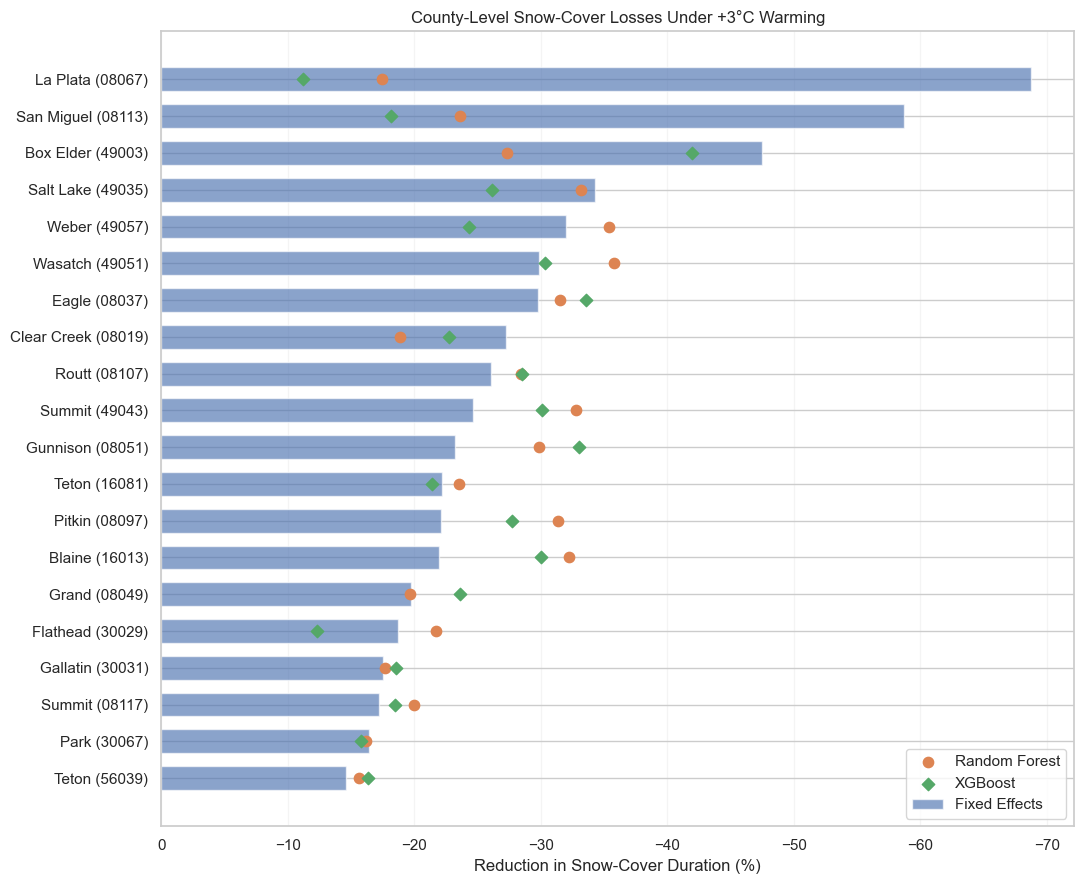

In [264]:
# ============================================================
# FIGURE 6: COUNTY-LEVEL SNOW-COVER LOSSES AT +3°C
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("thesis_outputs")
output_dir.mkdir(exist_ok=True)

models = ["Fixed Effects", "Random Forest", "XGBoost"]

# Use existing warming predictions
county_data = snow_predictions.copy()

county_data["fips"] = (
    county_data["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Retain +3°C scenario
county_data = county_data[
    county_data["warming_C"] == 3
].copy()

# Calculate county-level percentage change
results = []

for (fips, county), group in county_data.groupby(
    ["fips", "county"]
):

    row = {
        "fips": fips,
        "County": county
    }

    for model in models:

        baseline_col = f"{model}_baseline"
        change_col = f"{model}_change"

        baseline_total = group[baseline_col].sum()
        change_total = group[change_col].sum()

        row[model] = (
            100 * change_total / baseline_total
            if baseline_total > 0
            else np.nan
        )

    results.append(row)

county_results = pd.DataFrame(results)

# Unique labels distinguish counties with the same name
county_results["County_Label"] = (
    county_results["County"].astype(str)
    + " ("
    + county_results["fips"]
    + ")"
)

# Sort from largest to smallest loss
county_results = county_results.sort_values(
    "Fixed Effects",
    ascending=True
)

# Save table
county_results.to_csv(
    output_dir / "figure_6_county_warming_data.csv",
    index=False
)

display(county_results.round(2))

# Plot
fig, ax = plt.subplots(figsize=(11, 9))

y = np.arange(len(county_results))

ax.barh(
    y,
    county_results["Fixed Effects"],
    height=0.65,
    alpha=0.65,
    label="Fixed Effects"
)

ax.scatter(
    county_results["Random Forest"],
    y,
    marker="o",
    s=55,
    label="Random Forest",
    zorder=3
)

ax.scatter(
    county_results["XGBoost"],
    y,
    marker="D",
    s=40,
    label="XGBoost",
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(county_results["County_Label"])

ax.invert_yaxis()
ax.invert_xaxis()

ax.set_xlabel("Reduction in Snow-Cover Duration (%)")
ax.set_title(
    "County-Level Snow-Cover Losses Under +3°C Warming"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    output_dir / "figure_6_county_warming.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_dir / "figure_6_county_warming.pdf",
    bbox_inches="tight"
)

plt.show()

Available economic columns:
['state', 'warming_C', 'Model', 'snow_change_pct', 'baseline_va_millions', 'elasticity', 'economic_change_pct', 'va_change_millions']


Model,Fixed Effects,Random Forest,XGBoost
state,,,
Colorado,158.59,135.06,135.13
Idaho,10.00,12.61,11.62
Montana,4.30,4.54,3.80
Utah,68.31,69.69,62.49
Wyoming,1.99,2.12,2.22


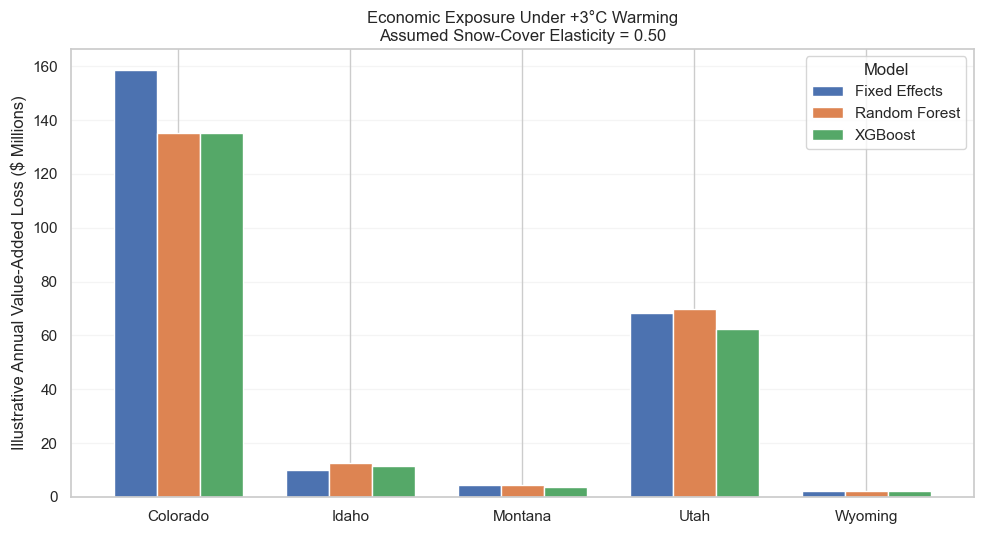

In [263]:
# ============================================================
# FIGURE 7: ECONOMIC EXPOSURE BY STATE AT +3°C
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("thesis_outputs")
output_dir.mkdir(exist_ok=True)

# Existing state-level economic results
econ = economic_results.copy()

print("Available economic columns:")
print(econ.columns.tolist())

# Filter to +3°C and central elasticity
econ_3c = econ[
    (econ["warming_C"] == 3)
    & (np.isclose(econ["elasticity"], 0.50))
].copy()

# Assumes the existing economic table is in long format
# with state, model, and economic change columns.
required = [
    "state",
    "Model",
    "va_change_millions"
]

missing = [
    col for col in required
    if col not in econ_3c.columns
]

if missing:
    raise ValueError(
        f"Missing expected columns: {missing}. "
        f"Available columns: {econ_3c.columns.tolist()}"
    )

# Convert losses to positive magnitudes
econ_3c["Economic_Loss_M"] = (
    -econ_3c["va_change_millions"]
)

# Pivot for grouped bars
econ_pivot = econ_3c.pivot(
    index="state",
    columns="Model",
    values="Economic_Loss_M"
)

econ_pivot = econ_pivot.reindex([
    "Colorado",
    "Idaho",
    "Montana",
    "Utah",
    "Wyoming"
])

econ_pivot = econ_pivot[
    ["Fixed Effects", "Random Forest", "XGBoost"]
]

# Save table
econ_pivot.to_csv(
    output_dir / "figure_7_economic_exposure_data.csv"
)

display(econ_pivot.round(2))

# Plot
ax = econ_pivot.plot(
    kind="bar",
    figsize=(10, 5.5),
    width=0.75,
    rot=0
)

ax.set_ylabel("Illustrative Annual Value-Added Loss ($ Millions)")
ax.set_xlabel("")
ax.set_title(
    "Economic Exposure Under +3°C Warming\n"
    "Assumed Snow-Cover Elasticity = 0.50"
)

ax.legend(title="Model")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    output_dir / "figure_7_economic_exposure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    output_dir / "figure_7_economic_exposure.pdf",
    bbox_inches="tight"
)

plt.show()

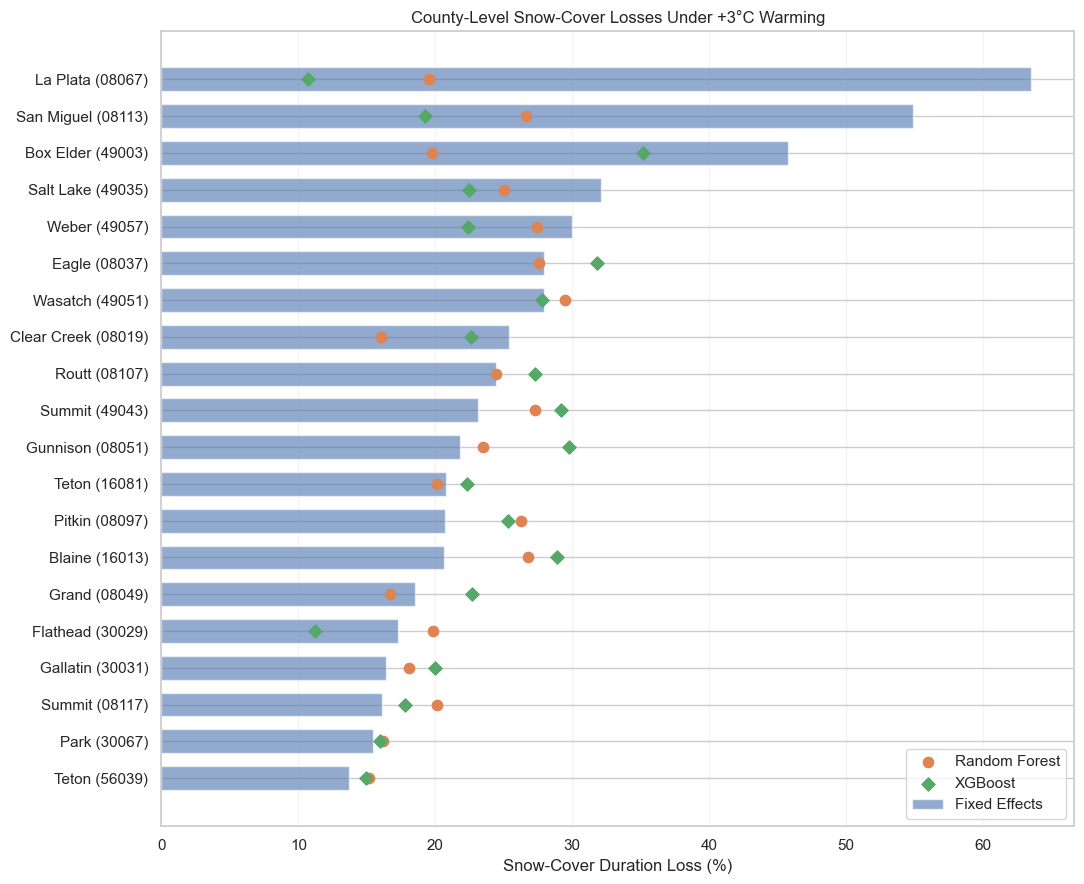

In [255]:
plot_df = county_results.copy()

for model in models:
    plot_df[model] = -plot_df[model]

plot_df = plot_df.sort_values(
    "Fixed Effects",
    ascending=False
)

fig, ax = plt.subplots(figsize=(11, 9))
y = np.arange(len(plot_df))

ax.barh(
    y,
    plot_df["Fixed Effects"],
    height=0.65,
    alpha=0.6,
    label="Fixed Effects"
)

ax.scatter(
    plot_df["Random Forest"],
    y,
    s=55,
    marker="o",
    label="Random Forest",
    zorder=3
)

ax.scatter(
    plot_df["XGBoost"],
    y,
    s=45,
    marker="D",
    label="XGBoost",
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["County_Label"])
ax.invert_yaxis()

ax.set_xlabel("Snow-Cover Duration Loss (%)")
ax.set_title("County-Level Snow-Cover Losses Under +3°C Warming")
ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [256]:
%pip install geopandas


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


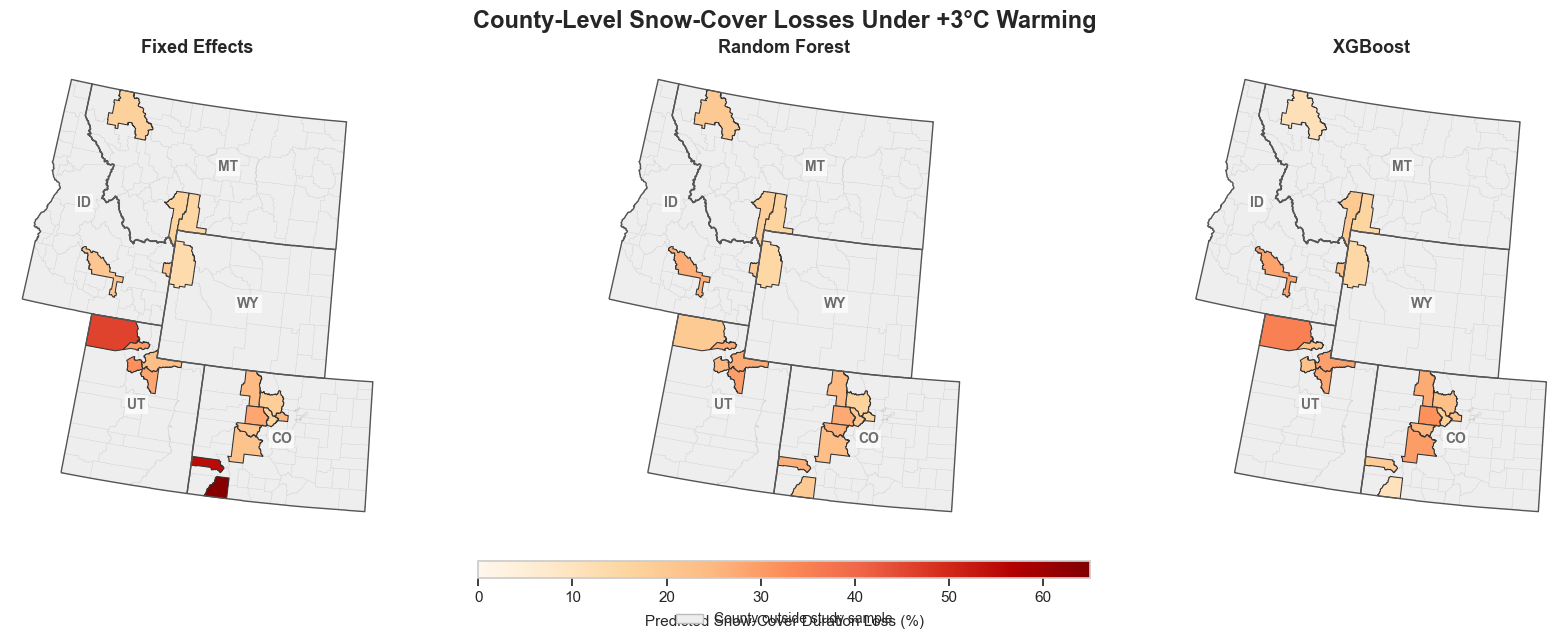

Figure saved:
thesis_outputs/figure_8_county_warming_maps_final.png
thesis_outputs/figure_8_county_warming_maps_final.pdf

Study counties mapped: 20


In [262]:
# ============================================================
# FIGURE 8: COUNTY-LEVEL SNOW-COVER LOSSES AT +3°C
# Three-model comparison with state labels and shared legend
# ============================================================

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
from pathlib import Path

# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------

output_dir = Path("thesis_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Download Census county and state boundaries
# ------------------------------------------------------------

counties_url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/"
    "cb_2023_us_county_500k.zip"
)

states_url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/"
    "cb_2023_us_state_500k.zip"
)

counties = gpd.read_file(counties_url)
states = gpd.read_file(states_url)

# Colorado, Idaho, Montana, Utah, Wyoming
state_fips = ["08", "16", "30", "49", "56"]

counties = counties[
    counties["STATEFP"].isin(state_fips)
].copy()

states = states[
    states["STATEFP"].isin(state_fips)
].copy()

# ------------------------------------------------------------
# 3. Merge county-level warming results
# ------------------------------------------------------------

results = county_results.copy()

results["fips"] = (
    results["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

models = [
    "Fixed Effects",
    "Random Forest",
    "XGBoost"
]

mapped = counties.merge(
    results[["fips"] + models],
    left_on="GEOID",
    right_on="fips",
    how="left",
    validate="one_to_one"
)

# Convert negative percentage changes into positive loss magnitudes
for model in models:
    mapped[f"{model}_loss"] = -mapped[model]

# Verify that all 20 study counties are present
study_counties = mapped.dropna(
    subset=["Fixed Effects_loss"]
)

assert len(study_counties) == 20, (
    f"Expected 20 study counties, found {len(study_counties)}"
)

# ------------------------------------------------------------
# 4. Project geographic data
# ------------------------------------------------------------

# NAD83 / Conus Albers
mapped = mapped.to_crs("EPSG:5070")
states = states.to_crs("EPSG:5070")

# ------------------------------------------------------------
# 5. State labels
# ------------------------------------------------------------

state_labels = {
    "08": "CO",
    "16": "ID",
    "30": "MT",
    "49": "UT",
    "56": "WY"
}

# Label locations based on state geometries
label_positions = {}

for _, state in states.iterrows():

    point = state.geometry.representative_point()

    label_positions[state["STATEFP"]] = (
        point.x,
        point.y
    )

# ------------------------------------------------------------
# 6. Create three-panel map
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6.8),
    sharex=True,
    sharey=True
)

cmap = "OrRd"
vmin = 0
vmax = 65

for ax, model in zip(axes, models):

    # All counties in light gray
    mapped.plot(
        ax=ax,
        color="#eeeeee",
        edgecolor="#d0d0d0",
        linewidth=0.25
    )

    # Study counties colored by predicted loss
    mapped.dropna(
        subset=[f"{model}_loss"]
    ).plot(
        column=f"{model}_loss",
        ax=ax,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        edgecolor="#333333",
        linewidth=0.75
    )

    # State boundaries
    states.boundary.plot(
        ax=ax,
        color="#555555",
        linewidth=1.0
    )

    # State abbreviations
    for state_fips_code, (x, y) in label_positions.items():

        ax.text(
            x,
            y,
            state_labels[state_fips_code],
            fontsize=10,
            fontweight="bold",
            ha="center",
            va="center",
            color="#555555",
            alpha=0.85,
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.65,
                pad=1.5
            ),
            zorder=10
        )

    ax.set_title(
        model,
        fontsize=13,
        fontweight="bold",
        pad=8
    )

    ax.set_axis_off()
    ax.set_aspect("equal")

# ------------------------------------------------------------
# 7. Shared map extent
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = states.total_bounds

xpad = (xmax - xmin) * 0.035
ypad = (ymax - ymin) * 0.035

for ax in axes:
    ax.set_xlim(xmin - xpad, xmax + xpad)
    ax.set_ylim(ymin - ypad, ymax + ypad)

# ------------------------------------------------------------
# 8. Shared colorbar
# ------------------------------------------------------------

norm = Normalize(vmin=vmin, vmax=vmax)

sm = ScalarMappable(
    norm=norm,
    cmap=cmap
)
sm.set_array([])

# Reserve bottom space for colorbar and legend
fig.subplots_adjust(
    left=0.015,
    right=0.985,
    top=0.88,
    bottom=0.20,
    wspace=0.025
)

cbar_ax = fig.add_axes([
    0.33, 0.125, 0.34, 0.025
])

cbar = fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label(
    "Predicted Snow-Cover Duration Loss (%)",
    fontsize=11,
    labelpad=7
)

cbar.set_ticks(
    [0, 10, 20, 30, 40, 50, 60]
)

# ------------------------------------------------------------
# 9. Gray-county legend
# ------------------------------------------------------------

legend_elements = [
    Patch(
        facecolor="#eeeeee",
        edgecolor="#bdbdbd",
        label="County outside study sample"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),
    frameon=False,
    fontsize=10
)

# ------------------------------------------------------------
# 10. Figure title
# ------------------------------------------------------------

fig.suptitle(
    "County-Level Snow-Cover Losses Under +3°C Warming",
    fontsize=17,
    fontweight="bold",
    y=0.96
)

# ------------------------------------------------------------
# 11. Save high-resolution figures
# ------------------------------------------------------------

png_path = (
    output_dir /
    "figure_8_county_warming_maps_final.png"
)

pdf_path = (
    output_dir /
    "figure_8_county_warming_maps_final.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved:")
print(png_path)
print(pdf_path)

print("\nStudy counties mapped:", len(study_counties))

In [259]:
import numpy as np
import pandas as pd

models = ["Fixed Effects", "Random Forest", "XGBoost"]

df = snow_predictions.copy()

df["fips"] = (
    df["fips"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

keys = ["fips", "year"]

baseline = df.loc[
    df["warming_C"] == 0,
    keys + models
].copy()

baseline = baseline.rename(
    columns={m: f"{m}_baseline_check" for m in models}
)

check = df.merge(
    baseline,
    on=keys,
    how="left",
    validate="many_to_one"
)

print("WARMING CHANGE RECONCILIATION")
print("=" * 55)

for model in models:
    recalculated = (
        check[model] - check[f"{model}_baseline_check"]
    )
    stored = check[f"{model}_change"]

    difference = (recalculated - stored).abs()

    print(f"\n{model}")
    print("Maximum discrepancy:", difference.max())
    print("All changes match:", np.allclose(
        recalculated, stored, atol=1e-6, rtol=1e-6
    ))

    print("Recalculated mean changes:")
    print(
        check.assign(recalculated_change=recalculated)
        .groupby("warming_C")["recalculated_change"]
        .mean()
        .round(3)
    )

WARMING CHANGE RECONCILIATION

Fixed Effects
Maximum discrepancy: 17.335070414396597
All changes match: False
Recalculated mean changes:
warming_C
0     0.000
1   -10.376
2   -22.722
3   -37.139
Name: recalculated_change, dtype: float64

Random Forest
Maximum discrepancy: 38.44251887735467
All changes match: False
Recalculated mean changes:
warming_C
0     0.000
1   -10.721
2   -23.279
3   -36.058
Name: recalculated_change, dtype: float64

XGBoost
Maximum discrepancy: 28.004784
All changes match: False
Recalculated mean changes:
warming_C
0     0.000000
1   -10.715000
2   -22.736000
3   -33.877998
Name: recalculated_change, dtype: float32


In [260]:
import numpy as np
import pandas as pd

models = ["Fixed Effects", "Random Forest", "XGBoost"]
keys = ["fips", "year"]

# 1. Start with the verified final-model predictions
df = snow_predictions.copy()

df["fips"] = (
    df["fips"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
df["year"] = df["year"].astype(int)

assert not df.duplicated(keys + ["warming_C"]).any()
assert df.groupby("warming_C").size().eq(400).all()

# 2. Reconstruct baseline predictions
baseline = df.loc[
    df["warming_C"] == 0,
    keys + models
].copy()

assert not baseline.duplicated(keys).any()

baseline = baseline.rename(
    columns={m: f"{m}_baseline" for m in models}
)

# Remove outdated derived columns
df = df.drop(
    columns=[
        f"{m}_{suffix}"
        for m in models
        for suffix in ["baseline", "change", "pct_change"]
    ],
    errors="ignore"
)

# 3. Match each scenario to its own county-year baseline
df = df.merge(
    baseline,
    on=keys,
    how="left",
    validate="many_to_one"
)

assert len(df) == 1600

for model in models:
    df[f"{model}_change"] = (
        df[model] - df[f"{model}_baseline"]
    )

    assert np.allclose(
        df.loc[df["warming_C"] == 0, f"{model}_change"],
        0,
        atol=1e-6
    )

snow_predictions = df

# 4. Recalculate state-level percentage changes
state_names = {
    "08": "Colorado",
    "16": "Idaho",
    "30": "Montana",
    "49": "Utah",
    "56": "Wyoming"
}

df["state_name"] = df["fips"].str[:2].map(state_names)
assert df["state_name"].notna().all()

rows = []

for (state, warming), group in df.groupby(
    ["state_name", "warming_C"]
):
    if warming == 0:
        continue

    row = {"state": state, "warming_C": warming}

    for model in models:
        baseline_sum = group[f"{model}_baseline"].sum()
        change_sum = group[f"{model}_change"].sum()

        row[model] = (
            100 * change_sum / baseline_sum
            if baseline_sum > 0 else np.nan
        )

    rows.append(row)

state_pct_summary = pd.DataFrame(rows).sort_values(
    ["state", "warming_C"]
)

# 5. Recalculate economic results
economic_base = orsa_2023[
    ["state", "baseline_va_millions"]
].copy()

snow_pct_long = state_pct_summary.melt(
    id_vars=["state", "warming_C"],
    value_vars=models,
    var_name="Model",
    value_name="snow_change_pct"
)

economic_warming = snow_pct_long.merge(
    economic_base,
    on="state",
    how="left",
    validate="many_to_one"
)

assert economic_warming["baseline_va_millions"].notna().all()

economic_results = pd.concat(
    [
        economic_warming.assign(
            elasticity=eta,
            economic_change_pct=lambda x: x["snow_change_pct"] * eta,
            va_change_millions=lambda x:
                x["baseline_va_millions"]
                * x["snow_change_pct"]
                * eta / 100
        )
        for eta in [0.25, 0.50, 1.00]
    ],
    ignore_index=True
)

economic_totals = (
    economic_results
    .groupby(["warming_C", "Model", "elasticity"], as_index=False)
    ["va_change_millions"]
    .sum()
)

# 6. Display reconciled results
print("CORRECTED MEAN SNOW-COVER CHANGES")
display(
    snow_predictions.groupby("warming_C")[
        [f"{m}_change" for m in models]
    ].mean().round(3)
)

print("\nCORRECTED STATE PERCENTAGES AT +3°C")
display(
    state_pct_summary[
        state_pct_summary["warming_C"] == 3
    ].round(2)
)

print("\nCORRECTED ECONOMIC TOTALS, ELASTICITY 0.50")
display(
    economic_totals[
        economic_totals["elasticity"] == 0.50
    ].pivot(
        index="warming_C",
        columns="Model",
        values="va_change_millions"
    ).round(2)
)

# 7. Save corrected tables
from pathlib import Path

output_dir = Path("thesis_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

snow_predictions.to_csv(
    output_dir / "snow_predictions_final.csv", index=False
)
state_pct_summary.to_csv(
    output_dir / "state_pct_summary_final.csv", index=False
)
economic_results.to_csv(
    output_dir / "economic_results_final.csv", index=False
)
economic_totals.to_csv(
    output_dir / "economic_totals_final.csv", index=False
)

print("\nCorrected tables saved.")

CORRECTED MEAN SNOW-COVER CHANGES


,Fixed Effects_change,Random Forest_change,XGBoost_change
warming_C,,,
0,0.000,0.000,0.000000
1,-10.376,-10.721,-10.715000
2,-22.722,-23.279,-22.736000
3,-37.139,-36.058,-33.877998



CORRECTED STATE PERCENTAGES AT +3°C


,state,warming_C,Fixed Effects,Random Forest,XGBoost
2,Colorado,3,-29.22,-24.88,-24.900000
5,Idaho,3,-22.07,-27.84,-25.660000
8,Montana,3,-17.55,-18.54,-15.530000
11,Utah,3,-32.57,-33.23,-29.790001
14,Wyoming,3,-14.63,-15.59,-16.309999



CORRECTED ECONOMIC TOTALS, ELASTICITY 0.50


Model,Fixed Effects,Random Forest,XGBoost
warming_C,,,
1,-68.57,-68.22,-70.07
2,-149.44,-146.24,-145.72
3,-243.18,-224.03,-215.26



Corrected tables saved.


PASS: All warming changes match final predictions.


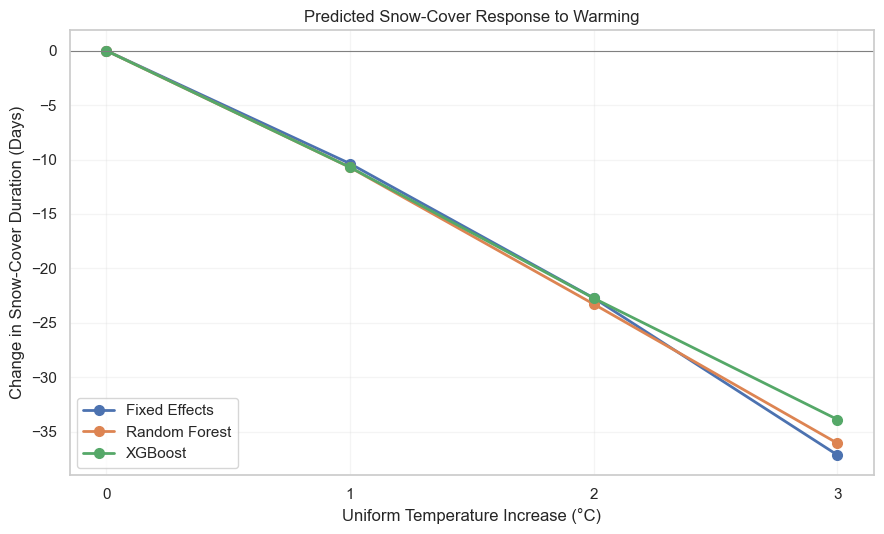

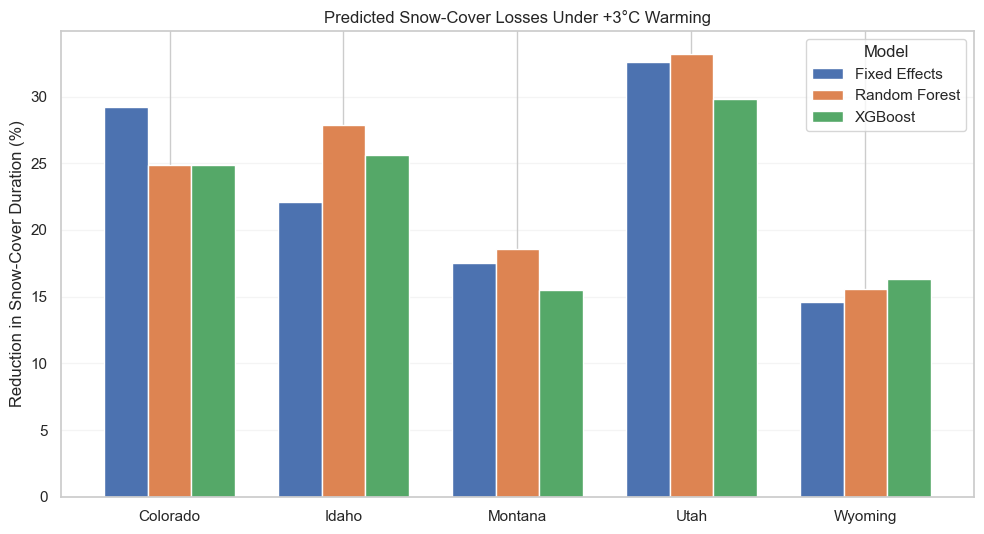

PASS: +3°C economic totals match corrected results.

CORRECTED MEAN SNOW-COVER CHANGES


,Fixed Effects,Random Forest,XGBoost
warming_C,,,
0,0.000,0.000,0.000000
1,-10.376,-10.721,-10.715000
2,-22.722,-23.279,-22.736000
3,-37.139,-36.058,-33.877998



CORRECTED STATE LOSSES AT +3°C


,Fixed Effects,Random Forest,XGBoost
state,,,
Colorado,29.22,24.88,24.900000
Idaho,22.07,27.84,25.660000
Montana,17.55,18.54,15.530000
Utah,32.57,33.23,29.790001
Wyoming,14.63,15.59,16.309999



CORRECTED ECONOMIC TOTALS AT +3°C


Model
Fixed Effects   -243.18
Random Forest   -224.03
XGBoost         -215.26
Name: va_change_millions, dtype: float64


Figures 4 and 5 regenerated successfully.
Output directory: /Users/evabenson/Files/thesis/snow_ml/code/thesis_outputs


In [261]:

# ============================================================
# REGENERATE FINAL THESIS WARMING FIGURES
# Run AFTER the corrected scenario reconciliation cell
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("thesis_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

models = ["Fixed Effects", "Random Forest", "XGBoost"]

# ------------------------------------------------------------
# 1. Verify corrected inputs are available
# ------------------------------------------------------------

required_objects = [
    "snow_predictions",
    "state_pct_summary",
    "economic_results",
    "economic_totals"
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing objects: {missing}. "
        "Run the final prediction and reconciliation cells first."
    )

# Check that change columns match the final predictions
df = snow_predictions.copy()

for model in models:
    expected = df[model] - df[f"{model}_baseline"]
    actual = df[f"{model}_change"]

    np.testing.assert_allclose(
        actual.to_numpy(dtype=float),
        expected.to_numpy(dtype=float),
        atol=1e-5,
        rtol=1e-6,
        err_msg=f"Outdated change values for {model}"
    )

print("PASS: All warming changes match final predictions.")

# ------------------------------------------------------------
# 2. Figure 4: Mean snow-cover response to warming
# ------------------------------------------------------------

mean_changes = (
    df.groupby("warming_C")[
        [f"{m}_change" for m in models]
    ]
    .mean()
    .rename(columns={
        f"{m}_change": m for m in models
    })
)

fig, ax = plt.subplots(figsize=(9, 5.5))

for model in models:
    ax.plot(
        mean_changes.index,
        mean_changes[model],
        marker="o",
        linewidth=2,
        markersize=7,
        label=model
    )

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks([0, 1, 2, 3])
ax.set_xlabel("Uniform Temperature Increase (°C)")
ax.set_ylabel("Change in Snow-Cover Duration (Days)")
ax.set_title("Predicted Snow-Cover Response to Warming")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    output_dir / "figure_4_warming_response.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    output_dir / "figure_4_warming_response.pdf",
    bbox_inches="tight"
)
plt.show()

mean_changes.to_csv(
    output_dir / "figure_4_warming_response_data.csv"
)

# ------------------------------------------------------------
# 3. Figure 5: State snow-cover losses at +3°C
# ------------------------------------------------------------

state_order = [
    "Colorado", "Idaho", "Montana",
    "Utah", "Wyoming"
]

state_3c = (
    state_pct_summary.loc[
        state_pct_summary["warming_C"] == 3
    ]
    .set_index("state")
    .reindex(state_order)
)

assert state_3c[models].notna().all().all()

# Positive values represent losses
state_losses = -state_3c[models]

ax = state_losses.plot(
    kind="bar",
    figsize=(10, 5.5),
    width=0.75,
    rot=0
)

ax.set_title("Predicted Snow-Cover Losses Under +3°C Warming")
ax.set_ylabel("Reduction in Snow-Cover Duration (%)")
ax.set_xlabel("")
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    output_dir / "figure_5_state_warming.png",
    dpi=300, bbox_inches="tight"
)
plt.savefig(
    output_dir / "figure_5_state_warming.pdf",
    bbox_inches="tight"
)
plt.show()

state_losses.to_csv(
    output_dir / "figure_5_state_warming_data.csv"
)

# ------------------------------------------------------------
# 4. Check the corrected economic totals
# ------------------------------------------------------------

central = economic_totals.loc[
    (economic_totals["warming_C"] == 3)
    & np.isclose(economic_totals["elasticity"], 0.5)
].set_index("Model")["va_change_millions"]

expected_totals = {
    "Fixed Effects": -243.18,
    "Random Forest": -224.03,
    "XGBoost": -215.26
}

for model, expected in expected_totals.items():
    assert np.isclose(
        central.loc[model], expected, atol=0.02
    ), f"Economic total mismatch for {model}"

print("PASS: +3°C economic totals match corrected results.")

print("\nCORRECTED MEAN SNOW-COVER CHANGES")
display(mean_changes.round(3))

print("\nCORRECTED STATE LOSSES AT +3°C")
display(state_losses.round(2))

print("\nCORRECTED ECONOMIC TOTALS AT +3°C")
display(central.round(2))

print("\nFigures 4 and 5 regenerated successfully.")
print("Output directory:", output_dir.resolve())


In [271]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.home() / "Files/thesis/snow_ml/ml_model"

historical = pd.read_csv(
    DATA_DIR / "county_snodas_10cm_30cm_merged.csv",
    dtype={"fips": str}
)

print("Historical data shape:", historical.shape)
display(historical.head())
print("\nColumns:")
print(historical.columns.tolist())

Historical data shape: (400, 55)


,fips,state,county,year,season_days,valid_days_all,snow_days_0cm_all,snow_days_5cm_all,snow_days_10cm_all,mean_depth_cm_all,peak_depth_cm_all,valid_fraction_all,valid_days_2000m,snow_days_0cm_2000m,snow_days_5cm_2000m,snow_days_10cm_2000m,mean_depth_cm_2000m,peak_depth_cm_2000m,valid_fraction_2000m,tmin_djf_all,tmax_djf_all,tmin_mar_all,tmax_mar_all,tmin_apr_all,tmax_apr_all,tmax_mar_apr_all,precip_on_all,precip_djf_all,precip_mar_apr_all,positive_degree_days_all,freezing_degree_days_all,thaw_days_all,precip_freezing_fraction_all,tmin_djf_2000m,tmax_djf_2000m,tmin_mar_2000m,tmax_mar_2000m,tmin_apr_2000m,tmax_apr_2000m,tmax_mar_apr_2000m,precip_on_2000m,precip_djf_2000m,precip_mar_apr_2000m,positive_degree_days_2000m,freezing_degree_days_2000m,thaw_days_2000m,precip_freezing_fraction_2000m,mean_elev_m,mean_slope_deg,mean_northness,mean_eastness,frac_above_2000m,frac_above_2500m,frac_above_3000m,snow_days_30cm_2000m
0,08019,8,Clear Creek,2004,182.0,181.0,132.650279,104.443938,87.287497,19.877661,55.760574,0.994505,181.0,132.650279,104.443938,87.287497,19.877661,55.760574,0.994505,-11.653221,0.003829,-5.960181,7.531071,-4.878662,6.810956,7.176916,57.562847,113.851116,160.889241,190.044034,772.667660,121.433451,0.765196,-11.653221,0.003829,-5.960181,7.531071,-4.878662,6.810956,7.176916,57.562847,113.851116,160.889241,190.044034,772.667660,121.433451,0.765196,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648,46.538443
1,08019,8,Clear Creek,2005,181.0,181.0,160.005379,142.899208,124.563982,31.616239,77.368466,1.000000,181.0,160.005379,142.899208,124.563982,31.616239,77.368466,1.000000,-9.884569,1.117174,-9.884653,2.496389,-5.073381,7.907022,5.157356,130.036601,103.045510,171.853327,141.619301,696.855656,122.532237,0.790175,-9.884569,1.117174,-9.884653,2.496389,-5.073381,7.907022,5.157356,130.036601,103.045510,171.853327,141.619301,696.855656,122.532237,0.790175,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648,75.988011
2,08019,8,Clear Creek,2006,181.0,181.0,143.048528,125.487662,112.671397,41.930182,86.753492,1.000000,181.0,143.048528,125.487662,112.671397,41.930182,86.753492,1.000000,-11.913444,-0.780809,-9.760965,2.840254,-4.122998,9.235791,5.985600,137.529041,158.788496,111.211801,198.153361,849.963505,112.628475,0.856948,-11.913444,-0.780809,-9.760965,2.840254,-4.122998,9.235791,5.985600,137.529041,158.788496,111.211801,198.153361,849.963505,112.628475,0.856948,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648,85.953361
3,08019,8,Clear Creek,2007,181.0,179.0,159.488491,149.526334,142.598728,49.075501,102.587394,0.988950,179.0,159.488491,149.526334,142.598728,49.075501,102.587394,0.988950,-11.679025,-0.322547,-6.167244,6.229165,-4.797217,7.345446,6.778156,136.555533,188.867962,175.945961,205.403530,772.278725,118.584902,0.769120,-11.679025,-0.322547,-6.167244,6.229165,-4.797217,7.345446,6.778156,136.555533,188.867962,175.945961,205.403530,772.278725,118.584902,0.769120,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648,114.117900
4,08019,8,Clear Creek,2008,182.0,181.0,160.387652,147.336697,136.615701,54.015832,109.332021,0.994505,181.0,160.387652,147.336697,136.615701,54.015832,109.332021,0.994505,-13.371810,-2.438916,-10.775306,1.767495,-7.164861,5.779998,3.740857,59.704756,216.459066,127.808279,142.062175,1029.544109,99.928627,0.883858,-13.371810,-2.438916,-10.775306,1.767495,-7.164861,5.779998,3.740857,59.704756,216.459066,127.808279,142.062175,1029.544109,99.928627,0.883858,3179.410654,16.047526,0.044903,0.186441,1.0,0.937831,0.630648,107.698632



Columns:
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'precip_freezing_fraction_2000m', 'mean_elev_m', 'mean_slope_deg', 'mean_northness'

In [272]:
ROOT = Path.home() / "Files/thesis/snow_ml"

print("Warming scenario CSV files:")
for file in ROOT.rglob("*warming*.csv"):
    print(file)

print("\nExisting warming-related notebook variables:")
for name, value in list(globals().items()):
    if (
        isinstance(value, pd.DataFrame)
        and any(term in name.lower()
                for term in ["warm", "scenario"])
    ):
        print(name, value.shape, value.columns.tolist())

Warming scenario CSV files:
/Users/evabenson/Files/thesis/snow_ml/ml_model/snow_warming_predictions.csv
/Users/evabenson/Files/thesis/snow_ml/ml_model/warming_scenarios_utah.csv
/Users/evabenson/Files/thesis/snow_ml/ml_model/warming_scenarios_idaho.csv
/Users/evabenson/Files/thesis/snow_ml/ml_model/state_warming_economic_impacts.csv
/Users/evabenson/Files/thesis/snow_ml/ml_model/warming_scenarios_wyoming.csv
/Users/evabenson/Files/thesis/snow_ml/ml_model/county_warming_scenarios_all.csv
/Users/evabenson/Files/thesis/snow_ml/ml_model/warming_scenarios_colorado.csv
/Users/evabenson/Files/thesis/snow_ml/ml_model/warming_scenarios_montana.csv
/Users/evabenson/Files/thesis/snow_ml/code/warming_predictions_thesis_verified.csv
/Users/evabenson/Files/thesis/snow_ml/code/thesis_outputs/table_3_warming_results.csv
/Users/evabenson/Files/thesis/snow_ml/code/thesis_outputs/figure_5_state_warming_data.csv
/Users/evabenson/Files/thesis/snow_ml/code/thesis_outputs/figure_6_county_warming_data.csv
/Us

In [273]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path.home() / "Files/thesis/snow_ml/ml_model"

# Load 30 cm snow-depth data
snow30 = pd.read_csv(
    DATA_DIR / "county_snodas_10cm_30cm_merged.csv",
    dtype={"fips": str}
)

# Ensure matching FIPS formatting
snow30["fips"] = snow30["fips"].str.zfill(5)

# Check data
print("30 cm data:", snow30.shape)
print("30 cm columns:", snow30.columns.tolist())

# Check existing warming inputs
print("\nWarming scenarios:", warming_all.shape)
print(warming_all[[
    "fips", "year",
    "pdd_0", "pdd_1", "pdd_2", "pdd_3"
]].head())

# Find existing fitted model objects
print("\nExisting model objects:")
for name, obj in list(globals().items()):
    if hasattr(obj, "predict") and hasattr(obj, "fit"):
        print(name, type(obj).__name__)

30 cm data: (400, 55)
30 cm columns: ['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'precip_freezing_fraction_2000m', 'mean_elev_m', 'mean_s

In [274]:
import pandas as pd
import numpy as np
from sklearn.base import clone

# Make sure identifiers match
snow30["fips"] = snow30["fips"].astype(str).str.zfill(5)
warming_all["fips"] = warming_all["fips"].astype(str).str.zfill(5)

# Outcome
TARGET_30 = "snow_days_30cm_2000m"

# Original fixed-effects predictors
FE_FEATURES = [
    "fips",
    "positive_degree_days_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

# Original machine-learning predictors
ML_FEATURES = [
    "tmin_djf_2000m",
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmin_apr_2000m",
    "tmax_apr_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m",
    "mean_elev_m",
    "mean_slope_deg",
    "mean_northness",
    "mean_eastness",
    "frac_above_2000m",
    "frac_above_2500m",
    "frac_above_3000m"
]

# Preserve original fitted model settings
fe30 = clone(fe_thesis)
rf30 = clone(rf_thesis)
xgb30 = clone(xgb_thesis)

# Fit models
fe30.fit(snow30[FE_FEATURES], snow30[TARGET_30])
rf30.fit(snow30[ML_FEATURES], snow30[TARGET_30])
xgb30.fit(snow30[ML_FEATURES], snow30[TARGET_30])

print("All three 30 cm models fitted successfully.")

All three 30 cm models fitted successfully.


In [275]:
# Merge the existing warming inputs with the 30 cm panel
base = snow30.merge(
    warming_all[
        ["fips", "year"] +
        [f"{v}_{w}" for v in ["pdd", "fdd", "thaw"]
         for w in range(4)]
    ],
    on=["fips", "year"],
    how="left",
    validate="one_to_one"
)

assert len(base) == 400
assert base["pdd_0"].notna().all()

# Check original baseline PDD matches scenario baseline
print(
    "Mean absolute baseline PDD difference:",
    np.mean(
        np.abs(
            base["positive_degree_days_2000m"] -
            base["pdd_0"]
        )
    )
)

def make_warming_features(data, warming_c):

    scenario = data.copy()

    scenario["positive_degree_days_2000m"] = (
        scenario[f"pdd_{warming_c}"]
    )

    scenario["freezing_degree_days_2000m"] = (
        scenario[f"fdd_{warming_c}"]
    )

    scenario["thaw_days_2000m"] = (
        scenario[f"thaw_{warming_c}"]
    )

    # Apply uniform temperature shift to daily-derived
    # seasonal mean/min/max temperature summaries.
    temp_columns = [
        "tmin_djf_2000m",
        "tmax_djf_2000m",
        "tmin_mar_2000m",
        "tmax_mar_2000m",
        "tmin_apr_2000m",
        "tmax_apr_2000m"
    ]

    for col in temp_columns:
        scenario[col] += warming_c

    return scenario

Mean absolute baseline PDD difference: 3.9790393202565614e-15


In [276]:
# Baseline predictions using historical weather
baseline_fe = fe30.predict(base[FE_FEATURES])
baseline_rf = rf30.predict(base[ML_FEATURES])
baseline_xgb = xgb30.predict(base[ML_FEATURES])

results = []

for warming_c in [0, 1, 2, 3]:

    scenario = make_warming_features(base, warming_c)

    predictions = {
        "Fixed Effects": fe30.predict(scenario[FE_FEATURES]),
        "Random Forest": rf30.predict(scenario[ML_FEATURES]),
        "XGBoost": xgb30.predict(scenario[ML_FEATURES])
    }

    baselines = {
        "Fixed Effects": baseline_fe,
        "Random Forest": baseline_rf,
        "XGBoost": baseline_xgb
    }

    for model_name, predicted in predictions.items():

        temp = base[["fips", "county", "state", "year"]].copy()

        temp["Model"] = model_name
        temp["warming_C"] = warming_c
        temp["baseline_snow_days"] = baselines[model_name]
        temp["scenario_snow_days"] = predicted

        temp["change_days"] = (
            temp["scenario_snow_days"] -
            temp["baseline_snow_days"]
        )

        results.append(temp)

warming30_predictions = pd.concat(
    results, ignore_index=True
)

warming30_summary = (
    warming30_predictions
    .groupby(["Model", "warming_C"])
    .agg(
        baseline_days=("baseline_snow_days", "mean"),
        scenario_days=("scenario_snow_days", "mean"),
        change_days=("change_days", "mean")
    )
    .reset_index()
)

warming30_summary["change_pct"] = (
    100 *
    warming30_summary["change_days"] /
    warming30_summary["baseline_days"]
)

display(warming30_summary.round(3))

,Model,warming_C,baseline_days,scenario_days,change_days,change_pct
0,Fixed Effects,0,116.237,116.237,0.000,0.000
1,Fixed Effects,1,116.237,105.700,-10.537,-9.065
2,Fixed Effects,2,116.237,93.164,-23.073,-19.850
3,Fixed Effects,3,116.237,78.523,-37.714,-32.446
4,Random Forest,0,116.279,116.279,-0.000,-0.000
5,Random Forest,1,116.279,104.862,-11.417,-9.819
6,Random Forest,2,116.279,92.474,-23.805,-20.473
7,Random Forest,3,116.279,80.228,-36.051,-31.004
8,XGBoost,0,116.240,116.240,0.000,0.000
9,XGBoost,1,116.240,105.145,-11.095,-9.545


In [277]:
warming30_predictions.to_csv(
    DATA_DIR / "snow_30cm_warming_predictions.csv",
    index=False
)

warming30_summary.to_csv(
    DATA_DIR / "snow_30cm_warming_summary.csv",
    index=False
)

print("Saved both files to:", DATA_DIR)

Saved both files to: /Users/evabenson/Files/thesis/snow_ml/ml_model


In [278]:
print("FE model:", fe_thesis.get_params())
print("\nRF model:", rf_thesis.get_params())
print("\nXGBoost model:", xgb_thesis.get_params())

print("\nBaseline PDD agreement:")
print(
    np.mean(
        np.abs(
            base["positive_degree_days_2000m"] - base["pdd_0"]
        )
    )
)

FE model: {'memory': None, 'steps': [('preprocessor', ColumnTransformer(transformers=[('county',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['fips']),
                                ('climate', 'passthrough',
                                 ['positive_degree_days_2000m',
                                  'precip_djf_2000m',
                                  'precip_mar_apr_2000m'])])), ('regression', LinearRegression())], 'transform_input': None, 'verbose': False, 'preprocessor': ColumnTransformer(transformers=[('county',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['fips']),
                                ('climate', 'passthrough',
                                 ['positive_degree_days_2000m',
                                  'precip_djf_2000m',
                                  'precip_mar_apr_2000m'])]), 'regression': LinearRegression(), 'preprocessor__fo

In [279]:
state30 = (
    warming30_predictions
    .groupby(["state", "Model", "warming_C"])
    .agg(
        baseline_days=("baseline_snow_days", "mean"),
        scenario_days=("scenario_snow_days", "mean"),
        change_days=("change_days", "mean")
    )
    .reset_index()
)

state30["change_pct"] = (
    100 * state30["change_days"] / state30["baseline_days"]
)

# Show +3°C results
display(
    state30[state30["warming_C"] == 3]
    .sort_values(["state", "Model"])
    .round(2)
)

# Save
state30.to_csv(
    DATA_DIR / "snow_30cm_state_warming.csv",
    index=False
)

,state,Model,warming_C,baseline_days,scenario_days,change_days,change_pct
3,8,Fixed Effects,3,99.21,60.82,-38.39,-38.70
7,8,Random Forest,3,100.45,69.77,-30.68,-30.54
11,8,XGBoost,3,100.28,70.72,-29.56,-29.48
15,16,Fixed Effects,3,131.57,96.78,-34.79,-26.44
19,16,Random Forest,3,130.88,87.41,-43.46,-33.21
23,16,XGBoost,3,131.73,89.55,-42.18,-32.02
27,30,Fixed Effects,3,150.64,120.79,-29.85,-19.82
31,30,Random Forest,3,149.62,113.96,-35.66,-23.84
35,30,XGBoost,3,150.13,118.93,-31.21,-20.79
39,49,Fixed Effects,3,112.79,67.76,-45.04,-39.93


In [280]:
# Original 10 cm warming predictions
state10 = (
    snow_scenarios
    .groupby(["state", "warming_C"])[
        ["Fixed Effects_change",
         "Random Forest_change",
         "XGBoost_change",
         "Fixed Effects_baseline",
         "Random Forest_baseline",
         "XGBoost_baseline"]
    ]
    .mean()
    .reset_index()
)

# Calculate percentage changes
for model in ["Fixed Effects", "Random Forest", "XGBoost"]:
    state10[f"{model}_pct"] = (
        100 *
        state10[f"{model}_change"] /
        state10[f"{model}_baseline"]
    )

# Reshape for comparison
state10_long = state10.melt(
    id_vars=["state", "warming_C"],
    value_vars=[
        "Fixed Effects_pct",
        "Random Forest_pct",
        "XGBoost_pct"
    ],
    var_name="Model",
    value_name="change_pct_10cm"
)

state10_long["Model"] = (
    state10_long["Model"].str.replace("_pct", "", regex=False)
)

# Join 10 cm and 30 cm results
comparison = state30.merge(
    state10_long,
    on=["state", "warming_C", "Model"],
    how="left"
)

comparison["difference_pp"] = (
    comparison["change_pct"] -
    comparison["change_pct_10cm"]
)

# Display +3°C comparison
display(
    comparison.loc[
        comparison["warming_C"] == 3,
        [
            "state", "Model",
            "change_pct_10cm",
            "change_pct",
            "difference_pp"
        ]
    ].round(2)
)

,state,Model,change_pct_10cm,change_pct,difference_pp
3,8,Fixed Effects,-27.33,-38.70,-11.37
7,8,Random Forest,-22.30,-30.54,-8.24
11,8,XGBoost,-23.69,-29.48,-5.79
15,16,Fixed Effects,-20.73,-26.44,-5.71
19,16,Random Forest,-23.43,-33.21,-9.78
23,16,XGBoost,-25.58,-32.02,-6.44
27,30,Fixed Effects,-16.38,-19.82,-3.43
31,30,Random Forest,-18.05,-23.84,-5.79
35,30,XGBoost,-15.68,-20.79,-5.11
39,49,Fixed Effects,-30.65,-39.93,-9.28


In [282]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. Define the three fixed-effects specifications
# --------------------------------------------------

fe_specs = {
    "FE1 Baseline": [
        "positive_degree_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],
    "FE2 Expanded": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],
    "FE3 Nonlinear": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "pdd_squared",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ]
}

# Work on a copy so the original models are unchanged
fe_compare_df = model_df.copy()

fe_compare_df["pdd_squared"] = (
    fe_compare_df["positive_degree_days_2000m"] ** 2
)

TARGET_FE = "snow_days_10cm_2000m"

# Use the same observations for every specification
required = (
    [TARGET_FE, "fips", "year"]
    + list(dict.fromkeys(
        col for cols in fe_specs.values() for col in cols
    ))
)

fe_compare_df = (
    fe_compare_df
    .dropna(subset=required)
    .reset_index(drop=True)
)

fe_compare_df["fips"] = (
    fe_compare_df["fips"].astype(str).str.zfill(5)
)

print("Observations:", len(fe_compare_df))
print("Counties:", fe_compare_df["fips"].nunique())
print("Years:", fe_compare_df["year"].nunique())


# --------------------------------------------------
# 2. Build a county fixed-effects model
# --------------------------------------------------

def make_fe_model(features):

    preprocessor = ColumnTransformer([
        (
            "county",
            OneHotEncoder(handle_unknown="ignore"),
            ["fips"]
        ),
        (
            "climate",
            StandardScaler(),
            features
        )
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ])


def evaluate_fe(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }


# --------------------------------------------------
# 3. Leave-one-year-out validation
# --------------------------------------------------

logo = LeaveOneGroupOut()

loyo_results = []

for name, features in fe_specs.items():

    X = fe_compare_df[features + ["fips"]]
    y = fe_compare_df[TARGET_FE]

    predictions = np.full(len(fe_compare_df), np.nan)

    for train_idx, test_idx in logo.split(
        X, y, groups=fe_compare_df["year"]
    ):

        model = make_fe_model(features)

        model.fit(
            X.iloc[train_idx],
            y.iloc[train_idx]
        )

        predictions[test_idx] = model.predict(
            X.iloc[test_idx]
        )

    fe_compare_df[
        "loyo_" + name.replace(" ", "_")
    ] = predictions

    metrics = evaluate_fe(y, predictions)

    loyo_results.append({
        "Model": name,
        **metrics
    })

loyo_table = pd.DataFrame(loyo_results)

print("\nLEAVE-ONE-YEAR-OUT RESULTS")
print(loyo_table.round(3).to_string(index=False))


# --------------------------------------------------
# 4. Forward-chaining validation
# Same periods as your existing notebook
# --------------------------------------------------

folds = [
    (2013, 2014, 2016),
    (2016, 2017, 2019),
    (2019, 2020, 2023)
]

forward_results = []

for name, features in fe_specs.items():

    predictions = np.full(len(fe_compare_df), np.nan)

    for train_end, test_start, test_end in folds:

        train_mask = fe_compare_df["year"] <= train_end

        test_mask = fe_compare_df["year"].between(
            test_start, test_end
        )

        model = make_fe_model(features)

        model.fit(
            fe_compare_df.loc[
                train_mask, features + ["fips"]
            ],
            fe_compare_df.loc[train_mask, TARGET_FE]
        )

        predictions[test_mask.to_numpy()] = model.predict(
            fe_compare_df.loc[
                test_mask, features + ["fips"]
            ]
        )

    fe_compare_df[
        "forward_" + name.replace(" ", "_")
    ] = predictions

    valid = np.isfinite(predictions)

    metrics = evaluate_fe(
        fe_compare_df.loc[valid, TARGET_FE],
        predictions[valid]
    )

    forward_results.append({
        "Model": name,
        "N": int(valid.sum()),
        **metrics
    })

forward_table = pd.DataFrame(forward_results)

print("\nFORWARD-CHAINING RESULTS")
print(forward_table.round(3).to_string(index=False))


# --------------------------------------------------
# 5. Combined comparison
# --------------------------------------------------

loyo_display = loyo_table.copy()
loyo_display["Validation"] = "Leave-one-year-out"

forward_display = forward_table.copy()
forward_display["Validation"] = "Forward-chaining"

comparison = pd.concat(
    [loyo_display, forward_display],
    ignore_index=True
)

comparison = comparison[
    ["Validation", "Model", "R2", "MAE", "RMSE"]
]

print("\nFINAL MODEL COMPARISON")
print(comparison.round(3).to_string(index=False))


# --------------------------------------------------
# 6. Fit all three models on the full historical data
# For later scenario analysis, not validation
# --------------------------------------------------

fitted_fe_models = {}

for name, features in fe_specs.items():

    model = make_fe_model(features)

    model.fit(
        fe_compare_df[features + ["fips"]],
        fe_compare_df[TARGET_FE]
    )

    fitted_fe_models[name] = model

print("\nAll three full-sample FE models fitted.")


Observations: 400
Counties: 20
Years: 20

LEAVE-ONE-YEAR-OUT RESULTS
        Model    R2   MAE   RMSE
 FE1 Baseline 0.791 9.480 13.563
 FE2 Expanded 0.804 9.247 13.144
FE3 Nonlinear 0.803 9.297 13.191

FORWARD-CHAINING RESULTS
        Model   N    R2   MAE   RMSE
 FE1 Baseline 200 0.795 9.453 13.322
 FE2 Expanded 200 0.819 8.892 12.501
FE3 Nonlinear 200 0.786 9.706 13.614

FINAL MODEL COMPARISON
        Validation         Model    R2   MAE   RMSE
Leave-one-year-out  FE1 Baseline 0.791 9.480 13.563
Leave-one-year-out  FE2 Expanded 0.804 9.247 13.144
Leave-one-year-out FE3 Nonlinear 0.803 9.297 13.191
  Forward-chaining  FE1 Baseline 0.795 9.453 13.322
  Forward-chaining  FE2 Expanded 0.819 8.892 12.501
  Forward-chaining FE3 Nonlinear 0.786 9.706 13.614

All three full-sample FE models fitted.


In [284]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ============================================================
# 1. Extract original and new forward-chaining predictions
# ============================================================

# Original forward-chaining results
old = forward_df[
    ["fips", "year", TARGET, "forward_fe"]
].copy()

# New FE1 forward-chaining results
new = fe_compare_df[
    ["fips", "year", TARGET_FE, "forward_FE1_Baseline"]
].copy()

# Rename columns before merging to avoid duplicate-name issues
old = old.rename(columns={
    TARGET: "actual_old",
    "forward_fe": "prediction_old"
})

new = new.rename(columns={
    TARGET_FE: "actual_new",
    "forward_FE1_Baseline": "prediction_new"
})

# Standardize county identifiers
old["fips"] = old["fips"].astype(str).str.zfill(5)
new["fips"] = new["fips"].astype(str).str.zfill(5)

# ============================================================
# 2. Merge by county and year
# ============================================================

check = old.merge(
    new,
    on=["fips", "year"],
    how="inner",
    validate="one_to_one"
)

# Keep observations with predictions from both models
check = check.dropna(
    subset=[
        "actual_old",
        "actual_new",
        "prediction_old",
        "prediction_new"
    ]
).copy()

print("=" * 60)
print("FORWARD-CHAINING VERIFICATION")
print("=" * 60)

print("\nMatched observations:", len(check))
print("Unique counties:", check["fips"].nunique())
print("Years:", sorted(check["year"].unique()))

# ============================================================
# 3. Calculate evaluation metrics
# ============================================================

def calculate_metrics(actual, predicted):

    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }


old_metrics = calculate_metrics(
    check["actual_old"],
    check["prediction_old"]
)

new_metrics = calculate_metrics(
    check["actual_new"],
    check["prediction_new"]
)

comparison = pd.DataFrame([
    {
        "Model": "Original FE",
        **old_metrics
    },
    {
        "Model": "New FE1 Baseline",
        **new_metrics
    }
])

print("\nMODEL PERFORMANCE COMPARISON")
print(comparison.round(4).to_string(index=False))

# ============================================================
# 4. Check whether observed snow values match
# ============================================================

check["actual_difference"] = (
    check["actual_old"] -
    check["actual_new"]
)

print("\nOBSERVED SNOW-DAY COMPARISON")

print(
    "Maximum absolute difference:",
    check["actual_difference"].abs().max()
)

print(
    "Mean absolute difference:",
    check["actual_difference"].abs().mean()
)

# ============================================================
# 5. Compare individual predictions
# ============================================================

check["prediction_difference"] = (
    check["prediction_old"] -
    check["prediction_new"]
)

print("\nPREDICTION COMPARISON")

print(
    "Maximum absolute prediction difference:",
    check["prediction_difference"].abs().max()
)

print(
    "Mean absolute prediction difference:",
    check["prediction_difference"].abs().mean()
)

print(
    "Prediction correlation:",
    check["prediction_old"].corr(
        check["prediction_new"]
    )
)

# ============================================================
# 6. Show observations with largest differences
# ============================================================

largest_differences = (
    check.assign(
        abs_difference=check["prediction_difference"].abs()
    )
    .sort_values(
        "abs_difference",
        ascending=False
    )
    .head(10)
)

print("\n10 LARGEST PREDICTION DIFFERENCES")

print(
    largest_differences[
        [
            "fips",
            "year",
            "actual_old",
            "actual_new",
            "prediction_old",
            "prediction_new",
            "prediction_difference"
        ]
    ].round(4).to_string(index=False)
)

# ============================================================
# 7. Compare performance by validation period
# ============================================================

def identify_fold(year):

    if 2014 <= year <= 2016:
        return "2014-2016"

    elif 2017 <= year <= 2019:
        return "2017-2019"

    elif 2020 <= year <= 2023:
        return "2020-2023"

    return "Other"


check["fold"] = check["year"].apply(identify_fold)

fold_results = []

for fold, group in check.groupby("fold"):

    for model_name, actual_col, pred_col in [
        ("Original FE", "actual_old", "prediction_old"),
        ("New FE1", "actual_new", "prediction_new")
    ]:

        results = calculate_metrics(
            group[actual_col],
            group[pred_col]
        )

        fold_results.append({
            "Fold": fold,
            "Model": model_name,
            "N": len(group),
            **results
        })


fold_table = pd.DataFrame(fold_results)

print("\nPERFORMANCE BY VALIDATION PERIOD")

print(
    fold_table.round(4).to_string(index=False)
)

# ============================================================
# 8. Final consistency checks
# ============================================================

actual_match = np.allclose(
    check["actual_old"],
    check["actual_new"],
    atol=1e-8,
    rtol=1e-8
)

prediction_match = np.allclose(
    check["prediction_old"],
    check["prediction_new"],
    atol=1e-6,
    rtol=1e-6
)

print("\n" + "=" * 60)
print("FINAL VERIFICATION")
print("=" * 60)

print("Observed values match:", actual_match)
print("Predictions match:", prediction_match)

if actual_match and prediction_match:
    print(
        "\nRESULT: Both implementations produce equivalent "
        "observations and predictions."
    )

elif not actual_match:
    print(
        "\nRESULT: The observed snow-cover values differ. "
        "Check the source data and preprocessing."
    )

else:
    print(
        "\nRESULT: Observed values match, but predictions differ. "
        "Check model specification, training samples, "
        "and preprocessing."
    )

if len(check) != 200:
    print(
        "\nWARNING: Expected 200 matched forward-validation "
        "observations. Check missing or unmatched records."
    )


FORWARD-CHAINING VERIFICATION

Matched observations: 200
Unique counties: 20
Years: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

MODEL PERFORMANCE COMPARISON
           Model     R2    MAE    RMSE
     Original FE 0.7948 9.4534 13.3215
New FE1 Baseline 0.7948 9.4534 13.3215

OBSERVED SNOW-DAY COMPARISON
Maximum absolute difference: 0.0
Mean absolute difference: 0.0

PREDICTION COMPARISON
Maximum absolute prediction difference: 9.415706500703891e-06
Mean absolute prediction difference: 1.0713685995256129e-06
Prediction correlation: 0.9999999999999988

10 LARGEST PREDICTION DIFFERENCES
 fips  year  actual_old  actual_new  prediction_old  prediction_new  prediction_difference
30029  2014    178.0071    178.0071        174.1579        174.1579                   -0.0
30029  2016    174.2177    174.2177        156.1111        156.1111                   -0.0
08067  2015     61.

In [285]:

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# ============================================================
# 1. Define model specifications
# ============================================================

target = "snow_days_10cm_2000m"

fe_specs = {
    "FE1 Baseline": [
        "positive_degree_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],
    "FE2 Expanded": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ]
}

state_names = {
    "08": "Colorado",
    "16": "Idaho",
    "30": "Montana",
    "49": "Utah",
    "56": "Wyoming"
}

# ============================================================
# 2. Prepare historical and warming datasets
# ============================================================

historical = model_df.copy()
warming = warming_model_df.copy()

for df in [historical, warming]:
    df["fips"] = df["fips"].astype(str).str.zfill(5)
    df["year"] = df["year"].astype(int)

warming["warming_C"] = warming["warming_C"].astype(int)

required = sorted(set(
    feature
    for features in fe_specs.values()
    for feature in features
))

historical = historical.dropna(
    subset=["fips", "year", target] + required
).copy()

warming = warming.dropna(
    subset=["fips", "year", "warming_C"] + required
).copy()

assert len(historical) == 400, (
    f"Expected 400 historical observations; got {len(historical)}"
)

assert len(warming) == 1600, (
    f"Expected 1600 warming observations; got {len(warming)}"
)

assert not warming.duplicated(
    ["fips", "year", "warming_C"]
).any()

assert set(warming["warming_C"]) == {0, 1, 2, 3}

# Ensure scenario baseline matches historical model inputs
baseline_check = warming[
    warming["warming_C"] == 0
].merge(
    historical[["fips", "year"] + required],
    on=["fips", "year"],
    suffixes=("_scenario", "_historical"),
    validate="one_to_one"
)

print("BASELINE INPUT VALIDATION")
print("=" * 65)

for feature in required:
    difference = (
        baseline_check[f"{feature}_scenario"] -
        baseline_check[f"{feature}_historical"]
    ).abs()

    print(
        f"{feature:35s} "
        f"Mean difference: {difference.mean():.6f}  "
        f"Max difference: {difference.max():.6f}"
    )

# ============================================================
# 3. Fit both fixed-effects models
# ============================================================

def build_fe_model(features):

    preprocessing = ColumnTransformer(
        transformers=[
            (
                "county",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                ["fips"]
            ),
            (
                "climate",
                StandardScaler(),
                features
            )
        ]
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("regression", LinearRegression())
    ])


models = {}

for name, features in fe_specs.items():

    model = build_fe_model(features)

    model.fit(
        historical[["fips"] + features],
        historical[target]
    )

    models[name] = model

    print(f"\nFitted {name}")

# ============================================================
# 4. Predict snow-cover duration
# ============================================================

predictions = warming[
    ["fips", "year", "warming_C", "season_days"]
].copy()

predictions["state"] = (
    predictions["fips"].str[:2].map(state_names)
)

assert predictions["state"].notna().all()

for name, features in fe_specs.items():

    raw_predictions = models[name].predict(
        warming[["fips"] + features]
    )

    # Keep predicted snow days within the season
    predictions[name] = np.clip(
        raw_predictions,
        0,
        warming["season_days"].to_numpy()
    )

# ============================================================
# 5. Calculate changes relative to each model's baseline
# ============================================================

model_names = list(fe_specs.keys())

baseline = predictions.loc[
    predictions["warming_C"] == 0,
    ["fips", "year"] + model_names
].copy()

baseline = baseline.rename(
    columns={
        name: f"{name}_baseline"
        for name in model_names
    }
)

predictions = predictions.merge(
    baseline,
    on=["fips", "year"],
    validate="many_to_one"
)

for name in model_names:

    predictions[f"{name}_change"] = (
        predictions[name] -
        predictions[f"{name}_baseline"]
    )

# ============================================================
# 6. Overall warming results
# ============================================================

overall_rows = []

for warming_level, group in predictions.groupby("warming_C"):

    for name in model_names:

        baseline_mean = group[f"{name}_baseline"].mean()
        scenario_mean = group[name].mean()
        change_mean = group[f"{name}_change"].mean()

        overall_rows.append({
            "Warming_C": warming_level,
            "Model": name,
            "Baseline_days": baseline_mean,
            "Scenario_days": scenario_mean,
            "Change_days": change_mean,
            "Change_pct": (
                100 * change_mean / baseline_mean
                if baseline_mean > 0 else np.nan
            )
        })

overall_results = pd.DataFrame(overall_rows)

print("\n" + "=" * 65)
print("OVERALL WARMING RESULTS")
print("=" * 65)

print(
    overall_results.round(3).to_string(index=False)
)

# ============================================================
# 7. State-level warming results
# ============================================================

state_rows = []

for (state, warming_level), group in predictions.groupby(
    ["state", "warming_C"]
):

    if warming_level == 0:
        continue

    for name in model_names:

        baseline_mean = group[f"{name}_baseline"].mean()
        change_mean = group[f"{name}_change"].mean()

        state_rows.append({
            "State": state,
            "Warming_C": warming_level,
            "Model": name,
            "Baseline_days": baseline_mean,
            "Change_days": change_mean,
            "Change_pct": (
                100 * change_mean / baseline_mean
                if baseline_mean > 0 else np.nan
            )
        })

state_results_fe = pd.DataFrame(state_rows)

print("\n" + "=" * 65)
print("STATE-LEVEL SNOW-COVER CHANGES")
print("=" * 65)

print(
    state_results_fe[
        state_results_fe["Warming_C"] == 3
    ].round(2).to_string(index=False)
)

# ============================================================
# 8. Physical plausibility checks
# ============================================================

print("\n" + "=" * 65)
print("PHYSICAL PLAUSIBILITY CHECKS")
print("=" * 65)

for name in model_names:

    wide = predictions.pivot(
        index=["fips", "year"],
        columns="warming_C",
        values=name
    )

    # Count cases where more warming increases snow days
    increasing = (
        (wide[1] > wide[0] + 1e-6) |
        (wide[2] > wide[1] + 1e-6) |
        (wide[3] > wide[2] + 1e-6)
    )

    print(
        f"{name}: "
        f"{increasing.sum()} of {len(wide)} county-years "
        "have at least one increase in predicted snow days"
    )

# ============================================================
# 9. Compare new FE1 against original FE warming results
# ============================================================

if "snow_predictions" in globals():

    original_fe = snow_predictions[
        ["fips", "year", "warming_C", "Fixed Effects"]
    ].copy()

    original_fe["fips"] = (
        original_fe["fips"].astype(str).str.zfill(5)
    )

    comparison = predictions.merge(
        original_fe,
        on=["fips", "year", "warming_C"],
        validate="one_to_one"
    )

    difference = (
        comparison["FE1 Baseline"] -
        comparison["Fixed Effects"]
    ).abs()

    print("\n" + "=" * 65)
    print("ORIGINAL FE VS NEW FE1")
    print("=" * 65)

    print("Matched predictions:", len(comparison))
    print("Mean absolute difference:", difference.mean())
    print("Maximum absolute difference:", difference.max())

else:
    print(
        "\nOriginal snow_predictions not found. "
        "Skipping the FE1 reproduction check."
    )

# ============================================================
# 10. Save outputs
# ============================================================

output_folder = (
    Path.home() / "Files/thesis/snow_ml/ml_model"
)

output_folder.mkdir(parents=True, exist_ok=True)

predictions.to_csv(
    output_folder / "fe_warming_predictions.csv",
    index=False
)

overall_results.to_csv(
    output_folder / "fe_warming_overall.csv",
    index=False
)

state_results_fe.to_csv(
    output_folder / "fe_warming_by_state.csv",
    index=False
)

print("\nSaved all three FE warming output files.")


BASELINE INPUT VALIDATION
freezing_degree_days_2000m          Mean difference: 0.000000  Max difference: 0.000000
positive_degree_days_2000m          Mean difference: 0.000000  Max difference: 0.000000
precip_djf_2000m                    Mean difference: 0.000000  Max difference: 0.000000
precip_mar_apr_2000m                Mean difference: 0.000000  Max difference: 0.000000
thaw_days_2000m                     Mean difference: 0.000000  Max difference: 0.000000

Fitted FE1 Baseline

Fitted FE2 Expanded

OVERALL WARMING RESULTS
 Warming_C        Model  Baseline_days  Scenario_days  Change_days  Change_pct
         0 FE1 Baseline        141.125        141.125        0.000       0.000
         0 FE2 Expanded        141.109        141.109        0.000       0.000
         1 FE1 Baseline        141.125        130.769      -10.356      -7.338
         1 FE2 Expanded        141.109        129.634      -11.474      -8.132
         2 FE1 Baseline        141.125        118.428      -22.697     -

In [286]:

comparison["difference"] = (
    comparison["FE1 Baseline"] -
    comparison["Fixed Effects"]
)

print("Observations differing by more than 0.01 days:",
      (comparison["difference"].abs() > 0.01).sum())

print("Observations differing by more than 1 day:",
      (comparison["difference"].abs() > 1).sum())

print("\nLargest differences:")
print(
    comparison.loc[
        comparison["difference"].abs().nlargest(15).index,
        [
            "fips", "year", "warming_C",
            "FE1 Baseline", "Fixed Effects", "difference"
        ]
    ].round(4).to_string(index=False)
)

print("\nMean difference by warming level:")
print(
    comparison.groupby("warming_C")["difference"]
    .agg(["mean", "min", "max"])
    .round(4)
)


Observations differing by more than 0.01 days: 6
Observations differing by more than 1 day: 5

Largest differences:
 fips  year  warming_C  FE1 Baseline  Fixed Effects  difference
08067  2018          3        0.0000       -18.8880     18.8880
08067  2015          3        0.0000        -9.4592      9.4592
30029  2008          0      182.0000       188.5062     -6.5062
30029  2011          0      181.0000       183.6970     -2.6970
30029  2008          1      182.0000       183.5251     -1.5251
30029  2018          0      181.0000       181.5621     -0.5621
30029  2011          1      177.6367       177.6367      0.0000
30029  2011          2      168.7429       168.7429      0.0000
08067  2018          2        6.2353         6.2353     -0.0000
30029  2011          3      156.7900       156.7900      0.0000
08113  2018          3        1.7056         1.7056     -0.0000
08067  2014          3       22.3072        22.3072     -0.0000
08067  2007          3       13.5604        13.5604 

In [288]:

import numpy as np
import pandas as pd

# ============================================================
# 1. PREPARE ORIGINAL WARMING PREDICTIONS
# ============================================================

check_ml = snow_predictions.copy()
warming_reference = warming_model_df.copy()

models_to_check = [
    "Fixed Effects",
    "Random Forest",
    "XGBoost"
]

# Standardize identifiers without modifying original datasets
for df in [check_ml, warming_reference]:

    df["fips"] = df["fips"].astype(str).str.zfill(5)
    df["year"] = df["year"].astype(int)
    df["warming_C"] = df["warming_C"].astype(int)

# Add season length from the warming dataset
if "season_days" not in check_ml.columns:

    season_lookup = (
        warming_reference[
            ["fips", "year", "warming_C", "season_days"]
        ]
        .drop_duplicates()
    )

    check_ml = check_ml.merge(
        season_lookup,
        on=["fips", "year", "warming_C"],
        how="left",
        validate="one_to_one"
    )

# Verify required columns
required = [
    "fips",
    "year",
    "warming_C",
    "season_days"
] + models_to_check

missing = [
    col for col in required
    if col not in check_ml.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )

if check_ml[required].isna().any().any():
    raise ValueError(
        "Missing values found in required columns."
    )

if check_ml.duplicated(
    ["fips", "year", "warming_C"]
).any():
    raise ValueError(
        "Duplicate county-year-scenario observations found."
    )

print("=" * 65)
print("WARMING MODEL DIAGNOSTICS")
print("=" * 65)

print("\nObservations:", len(check_ml))
print("Counties:", check_ml["fips"].nunique())
print("Years:", check_ml["year"].nunique())
print(
    "Warming levels:",
    sorted(check_ml["warming_C"].unique())
)

# ============================================================
# 2. CHECK PHYSICAL PREDICTION BOUNDS
# ============================================================

bounds_results = []

for model in models_to_check:

    values = check_ml[model]

    negative = values < -1e-6

    above_season = (
        values > check_ml["season_days"] + 1e-6
    )

    bounds_results.append({
        "Model": model,
        "Negative_predictions": int(negative.sum()),
        "Above_season_length": int(above_season.sum()),
        "Minimum_prediction": values.min(),
        "Maximum_prediction": values.max(),
        "Maximum_season_length": check_ml["season_days"].max()
    })

bounds_table = pd.DataFrame(bounds_results)

print("\n" + "=" * 65)
print("PHYSICAL BOUNDS CHECK")
print("=" * 65)

print(
    bounds_table.round(3).to_string(index=False)
)

# ============================================================
# 3. CHECK MONOTONICITY UNDER WARMING
# ============================================================

monotonicity_results = []

for model in models_to_check:

    wide = check_ml.pivot(
        index=["fips", "year"],
        columns="warming_C",
        values=model
    )

    expected_levels = [0, 1, 2, 3]

    if not all(
        level in wide.columns
        for level in expected_levels
    ):
        raise ValueError(
            f"Missing warming levels for {model}"
        )

    increasing = (
        (wide[1] > wide[0] + 1e-6) |
        (wide[2] > wide[1] + 1e-6) |
        (wide[3] > wide[2] + 1e-6)
    )

    monotonicity_results.append({
        "Model": model,
        "County_years": len(wide),
        "County_years_with_increases": int(
            increasing.sum()
        ),
        "Share_with_increases_pct": (
            100 * increasing.mean()
        )
    })

monotonicity_table = pd.DataFrame(
    monotonicity_results
)

print("\n" + "=" * 65)
print("MONOTONICITY CHECK")
print("=" * 65)

print(
    monotonicity_table.round(3).to_string(index=False)
)

# ============================================================
# 4. APPLY PHYSICAL BOUNDS WITHOUT CHANGING ORIGINAL DATA
# ============================================================

bounded_predictions = check_ml.copy()

impact_results = []

for model in models_to_check:

    original = check_ml[model].to_numpy()

    bounded = np.clip(
        original,
        0,
        check_ml["season_days"].to_numpy()
    )

    bounded_predictions[f"{model}_bounded"] = bounded

    difference = bounded - original

    impact_results.append({
        "Model": model,
        "Changed_predictions": int(
            (np.abs(difference) > 1e-6).sum()
        ),
        "Mean_absolute_adjustment": (
            np.abs(difference).mean()
        ),
        "Maximum_adjustment": (
            np.abs(difference).max()
        )
    })

impact_table = pd.DataFrame(impact_results)

print("\n" + "=" * 65)
print("IMPACT OF APPLYING PHYSICAL BOUNDS")
print("=" * 65)

print(
    impact_table.round(4).to_string(index=False)
)

# ============================================================
# 5. COMPARE ORIGINAL AND BOUNDED WARMING RESULTS
# ============================================================

comparison_rows = []

for model in models_to_check:

    temp = bounded_predictions[
        [
            "fips",
            "year",
            "warming_C",
            model,
            f"{model}_bounded"
        ]
    ].copy()

    for version, prediction_col in [
        ("Original", model),
        ("Bounded", f"{model}_bounded")
    ]:

        baseline = temp.loc[
            temp["warming_C"] == 0,
            ["fips", "year", prediction_col]
        ].rename(
            columns={
                prediction_col: "baseline"
            }
        )

        merged = temp.merge(
            baseline,
            on=["fips", "year"],
            how="left",
            validate="many_to_one"
        )

        for level in [1, 2, 3]:

            subset = merged[
                merged["warming_C"] == level
            ]

            baseline_mean = subset["baseline"].mean()

            scenario_mean = subset[
                prediction_col
            ].mean()

            change = (
                scenario_mean - baseline_mean
            )

            comparison_rows.append({
                "Model": model,
                "Version": version,
                "Warming_C": level,
                "Baseline_days": baseline_mean,
                "Scenario_days": scenario_mean,
                "Change_days": change,
                "Change_pct": (
                    100 * change / baseline_mean
                    if baseline_mean > 0
                    else np.nan
                )
            })

warming_comparison = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 65)
print("WARMING RESULTS: ORIGINAL VS BOUNDED")
print("=" * 65)

print(
    warming_comparison.round(3).to_string(index=False)
)

# ============================================================
# 6. IDENTIFY INDIVIDUAL OUT-OF-BOUNDS PREDICTIONS
# ============================================================

invalid_rows = []

for model in models_to_check:

    invalid_mask = (
        (check_ml[model] < -1e-6) |
        (
            check_ml[model] >
            check_ml["season_days"] + 1e-6
        )
    )

    if invalid_mask.any():

        temp = check_ml.loc[
            invalid_mask,
            [
                "fips",
                "year",
                "warming_C",
                "season_days",
                model
            ]
        ].copy()

        temp["Model"] = model

        temp = temp.rename(
            columns={model: "Prediction"}
        )

        invalid_rows.append(temp)

print("\n" + "=" * 65)
print("INDIVIDUAL OUT-OF-BOUNDS PREDICTIONS")
print("=" * 65)

if invalid_rows:

    invalid = pd.concat(
        invalid_rows,
        ignore_index=True
    )

    print(
        invalid.sort_values(
            [
                "Model",
                "warming_C",
                "fips",
                "year"
            ]
        ).round(3).to_string(index=False)
    )

else:
    print(
        "No out-of-bounds predictions found."
    )

# ============================================================
# 7. CHECK MONOTONICITY AFTER APPLYING BOUNDS
# ============================================================

print("\n" + "=" * 65)
print("MONOTONICITY AFTER APPLYING BOUNDS")
print("=" * 65)

for model in models_to_check:

    bounded_col = f"{model}_bounded"

    wide = bounded_predictions.pivot(
        index=["fips", "year"],
        columns="warming_C",
        values=bounded_col
    )

    increasing = (
        (wide[1] > wide[0] + 1e-6) |
        (wide[2] > wide[1] + 1e-6) |
        (wide[3] > wide[2] + 1e-6)
    )

    print(
        f"{model}: "
        f"{increasing.sum()} of {len(wide)} "
        "county-years show at least one increase"
    )

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("FINAL DIAGNOSTIC SUMMARY")
print("=" * 65)

for model in models_to_check:

    bounds_row = bounds_table[
        bounds_table["Model"] == model
    ].iloc[0]

    monotonicity_row = monotonicity_table[
        monotonicity_table["Model"] == model
    ].iloc[0]

    impact_row = impact_table[
        impact_table["Model"] == model
    ].iloc[0]

    print(f"\n{model}")

    print(
        "  Negative predictions:",
        bounds_row["Negative_predictions"]
    )

    print(
        "  Predictions exceeding season length:",
        bounds_row["Above_season_length"]
    )

    print(
        "  County-years with warming increases:",
        monotonicity_row[
            "County_years_with_increases"
        ]
    )

    print(
        "  Predictions affected by clipping:",
        impact_row["Changed_predictions"]
    )

print("\nDiagnostic complete.")
print("Original predictions have not been modified.")


WARMING MODEL DIAGNOSTICS

Observations: 1600
Counties: 20
Years: 20
Warming levels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

PHYSICAL BOUNDS CHECK
        Model  Negative_predictions  Above_season_length  Minimum_prediction  Maximum_prediction  Maximum_season_length
Fixed Effects                     2                    4             -18.888             188.506                  182.0
Random Forest                     0                    0              56.317             177.584                  182.0
      XGBoost                     0                    0              39.315             174.032                  182.0

MONOTONICITY CHECK
        Model  County_years  County_years_with_increases  Share_with_increases_pct
Fixed Effects           400                            0                      0.00
Random Forest           400                           41                     10.25
      XGBoost           400                           36                      9.00

IMPACT

In [289]:

import pandas as pd

print("=" * 65)
print("MAGNITUDE OF SNOW-COVER INCREASES UNDER WARMING")
print("=" * 65)

for model in ["Random Forest", "XGBoost"]:

    wide = check_ml.pivot(
        index=["fips", "year"],
        columns="warming_C",
        values=model
    )

    increases = pd.DataFrame({
        "0_to_1": wide[1] - wide[0],
        "1_to_2": wide[2] - wide[1],
        "2_to_3": wide[3] - wide[2]
    })

    positive = increases.where(increases > 1e-6)

    print(f"\n{model}")

    print(
        "Total positive transitions:",
        int(positive.count().sum())
    )

    print(
        "Largest increase:",
        round(positive.max().max(), 3),
        "days"
    )

    print(
        "Average positive increase:",
        round(positive.stack().mean(), 3),
        "days"
    )

    print(
        "Increases greater than 1 day:",
        int((positive > 1).sum().sum())
    )

    print(
        "Increases greater than 5 days:",
        int((positive > 5).sum().sum())
    )

    print("\nLargest increases:")

    print(
        positive.stack()
        .sort_values(ascending=False)
        .head(10)
        .to_string()
    )


MAGNITUDE OF SNOW-COVER INCREASES UNDER WARMING

Random Forest
Total positive transitions: 50
Largest increase: 5.286 days
Average positive increase: 1.103 days
Increases greater than 1 day: 17
Increases greater than 5 days: 1

Largest increases:
fips   year        
08019  2004  0_to_1    5.286197
49003  2007  0_to_1    4.715400
       2006  1_to_2    4.452265
30029  2008  0_to_1    4.179528
49003  2004  2_to_3    3.716818
       2005  0_to_1    3.532329
       2016  2_to_3    2.781310
30031  2008  0_to_1    2.310764
49003  2006  0_to_1    1.765442
       2007  1_to_2    1.513652

XGBoost
Total positive transitions: 39
Largest increase: 3.093 days
Average positive increase: 0.792 days
Increases greater than 1 day: 14
Increases greater than 5 days: 0

Largest increases:
fips   year        
08067  2006  0_to_1    3.093445
49057  2008  0_to_1    1.733536
08019  2004  0_to_1    1.578407
56039  2011  0_to_1    1.533752
08113  2005  2_to_3    1.443764
30031  2023  0_to_1    1.394257
56039  2

In [290]:

import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# 1. SETTINGS
# ============================================================

elasticities = [0.25, 0.50, 1.00]

model_names = [
    "FE1 Baseline",
    "FE2 Expanded",
    "Random Forest",
    "XGBoost"
]

state_map = {
    "08": "Colorado",
    "16": "Idaho",
    "30": "Montana",
    "49": "Utah",
    "56": "Wyoming"
}

output_dir = Path.home() / "Files/thesis/snow_ml/ml_model"
output_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. PREPARE SNOW-COVER PREDICTIONS
# ============================================================

# FE1 and FE2 predictions from expanded model analysis
fe = predictions[
    ["fips", "year", "warming_C",
     "FE1 Baseline", "FE2 Expanded"]
].copy()

# Original machine-learning predictions
ml = snow_predictions[
    ["fips", "year", "warming_C",
     "Random Forest", "XGBoost"]
].copy()

# Season lengths
season = warming_model_df[
    ["fips", "year", "warming_C", "season_days"]
].copy()

for df in [fe, ml, season]:
    df["fips"] = df["fips"].astype(str).str.zfill(5)
    df["year"] = df["year"].astype(int)
    df["warming_C"] = df["warming_C"].astype(int)

for df in [fe, ml, season]:
    assert not df.duplicated(
        ["fips", "year", "warming_C"]
    ).any(), "Duplicate county-year-scenario records"

# Merge four models into one dataset
snow = fe.merge(
    ml,
    on=["fips", "year", "warming_C"],
    how="inner",
    validate="one_to_one"
)

snow = snow.merge(
    season,
    on=["fips", "year", "warming_C"],
    how="inner",
    validate="one_to_one"
)

assert len(snow) == 1600, (
    f"Expected 1600 observations, found {len(snow)}"
)

assert set(snow["warming_C"]) == {0, 1, 2, 3}

assert snow[model_names + ["season_days"]].notna().all().all()

# Apply consistent physical bounds
for model in model_names:
    snow[model] = np.clip(
        snow[model].to_numpy(),
        0,
        snow["season_days"].to_numpy()
    )

snow["state"] = (
    snow["fips"].str[:2].map(state_map)
)

assert snow["state"].notna().all()

print("FOUR-MODEL DATA VALIDATION")
print("=" * 70)
print("Observations:", len(snow))
print("Counties:", snow["fips"].nunique())
print("Years:", snow["year"].nunique())
print("States:", sorted(snow["state"].unique()))

# ============================================================
# 3. CALCULATE SNOW-COVER CHANGES
# ============================================================

# Convert from wide to long format
snow_long = snow.melt(
    id_vars=[
        "fips", "year", "state",
        "warming_C", "season_days"
    ],
    value_vars=model_names,
    var_name="Model",
    value_name="predicted_snow_days"
)

# Extract each model's baseline for each county-year
baseline = (
    snow_long.loc[
        snow_long["warming_C"] == 0,
        ["fips", "year", "Model", "predicted_snow_days"]
    ]
    .rename(columns={
        "predicted_snow_days": "baseline_snow_days"
    })
)

snow_long = snow_long.merge(
    baseline,
    on=["fips", "year", "Model"],
    how="left",
    validate="many_to_one"
)

snow_long["snow_change_days"] = (
    snow_long["predicted_snow_days"]
    - snow_long["baseline_snow_days"]
)

# ============================================================
# 4. AGGREGATE SNOW CHANGES BY STATE
# ============================================================

# Match the methodology in the original thesis:
# percentage change in state mean predicted snow days,
# rather than mean county-level percentage changes.

state_snow = (
    snow_long.groupby(
        ["state", "warming_C", "Model"],
        as_index=False
    )
    .agg(
        baseline_snow_days=("baseline_snow_days", "mean"),
        scenario_snow_days=("predicted_snow_days", "mean"),
        snow_change_days=("snow_change_days", "mean"),
        n_observations=("fips", "size")
    )
)

state_snow["snow_change_pct"] = np.where(
    state_snow["baseline_snow_days"] > 0,
    100 * state_snow["snow_change_days"]
    / state_snow["baseline_snow_days"],
    np.nan
)

assert state_snow["snow_change_pct"].notna().all()

print("\n" + "=" * 70)
print("STATE SNOW-COVER CHANGES: +3 C")
print("=" * 70)

print(
    state_snow.loc[
        state_snow["warming_C"] == 3
    ].pivot(
        index="state",
        columns="Model",
        values="snow_change_pct"
    ).round(2).to_string()
)

# ============================================================
# 5. PREPARE BEA 2023 ECONOMIC BASELINE
# ============================================================

# This object was created in the original ORSA analysis.
# Values are in millions of dollars.

economic_base = orsa_2023[
    ["state", "baseline_va_millions"]
].copy()

economic_base["state"] = (
    economic_base["state"].astype(str).str.strip()
)

economic_base["baseline_va_millions"] = pd.to_numeric(
    economic_base["baseline_va_millions"],
    errors="coerce"
)

assert not economic_base["state"].duplicated().any()
assert economic_base["baseline_va_millions"].notna().all()
assert (economic_base["baseline_va_millions"] >= 0).all()

expected_states = set(state_map.values())

assert set(economic_base["state"]) == expected_states, (
    "BEA states do not match the five study states."
)

print("\n" + "=" * 70)
print("2023 BEA SKIING AND SNOWBOARDING VALUE ADDED")
print("=" * 70)

print(economic_base.round(3).to_string(index=False))

print(
    "\nFive-state total ($ millions):",
    round(economic_base["baseline_va_millions"].sum(), 3)
)

# ============================================================
# 6. ECONOMIC SENSITIVITY CALCULATIONS
# ============================================================

economic_warming = state_snow.merge(
    economic_base,
    on="state",
    how="left",
    validate="many_to_one"
)

assert economic_warming["baseline_va_millions"].notna().all()

economic_frames = []

for elasticity in elasticities:

    temp = economic_warming.copy()

    temp["elasticity"] = elasticity

    # Same linear sensitivity assumption used in thesis
    temp["economic_change_pct"] = (
        temp["snow_change_pct"] * elasticity
    )

    temp["va_change_millions"] = (
        temp["baseline_va_millions"]
        * temp["economic_change_pct"] / 100
    )

    temp["scenario_va_millions"] = (
        temp["baseline_va_millions"]
        + temp["va_change_millions"]
    )

    economic_frames.append(temp)

economic_results_4model = pd.concat(
    economic_frames,
    ignore_index=True
)

# ============================================================
# 7. FIVE-STATE ECONOMIC TOTALS
# ============================================================

economic_totals_4model = (
    economic_results_4model.groupby(
        ["warming_C", "Model", "elasticity"],
        as_index=False
    )
    .agg(
        va_change_millions=("va_change_millions", "sum"),
        scenario_va_millions=("scenario_va_millions", "sum")
    )
)

print("\n" + "=" * 70)
print("ILLUSTRATIVE CHANGE IN SKIING AND SNOWBOARDING")
print("VALUE ADDED — MILLIONS OF 2023 DOLLARS")
print("=" * 70)

main_table = (
    economic_totals_4model.loc[
        economic_totals_4model["warming_C"] > 0
    ]
    .pivot_table(
        index=["warming_C", "Model"],
        columns="elasticity",
        values="va_change_millions"
    )
    .round(2)
)

print(main_table.to_string())

# ============================================================
# 8. STATE-LEVEL ECONOMIC RESULTS
# ============================================================

# Middle elasticity assumption: 0.50
state_economic_4model = (
    economic_results_4model.loc[
        (economic_results_4model["elasticity"] == 0.50)
        & (economic_results_4model["warming_C"] > 0)
    ]
    .pivot_table(
        index=["state", "warming_C"],
        columns="Model",
        values="va_change_millions"
    )
    .round(2)
)

print("\n" + "=" * 70)
print("STATE ECONOMIC SENSITIVITY — ELASTICITY 0.50")
print("MILLIONS OF 2023 DOLLARS")
print("=" * 70)

print(state_economic_4model.to_string())

# ============================================================
# 9. COMPARE FE2 AGAINST FE1
# ============================================================

fe_comparison = (
    economic_totals_4model.loc[
        (economic_totals_4model["elasticity"] == 0.50)
        & (economic_totals_4model["warming_C"] > 0)
        & (economic_totals_4model["Model"].isin(
            ["FE1 Baseline", "FE2 Expanded"]
        ))
    ]
    .pivot(
        index="warming_C",
        columns="Model",
        values="va_change_millions"
    )
)

fe_comparison["FE2_minus_FE1"] = (
    fe_comparison["FE2 Expanded"]
    - fe_comparison["FE1 Baseline"]
)

print("\n" + "=" * 70)
print("FE1 VS FE2 ECONOMIC SENSITIVITY")
print("ELASTICITY 0.50 — MILLIONS OF 2023 DOLLARS")
print("=" * 70)

print(fe_comparison.round(2).to_string())

# ============================================================
# 10. VALIDATION CHECKS
# ============================================================

print("\n" + "=" * 70)
print("FINAL VALIDATION")
print("=" * 70)

# Baseline warming should produce no change
zero = economic_totals_4model.loc[
    economic_totals_4model["warming_C"] == 0,
    "va_change_millions"
]

assert np.allclose(zero, 0, atol=1e-8)

# No modeled loss should exceed baseline value added
assert (
    economic_results_4model["scenario_va_millions"]
    >= -1e-8
).all()

# Every state/model/warming/elasticity combination
assert len(economic_results_4model) == 240

print("Baseline economic change equals zero: PASS")
print("No negative scenario value added: PASS")
print("Expected economic rows (5 x 4 x 4 x 3): PASS")

# Check whether results match previous analysis
# for the three original models.
if "economic_totals" in globals():

    old = economic_totals.copy()
    old = old.rename(columns={
        "Model": "old_model",
        "va_change_millions": "old_va"
    })

    model_mapping = {
        "Fixed Effects": "FE1 Baseline",
        "Random Forest": "Random Forest",
        "XGBoost": "XGBoost"
    }

    old["Model"] = old["old_model"].map(model_mapping)

    old = old.dropna(subset=["Model"])

    new = economic_totals_4model[
        ["warming_C", "Model", "elasticity",
         "va_change_millions"]
    ]

    old_check = old.merge(
        new,
        on=["warming_C", "Model", "elasticity"],
        how="inner",
        validate="one_to_one"
    )

    old_check["difference"] = (
        old_check["va_change_millions"]
        - old_check["old_va"]
    )

    print(
        "\nOld vs new economic totals:",
        len(old_check),
        "matched rows"
    )

    print(
        "Maximum absolute difference ($ millions):",
        old_check["difference"].abs().max()
    )

# ============================================================
# 11. SAVE RESULTS
# ============================================================

snow_long.to_csv(
    output_dir / "four_model_snow_predictions_long.csv",
    index=False
)

state_snow.to_csv(
    output_dir / "four_model_state_snow_changes.csv",
    index=False
)

economic_results_4model.to_csv(
    output_dir / "four_model_economic_results.csv",
    index=False
)

economic_totals_4model.to_csv(
    output_dir / "four_model_economic_totals.csv",
    index=False
)

main_table.to_csv(
    output_dir / "four_model_economic_thesis_table.csv"
)

print("\nSaved five output files to:", output_dir)
print("Economic sensitivity analysis complete.")


FOUR-MODEL DATA VALIDATION
Observations: 1600
Counties: 20
Years: 20
States: ['Colorado', 'Idaho', 'Montana', 'Utah', 'Wyoming']

STATE SNOW-COVER CHANGES: +3 C
Model     FE1 Baseline  FE2 Expanded  Random Forest  XGBoost
state                                                       
Colorado        -29.10        -29.21         -24.88   -24.90
Idaho           -22.07        -25.37         -27.84   -25.66
Montana         -17.47        -21.16         -18.54   -15.53
Utah            -32.57        -34.60         -33.23   -29.79
Wyoming         -14.63        -18.57         -15.59   -16.31

2023 BEA SKIING AND SNOWBOARDING VALUE ADDED
   state  baseline_va_millions
Colorado              1085.550
   Idaho                90.582
 Montana                48.993
    Utah               419.487
 Wyoming                27.216

Five-state total ($ millions): 1671.828

ILLUSTRATIVE CHANGE IN SKIING AND SNOWBOARDING
VALUE ADDED — MILLIONS OF 2023 DOLLARS
elasticity                 0.25    0.50    1.00
warm

In [292]:
import json
from pathlib import Path

notebook_path = Path("snow_model.ipynb")

with open(notebook_path, encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "read_csv",
    "read_parquet",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m",
    "NASA/ORNL/DAYMET_V4",
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(term.lower() in source.lower() for term in terms):
        # Focus on the original data setup, not later model analysis
        if i > 30:
            continue

        print(f"\n{'=' * 60}")
        print(f"CELL {i}")
        print(f"{'=' * 60}")
        print(source[:3500])


CELL 2
import pandas as pd

panel = pd.read_csv(
    "/Users/evabenson/Files/thesis/snow_ml/code/snow_county_panel.csv",
    dtype={"fips": str}
)

print(panel.shape)
display(panel.head())

CELL 5
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/Users/evabenson/Files/thesis/snow_ml/ml_model")

snow = pd.read_csv(
    DATA_DIR / "county_snow_panel.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    DATA_DIR / "county_climate_panel_v2.csv",
    dtype={"fips": str}
)

terrain = pd.read_csv(
    DATA_DIR / "county_terrain.csv",
    dtype={"fips": str}
)

print("Snow:", snow.shape)
print("Climate:", climate.shape)
print("Terrain:", terrain.shape)

CELL 22
from pathlib import Path
import pandas as pd

data_dir = Path.home() / "Files/thesis/snow_ml/ml_model"

snow = pd.read_csv(data_dir / "county_snow_validation_v3.csv")
climate = pd.read_csv(data_dir / "county_climate_panel_v3.csv")

print("Snow:", snow.shape)
print("Climate:", climate.shape)

CELL 27
# STEP 3: Compar

In [293]:
fe_specs = {
    "FE1 Baseline": [
        "positive_degree_days_2000m",
        "precip_on_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],

    "FE2 Expanded": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "precip_on_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],

    "FE3 Nonlinear": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "pdd_squared",
        "precip_on_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ]
}

In [294]:
print("precip_on_2000m" in model_df.columns)
print(model_df["precip_on_2000m"].describe())
print("Missing values:", model_df["precip_on_2000m"].isna().sum())

True
count    400.000000
mean     131.753051
std       63.470734
min       14.944723
25%       89.467624
50%      120.203910
75%      161.144014
max      428.777966
Name: precip_on_2000m, dtype: float64
Missing values: 0


In [298]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

from pathlib import Path

DATA_DIR = Path.home() / "Files/thesis/snow_ml/ml_model"

snow = pd.read_csv(
    DATA_DIR / "county_snow_validation_v3.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    DATA_DIR / "county_climate_panel_v3.csv",
    dtype={"fips": str}
)

df = snow.merge(
    climate,
    on=["fips", "year"],
    how="inner",
    suffixes=("", "_climate")
)

# --------------------------------------------------
# 2. DEFINE MODELS
# --------------------------------------------------

target = "snow_adjusted_2000m"

specs = {
    "FE1 Baseline": [
        "positive_degree_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],
    "FE2 Expanded": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],
    "FE3 Nonlinear": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "pdd_squared",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ]
}

df["pdd_squared"] = df["positive_degree_days_2000m"] ** 2

# --------------------------------------------------
# 3. COMPARE ORIGINAL VS OCT-NOV MODELS
# --------------------------------------------------

results = []
coefficients = []

for name, original_features in specs.items():

    for version, features in [
        ("Original", original_features),
        ("With Oct-Nov", original_features + ["precip_on_2000m"])
    ]:

        required = list(set(features + [target, "fips", "year"]))
        data = df.dropna(subset=required).copy()

        formula = (
            target + " ~ " +
            " + ".join(features) +
            " + C(fips) + C(year)"
        )

        model = smf.ols(formula, data=data).fit(
            cov_type="cluster",
            cov_kwds={"groups": data["fips"]}
        )

        # In-sample statistics
        results.append({
            "Model": name,
            "Version": version,
            "N": len(data),
            "Adj R2": model.rsquared_adj,
            "AIC": model.aic,
            "BIC": model.bic
        })

        for variable in features:
            coefficients.append({
                "Model": name,
                "Version": version,
                "Variable": variable,
                "Coefficient": model.params.get(variable, np.nan),
                "P-value": model.pvalues.get(variable, np.nan)
            })

# --------------------------------------------------
# 4. LEAVE-ONE-YEAR-OUT VALIDATION
# --------------------------------------------------

for name, original_features in specs.items():

    for version, features in [
        ("Original", original_features),
        ("With Oct-Nov", original_features + ["precip_on_2000m"])
    ]:

        required = list(set(features + [target, "fips", "year"]))
        data = df.dropna(subset=required).copy()

        predictions = []
        actuals = []

        for year in sorted(data["year"].unique()):

            train = data[data["year"] != year]
            test = data[data["year"] == year]

            # Year fixed effects cannot predict an unseen year.
            # Use county FE for out-of-sample validation.
            formula = (
                target + " ~ " +
                " + ".join(features) +
                " + C(fips)"
            )

            model = smf.ols(formula, data=train).fit()

            pred = model.predict(test)

            predictions.extend(pred)
            actuals.extend(test[target])

        results_row = next(
            r for r in results
            if r["Model"] == name and r["Version"] == version
        )

        results_row["LOYO R2"] = r2_score(actuals, predictions)
        results_row["LOYO MAE"] = mean_absolute_error(actuals, predictions)
        results_row["LOYO RMSE"] = np.sqrt(
            mean_squared_error(actuals, predictions)
        )

# --------------------------------------------------
# 5. DISPLAY RESULTS
# --------------------------------------------------

comparison = pd.DataFrame(results)
coef_table = pd.DataFrame(coefficients)

print("\nMODEL COMPARISON")
display(comparison.round(3))

print("\nOCTOBER-NOVEMBER PRECIPITATION COEFFICIENTS")
display(
    coef_table[
        coef_table["Variable"] == "precip_on_2000m"
    ].round(4)
)

print("\nALL COEFFICIENTS")
display(coef_table.round(4))

# --------------------------------------------------
# 6. SAVE RESULTS
# --------------------------------------------------

comparison.to_csv(
    DATA_DIR / "fe_octnov_comparison.csv",
    index=False
)

coef_table.to_csv(
    DATA_DIR / "fe_octnov_coefficients.csv",
    index=False
)

print("\nComparison files saved.")


MODEL COMPARISON


,Model,Version,N,Adj R2,AIC,BIC,LOYO R2,LOYO MAE,LOYO RMSE
0,FE1 Baseline,Original,460,0.901,3261.352,3447.257,0.808,8.442,11.120
1,FE1 Baseline,With Oct-Nov,460,0.908,3226.648,3416.685,0.821,8.097,10.721
2,FE2 Expanded,Original,460,0.901,3261.113,3455.281,0.799,8.691,11.376
3,FE2 Expanded,With Oct-Nov,460,0.909,3226.124,3424.423,0.815,8.324,10.903
4,FE3 Nonlinear,Original,460,0.901,3260.980,3459.279,0.793,8.844,11.526
5,FE3 Nonlinear,With Oct-Nov,460,0.909,3226.664,3429.094,0.809,8.509,11.085



OCTOBER-NOVEMBER PRECIPITATION COEFFICIENTS


,Model,Version,Variable,Coefficient,P-value
6,FE1 Baseline,With Oct-Nov,precip_on_2000m,0.0631,0.0
17,FE2 Expanded,With Oct-Nov,precip_on_2000m,0.0635,0.0
30,FE3 Nonlinear,With Oct-Nov,precip_on_2000m,0.0629,0.0



ALL COEFFICIENTS


,Model,Version,Variable,Coefficient,P-value
0,FE1 Baseline,Original,positive_degree_days_2000m,-0.1128,0.0000
1,FE1 Baseline,Original,precip_djf_2000m,0.0511,0.0003
2,FE1 Baseline,Original,precip_mar_apr_2000m,0.0215,0.0295
3,FE1 Baseline,With Oct-Nov,positive_degree_days_2000m,-0.0867,0.0000
4,FE1 Baseline,With Oct-Nov,precip_djf_2000m,0.0511,0.0003
5,FE1 Baseline,With Oct-Nov,precip_mar_apr_2000m,0.0176,0.0434
6,FE1 Baseline,With Oct-Nov,precip_on_2000m,0.0631,0.0000
7,FE2 Expanded,Original,positive_degree_days_2000m,-0.1094,0.0000
8,FE2 Expanded,Original,freezing_degree_days_2000m,0.0058,0.5486
9,FE2 Expanded,Original,thaw_days_2000m,-0.1013,0.4650



Comparison files saved.


In [296]:
print("Years:", sorted(df["year"].unique()))
print("Counties:", df["fips"].nunique())
print("Observations:", len(df))
print(df.groupby("year")["fips"].nunique())

Years: [np.float64(2001.0), np.float64(2002.0), np.float64(2003.0), np.float64(2004.0), np.float64(2005.0), np.float64(2006.0), np.float64(2007.0), np.float64(2008.0), np.float64(2009.0), np.float64(2010.0), np.float64(2011.0), np.float64(2012.0), np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0)]
Counties: 22
Observations: 506
year
2001.0    22
2002.0    22
2003.0    22
2004.0    22
2005.0    22
2006.0    22
2007.0    22
2008.0    22
2009.0    22
2010.0    22
2011.0    22
2012.0    22
2013.0    22
2014.0    22
2015.0    22
2016.0    22
2017.0    22
2018.0    22
2019.0    22
2020.0    22
2021.0    22
2022.0    22
2023.0    22
Name: fips, dtype: int64


In [297]:
# Restrict to thesis study period
df = df[df["year"].between(2004, 2023)].copy()

# Exclude counties without usable high-elevation snow metrics
excluded_fips = ["16017", "16055"]  # Bonner and Kootenai, Idaho
df = df[~df["fips"].isin(excluded_fips)].copy()

# Verify sample
print("Years:", df["year"].nunique())
print("Counties:", df["fips"].nunique())
print("Observations:", len(df))

assert df["year"].nunique() == 20
assert df["fips"].nunique() == 20
assert len(df) == 400

Years: 20
Counties: 20
Observations: 400


In [299]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from pathlib import Path

# ============================================================
# 1. LOAD DATA
# ============================================================

DATA_DIR = Path.home() / "Files/thesis/snow_ml/ml_model"

snow = pd.read_csv(
    DATA_DIR / "county_snow_validation_v3.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    DATA_DIR / "county_climate_panel_v3.csv",
    dtype={"fips": str}
)

snow["fips"] = snow["fips"].str.zfill(5)
climate["fips"] = climate["fips"].str.zfill(5)

df = snow.merge(
    climate,
    on=["fips", "year"],
    how="inner",
    suffixes=("", "_climate"),
    validate="one_to_one"
)

# ============================================================
# 2. RESTRICT TO THESIS SAMPLE
# ============================================================

# 2004–2023 only
df = df[df["year"].between(2004, 2023)].copy()

# Exclude Bonner and Kootenai counties, Idaho
excluded_fips = ["16017", "16055"]

df = df[~df["fips"].isin(excluded_fips)].copy()

print("THESIS SAMPLE")
print("Years:", df["year"].nunique())
print("Counties:", df["fips"].nunique())
print("Observations:", len(df))

assert df["year"].nunique() == 20, "Expected 20 years"
assert df["fips"].nunique() == 20, "Expected 20 counties"
assert len(df) == 400, "Expected 400 observations"

# ============================================================
# 3. DEFINE MODELS
# ============================================================

target = "snow_adjusted_2000m"

df["pdd_squared"] = df["positive_degree_days_2000m"] ** 2

specs = {
    "FE1 Baseline": [
        "positive_degree_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],

    "FE2 Expanded": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],

    "FE3 Nonlinear": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "pdd_squared",
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ]
}

early_precip = "precip_on_2000m"

# ============================================================
# 4. USE SAME COMPLETE-CASE SAMPLE FOR ALL MODELS
# ============================================================

all_features = sorted(set(
    feature
    for features in specs.values()
    for feature in features
) | {early_precip})

required = [target, "fips", "year"] + all_features

missing_columns = [c for c in required if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

data = df.dropna(subset=required).copy()

data["year"] = data["year"].astype(int)

print("\nCOMPLETE-CASE SAMPLE")
print("Observations:", len(data))
print("Counties:", data["fips"].nunique())
print("Years:", data["year"].nunique())
print("Dropped for missing values:", len(df) - len(data))

if len(data) != 400:
    print("\nWARNING: Some observations have missing model variables.")
    print(df[required].isna().sum().loc[lambda x: x > 0])

# ============================================================
# 5. FIT ORIGINAL AND UPDATED FIXED-EFFECTS MODELS
# ============================================================

results = []
coefficients = []

for model_name, original_features in specs.items():

    versions = {
        "Original": original_features,
        "With Oct-Nov": original_features + [early_precip]
    }

    for version_name, features in versions.items():

        formula = (
            target + " ~ "
            + " + ".join(features)
            + " + C(fips) + C(year)"
        )

        model = smf.ols(formula, data=data).fit(
            cov_type="cluster",
            cov_kwds={"groups": data["fips"]}
        )

        result = {
            "Model": model_name,
            "Version": version_name,
            "N": int(model.nobs),
            "Adj R2": model.rsquared_adj,
            "AIC": model.aic,
            "BIC": model.bic
        }

        # ====================================================
        # 6. LEAVE-ONE-YEAR-OUT VALIDATION
        # ====================================================

        actuals = []
        predictions = []

        for test_year in sorted(data["year"].unique()):

            train = data[data["year"] != test_year].copy()
            test = data[data["year"] == test_year].copy()

            # Held-out year FE cannot be estimated.
            # Use county FE in the predictive specification.
            cv_formula = (
                target + " ~ "
                + " + ".join(features)
                + " + C(fips)"
            )

            cv_model = smf.ols(
                cv_formula,
                data=train
            ).fit()

            pred = cv_model.predict(test)

            actuals.extend(test[target].to_numpy())
            predictions.extend(np.asarray(pred))

        result["LOYO R2"] = r2_score(actuals, predictions)
        result["LOYO MAE"] = mean_absolute_error(
            actuals, predictions
        )
        result["LOYO RMSE"] = np.sqrt(
            mean_squared_error(actuals, predictions)
        )

        results.append(result)

        for variable in features:
            coefficients.append({
                "Model": model_name,
                "Version": version_name,
                "Variable": variable,
                "Coefficient": model.params.get(variable, np.nan),
                "Std Error": model.bse.get(variable, np.nan),
                "P-value": model.pvalues.get(variable, np.nan)
            })

# ============================================================
# 7. RESULTS TABLES
# ============================================================

comparison = pd.DataFrame(results)
coef_table = pd.DataFrame(coefficients)

print("\n" + "=" * 65)
print("MODEL COMPARISON — 2004–2023, 20 COUNTIES")
print("=" * 65)

display(comparison.round(3))

print("\n" + "=" * 65)
print("OCTOBER–NOVEMBER PRECIPITATION COEFFICIENTS")
print("=" * 65)

display(
    coef_table[
        coef_table["Variable"] == early_precip
    ].round(5)
)

# ============================================================
# 8. CALCULATE IMPROVEMENTS
# ============================================================

improvements = []

for model_name in specs:

    original = comparison[
        (comparison["Model"] == model_name)
        & (comparison["Version"] == "Original")
    ].iloc[0]

    updated = comparison[
        (comparison["Model"] == model_name)
        & (comparison["Version"] == "With Oct-Nov")
    ].iloc[0]

    improvements.append({
        "Model": model_name,
        "Change in LOYO R2":
            updated["LOYO R2"] - original["LOYO R2"],
        "Change in LOYO MAE":
            updated["LOYO MAE"] - original["LOYO MAE"],
        "Change in LOYO RMSE":
            updated["LOYO RMSE"] - original["LOYO RMSE"],
        "RMSE Reduction (%)":
            100 * (
                original["LOYO RMSE"] - updated["LOYO RMSE"]
            ) / original["LOYO RMSE"],
        "Change in AIC":
            updated["AIC"] - original["AIC"]
    })

improvement_table = pd.DataFrame(improvements)

print("\n" + "=" * 65)
print("IMPROVEMENT FROM ADDING OCT–NOV PRECIPITATION")
print("=" * 65)

display(improvement_table.round(4))

# ============================================================
# 9. SAVE RESULTS
# ============================================================

comparison.to_csv(
    DATA_DIR / "fe_octnov_comparison_2004_2023.csv",
    index=False
)

coef_table.to_csv(
    DATA_DIR / "fe_octnov_coefficients_2004_2023.csv",
    index=False
)

improvement_table.to_csv(
    DATA_DIR / "fe_octnov_improvements_2004_2023.csv",
    index=False
)

print("\nAll comparison tables saved to:", DATA_DIR)

THESIS SAMPLE
Years: 20
Counties: 20
Observations: 400

COMPLETE-CASE SAMPLE
Observations: 400
Counties: 20
Years: 20
Dropped for missing values: 0

MODEL COMPARISON — 2004–2023, 20 COUNTIES


,Model,Version,N,Adj R2,AIC,BIC,LOYO R2,LOYO MAE,LOYO RMSE
0,FE1 Baseline,Original,400,0.902,2839.070,3006.711,0.796,8.647,11.527
1,FE1 Baseline,With Oct-Nov,400,0.907,2816.192,2987.825,0.812,8.178,11.054
2,FE2 Expanded,Original,400,0.903,2836.462,3012.086,0.782,8.993,11.903
3,FE2 Expanded,With Oct-Nov,400,0.908,2815.002,2994.618,0.802,8.490,11.353
4,FE3 Nonlinear,Original,400,0.903,2836.304,3015.920,0.775,9.176,12.093
5,FE3 Nonlinear,With Oct-Nov,400,0.908,2815.011,2998.618,0.794,8.701,11.581



OCTOBER–NOVEMBER PRECIPITATION COEFFICIENTS


,Model,Version,Variable,Coefficient,Std Error,P-value
6,FE1 Baseline,With Oct-Nov,precip_on_2000m,0.05921,0.00762,0.0
17,FE2 Expanded,With Oct-Nov,precip_on_2000m,0.05724,0.00746,0.0
30,FE3 Nonlinear,With Oct-Nov,precip_on_2000m,0.05690,0.00761,0.0



IMPROVEMENT FROM ADDING OCT–NOV PRECIPITATION


,Model,Change in LOYO R2,Change in LOYO MAE,Change in LOYO RMSE,RMSE Reduction (%),Change in AIC
0,FE1 Baseline,0.0164,-0.4685,-0.4726,4.1001,-22.8779
1,FE2 Expanded,0.0197,-0.5031,-0.5505,4.6245,-21.4599
2,FE3 Nonlinear,0.0187,-0.4749,-0.5125,4.2378,-21.2929



All comparison tables saved to: /Users/evabenson/Files/thesis/snow_ml/ml_model


In [300]:
# ============================================================
# UPDATED FIXED-EFFECTS MODELS
# Includes October–November precipitation
#
# FE1: Baseline
# FE2: Expanded
# FE3: Nonlinear
#
# Outputs:
#   1. Coefficient estimates
#   2. In-sample model statistics
#   3. Leave-one-year-out validation
#   4. Forward validation
#   5. Predictions and residuals
#   6. CSV files
#
# Does not overwrite original model results.
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from pathlib import Path
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ============================================================
# 1. FILE PATHS
# ============================================================

DATA_DIR = Path.home() / "Files/thesis/snow_ml/ml_model"

OUTPUT_DIR = DATA_DIR / "updated_fe_octnov"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SNOW_FILE = DATA_DIR / "county_snow_validation_v3.csv"
CLIMATE_FILE = DATA_DIR / "county_climate_panel_v3.csv"

# ============================================================
# 2. LOAD DATA
# ============================================================

snow = pd.read_csv(SNOW_FILE, dtype={"fips": str})
climate = pd.read_csv(CLIMATE_FILE, dtype={"fips": str})

for frame in [snow, climate]:
    frame["fips"] = frame["fips"].str.zfill(5)
    frame["year"] = pd.to_numeric(
        frame["year"], errors="raise"
    ).astype(int)

df = snow.merge(
    climate,
    on=["fips", "year"],
    how="inner",
    suffixes=("", "_climate"),
    validate="one_to_one"
)

# ============================================================
# 3. RESTRICT TO THESIS SAMPLE
# ============================================================

df = df[df["year"].between(2004, 2023)].copy()

# Exclude Bonner and Kootenai counties, Idaho
excluded_fips = ["16017", "16055"]

df = df[~df["fips"].isin(excluded_fips)].copy()

print("THESIS SAMPLE")
print("Years:", df["year"].nunique())
print("Counties:", df["fips"].nunique())
print("Observations:", len(df))

assert df["year"].nunique() == 20
assert df["fips"].nunique() == 20
assert len(df) == 400

# ============================================================
# 4. DEFINE TARGET AND VARIABLES
# ============================================================

TARGET = "snow_adjusted_2000m"

PDD = "positive_degree_days_2000m"
FDD = "freezing_degree_days_2000m"
THAW = "thaw_days_2000m"

PRECIP_ON = "precip_on_2000m"
PRECIP_DJF = "precip_djf_2000m"
PRECIP_MAR_APR = "precip_mar_apr_2000m"

PDD_SQUARED = "pdd_squared"

df[PDD_SQUARED] = df[PDD] ** 2

# ============================================================
# 5. UPDATED MODEL SPECIFICATIONS
# ============================================================

FE_SPECS = {

    "FE1 Baseline": [
        PDD,
        PRECIP_ON,
        PRECIP_DJF,
        PRECIP_MAR_APR
    ],

    "FE2 Expanded": [
        PDD,
        FDD,
        THAW,
        PRECIP_ON,
        PRECIP_DJF,
        PRECIP_MAR_APR
    ],

    "FE3 Nonlinear": [
        PDD,
        FDD,
        THAW,
        PDD_SQUARED,
        PRECIP_ON,
        PRECIP_DJF,
        PRECIP_MAR_APR
    ]
}

# ============================================================
# 6. CHECK DATA
# ============================================================

all_features = sorted({
    feature
    for features in FE_SPECS.values()
    for feature in features
})

required = [TARGET, "fips", "year"] + all_features

missing_columns = [
    col for col in required if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

data = df.dropna(subset=required).copy()

print("\nMODEL DATA")
print("Usable observations:", len(data))
print("Missing observations:", len(df) - len(data))

if len(data) != 400:
    print("\nMissing values by variable:")
    print(df[required].isna().sum())
    raise ValueError(
        "Expected 400 complete observations. "
        "Check missing values before continuing."
    )

data = data.sort_values(["fips", "year"]).reset_index(drop=True)

# ============================================================
# 7. HELPER FUNCTIONS
# ============================================================

def make_formula(features, year_fe=True):

    terms = list(features) + ["C(fips)"]

    if year_fe:
        terms.append("C(year)")

    return TARGET + " ~ " + " + ".join(terms)


def calculate_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }


# ============================================================
# 8. FIT FULL-SAMPLE MODELS
# County + year fixed effects
# Cluster-robust standard errors by county
# ============================================================

model_results = []
coefficient_results = []
fitted_models = {}

for model_name, features in FE_SPECS.items():

    formula = make_formula(features, year_fe=True)

    model = smf.ols(
        formula,
        data=data
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": data["fips"]}
    )

    fitted_models[model_name] = model

    model_results.append({
        "Model": model_name,
        "N": int(model.nobs),
        "R2": model.rsquared,
        "Adjusted R2": model.rsquared_adj,
        "AIC": model.aic,
        "BIC": model.bic
    })

    for variable in features:

        coefficient_results.append({
            "Model": model_name,
            "Variable": variable,
            "Coefficient": model.params.get(variable, np.nan),
            "Std Error": model.bse.get(variable, np.nan),
            "P-value": model.pvalues.get(variable, np.nan)
        })

model_table = pd.DataFrame(model_results)
coefficient_table = pd.DataFrame(coefficient_results)

# ============================================================
# 9. LEAVE-ONE-YEAR-OUT VALIDATION
# County FE only for held-out year prediction
# ============================================================

loyo_results = []
loyo_predictions = []

for model_name, features in FE_SPECS.items():

    formula = make_formula(features, year_fe=False)

    for test_year in sorted(data["year"].unique()):

        train = data[data["year"] != test_year].copy()
        test = data[data["year"] == test_year].copy()

        model = smf.ols(
            formula,
            data=train
        ).fit()

        predictions = model.predict(test)

        for (_, row), prediction in zip(
            test.iterrows(), predictions
        ):

            loyo_predictions.append({
                "Model": model_name,
                "fips": row["fips"],
                "year": row["year"],
                "Actual": row[TARGET],
                "Predicted": prediction,
                "Residual": row[TARGET] - prediction
            })

loyo_prediction_table = pd.DataFrame(loyo_predictions)

for model_name in FE_SPECS:

    subset = loyo_prediction_table[
        loyo_prediction_table["Model"] == model_name
    ]

    metrics = calculate_metrics(
        subset["Actual"],
        subset["Predicted"]
    )

    loyo_results.append({
        "Model": model_name,
        "LOYO R2": metrics["R2"],
        "LOYO MAE": metrics["MAE"],
        "LOYO RMSE": metrics["RMSE"]
    })

loyo_table = pd.DataFrame(loyo_results)

# ============================================================
# 10. FORWARD VALIDATION
#
# Train: 2004–2018
# Test:  2019–2023
#
# Change these dates if your original thesis
# used a different forward-validation procedure.
# ============================================================

TRAIN_END_YEAR = 2018
TEST_START_YEAR = 2019

train = data[
    data["year"] <= TRAIN_END_YEAR
].copy()

test = data[
    data["year"] >= TEST_START_YEAR
].copy()

assert len(train) > 0
assert len(test) > 0

forward_results = []
forward_predictions = []

for model_name, features in FE_SPECS.items():

    formula = make_formula(features, year_fe=False)

    model = smf.ols(
        formula,
        data=train
    ).fit()

    predictions = model.predict(test)

    metrics = calculate_metrics(
        test[TARGET],
        predictions
    )

    forward_results.append({
        "Model": model_name,
        "Forward R2": metrics["R2"],
        "Forward MAE": metrics["MAE"],
        "Forward RMSE": metrics["RMSE"]
    })

    for (_, row), prediction in zip(
        test.iterrows(), predictions
    ):

        forward_predictions.append({
            "Model": model_name,
            "fips": row["fips"],
            "year": row["year"],
            "Actual": row[TARGET],
            "Predicted": prediction,
            "Residual": row[TARGET] - prediction
        })

forward_table = pd.DataFrame(forward_results)
forward_prediction_table = pd.DataFrame(
    forward_predictions
)

# ============================================================
# 11. COMBINE RESULTS
# ============================================================

validation_table = (
    model_table
    .merge(loyo_table, on="Model")
    .merge(forward_table, on="Model")
)

# ============================================================
# 12. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print("UPDATED FIXED-EFFECTS MODEL PERFORMANCE")
print("=" * 70)

display(validation_table.round(4))

print("\n" + "=" * 70)
print("UPDATED COEFFICIENT ESTIMATES")
print("=" * 70)

display(coefficient_table.round(6))

print("\n" + "=" * 70)
print("OCTOBER–NOVEMBER PRECIPITATION COEFFICIENTS")
print("=" * 70)

display(
    coefficient_table[
        coefficient_table["Variable"] == PRECIP_ON
    ].round(6)
)

# ============================================================
# 13. SAVE RESULTS
# ============================================================

validation_table.to_csv(
    OUTPUT_DIR / "updated_fe_model_performance.csv",
    index=False
)

coefficient_table.to_csv(
    OUTPUT_DIR / "updated_fe_coefficients.csv",
    index=False
)

loyo_prediction_table.to_csv(
    OUTPUT_DIR / "updated_fe_loyo_predictions.csv",
    index=False
)

forward_prediction_table.to_csv(
    OUTPUT_DIR / "updated_fe_forward_predictions.csv",
    index=False
)

data.to_csv(
    OUTPUT_DIR / "updated_fe_model_data.csv",
    index=False
)

print("\nRESULTS SAVED TO:")
print(OUTPUT_DIR)

print("\nFinished updating FE1, FE2, and FE3.")

THESIS SAMPLE
Years: 20
Counties: 20
Observations: 400

MODEL DATA
Usable observations: 400
Missing observations: 0

UPDATED FIXED-EFFECTS MODEL PERFORMANCE


,Model,N,R2,Adjusted R2,AIC,BIC,LOYO R2,LOYO MAE,LOYO RMSE,Forward R2,Forward MAE,Forward RMSE
0,FE1 Baseline,400,0.9170,0.9073,2816.1918,2987.8247,0.8120,8.1781,11.0544,0.8885,6.2075,8.3815
1,FE2 Expanded,400,0.9181,0.9079,2815.0020,2994.6179,0.8017,8.4902,11.3525,0.8893,6.1723,8.3513
2,FE3 Nonlinear,400,0.9185,0.9081,2815.0107,2998.6180,0.7937,8.7014,11.5805,0.8767,6.6974,8.8140



UPDATED COEFFICIENT ESTIMATES


,Model,Variable,Coefficient,Std Error,P-value
0,FE1 Baseline,positive_degree_days_2000m,-0.098608,0.022643,0.000013
1,FE1 Baseline,precip_on_2000m,0.059213,0.007621,0.000000
2,FE1 Baseline,precip_djf_2000m,0.052162,0.015632,0.000847
3,FE1 Baseline,precip_mar_apr_2000m,0.008397,0.010326,0.416121
4,FE2 Expanded,positive_degree_days_2000m,-0.096790,0.023172,0.000030
5,FE2 Expanded,freezing_degree_days_2000m,-0.005618,0.012521,0.653659
6,FE2 Expanded,thaw_days_2000m,-0.218048,0.170143,0.199998
7,FE2 Expanded,precip_on_2000m,0.057236,0.007465,0.000000
8,FE2 Expanded,precip_djf_2000m,0.044938,0.018167,0.013374
9,FE2 Expanded,precip_mar_apr_2000m,0.008288,0.011027,0.452274



OCTOBER–NOVEMBER PRECIPITATION COEFFICIENTS


,Model,Variable,Coefficient,Std Error,P-value
1,FE1 Baseline,precip_on_2000m,0.059213,0.007621,0.0
7,FE2 Expanded,precip_on_2000m,0.057236,0.007465,0.0
14,FE3 Nonlinear,precip_on_2000m,0.056896,0.007607,0.0



RESULTS SAVED TO:
/Users/evabenson/Files/thesis/snow_ml/ml_model/updated_fe_octnov

Finished updating FE1, FE2, and FE3.


In [301]:
# Check whether early-season precipitation was used in ML models

import json
from pathlib import Path

notebook_path = (
    Path.home() / "Files/thesis/snow_ml/code/snow_model.ipynb"
)

with open(notebook_path) as f:
    nb = json.load(f)

keywords = [
    "rf_features",
    "xgb_features",
    "ml_features",
    "feature_cols",
    "climate_vars",
    "RandomForestRegressor",
    "XGBRegressor"
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(keyword in source for keyword in keywords):
        print(f"\n{'=' * 15} CELL {i} {'=' * 15}")
        print(source[:3500])


=============== CELL 1 ===============
# Core packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

=============== CELL 25 ===============
climate_vars = [
    "tmin_djf",
    "tmax_djf",
    "tmin_mar",
    "tmax_mar",
    "tmin_apr",
    "tmax_apr",
    "precip_djf",
    "precip_mar_apr",
    "positive_degree_days",
    "thaw_days"
]

# Keep variables available in your dataset
climate_vars = [v for v in climate_vars if v in df.columns]

# Pooled correlations
print("POOLED CORRELATIONS")
print(
    df[targets + climate_vars]
    .corr()
    .loc[targets, climate_vars

In [303]:
# ============================================================
# VERIFY MODEL TARGETS AND FEATURES
# ============================================================

import pandas as pd
import numpy as np

print("AVAILABLE SNOW VARIABLES")
print("=" * 60)

for col in model_df.columns:
    if "snow" in col.lower():
        print(col)

print("\nMODEL TARGETS")
print("=" * 60)

print("Current TARGET:", TARGET)

print("\nRandom Forest target was trained separately;")
print("checking the final training dataset target.")

print("\nFEATURE CHECK")
print("=" * 60)

models = {
    "Random Forest": final_rf,
    "XGBoost": final_xgb
}

for name, model in models.items():

    features = list(model.feature_names_in_)

    print(f"\n{name}")
    print("Number of features:", len(features))
    print(
        "Includes Oct–Nov precipitation:",
        "precip_on_2000m" in features
    )

    print("Features:")
    for feature in features:
        print(" ", feature)

print("\nTARGET COMPARISON")
print("=" * 60)

snow_columns = [
    "snow_adjusted_2000m",
    "snow_days_10cm_2000m"
]

for col in snow_columns:
    if col in model_df.columns:
        print(f"\n{col}")
        print(model_df[col].describe())
    else:
        print(f"\n{col}: Not in model_df")

# Check whether both targets are available in any
# of the existing analysis DataFrames.

for name in ["df", "data", "train_df"]:

    if name not in globals():
        continue

    frame = globals()[name]

    if not isinstance(frame, pd.DataFrame):
        continue

    available = [
        col for col in snow_columns
        if col in frame.columns
    ]

    print(f"\n{name}: {available}")

    if len(available) == 2:
        difference = (
            frame[snow_columns[0]]
            - frame[snow_columns[1]]
        ).abs()

        print(
            "Maximum absolute difference:",
            difference.max()
        )

AVAILABLE SNOW VARIABLES
snow_days_0cm_all
snow_days_5cm_all
snow_days_10cm_all
snow_days_0cm_2000m
snow_days_5cm_2000m
snow_days_10cm_2000m
snow_category

MODEL TARGETS
Current TARGET: snow_adjusted_2000m

Random Forest target was trained separately;
checking the final training dataset target.

FEATURE CHECK

Random Forest
Number of features: 18
Includes Oct–Nov precipitation: False
Features:
  tmin_djf_2000m
  tmax_djf_2000m
  tmin_mar_2000m
  tmax_mar_2000m
  tmin_apr_2000m
  tmax_apr_2000m
  precip_djf_2000m
  precip_mar_apr_2000m
  positive_degree_days_2000m
  freezing_degree_days_2000m
  thaw_days_2000m
  mean_elev_m
  mean_slope_deg
  mean_northness
  mean_eastness
  frac_above_2000m
  frac_above_2500m
  frac_above_3000m

XGBoost
Number of features: 18
Includes Oct–Nov precipitation: False
Features:
  tmin_djf_2000m
  tmax_djf_2000m
  tmin_mar_2000m
  tmax_mar_2000m
  tmin_apr_2000m
  tmax_apr_2000m
  precip_djf_2000m
  precip_mar_apr_2000m
  positive_degree_days_2000m
  freezin

In [304]:
import pandas as pd
import numpy as np

adjusted = df[
    ["fips", "year", "snow_adjusted_2000m"]
].copy()

original = model_df[
    ["fips", "year", "snow_days_10cm_2000m"]
].copy()

for frame in [adjusted, original]:
    frame["fips"] = (
        frame["fips"].astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )
    frame["year"] = frame["year"].astype(int)

comparison = adjusted.merge(
    original,
    on=["fips", "year"],
    how="inner",
    validate="one_to_one"
)

comparison["difference"] = (
    comparison["snow_adjusted_2000m"]
    - comparison["snow_days_10cm_2000m"]
)

print("Matched observations:", len(comparison))
print("\nSNOW-COVER TARGET COMPARISON")
print(
    comparison[
        [
            "snow_adjusted_2000m",
            "snow_days_10cm_2000m",
            "difference"
        ]
    ].describe().round(3)
)

print("\nCorrelation:")
print(
    comparison[
        [
            "snow_adjusted_2000m",
            "snow_days_10cm_2000m"
        ]
    ].corr().round(4)
)

print("\nObservations with different values:")
print((comparison["difference"].abs() > 1e-6).sum())

Matched observations: 400

SNOW-COVER TARGET COMPARISON
       snow_adjusted_2000m  snow_days_10cm_2000m  difference
count              400.000               400.000     400.000
mean               149.102               141.149       7.953
std                 25.525                29.722      15.195
min                 34.015                23.825     -36.660
25%                136.619               131.380       0.633
50%                153.773               147.709       6.238
75%                168.545               160.707      13.024
max                181.801               180.563     127.869

Correlation:
                      snow_adjusted_2000m  snow_days_10cm_2000m
snow_adjusted_2000m                1.0000                0.8594
snow_days_10cm_2000m               0.8594                1.0000

Observations with different values:
400


In [305]:
# ============================================================
# THESIS MODEL UPDATE
# Consistent snow-cover target + Oct-Nov precipitation
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

import statsmodels.formula.api as smf

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)
from sklearn.model_selection import LeaveOneGroupOut

from xgboost import XGBRegressor

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

BASE = Path.home() / "Files/thesis/snow_ml/ml_model"
OUT = BASE / "consistent_model_comparison"
OUT.mkdir(parents=True, exist_ok=True)

TARGET_ADJUSTED = "snow_adjusted_2000m"
TARGET_ORIGINAL = "snow_days_10cm_2000m"
NEW_FEATURE = "precip_on_2000m"

# Original forward-validation folds
FOLDS = [
    (2013, 2014, 2016),
    (2016, 2017, 2019),
    (2019, 2020, 2023)
]

# ------------------------------------------------------------
# 2. BUILD CONSISTENT DATASET
# ------------------------------------------------------------

snow = pd.read_csv(
    BASE / "county_snow_validation_v3.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    BASE / "county_climate_panel_v3.csv",
    dtype={"fips": str}
)

for frame in [snow, climate]:
    frame["fips"] = frame["fips"].str.zfill(5)
    frame["year"] = frame["year"].astype(int)

merged = snow.merge(
    climate,
    on=["fips", "year"],
    validate="one_to_one",
    suffixes=("", "_climate")
)

merged = merged[
    merged["year"].between(2004, 2023)
    & ~merged["fips"].isin(["16017", "16055"])
].copy()

# Bring in terrain and original target from model_df
terrain_cols = [
    "mean_elev_m",
    "mean_slope_deg",
    "mean_northness",
    "mean_eastness",
    "frac_above_2000m",
    "frac_above_2500m",
    "frac_above_3000m"
]

original = model_df[
    ["fips", "year", TARGET_ORIGINAL] + terrain_cols
].copy()

original["fips"] = (
    original["fips"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

original["year"] = original["year"].astype(int)

data = merged.merge(
    original,
    on=["fips", "year"],
    validate="one_to_one"
)

assert len(data) == 400
assert data["fips"].nunique() == 20
assert data["year"].nunique() == 20

# ------------------------------------------------------------
# 3. MODEL FEATURES
# ------------------------------------------------------------

ml_original_features = [
    "tmin_djf_2000m",
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmin_apr_2000m",
    "tmax_apr_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m"
] + terrain_cols

ml_updated_features = ml_original_features + [NEW_FEATURE]

data["pdd_squared"] = (
    data["positive_degree_days_2000m"] ** 2
)

fe_specs = {
    "FE1 Baseline": [
        "positive_degree_days_2000m",
        NEW_FEATURE,
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],
    "FE2 Expanded": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        NEW_FEATURE,
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ],
    "FE3 Nonlinear": [
        "positive_degree_days_2000m",
        "freezing_degree_days_2000m",
        "thaw_days_2000m",
        "pdd_squared",
        NEW_FEATURE,
        "precip_djf_2000m",
        "precip_mar_apr_2000m"
    ]
}

# ------------------------------------------------------------
# 4. VERIFY COMPLETE SAMPLE
# ------------------------------------------------------------

required = (
    [TARGET_ADJUSTED, TARGET_ORIGINAL]
    + ml_updated_features
    + list({
        f for spec in fe_specs.values() for f in spec
    })
)

required = list(dict.fromkeys(required))

missing = [c for c in required if c not in data.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

data = data.dropna(subset=required).copy()

assert len(data) == 400, (
    f"Expected 400 complete observations; got {len(data)}"
)

data = data.sort_values(
    ["fips", "year"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 5. MODEL FACTORIES
# ------------------------------------------------------------

def make_ml_model(kind):
    if kind == "Random Forest":
        return RandomForestRegressor(
            n_estimators=500,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        )

    if kind == "XGBoost":
        return XGBRegressor(
            n_estimators=300,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=5,
            reg_lambda=10,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )

    raise ValueError(kind)


def metrics(y, pred):
    return {
        "R2": r2_score(y, pred),
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred))
    }


def evaluate_ml(kind, target, features):
    X = data[features]
    y = data[target]

    # Leave-one-year-out
    logo = LeaveOneGroupOut()
    loyo_pred = np.full(len(data), np.nan)

    for tr, te in logo.split(X, y, data["year"]):
        model = make_ml_model(kind)
        model.fit(X.iloc[tr], y.iloc[tr])
        loyo_pred[te] = model.predict(X.iloc[te])

    loyo = metrics(y, loyo_pred)

    # Original rolling forward validation
    forward_pred = np.full(len(data), np.nan)

    for train_end, test_start, test_end in FOLDS:
        tr = data["year"] <= train_end
        te = data["year"].between(test_start, test_end)

        model = make_ml_model(kind)
        model.fit(X.loc[tr], y.loc[tr])
        forward_pred[te.to_numpy()] = model.predict(X.loc[te])

    valid = np.isfinite(forward_pred)
    forward = metrics(y[valid], forward_pred[valid])

    return loyo, forward


# ------------------------------------------------------------
# 6. COMPARE RF AND XGBOOST
# ------------------------------------------------------------

results = []

versions = {
    "Original target / original features": (
        TARGET_ORIGINAL,
        ml_original_features
    ),
    "Adjusted target / original features": (
        TARGET_ADJUSTED,
        ml_original_features
    ),
    "Adjusted target / Oct-Nov added": (
        TARGET_ADJUSTED,
        ml_updated_features
    )
}

for kind in ["Random Forest", "XGBoost"]:
    for version, (target, features) in versions.items():

        print(f"Running {kind}: {version}")

        loyo, forward = evaluate_ml(
            kind, target, features
        )

        results.append({
            "Model": kind,
            "Version": version,
            "LOYO R2": loyo["R2"],
            "LOYO MAE": loyo["MAE"],
            "LOYO RMSE": loyo["RMSE"],
            "Forward R2": forward["R2"],
            "Forward MAE": forward["MAE"],
            "Forward RMSE": forward["RMSE"]
        })

ml_comparison = pd.DataFrame(results)

# ------------------------------------------------------------
# 7. REVALIDATE FE1, FE2, FE3
# Using same target and forward folds
# ------------------------------------------------------------

fe_results = []

for name, features in fe_specs.items():

    formula = (
        TARGET_ADJUSTED
        + " ~ "
        + " + ".join(features)
        + " + C(fips)"
    )

    loyo_pred = np.full(len(data), np.nan)

    for year in sorted(data["year"].unique()):
        tr = data["year"] != year
        te = data["year"] == year

        fit = smf.ols(
            formula, data=data.loc[tr]
        ).fit()

        loyo_pred[te.to_numpy()] = fit.predict(
            data.loc[te]
        )

    loyo = metrics(
        data[TARGET_ADJUSTED], loyo_pred
    )

    forward_pred = np.full(len(data), np.nan)

    for train_end, test_start, test_end in FOLDS:
        tr = data["year"] <= train_end
        te = data["year"].between(test_start, test_end)

        fit = smf.ols(
            formula, data=data.loc[tr]
        ).fit()

        forward_pred[te.to_numpy()] = fit.predict(
            data.loc[te]
        )

    valid = np.isfinite(forward_pred)

    forward = metrics(
        data.loc[valid, TARGET_ADJUSTED],
        forward_pred[valid]
    )

    fe_results.append({
        "Model": name,
        "Version": "Adjusted target / Oct-Nov added",
        "LOYO R2": loyo["R2"],
        "LOYO MAE": loyo["MAE"],
        "LOYO RMSE": loyo["RMSE"],
        "Forward R2": forward["R2"],
        "Forward MAE": forward["MAE"],
        "Forward RMSE": forward["RMSE"]
    })

fe_comparison = pd.DataFrame(fe_results)

# ------------------------------------------------------------
# 8. COMBINE AND SAVE RESULTS
# ------------------------------------------------------------

all_results = pd.concat(
    [fe_comparison, ml_comparison],
    ignore_index=True
)

print("\nMODEL COMPARISON")
print("=" * 85)
display(all_results.round(4))

all_results.to_csv(
    OUT / "all_model_validation.csv",
    index=False
)

data.to_csv(
    OUT / "consistent_model_data.csv",
    index=False
)

print("\nSaved to:", OUT)

Running Random Forest: Original target / original features
Running Random Forest: Adjusted target / original features
Running Random Forest: Adjusted target / Oct-Nov added
Running XGBoost: Original target / original features
Running XGBoost: Adjusted target / original features
Running XGBoost: Adjusted target / Oct-Nov added

MODEL COMPARISON


,Model,Version,LOYO R2,LOYO MAE,LOYO RMSE,Forward R2,Forward MAE,Forward RMSE
0,FE1 Baseline,Adjusted target / Oct-Nov added,0.8120,8.1781,11.0544,0.7987,9.2034,12.7082
1,FE2 Expanded,Adjusted target / Oct-Nov added,0.8017,8.4902,11.3525,0.7874,9.4630,13.0622
2,FE3 Nonlinear,Adjusted target / Oct-Nov added,0.7937,8.7014,11.5805,0.7924,9.5696,12.9080
3,Random Forest,Original target / original features,0.7629,9.9787,14.4534,0.8014,10.4843,13.1045
4,Random Forest,Adjusted target / original features,0.7614,9.2607,12.4531,0.7890,9.7668,13.0123
5,Random Forest,Adjusted target / Oct-Nov added,0.7825,8.7437,11.8900,0.8118,8.9831,12.2878
6,XGBoost,Original target / original features,0.7726,9.7023,14.1541,0.7972,10.1897,13.2436
7,XGBoost,Adjusted target / original features,0.7599,9.4806,12.4916,0.7886,9.7763,13.0253
8,XGBoost,Adjusted target / Oct-Nov added,0.8050,8.2482,11.2574,0.8289,8.6082,11.7171



Saved to: /Users/evabenson/Files/thesis/snow_ml/ml_model/consistent_model_comparison


In [306]:
print("Warming scenario observations:", len(warming_model_df))

print("\nWarming levels:")
print(warming_model_df["warming_C"].value_counts().sort_index())

print("\nOctober–November precipitation available?")
print("precip_on_2000m" in warming_model_df.columns)

print("\nAvailable temperature variables:")
for col in warming_model_df.columns:
    if any(x in col for x in ["degree_days", "thaw_days", "tmin_", "tmax_"]):
        print(col)

print("\nSnow-cover target:")
print("snow_adjusted_2000m" in warming_model_df.columns)

Warming scenario observations: 1600

Warming levels:
warming_C
0    400
1    400
2    400
3    400
Name: count, dtype: int64

October–November precipitation available?
True

Available temperature variables:
tmin_djf_all
tmax_djf_all
tmin_mar_all
tmax_mar_all
tmin_apr_all
tmax_apr_all
tmax_mar_apr_all
positive_degree_days_all
freezing_degree_days_all
thaw_days_all
tmin_djf_2000m
tmax_djf_2000m
tmin_mar_2000m
tmax_mar_2000m
tmin_apr_2000m
tmax_apr_2000m
tmax_mar_apr_2000m
positive_degree_days_2000m
freezing_degree_days_2000m
thaw_days_2000m

Snow-cover target:
False


In [307]:
# ============================================================
# FINAL WARMING SCENARIOS — ALL FIVE MODELS
#
# Target: snow_adjusted_2000m
# Scenarios: 0, +1, +2, +3 degrees Celsius
# Models: FE1, FE2, FE3, RF, XGBoost
#
# Requires:
#   data               from consistent model comparison
#   fe_specs           updated FE specifications
#   ml_updated_features
#   warming_model_df   existing warming scenario dataset
#   make_ml_model      model factory from previous script
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
import statsmodels.formula.api as smf

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

OUT = (
    Path.home()
    / "Files/thesis/snow_ml/ml_model"
    / "updated_warming_scenarios"
)

OUT.mkdir(parents=True, exist_ok=True)

TARGET = "snow_adjusted_2000m"
KEYS = ["fips", "year"]
SCENARIO_KEYS = ["fips", "year", "warming_C"]

# ------------------------------------------------------------
# 2. PREPARE DATA
# ------------------------------------------------------------

train = data.copy()
scenarios = warming_model_df.copy()

for frame in [train, scenarios]:
    frame["fips"] = (
        frame["fips"]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )
    frame["year"] = frame["year"].astype(int)

scenarios["warming_C"] = pd.to_numeric(
    scenarios["warming_C"]
)

assert len(train) == 400
assert len(scenarios) == 1600

assert not train.duplicated(KEYS).any()
assert not scenarios.duplicated(SCENARIO_KEYS).any()

assert set(scenarios["warming_C"]) == {0, 1, 2, 3}

for warming in [0, 1, 2, 3]:
    subset = scenarios[scenarios["warming_C"] == warming]

    assert len(subset) == 400
    assert set(map(tuple, subset[KEYS].to_numpy())) == set(
        map(tuple, train[KEYS].to_numpy())
    )

# ------------------------------------------------------------
# 3. CHECK REQUIRED FEATURES
# ------------------------------------------------------------

all_fe_features = sorted({
    feature
    for feature_list in fe_specs.values()
    for feature in feature_list
})

# FE3 needs squared PDD
for frame in [train, scenarios]:
    frame["pdd_squared"] = (
        frame["positive_degree_days_2000m"] ** 2
    )

required_features = sorted(
    set(all_fe_features + ml_updated_features)
)

for name, frame in [
    ("Training", train),
    ("Warming scenarios", scenarios)
]:
    missing = [
        col for col in required_features
        if col not in frame.columns
    ]

    if missing:
        raise ValueError(
            f"{name} missing features: {missing}"
        )

    if frame[required_features].isna().any().any():
        raise ValueError(
            f"{name} has missing predictor values."
        )

# ------------------------------------------------------------
# 4. VERIFY HISTORICAL BASELINE FEATURES
# ------------------------------------------------------------

baseline_features = scenarios[
    scenarios["warming_C"] == 0
].copy()

baseline_check = train[
    KEYS + required_features
].merge(
    baseline_features[KEYS + required_features],
    on=KEYS,
    validate="one_to_one",
    suffixes=("_train", "_scenario")
)

feature_differences = []

for feature in required_features:
    difference = np.max(np.abs(
        baseline_check[f"{feature}_train"].to_numpy()
        - baseline_check[f"{feature}_scenario"].to_numpy()
    ))

    if difference > 1e-6:
        feature_differences.append((feature, difference))

print("HISTORICAL BASELINE FEATURE CHECK")

if feature_differences:
    print("Differences found:")
    for feature, difference in feature_differences:
        print(f"  {feature}: {difference:.6f}")

    raise ValueError(
        "Historical scenario predictors do not match "
        "training predictors. Resolve before projecting."
    )

print("All historical baseline features match.")

# ------------------------------------------------------------
# 5. VERIFY TEMPERATURE SCENARIO CHANGES
# ------------------------------------------------------------

temperature_features = [
    "tmin_djf_2000m",
    "tmax_djf_2000m",
    "tmin_mar_2000m",
    "tmax_mar_2000m",
    "tmin_apr_2000m",
    "tmax_apr_2000m",
    "positive_degree_days_2000m",
    "freezing_degree_days_2000m",
    "thaw_days_2000m"
]

print("\nAVERAGE CHANGE IN TEMPERATURE PREDICTORS")

for feature in temperature_features:
    baseline_values = baseline_features[
        KEYS + [feature]
    ].rename(columns={feature: "baseline_value"})

    temp = scenarios.merge(
        baseline_values,
        on=KEYS,
        validate="many_to_one"
    )

    temp["change"] = (
        temp[feature] - temp["baseline_value"]
    )

    changes = temp.groupby("warming_C")["change"].mean()

    print(f"\n{feature}")
    print(changes.round(3).to_string())

# ------------------------------------------------------------
# 6. VERIFY PRECIPITATION REMAINS UNCHANGED
# ------------------------------------------------------------

precip_features = [
    "precip_on_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

for feature in precip_features:

    base = baseline_features[
        KEYS + [feature]
    ].rename(columns={feature: "baseline_precip"})

    check = scenarios.merge(
        base,
        on=KEYS,
        validate="many_to_one"
    )

    if not np.allclose(
        check[feature],
        check["baseline_precip"],
        atol=1e-6,
        rtol=0
    ):
        raise ValueError(
            f"Precipitation changes across scenarios: {feature}"
        )

print("\nPrecipitation held constant: verified.")

# ------------------------------------------------------------
# 7. FIT FINAL FIXED-EFFECTS MODELS
# County and year FE on historical data
# ------------------------------------------------------------

final_fe_models = {}

for name, features in fe_specs.items():

    formula = (
        TARGET + " ~ "
        + " + ".join(features)
        + " + C(fips) + C(year)"
    )

    fit = smf.ols(
        formula,
        data=train
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": train["fips"]}
    )

    final_fe_models[name] = fit

    print(
        f"{name}: adjusted R2 = "
        f"{fit.rsquared_adj:.4f}"
    )

# ------------------------------------------------------------
# 8. FIT FINAL RANDOM FOREST AND XGBOOST
# ------------------------------------------------------------

final_rf_updated = make_ml_model("Random Forest")

final_rf_updated.fit(
    train[ml_updated_features],
    train[TARGET]
)

final_xgb_updated = make_ml_model("XGBoost")

final_xgb_updated.fit(
    train[ml_updated_features],
    train[TARGET]
)

print("\nFinal RF and XGBoost models fitted.")

# ------------------------------------------------------------
# 9. PREDICT WARMING SCENARIOS
# ------------------------------------------------------------

predictions = scenarios[
    SCENARIO_KEYS
].copy()

if "state" in scenarios.columns:
    predictions["state"] = scenarios["state"].values

if "county" in scenarios.columns:
    predictions["county"] = scenarios["county"].values

for name, fit in final_fe_models.items():
    predictions[name] = fit.predict(scenarios)

predictions["Random Forest"] = (
    final_rf_updated.predict(
        scenarios[ml_updated_features]
    )
)

predictions["XGBoost"] = (
    final_xgb_updated.predict(
        scenarios[ml_updated_features]
    )
)

model_names = list(fe_specs.keys()) + [
    "Random Forest",
    "XGBoost"
]

# ------------------------------------------------------------
# 10. CLIP TO PHYSICALLY POSSIBLE SNOW DAYS
# ------------------------------------------------------------

if "season_days" in scenarios.columns:
    season_limit = scenarios["season_days"].to_numpy()
else:
    raise ValueError(
        "season_days missing. Verify the correct "
        "winter duration before clipping predictions."
    )

if not np.all(np.isfinite(season_limit)):
    raise ValueError("Invalid season_days values.")

for name in model_names:
    predictions[name] = np.clip(
        predictions[name].to_numpy(),
        0,
        season_limit
    )

# ------------------------------------------------------------
# 11. MATCH EACH SCENARIO TO ITS OWN BASELINE
# ------------------------------------------------------------

baseline = predictions[
    predictions["warming_C"] == 0
][KEYS + model_names].copy()

baseline = baseline.rename(columns={
    name: f"{name}_baseline"
    for name in model_names
})

predictions = predictions.merge(
    baseline,
    on=KEYS,
    validate="many_to_one"
)

for name in model_names:

    predictions[f"{name}_change"] = (
        predictions[name]
        - predictions[f"{name}_baseline"]
    )

    predictions[f"{name}_pct_change"] = (
        100
        * predictions[f"{name}_change"]
        / predictions[f"{name}_baseline"].replace(0, np.nan)
    )

# ------------------------------------------------------------
# 12. AVERAGE CHANGE IN SNOW-COVER DAYS
# ------------------------------------------------------------

change_cols = [
    f"{name}_change"
    for name in model_names
]

warming_summary = (
    predictions.groupby("warming_C")[change_cols]
    .mean()
    .reset_index()
)

warming_summary.columns = [
    "warming_C"
] + model_names

print("\n" + "=" * 75)
print("AVERAGE CHANGE IN PREDICTED SNOW-COVER DAYS")
print("=" * 75)

display(warming_summary.round(3))

# ------------------------------------------------------------
# 13. COUNTY-LEVEL PERCENTAGE CHANGES
# ------------------------------------------------------------

# Aggregate each county's predicted snow days
# before calculating percentage changes.

county_baseline = predictions[
    predictions["warming_C"] == 0
].copy()

county_results = []

for name in model_names:

    base = county_baseline[
        KEYS + [name]
    ].rename(columns={name: "baseline"})

    temp = predictions[
        SCENARIO_KEYS + [name]
    ].merge(
        base,
        on=KEYS,
        validate="many_to_one"
    )

    temp["pct_change"] = (
        100
        * (temp[name] - temp["baseline"])
        / temp["baseline"].replace(0, np.nan)
    )

    temp["Model"] = name

    county_results.append(
        temp[
            SCENARIO_KEYS
            + ["Model", "baseline", name, "pct_change"]
        ].rename(columns={name: "predicted"})
    )

county_results = pd.concat(
    county_results,
    ignore_index=True
)

# ------------------------------------------------------------
# 14. STATE-LEVEL SNOW-COVER CHANGES
# ------------------------------------------------------------

if "state" in predictions.columns:

    county_state = predictions[
        KEYS + ["state"]
    ].drop_duplicates()

    county_results = county_results.merge(
        county_state,
        on=KEYS,
        validate="many_to_one"
    )

    state_summary = (
        county_results.groupby(
            ["state", "warming_C", "Model"]
        )
        .agg(
            baseline_days=("baseline", "mean"),
            predicted_days=("predicted", "mean")
        )
        .reset_index()
    )

    state_summary["pct_change"] = (
        100
        * (
            state_summary["predicted_days"]
            - state_summary["baseline_days"]
        )
        / state_summary["baseline_days"].replace(0, np.nan)
    )

    print("\nSTATE-LEVEL PERCENTAGE CHANGE")
    display(
        state_summary[
            state_summary["warming_C"] > 0
        ].round(3)
    )

    state_summary.to_csv(
        OUT / "state_warming_summary.csv",
        index=False
    )

# ------------------------------------------------------------
# 15. SAVE OUTPUTS
# ------------------------------------------------------------

predictions.to_csv(
    OUT / "all_five_warming_predictions.csv",
    index=False
)

warming_summary.to_csv(
    OUT / "warming_snow_day_changes.csv",
    index=False
)

county_results.to_csv(
    OUT / "county_warming_changes.csv",
    index=False
)

print("\nFILES SAVED TO:")
print(OUT)

print("\nWarming scenario analysis complete.")

HISTORICAL BASELINE FEATURE CHECK
All historical baseline features match.

AVERAGE CHANGE IN TEMPERATURE PREDICTORS

tmin_djf_2000m
warming_C
0    0.0
1    1.0
2    2.0
3    3.0

tmax_djf_2000m
warming_C
0    0.0
1    1.0
2    2.0
3    3.0

tmin_mar_2000m
warming_C
0    0.0
1    1.0
2    2.0
3    3.0

tmax_mar_2000m
warming_C
0    0.0
1    1.0
2    2.0
3    3.0

tmin_apr_2000m
warming_C
0    0.0
1    1.0
2    2.0
3    3.0

tmax_apr_2000m
warming_C
0    0.0
1    1.0
2    2.0
3    3.0

positive_degree_days_2000m
warming_C
0      0.000
1     62.340
2    136.511
3    223.131

freezing_degree_days_2000m
warming_C
0      0.000
1   -118.660
2   -225.489
3   -319.869

thaw_days_2000m
warming_C
0     0.000
1    10.718
2    20.455
3    29.058

Precipitation held constant: verified.
FE1 Baseline: adjusted R2 = 0.9073
FE2 Expanded: adjusted R2 = 0.9079
FE3 Nonlinear: adjusted R2 = 0.9081

Final RF and XGBoost models fitted.

AVERAGE CHANGE IN PREDICTED SNOW-COVER DAYS


,warming_C,FE1 Baseline,FE2 Expanded,FE3 Nonlinear,Random Forest,XGBoost
0,0,0.000,0.000,0.000,0.000,0.000
1,1,-6.053,-7.567,-7.495,-9.247,-8.828
2,2,-13.324,-16.255,-16.547,-20.564,-18.683
3,3,-21.857,-25.985,-27.345,-32.338,-28.598



STATE-LEVEL PERCENTAGE CHANGE


,state,warming_C,Model,baseline_days,predicted_days,pct_change
5,8,1,FE1 Baseline,139.455,133.118,-4.544
6,8,1,FE2 Expanded,139.455,131.789,-5.497
7,8,1,FE3 Nonlinear,139.455,131.768,-5.512
8,8,1,Random Forest,140.414,131.438,-6.393
9,8,1,XGBoost,140.265,131.617,-6.165
...,...,...,...,...,...,...
95,56,3,FE1 Baseline,174.008,159.923,-8.094
96,56,3,FE2 Expanded,173.968,154.095,-11.423
97,56,3,FE3 Nonlinear,173.959,155.136,-10.820
98,56,3,Random Forest,173.141,149.020,-13.931



FILES SAVED TO:
/Users/evabenson/Files/thesis/snow_ml/ml_model/updated_warming_scenarios

Warming scenario analysis complete.


In [308]:
# ============================================================
# UPDATED ECONOMIC IMPACT ANALYSIS
# Five models × three warming scenarios × three elasticities
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

OUT = (
    Path.home()
    / "Files/thesis/snow_ml/ml_model"
    / "updated_warming_scenarios"
)

# 2023 BEA ORSA skiing/snowboarding value added ($ millions)
bea_va = {
    "CO": 1085.550,
    "ID": 90.582,
    "MT": 48.993,
    "UT": 419.487,
    "WY": 27.216
}

# Convert state FIPS codes to abbreviations
state_codes = {
    "08": "CO",
    "16": "ID",
    "30": "MT",
    "49": "UT",
    "56": "WY"
}

economic = state_summary.copy()

economic["state"] = (
    economic["state"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(2)
    .map(state_codes)
)

if economic["state"].isna().any():
    raise ValueError("Unrecognized state code in state_summary")

economic["VA_2023_M"] = economic["state"].map(bea_va)

# Exclude historical baseline
economic = economic[economic["warming_C"] > 0].copy()

# Calculate economic impacts under each elasticity
results = []

for elasticity in [0.25, 0.50, 1.00]:

    temp = economic.copy()
    temp["elasticity"] = elasticity

    temp["VA_change_M"] = (
        temp["VA_2023_M"]
        * elasticity
        * temp["pct_change"] / 100
    )

    temp["projected_VA_M"] = (
        temp["VA_2023_M"] + temp["VA_change_M"]
    )

    results.append(temp)

economic_results = pd.concat(
    results,
    ignore_index=True
)

# Aggregate across five states
total_impacts = (
    economic_results.groupby(
        ["Model", "warming_C", "elasticity"],
        as_index=False
    )
    .agg(
        VA_change_M=("VA_change_M", "sum"),
        projected_VA_M=("projected_VA_M", "sum")
    )
)

# Central elasticity scenario
central = total_impacts[
    total_impacts["elasticity"] == 0.50
].copy()

central_table = central.pivot(
    index="Model",
    columns="warming_C",
    values="VA_change_M"
)

central_table.columns = [
    f"+{int(c)}°C" for c in central_table.columns
]

print("\nECONOMIC IMPACTS — ELASTICITY = 0.50")
print("Change in annual skiing/snowboarding value added ($ millions)")
display(central_table.round(2))

# Full sensitivity table
print("\nALL ELASTICITY SCENARIOS")
display(total_impacts.round(2))

# Save outputs
economic_results.to_csv(
    OUT / "state_economic_impacts.csv",
    index=False
)

total_impacts.to_csv(
    OUT / "total_economic_impacts.csv",
    index=False
)

central_table.to_csv(
    OUT / "central_economic_impacts.csv"
)

print("\nEconomic analysis complete.")
print("Saved to:", OUT)


ECONOMIC IMPACTS — ELASTICITY = 0.50
Change in annual skiing/snowboarding value added ($ millions)


,+1°C,+2°C,+3°C
Model,,,
FE1 Baseline,-38.10,-83.12,-135.35
FE2 Expanded,-46.43,-98.80,-157.16
FE3 Nonlinear,-46.53,-102.12,-168.36
Random Forest,-55.95,-122.96,-190.48
XGBoost,-53.82,-112.24,-169.55



ALL ELASTICITY SCENARIOS


,Model,warming_C,elasticity,VA_change_M,projected_VA_M
0,FE1 Baseline,1,0.25,-19.05,1652.78
1,FE1 Baseline,1,0.50,-38.10,1633.73
2,FE1 Baseline,1,1.00,-76.21,1595.62
3,FE1 Baseline,2,0.25,-41.56,1630.27
4,FE1 Baseline,2,0.50,-83.12,1588.71
5,FE1 Baseline,2,1.00,-166.24,1505.59
6,FE1 Baseline,3,0.25,-67.67,1604.15
7,FE1 Baseline,3,0.50,-135.35,1536.48
8,FE1 Baseline,3,1.00,-270.70,1401.13
9,FE2 Expanded,1,0.25,-23.21,1648.61



Economic analysis complete.
Saved to: /Users/evabenson/Files/thesis/snow_ml/ml_model/updated_warming_scenarios


VALID OBSERVATION FRACTION
count    400.000
mean       0.367
std        0.087
min        0.114
25%        0.315
50%        0.373
75%        0.420
max        0.607
Name: valid_fraction_2000m, dtype: float64

SNOW-DAY ADJUSTMENT
count    400.00
mean      96.13
std       25.68
min       16.38
25%       79.90
50%       94.77
75%      112.70
max      157.98
Name: adjustment, dtype: float64

OBSERVATIONS WITH LOW VALID COVERAGE
Below 25%: 36
Below 50%: 374
Below 75%: 400

LARGEST ADJUSTMENTS


,county,year,valid_fraction_2000m,snow_detected_2000m,snow_adjusted_2000m,adjustment
279,Flathead,2013.0,0.11,20.22,178.20,157.98
477,Flathead,2022.0,0.12,20.53,177.38,156.85
147,Flathead,2007.0,0.15,27.01,180.39,153.38
433,Flathead,2020.0,0.16,28.93,181.80,152.87
235,Flathead,2011.0,0.15,26.08,177.37,151.29
169,Flathead,2008.0,0.15,26.93,177.00,150.07
257,Flathead,2012.0,0.18,32.15,181.57,149.42
499,Flathead,2023.0,0.18,31.66,180.90,149.24
345,Flathead,2016.0,0.18,32.33,181.37,149.04
125,Flathead,2006.0,0.18,33.45,180.81,147.36


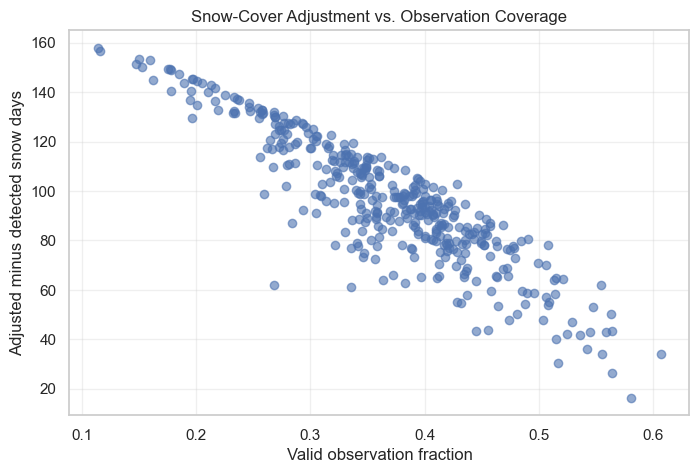

In [310]:
import pandas as pd
import matplotlib.pyplot as plt

snow = pd.read_csv(
    DATA_DIR / "county_snow_validation_v3.csv"
)

snow = snow[
    snow["year"].between(2004, 2023)
].copy()

snow["fips"] = snow["fips"].astype(str).str.zfill(5)

snow = snow[
    ~snow["fips"].isin(["16017", "16055"])
].copy()

snow["adjustment"] = (
    snow["snow_adjusted_2000m"]
    - snow["snow_detected_2000m"]
)

print("VALID OBSERVATION FRACTION")
print(snow["valid_fraction_2000m"].describe().round(3))

print("\nSNOW-DAY ADJUSTMENT")
print(snow["adjustment"].describe().round(2))

print("\nOBSERVATIONS WITH LOW VALID COVERAGE")
for threshold in [0.25, 0.50, 0.75]:
    count = (snow["valid_fraction_2000m"] < threshold).sum()
    print(f"Below {threshold:.0%}: {count}")

print("\nLARGEST ADJUSTMENTS")
display(
    snow[
        [
            "county",
            "year",
            "valid_fraction_2000m",
            "snow_detected_2000m",
            "snow_adjusted_2000m",
            "adjustment"
        ]
    ]
    .sort_values("adjustment", ascending=False)
    .head(15)
    .round(2)
)

plt.figure(figsize=(8, 5))
plt.scatter(
    snow["valid_fraction_2000m"],
    snow["adjustment"],
    alpha=0.6
)
plt.xlabel("Valid observation fraction")
plt.ylabel("Adjusted minus detected snow days")
plt.title("Snow-Cover Adjustment vs. Observation Coverage")
plt.grid(alpha=0.3)
plt.show()

In [311]:
cols = [
    "valid_fraction_2000m",
    "cloud_fraction_2000m",
    "other_fraction_2000m"
]

print("OBSERVATION CLASSIFICATION")
display(snow[cols].describe().round(3))

snow["unclassified_fraction"] = (
    1
    - snow["valid_fraction_2000m"]
    - snow["cloud_fraction_2000m"]
    - snow["other_fraction_2000m"]
)

print("\nUNCLASSIFIED FRACTION")
print(snow["unclassified_fraction"].describe().round(3))

print("\nAVERAGE FRACTIONS")
print(
    snow[cols + ["unclassified_fraction"]]
    .mean()
    .round(3)
)

OBSERVATION CLASSIFICATION


,valid_fraction_2000m,cloud_fraction_2000m,other_fraction_2000m
count,400.000,400.000,400.000
mean,0.367,0.619,0.003
std,0.087,0.088,0.003
min,0.114,0.384,0.000
25%,0.315,0.563,0.001
50%,0.373,0.613,0.002
75%,0.420,0.666,0.003
max,0.607,0.880,0.024



UNCLASSIFIED FRACTION
count    400.000
mean       0.012
std        0.019
min       -0.000
25%        0.000
50%        0.006
75%        0.011
max        0.071
Name: unclassified_fraction, dtype: float64

AVERAGE FRACTIONS
valid_fraction_2000m     0.367
cloud_fraction_2000m     0.619
other_fraction_2000m     0.003
unclassified_fraction    0.012
dtype: float64


MODIS–SNODAS VALIDATION
Observations: 400
Counties: 20
Years: 20

SNOW DURATION SUMMARY


,snow_adjusted_2000m,snow_days_10cm_2000m,difference,absolute_difference
count,400.00,400.00,400.00,400.00
mean,149.10,141.15,7.95,11.19
std,25.53,29.72,15.19,12.99
min,34.01,23.83,-36.66,0.04
25%,136.62,131.38,0.63,3.80
50%,153.77,147.71,6.24,8.10
75%,168.55,160.71,13.02,13.86
max,181.80,180.56,127.87,127.87



AGREEMENT STATISTICS
Pearson correlation: 0.859
Spearman correlation: 0.877
Mean absolute difference: 11.19 days
Mean signed difference: 7.95 days

COVERAGE DIAGNOSTICS
Coverage vs absolute MODIS–SNODAS difference: 0.041
Coverage vs signed MODIS–SNODAS difference: 0.051
Coverage vs MODIS adjustment: -0.899

COMPARISON BY OBSERVATION COVERAGE


,coverage_group,observations,mean_coverage,mean_modis,mean_snodas,mean_difference,mean_absolute_difference
0,Below 25%,36,0.20,176.86,170.19,6.67,7.67
1,25–40%,217,0.34,155.52,147.53,7.99,12.17
2,40–50%,121,0.43,139.67,131.71,7.96,10.32
3,Above 50%,26,0.53,101.05,91.64,9.41,11.91



COUNTY-LEVEL COMPARISON


,fips,county,state,mean_modis,mean_snodas,mean_coverage,mean_difference,mean_absolute_difference
14,49003,Box Elder,Utah,118.41,94.66,0.34,23.75,35.19
7,08113,San Miguel,Colorado,109.12,86.12,0.47,23.00,23.00
1,08037,Eagle,Colorado,142.70,128.94,0.40,13.76,14.07
10,16081,Teton,Idaho,164.50,155.75,0.29,8.74,13.05
6,08107,Routt,Colorado,151.76,142.75,0.35,9.00,10.52
19,56039,Teton,Wyoming,174.20,164.70,0.30,9.49,9.87
2,08049,Grand,Colorado,153.15,144.35,0.36,8.80,9.82
8,08117,Summit,Colorado,166.25,156.57,0.39,9.68,9.81
18,49057,Weber,Utah,147.01,149.77,0.35,-2.75,9.38
3,08051,Gunnison,Colorado,146.70,139.15,0.45,7.55,9.36



YEAR-LEVEL COMPARISON


,year,mean_modis,mean_snodas,mean_coverage,mean_difference
0,2004,155.82,125.25,0.34,30.57
1,2005,157.24,132.38,0.39,24.86
2,2006,154.69,137.16,0.38,17.53
3,2007,148.80,129.65,0.40,19.15
4,2008,147.55,144.42,0.37,3.12
5,2009,150.94,136.39,0.36,14.56
6,2010,150.65,150.13,0.38,0.52
7,2011,157.77,152.01,0.30,5.76
8,2012,144.25,136.08,0.41,8.17
9,2013,145.34,142.85,0.35,2.49



15 LARGEST MODIS–SNODAS DIFFERENCES


,county,year,snow_adjusted_2000m,snow_days_10cm_2000m,valid_fraction_2000m,difference
35,Box Elder,2005,151.69,23.83,0.39,127.87
55,Box Elder,2006,142.26,31.86,0.36,110.40
15,Box Elder,2004,130.10,28.58,0.29,101.52
75,Box Elder,2007,106.17,30.58,0.37,75.59
7,Eagle,2004,148.08,99.84,0.35,48.25
6,Clear Creek,2004,134.10,87.29,0.39,46.81
61,San Miguel,2007,109.96,65.82,0.51,44.14
5,La Plata,2004,112.55,69.90,0.45,42.65
27,Eagle,2005,155.30,114.59,0.42,40.71
2,Gunnison,2004,157.18,117.02,0.38,40.17


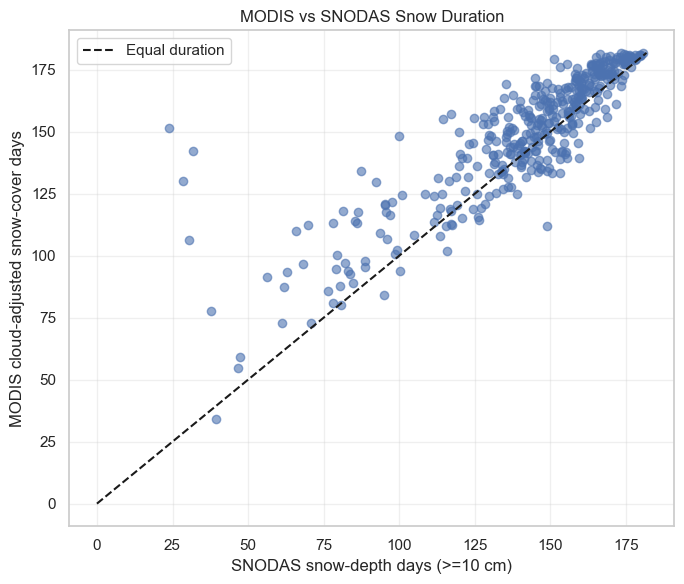

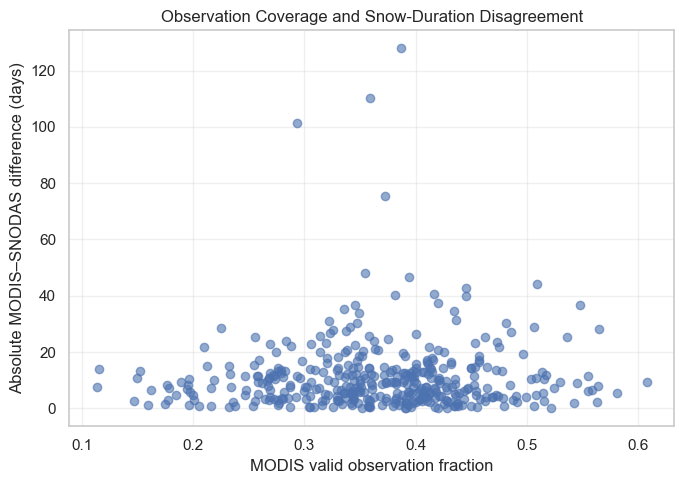

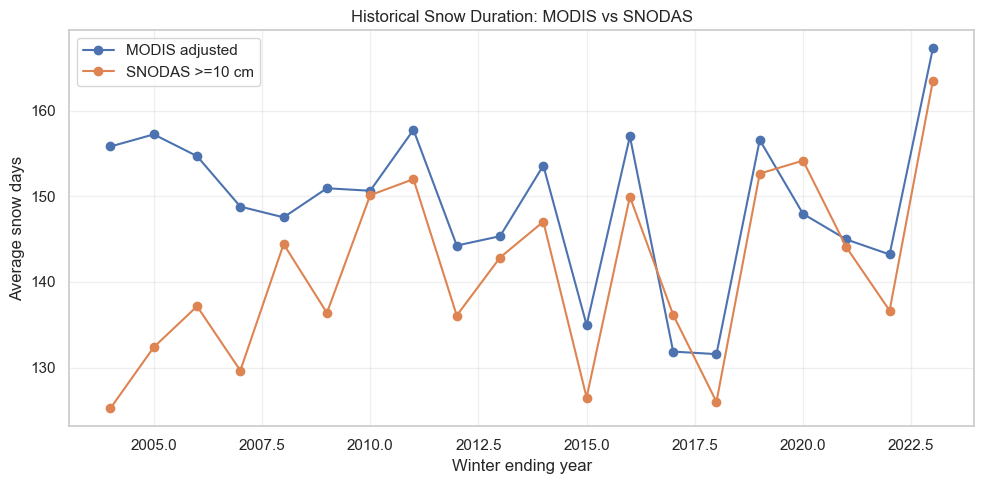


VALIDATION COMPLETE
Results saved to: /Users/evabenson/Files/thesis/snow_ml/ml_model/modis_snodas_validation


In [312]:
# ============================================================
# MODIS–SNODAS SNOW DURATION VALIDATION
# Thesis: Western U.S. Ski Counties
#
# Compares:
#   MODIS cloud-adjusted snow-cover days (NDSI >= 10)
#   SNODAS snow-depth days (depth >= 10 cm)
#
# Checks:
#   1. Agreement between snow measurements
#   2. Whether cloud coverage explains disagreement
#   3. County-level differences
#   4. Year-level differences
#   5. Sensitivity to observation coverage
#
# Does NOT overwrite existing models or results.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error

# ------------------------------------------------------------
# 1. FILE PATHS
# ------------------------------------------------------------

BASE = Path.home() / "Files/thesis/snow_ml/ml_model"

OUT = BASE / "modis_snodas_validation"
OUT.mkdir(parents=True, exist_ok=True)

SNOW_FILE = BASE / "county_snow_validation_v3.csv"

# ------------------------------------------------------------
# 2. LOAD MODIS DATA
# ------------------------------------------------------------

modis = pd.read_csv(
    SNOW_FILE,
    dtype={"fips": str}
)

modis["fips"] = modis["fips"].str.zfill(5)
modis["year"] = modis["year"].astype(int)

modis = modis[
    modis["year"].between(2004, 2023)
    & ~modis["fips"].isin(["16017", "16055"])
].copy()

modis_cols = [
    "fips",
    "year",
    "county",
    "state",
    "snow_detected_2000m",
    "snow_adjusted_2000m",
    "valid_fraction_2000m",
    "cloud_fraction_2000m",
    "season_days"
]

modis = modis[modis_cols]

# ------------------------------------------------------------
# 3. LOAD SNODAS DATA
# ------------------------------------------------------------

# Use existing model_df, which contains the SNODAS target
snodas = model_df[
    [
        "fips",
        "year",
        "snow_days_10cm_2000m"
    ]
].copy()

snodas["fips"] = (
    snodas["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

snodas["year"] = snodas["year"].astype(int)

# ------------------------------------------------------------
# 4. MERGE DATA
# ------------------------------------------------------------

validation = modis.merge(
    snodas,
    on=["fips", "year"],
    how="inner",
    validate="one_to_one"
)

assert len(validation) == 400, (
    f"Expected 400 observations, got {len(validation)}"
)

MODIS = "snow_adjusted_2000m"
SNODAS = "snow_days_10cm_2000m"
COVERAGE = "valid_fraction_2000m"

validation = validation.dropna(
    subset=[MODIS, SNODAS, COVERAGE]
).copy()

print("=" * 65)
print("MODIS–SNODAS VALIDATION")
print("=" * 65)

print("Observations:", len(validation))
print("Counties:", validation["fips"].nunique())
print("Years:", validation["year"].nunique())

# ------------------------------------------------------------
# 5. COMPARE SNOW DURATION
# ------------------------------------------------------------

validation["difference"] = (
    validation[MODIS] - validation[SNODAS]
)

validation["absolute_difference"] = (
    validation["difference"].abs()
)

validation["modis_adjustment"] = (
    validation[MODIS]
    - validation["snow_detected_2000m"]
)

print("\nSNOW DURATION SUMMARY")

display(
    validation[
        [
            MODIS,
            SNODAS,
            "difference",
            "absolute_difference"
        ]
    ].describe().round(2)
)

pearson = pearsonr(
    validation[MODIS],
    validation[SNODAS]
)

spearman = spearmanr(
    validation[MODIS],
    validation[SNODAS]
)

mae = mean_absolute_error(
    validation[SNODAS],
    validation[MODIS]
)

print("\nAGREEMENT STATISTICS")
print("Pearson correlation:", round(pearson.statistic, 3))
print("Spearman correlation:", round(spearman.statistic, 3))
print("Mean absolute difference:", round(mae, 2), "days")
print(
    "Mean signed difference:",
    round(validation["difference"].mean(), 2),
    "days"
)

# ------------------------------------------------------------
# 6. DOES OBSERVATION COVERAGE EXPLAIN DISAGREEMENT?
# ------------------------------------------------------------

coverage_corr = pearsonr(
    validation[COVERAGE],
    validation["absolute_difference"]
)

signed_corr = pearsonr(
    validation[COVERAGE],
    validation["difference"]
)

adjustment_corr = pearsonr(
    validation[COVERAGE],
    validation["modis_adjustment"]
)

print("\nCOVERAGE DIAGNOSTICS")

print(
    "Coverage vs absolute MODIS–SNODAS difference:",
    round(coverage_corr.statistic, 3)
)

print(
    "Coverage vs signed MODIS–SNODAS difference:",
    round(signed_corr.statistic, 3)
)

print(
    "Coverage vs MODIS adjustment:",
    round(adjustment_corr.statistic, 3)
)

# ------------------------------------------------------------
# 7. COVERAGE GROUP COMPARISON
# ------------------------------------------------------------

validation["coverage_group"] = pd.cut(
    validation[COVERAGE],
    bins=[0, 0.25, 0.40, 0.50, 1.0],
    labels=[
        "Below 25%",
        "25–40%",
        "40–50%",
        "Above 50%"
    ],
    include_lowest=True
)

coverage_summary = (
    validation.groupby(
        "coverage_group",
        observed=True
    )
    .agg(
        observations=("fips", "size"),
        mean_coverage=(COVERAGE, "mean"),
        mean_modis=(MODIS, "mean"),
        mean_snodas=(SNODAS, "mean"),
        mean_difference=("difference", "mean"),
        mean_absolute_difference=("absolute_difference", "mean")
    )
    .reset_index()
)

print("\nCOMPARISON BY OBSERVATION COVERAGE")
display(coverage_summary.round(2))

# ------------------------------------------------------------
# 8. COUNTY-LEVEL COMPARISON
# ------------------------------------------------------------

county_summary = (
    validation.groupby(
        ["fips", "county", "state"]
    )
    .agg(
        mean_modis=(MODIS, "mean"),
        mean_snodas=(SNODAS, "mean"),
        mean_coverage=(COVERAGE, "mean"),
        mean_difference=("difference", "mean"),
        mean_absolute_difference=("absolute_difference", "mean")
    )
    .reset_index()
    .sort_values("mean_absolute_difference", ascending=False)
)

print("\nCOUNTY-LEVEL COMPARISON")
display(county_summary.round(2))

# ------------------------------------------------------------
# 9. YEAR-LEVEL COMPARISON
# ------------------------------------------------------------

year_summary = (
    validation.groupby("year")
    .agg(
        mean_modis=(MODIS, "mean"),
        mean_snodas=(SNODAS, "mean"),
        mean_coverage=(COVERAGE, "mean"),
        mean_difference=("difference", "mean")
    )
    .reset_index()
)

print("\nYEAR-LEVEL COMPARISON")
display(year_summary.round(2))

# ------------------------------------------------------------
# 10. LARGEST DISCREPANCIES
# ------------------------------------------------------------

largest = validation.sort_values(
    "absolute_difference",
    ascending=False
).head(15)

print("\n15 LARGEST MODIS–SNODAS DIFFERENCES")

display(
    largest[
        [
            "county",
            "year",
            MODIS,
            SNODAS,
            COVERAGE,
            "difference"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 11. FIGURES
# ------------------------------------------------------------

# Figure 1: MODIS vs SNODAS
plt.figure(figsize=(7, 6))

plt.scatter(
    validation[SNODAS],
    validation[MODIS],
    alpha=0.6
)

limit = max(
    validation[SNODAS].max(),
    validation[MODIS].max()
)

plt.plot(
    [0, limit],
    [0, limit],
    "k--",
    label="Equal duration"
)

plt.xlabel("SNODAS snow-depth days (>=10 cm)")
plt.ylabel("MODIS cloud-adjusted snow-cover days")
plt.title("MODIS vs SNODAS Snow Duration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "modis_vs_snodas.png",
    dpi=300
)

plt.show()


# Figure 2: Observation coverage vs discrepancy
plt.figure(figsize=(7, 5))

plt.scatter(
    validation[COVERAGE],
    validation["absolute_difference"],
    alpha=0.6
)

plt.xlabel("MODIS valid observation fraction")
plt.ylabel("Absolute MODIS–SNODAS difference (days)")
plt.title("Observation Coverage and Snow-Duration Disagreement")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "coverage_vs_disagreement.png",
    dpi=300
)

plt.show()


# Figure 3: Historical trends
plt.figure(figsize=(10, 5))

plt.plot(
    year_summary["year"],
    year_summary["mean_modis"],
    marker="o",
    label="MODIS adjusted"
)

plt.plot(
    year_summary["year"],
    year_summary["mean_snodas"],
    marker="o",
    label="SNODAS >=10 cm"
)

plt.xlabel("Winter ending year")
plt.ylabel("Average snow days")
plt.title("Historical Snow Duration: MODIS vs SNODAS")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "historical_snow_comparison.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------

validation.to_csv(
    OUT / "modis_snodas_validation.csv",
    index=False
)

county_summary.to_csv(
    OUT / "county_comparison.csv",
    index=False
)

year_summary.to_csv(
    OUT / "year_comparison.csv",
    index=False
)

coverage_summary.to_csv(
    OUT / "coverage_comparison.csv",
    index=False
)

print("\nVALIDATION COMPLETE")
print("Results saved to:", OUT)

In [313]:
# ============================================================
# WITHIN-COUNTY MODIS–SNODAS VALIDATION
# ============================================================

from scipy.stats import pearsonr
import numpy as np
import pandas as pd

v = validation.copy()

MODIS = "snow_adjusted_2000m"
SNODAS = "snow_days_10cm_2000m"

# 1. Remove county means
for col in [MODIS, SNODAS]:
    v[col + "_demeaned"] = (
        v[col]
        - v.groupby("fips")[col].transform("mean")
    )

within_corr = pearsonr(
    v[MODIS + "_demeaned"],
    v[SNODAS + "_demeaned"]
)

print("WITHIN-COUNTY CORRELATION")
print(round(within_corr.statistic, 3))

# 2. Compare consecutive-year changes
v = v.sort_values(["fips", "year"])

v["modis_change"] = (
    v.groupby("fips")[MODIS].diff()
)

v["snodas_change"] = (
    v.groupby("fips")[SNODAS].diff()
)

changes = v.dropna(
    subset=["modis_change", "snodas_change"]
).copy()

change_corr = pearsonr(
    changes["modis_change"],
    changes["snodas_change"]
)

print("\nYEAR-TO-YEAR CHANGE CORRELATION")
print(round(change_corr.statistic, 3))

print("\nMEAN ABSOLUTE CHANGE DISAGREEMENT")
print(
    round(
        (
            changes["modis_change"]
            - changes["snodas_change"]
        ).abs().mean(),
        2
    ),
    "days"
)

# 3. Repeat comparisons after excluding early years
print("\nSENSITIVITY TO EARLY YEARS")

for start_year in [2004, 2008, 2010, 2012]:

    subset = v[v["year"] >= start_year].copy()

    raw_corr = subset[
        [MODIS, SNODAS]
    ].corr().iloc[0, 1]

    # Recompute county means within each restricted sample
    m = subset[MODIS] - subset.groupby("fips")[MODIS].transform("mean")
    s = subset[SNODAS] - subset.groupby("fips")[SNODAS].transform("mean")

    within = m.corr(s)

    mean_diff = (
        subset[MODIS] - subset[SNODAS]
    ).mean()

    print(
        f"{start_year}–2023: "
        f"Raw r={raw_corr:.3f}, "
        f"Within-county r={within:.3f}, "
        f"Mean difference={mean_diff:.2f} days"
    )

# 4. Compare year-to-year changes after early years
print("\nYEAR-TO-YEAR CHANGE SENSITIVITY")

for start_year in [2004, 2008, 2010, 2012]:

    subset = changes[
        (changes["year"] >= start_year)
        & (changes["year"] - 1 >= start_year)
    ]

    print(
        f"{start_year}–2023: "
        f"r={subset['modis_change'].corr(subset['snodas_change']):.3f}, "
        f"N={len(subset)}"
    )

WITHIN-COUNTY CORRELATION
0.564

YEAR-TO-YEAR CHANGE CORRELATION
0.787

MEAN ABSOLUTE CHANGE DISAGREEMENT
9.37 days

SENSITIVITY TO EARLY YEARS
2004–2023: Raw r=0.859, Within-county r=0.564, Mean difference=7.95 days
2008–2023: Raw r=0.931, Within-county r=0.820, Mean difference=4.18 days
2010–2023: Raw r=0.938, Within-county r=0.842, Mean difference=3.52 days
2012–2023: Raw r=0.940, Within-county r=0.843, Mean difference=3.58 days

YEAR-TO-YEAR CHANGE SENSITIVITY
2004–2023: r=0.787, N=380
2008–2023: r=0.835, N=300
2010–2023: r=0.866, N=260
2012–2023: r=0.867, N=220


In [315]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

BASE = Path.home() / "Files/thesis/snow_ml/ml_model"

df = model_df.copy()

snow = pd.read_csv(
    BASE / "county_snow_validation_v3.csv",
    dtype={"fips": str}
)

# Standardize identifiers
for data in [df, snow]:
    data["fips"] = (
        data["fips"]
        .astype(str)
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(5)
    )
    data["year"] = pd.to_numeric(data["year"]).astype(int)

# Remove any old version of the target before merging
df = df.drop(columns=["snow_adjusted_2000m"], errors="ignore")

df = df.merge(
    snow[["fips", "year", "snow_adjusted_2000m"]],
    on=["fips", "year"],
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 2. PREPARE SAMPLES
# ------------------------------------------------------------

formula = (
    "snow_adjusted_2000m ~ "
    "positive_degree_days_2000m + "
    "precip_on_2000m + "
    "precip_djf_2000m + "
    "precip_mar_apr_2000m + "
    "C(fips) + C(year)"
)

required = [
    "snow_adjusted_2000m",
    "positive_degree_days_2000m",
    "precip_on_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m",
    "fips",
    "year"
]

print("Missing required columns:")
print([c for c in required if c not in df.columns])

df = df.dropna(subset=required)

full = df[df["year"].between(2004, 2023)].copy()
restricted = df[df["year"].between(2008, 2023)].copy()

# ------------------------------------------------------------
# 3. FIT FIXED-EFFECTS MODELS
# ------------------------------------------------------------

def fit_fe1(data):
    return smf.ols(formula, data=data).fit(
        cov_type="cluster",
        cov_kwds={"groups": data["fips"]}
    )

model_full = fit_fe1(full)
model_restricted = fit_fe1(restricted)

# ------------------------------------------------------------
# 4. COMPARE COEFFICIENTS
# ------------------------------------------------------------

variables = [
    "positive_degree_days_2000m",
    "precip_on_2000m",
    "precip_djf_2000m",
    "precip_mar_apr_2000m"
]

comparison = pd.DataFrame({
    "2004–2023 coefficient": model_full.params[variables],
    "2004–2023 p-value": model_full.pvalues[variables],
    "2008–2023 coefficient": model_restricted.params[variables],
    "2008–2023 p-value": model_restricted.pvalues[variables]
})

comparison["Coefficient change (%)"] = (
    (
        comparison["2008–2023 coefficient"]
        / comparison["2004–2023 coefficient"]
        - 1
    ) * 100
)

print("\nSAMPLE SIZES")
print("Full:", len(full))
print("Restricted:", len(restricted))

print("\nFE1 COEFFICIENT COMPARISON")
display(comparison.round(4))

print("\nMODEL FIT")
print("Full R²:", round(model_full.rsquared, 4))
print("Restricted R²:", round(model_restricted.rsquared, 4))

Missing required columns:
[]

SAMPLE SIZES
Full: 400
Restricted: 320

FE1 COEFFICIENT COMPARISON


,2004–2023 coefficient,2004–2023 p-value,2008–2023 coefficient,2008–2023 p-value,Coefficient change (%)
positive_degree_days_2000m,-0.0986,0.0000,-0.1279,0.0000,29.6996
precip_on_2000m,0.0592,0.0000,0.0499,0.0000,-15.6472
precip_djf_2000m,0.0522,0.0008,0.0396,0.0047,-24.1167
precip_mar_apr_2000m,0.0084,0.4161,-0.0037,0.7275,-144.0656



MODEL FIT
Full R²: 0.917
Restricted R²: 0.9228


In [316]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path.home() / "Files/thesis/snow_ml/ml_model"

SCENARIO_FILE = (
    BASE
    / "updated_warming_scenarios"
    / "all_five_warming_predictions.csv"
)

scenarios = pd.read_csv(SCENARIO_FILE)

print("SCENARIO FILE COLUMNS")
print(scenarios.columns.tolist())

print("\nFIRST FIVE ROWS")
display(scenarios.head())

print("\nAVAILABLE WARMING LEVELS")
for col in scenarios.columns:
    if "warming" in col.lower() or "scenario" in col.lower():
        print(col, scenarios[col].dropna().unique()[:10])

SCENARIO FILE COLUMNS
['fips', 'year', 'warming_C', 'state', 'county', 'FE1 Baseline', 'FE2 Expanded', 'FE3 Nonlinear', 'Random Forest', 'XGBoost', 'FE1 Baseline_baseline', 'FE2 Expanded_baseline', 'FE3 Nonlinear_baseline', 'Random Forest_baseline', 'XGBoost_baseline', 'FE1 Baseline_change', 'FE1 Baseline_pct_change', 'FE2 Expanded_change', 'FE2 Expanded_pct_change', 'FE3 Nonlinear_change', 'FE3 Nonlinear_pct_change', 'Random Forest_change', 'Random Forest_pct_change', 'XGBoost_change', 'XGBoost_pct_change']

FIRST FIVE ROWS


,fips,year,warming_C,state,county,FE1 Baseline,FE2 Expanded,FE3 Nonlinear,Random Forest,XGBoost,FE1 Baseline_baseline,FE2 Expanded_baseline,FE3 Nonlinear_baseline,Random Forest_baseline,XGBoost_baseline,FE1 Baseline_change,FE1 Baseline_pct_change,FE2 Expanded_change,FE2 Expanded_pct_change,FE3 Nonlinear_change,FE3 Nonlinear_pct_change,Random Forest_change,Random Forest_pct_change,XGBoost_change,XGBoost_pct_change
0,8019,2004,0,8,Clear Creek,143.628063,142.454121,142.018990,133.341972,129.632309,143.628063,142.454121,142.018990,133.341972,129.632309,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,8037,2004,0,8,Eagle,147.782886,146.719068,146.640884,141.585102,138.656799,147.782886,146.719068,146.640884,141.585102,138.656799,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,8049,2004,0,8,Grand,158.369248,157.528067,157.618341,149.695014,149.779297,158.369248,157.528067,157.618341,149.695014,149.779297,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,8051,2004,0,8,Gunnison,153.308699,153.605588,153.942619,152.004215,150.873199,153.308699,153.605588,153.942619,152.004215,150.873199,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8067,2004,0,8,La Plata,101.314328,99.959398,99.539052,104.463881,106.377625,101.314328,99.959398,99.539052,104.463881,106.377625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



AVAILABLE WARMING LEVELS
warming_C [0 1 2 3]


In [317]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. EXTRACT TEMPERATURE COEFFICIENTS
# ------------------------------------------------------------

variable = "positive_degree_days_2000m"

beta_full = model_full.params[variable]
beta_restricted = model_restricted.params[variable]

print("Full-sample PDD coefficient:", round(beta_full, 6))
print("Restricted PDD coefficient:", round(beta_restricted, 6))

# ------------------------------------------------------------
# 2. RECOVER WARMING-INDUCED PDD CHANGES
# ------------------------------------------------------------

s = scenarios.copy()

s["fips"] = (
    s["fips"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

s["year"] = s["year"].astype(int)

# Original FE1 warming response
s["original_change"] = s["FE1 Baseline_change"]

# Recover implied change in PDD
s["implied_pdd_change"] = (
    s["original_change"] / beta_full
)

# ------------------------------------------------------------
# 3. APPLY RESTRICTED MODEL COEFFICIENT
# ------------------------------------------------------------

s["restricted_change"] = (
    beta_restricted * s["implied_pdd_change"]
)

# Equivalent to scaling the original FE1 response
# by the ratio of temperature coefficients.

# ------------------------------------------------------------
# 4. COMPARE WARMING RESPONSES
# ------------------------------------------------------------

comparison = (
    s[s["year"].between(2008, 2023)]
    .groupby("warming_C")
    .agg(
        original_FE1=("original_change", "mean"),
        restricted_FE1=("restricted_change", "mean")
    )
    .reset_index()
)

comparison["difference_days"] = (
    comparison["restricted_FE1"]
    - comparison["original_FE1"]
)

print("\nFE1 WARMING SCENARIO COMPARISON")
display(comparison.round(3))

# ------------------------------------------------------------
# 5. CHECK COEFFICIENT SCALING
# ------------------------------------------------------------

print("\nTEMPERATURE SENSITIVITY RATIO")
print(round(beta_restricted / beta_full, 3))

Full-sample PDD coefficient: -0.098608
Restricted PDD coefficient: -0.127894

FE1 WARMING SCENARIO COMPARISON


,warming_C,original_FE1,restricted_FE1,difference_days
0,0,0.000,0.000,0.000
1,1,-5.951,-7.719,-1.768
2,2,-13.105,-16.997,-3.892
3,3,-21.528,-27.922,-6.394



TEMPERATURE SENSITIVITY RATIO
1.297


In [319]:
print([x for x in model_df.columns
       if "nov" in x.lower() or "temp" in x.lower()
       or "tmin" in x.lower() or "tmax" in x.lower()])

['tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m']


In [322]:
print("November/October columns:")
print([
    c for c in model_df.columns
    if "nov" in c.lower() or "oct" in c.lower()
    or "_on_" in c.lower()
])

November/October columns:
['precip_on_all', 'precip_on_2000m']


In [325]:
import pandas as pd
from pathlib import Path

path = (
    Path.home()
    / "Files/thesis/snow_ml/ml_model/county_climate_panel_v3.csv"
)

climate = pd.read_csv(path)

print("Climate dataset columns:")
print(climate.columns.tolist())

print("\nDataset dimensions:")
print(climate.shape)

Climate dataset columns:
['fips', 'state', 'county', 'year', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'precip_freezing_fraction_2000m']

Dataset dimensions:
(506, 32)


In [326]:
import json
from pathlib import Path

path = Path.home() / "Files/thesis/snow_ml/code/snow_model.ipynb"
nb = json.loads(path.read_text())

terms = [
    "ee.Terrain",
    "northness",
    "eastness",
    "frac_above_2000m",
    "reduceRegion"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if cell["cell_type"] != "code":
        continue

    matches = [term for term in terms if term in source]

    if matches:
        print(f"CELL {i}: {', '.join(matches)}")
        print(source[:1000])
        print("-" * 60)

CELL 13: northness, eastness, frac_above_2000m
# Keep observations with valid snow-cover measurements
model_df = panel.dropna(
    subset=["snow_days_2000m"]
).copy()

# Define target variable
TARGET = "snow_days_2000m"

# Define climate predictors
CLIMATE_FEATURES = [
    "tmin_djf",
    "tmin_apr",
    "precip_on",
    "precip_djf"
]

# Define terrain predictors
TERRAIN_FEATURES = [
    "mean_elev_m",
    "mean_slope_deg",
    "mean_northness",
    "mean_eastness",
    "frac_above_2000m",
    "frac_above_2500m",
    "frac_above_3000m"
]

FEATURES = CLIMATE_FEATURES + TERRAIN_FEATURES

# Sort the panel
model_df = model_df.sort_values(
    ["fips", "year"]
).reset_index(drop=True)

print("Observations:", len(model_df))
print("Counties:", model_df["fips"].nunique())
print("Years:", model_df["year"].nunique())

assert not model_df[FEATURES + [TARGET]].isna().any().any()

display(model_df.head())
------------------------------------------------------------
CELL 32: northness, eastness, fr

In [327]:
import json
from pathlib import Path

path = Path.home() / "Files/thesis/snow_ml/code/snow_model.ipynb"
nb = json.loads(path.read_text())

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if cell["cell_type"] != "code":
        continue

    if "terrain" in source.lower() and (
        "read_csv" in source or ".merge(" in source
    ):
        print(f"\nCELL {i}")
        print(source[:2500])
        print("-" * 60)


CELL 5
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/Users/evabenson/Files/thesis/snow_ml/ml_model")

snow = pd.read_csv(
    DATA_DIR / "county_snow_panel.csv",
    dtype={"fips": str}
)

climate = pd.read_csv(
    DATA_DIR / "county_climate_panel_v2.csv",
    dtype={"fips": str}
)

terrain = pd.read_csv(
    DATA_DIR / "county_terrain.csv",
    dtype={"fips": str}
)

print("Snow:", snow.shape)
print("Climate:", climate.shape)
print("Terrain:", terrain.shape)
------------------------------------------------------------

CELL 9
# Standardize year formats
snow["year"] = snow["year"].astype(int)
climate["year"] = climate["year"].astype(int)

# Check that merge keys are unique
assert not snow.duplicated(["fips", "year"]).any()
assert not climate.duplicated(["fips", "year"]).any()
assert not terrain.duplicated(["fips"]).any()

# Merge snow and climate
panel = snow.merge(
    climate.drop(columns=["state", "county"]),
    on=["fips", "year"],
    how="left",
    validate=

In [328]:
import json
from pathlib import Path

notebook = Path.home() / "Files/thesis/snow_ml/code/snow_model.ipynb"
nb = json.loads(notebook.read_text())

for i in [268, 270]:
    print(f"\n{'=' * 30} CELL {i} {'=' * 30}\n")
    print("".join(nb["cells"][i]["source"]))


============================== CELL 268 ==============================

# ============================================================
# THESIS MODEL UPDATE
# Consistent snow-cover target + Oct-Nov precipitation
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

import statsmodels.formula.api as smf

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error
)
from sklearn.model_selection import LeaveOneGroupOut

from xgboost import XGBRegressor

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

BASE = Path.home() / "Files/thesis/snow_ml/ml_model"
OUT = BASE / "consistent_model_comparison"
OUT.mkdir(parents=True, exist_ok=True)

TARGET_ADJUSTED = "snow_adjusted_2000m"
TARGET_ORIGINAL = "snow_days_10cm_2000m"
NEW_FEATURE = "precip_on_2000m"

# O

In [334]:
%run -i ~/Files/thesis/snow_ml/code/run_snodas_comparison_standalone_train.py

Loaded training data: /Users/evabenson/Files/thesis/snow_ml/ml_model/consistent_model_comparison/consistent_model_data.csv rows: 400
v4 CSV not found; using the original climate predictors (no November temperatures).
Validated: FE1 Baseline
Validated: FE2 Expanded
Validated: FE3 Nonlinear
Validated: Random Forest
Validated: XGBoost

SNODAS VALIDATION
        Model  LOYO R2  LOYO MAE  LOYO RMSE  Forward R2  Forward MAE  Forward RMSE
 FE1 Baseline    0.792     9.429     13.545       0.790        9.699        13.476
 FE2 Expanded    0.805     9.145     13.112       0.812        9.277        12.758
FE3 Nonlinear    0.803     9.220     13.174       0.756       10.375        14.525
Random Forest    0.758    10.026     14.591       0.763       11.412        14.301
      XGBoost    0.766     9.764     14.359       0.755       11.464        14.568

SNODAS MEAN CHANGE IN SNOW DAYS
 warming_C  FE1 Baseline  FE2 Expanded  FE3 Nonlinear  Random Forest  XGBoost
         0         0.000         0.000

In [335]:
%run -i ~/Files/thesis/snow_ml/code/run_snodas_v4_november.py

Loaded training data: /Users/evabenson/Files/thesis/snow_ml/ml_model/consistent_model_comparison/consistent_model_data.csv rows: 400
Note: V4 contains missing high-elevation climate values outside the final sample; validating the 400 modeling rows below.
Using v4 November minimum and maximum temperatures in both ML models.
ML predictors: 21 (19 existing + 2 November)
Validated: FE1 Baseline
Validated: FE2 Expanded
Validated: FE3 Nonlinear
Validated: Random Forest
Validated: XGBoost

SNODAS VALIDATION
        Model  LOYO R2  LOYO MAE  LOYO RMSE  Forward R2  Forward MAE  Forward RMSE
 FE1 Baseline    0.792     9.429     13.545       0.790        9.699        13.476
 FE2 Expanded    0.805     9.145     13.112       0.812        9.277        12.758
FE3 Nonlinear    0.803     9.220     13.174       0.756       10.375        14.525
Random Forest    0.762     9.549     14.469       0.785       10.609        13.632
      XGBoost    0.772     9.517     14.169       0.763       11.039        14.

In [336]:
%run -i ~/Files/thesis/snow_ml/code/run_snodas_30cm_v4_november.py

30-cm SNODAS target: 400 rows, mean 116.24 days
Loaded training data: /Users/evabenson/Files/thesis/snow_ml/ml_model/consistent_model_comparison/consistent_model_data.csv rows: 400
Note: V4 contains missing high-elevation climate values outside the final sample; validating the 400 modeling rows below.
Using v4 November minimum and maximum temperatures in both ML models.
ML predictors: 21 (19 existing + 2 November)
Validated: FE1 Baseline
Validated: FE2 Expanded
Validated: FE3 Nonlinear
Validated: Random Forest
Validated: XGBoost

SNODAS 30-CM VALIDATION
        Model  LOYO R2  LOYO MAE  LOYO RMSE  Forward R2  Forward MAE  Forward RMSE
 FE1 Baseline    0.810    11.409     15.237       0.802       11.874        15.285
 FE2 Expanded    0.819    11.202     14.868       0.802       12.240        15.274
FE3 Nonlinear    0.817    11.291     14.954       0.745       13.386        17.361
Random Forest    0.775    12.082     16.552       0.801       12.419        15.343
      XGBoost    0.796   

In [337]:
%run ~/Files/thesis/snow_ml/code/run_snodas_economic_analysis.py


BEA ORSA 2023 skiing/snowboarding value added ($M):
  Colorado   1,085.550
  Idaho      90.582
  Montana    48.993
  Utah       419.487
  Wyoming    27.216
  TOTAL      1,671.828

10cm SNODAS: five-state change in value added ($M), elasticity=0.50
warming_C       +1 C    +2 C    +3 C
Model                               
FE1 Baseline  -73.38 -159.76 -258.90
FE2 Expanded  -88.67 -188.56 -299.03
FE3 Nonlinear -88.80 -192.22 -309.32
Random Forest -68.11 -146.09 -224.60
XGBoost       -69.88 -147.82 -221.81

30cm SNODAS: five-state change in value added ($M), elasticity=0.50
warming_C        +1 C    +2 C    +3 C
Model                                
FE1 Baseline   -73.06 -158.51 -254.97
FE2 Expanded  -106.43 -221.12 -340.32
FE3 Nonlinear -106.38 -222.98 -345.11
Random Forest  -88.02 -183.03 -276.52
XGBoost        -91.46 -183.28 -265.47

Saved: /Users/evabenson/Files/thesis/snow_ml/ml_model/snodas_economic_analysis_v4/economic_exposure_by_state.csv
Saved: /Users/evabenson/Files/thesis/snow_m

In [338]:
%run ~/Files/thesis/snow_ml/code/run_snodas_remaining_robustness.py

Full sample: 400 counties: 20
Low coverage (<95%): 8 observations
Filtered sample: 392
snow_days_10cm_2000m LOYO FE1 Baseline: R2=0.792, MAE=9.43, RMSE=13.54
snow_days_10cm_2000m LOYO FE2 Expanded: R2=0.805, MAE=9.15, RMSE=13.11
snow_days_10cm_2000m LOYO FE3 Nonlinear: R2=0.803, MAE=9.22, RMSE=13.17
snow_days_10cm_2000m LOYO Random Forest: R2=0.762, MAE=9.55, RMSE=14.47
snow_days_10cm_2000m LOYO XGBoost: R2=0.772, MAE=9.52, RMSE=14.17
snow_days_10cm_2000m LOYO FE1 Baseline: R2=0.790, MAE=9.53, RMSE=13.66
snow_days_10cm_2000m LOYO FE2 Expanded: R2=0.804, MAE=9.21, RMSE=13.21
snow_days_10cm_2000m LOYO FE3 Nonlinear: R2=0.802, MAE=9.28, RMSE=13.28
snow_days_10cm_2000m LOYO Random Forest: R2=0.761, MAE=9.68, RMSE=14.59
snow_days_10cm_2000m LOYO XGBoost: R2=0.770, MAE=9.72, RMSE=14.31
snow_days_10cm_2000m LOCO FE1 Baseline: R2=0.575, MAE=13.93, RMSE=19.36
snow_days_10cm_2000m LOCO FE2 Expanded: R2=0.555, MAE=14.06, RMSE=19.80
snow_days_10cm_2000m LOCO FE3 Nonlinear: R2=0.564, MAE=13.72, RMS